***Passive Task Meg Analysis***

sub-1

In [ ]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-1'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-001_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-001_coordsystem.json', 'sub-001_task-go_run-1_proc-tsss+mc_events.json', 'sub-001_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-001_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-001_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-001_task-noise_proc-tsss_channels.tsv', 'sub-001_task-go_run-1_proc-tsss+mc_meg.json', 'sub-001_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-001_task-noise_proc-tsss_meg.json', 'sub-001_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-001_task-passive_run-1_proc-tsss+mc_events.json', 'sub-001_task-noise_proc-tsss_meg.fif', 'sub-001_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-001_task-rest_run-1_proc-tsss+mc_events.json', 'sub-001_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-001_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-001_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-001_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-001_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-001_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-001_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-001_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-001_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 42.3 MB/s eta 0:00:00

Found .fif file: /content/drive/MyDrive/sub-1/meg/sub-001_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-1/meg/sub-001_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 124000 ... 1201999 =    124.000 ...  1201.999 secs
Ready.
Reading 0 ... 1077999  =      0.000 ...  1077.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


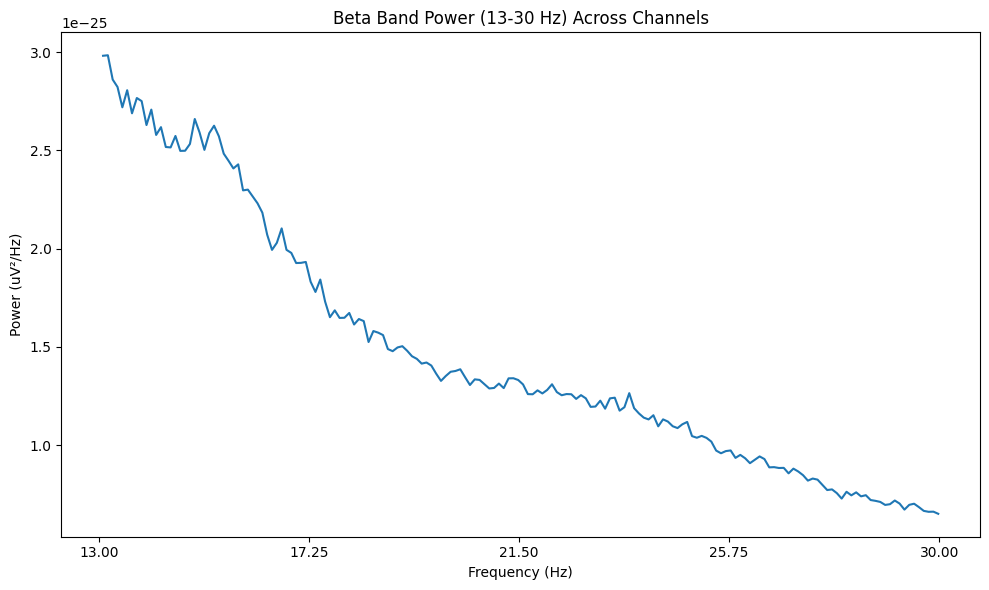

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d1 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d1.head())
print(d1.shape)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.2/115.2 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 99.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 98.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.5/130.5 kB 4.1 MB/s eta 0:00:00
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.12

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d1_clean = d1.replace([np.inf, -np.inf], np.nan)
d1_clean = d1_clean.fillna(d1_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d1_scaled = pd.DataFrame(
    scaler.fit_transform(d1_clean),
    columns=d1_clean.columns,
    index=d1_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d1_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d1_scaled.index,
    columns=d1_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d1_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df1 = d1_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df1["Pd_indicator_meg"] = 0

print("\nShape of df5:", df1.shape)
print(df1.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Store only 58x7 features for ALL subjects
all_subjects_df1 = []

# Store 58x7 matrix safely
all_subjects_df1.append(df1.copy())

print("Stored df1 for this subject. Shape:", df1.shape)


Stored df1 for this subject. Shape: (58, 22)


In [ ]:
# ===== MEMORY CLEANUP BEFORE NEXT SUBJECT =====
import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

del raw
del ica
del psd_obj
del psds
del beta_band_psd


gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleared successfully (df1 preserved)")


RAM Used After Cleanup: 0.95 GB
Memory cleared successfully (df1 preserved)


sub-2

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-2'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-002_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-002_coordsystem.json', 'sub-002_task-go_run-1_proc-tsss+mc_events.json', 'sub-002_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-002_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-002_task-noise_proc-tsss_channels.tsv', 'sub-002_task-go_run-1_proc-tsss+mc_meg.json', 'sub-002_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-002_task-noise_proc-tsss_meg.json', 'sub-002_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-002_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-002_task-passive_run-1_proc-tsss+mc_events.json', 'sub-002_task-noise_proc-tsss_meg.fif', 'sub-002_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-002_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-002_task-rest_run-1_proc-tsss+mc_events.json', 'sub-002_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-002_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-002_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-002_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-002_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-002_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-002_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-002_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-2/meg/sub-002_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-2/meg/sub-002_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 98000 ... 1173999 =     98.000 ...  1173.999 secs
Ready.
Reading 0 ... 1075999  =      0.000 ...  1075.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitti

Computing Power Spectral Density

Effective window size : 10.240 (s)


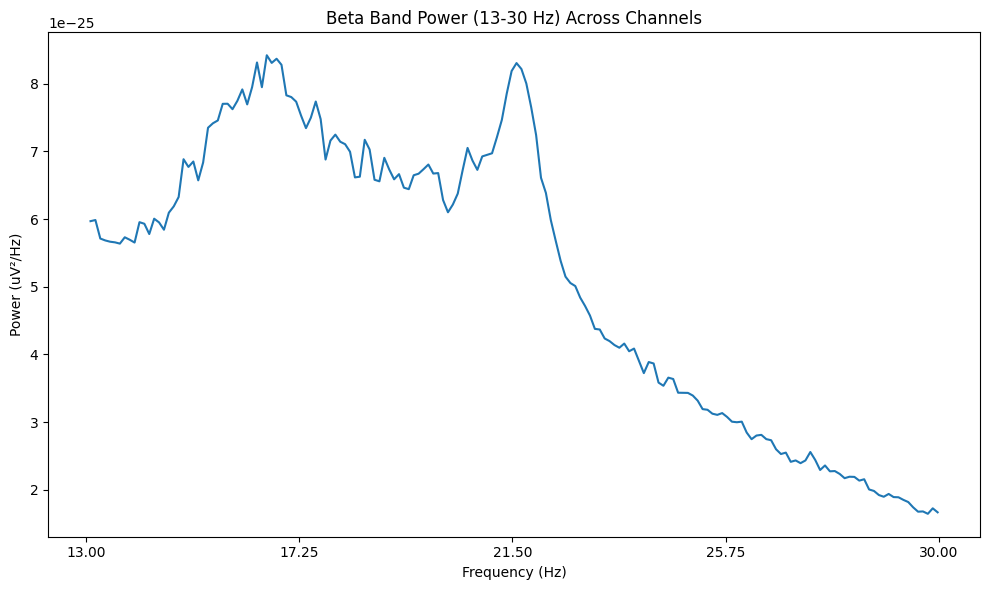

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d2 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d2.head())
print(d2.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d2_clean = d2.replace([np.inf, -np.inf], np.nan)
d2_clean = d2_clean.fillna(d2_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d2_scaled = pd.DataFrame(
    scaler.fit_transform(d2_clean),
    columns=d2_clean.columns,
    index=d2_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d2_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d2_scaled.index,
    columns=d2_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d2_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df2 = d2_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df2["Pd_indicator_meg"] = 0

print("\nShape of df5:", df2.shape)
print(df2.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

Concatenation

In [ ]:
# Combine df_4 and df_8 vertically
df12 = pd.concat([df1, df2], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12 = df12.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12):")
print(df12)

# Print the shape
print("Shape of df12:", df12.shape) #(116,7)


Combined top channels (df12):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.148423             0.060237          3.794677e-12  0.843069   
1      4.089981             0.061125          2.134013e-13  0.767457   
2      4.163265             0.060049          3.607224e-12  0.786598   
3      4.183673             0.059707          4.139047e-12  0.750612   
4      4.333024             0.057641          2.012607e-13  0.775638   
..          ...                  ...                   ...       ...   
111    3.765799             0.066387          8.787545e-12  0.973134   
112    3.722119             0.067166          4.876109e-13  0.910603   
113    3.604089             0.069366          9.840813e-12  1.036571   
114    3.649628             0.068500          8.220219e-12  0.921236   
115    3.721190             0.067183          4.665441e-13  0.956883   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.249889       13.574219 

In [ ]:
df12.to_csv('/content/drive/MyDrive/combined_features_upto_sub02_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12 preserved.")


RAM Used After Cleanup: 0.96 GB
Memory cleaned. df12 preserved.


sub-3

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-3'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-003_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-003_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-003_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-003_coordsystem.json', 'sub-003_task-go_run-1_proc-tsss+mc_events.json', 'sub-003_task-go_run-1_proc-tsss+mc_meg.json', 'sub-003_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-003_task-noise_proc-tsss_channels.tsv', 'sub-003_task-noise_proc-tsss_meg.fif', 'sub-003_task-passive_run-1_proc-tsss+mc_events.json', 'sub-003_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-003_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-003_task-noise_proc-tsss_meg.json', 'sub-003_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-003_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-003_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-003_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-003_task-rest_run-1_proc-tsss+mc_events.json', 'sub-003_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-003_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-003_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-003_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-003_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-003_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-3/meg/sub-003_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-3/meg/sub-003_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 78000 ... 1151999 =     78.000 ...  1151.999 secs
Ready.
Reading 0 ... 1073999  =      0.000 ...  1073.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitti

Computing Power Spectral Density

Effective window size : 10.240 (s)


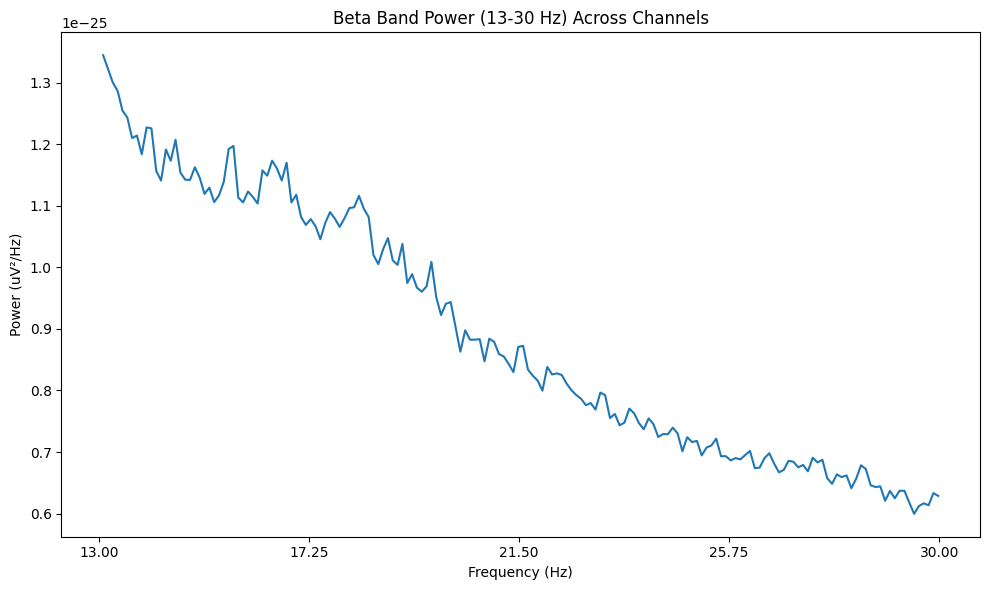

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d3 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d3.head())
print(d3.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d3_clean = d3.replace([np.inf, -np.inf], np.nan)
d3_clean = d3_clean.fillna(d3_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d3_scaled = pd.DataFrame(
    scaler.fit_transform(d3_clean),
    columns=d3_clean.columns,
    index=d3_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d3_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d3_scaled.index,
    columns=d3_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d3_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df3 = d3_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df3["Pd_indicator_meg"] = 0

print("\nShape of df5:", df3.shape)
print(df3.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

Concatenation

In [ ]:
# Combine df_4 and df_8 vertically
df123 = pd.concat([df12, df3], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123 = df123.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123):")
print(df123)

# Print the shape
print("Shape of df123:", df123.shape) #(116,7)


Combined top channels (df123):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.148423             0.060237          3.794677e-12  0.843069   
1      4.089981             0.061125          2.134013e-13  0.767457   
2      4.163265             0.060049          3.607224e-12  0.786598   
3      4.183673             0.059707          4.139047e-12  0.750612   
4      4.333024             0.057641          2.012607e-13  0.775638   
..          ...                  ...                   ...       ...   
169    4.657356             0.053679          2.846019e-12  0.739813   
170    4.513035             0.055395          1.587306e-13  0.767941   
171    4.665736             0.053582          3.183386e-12  0.727503   
172    4.595903             0.054396          2.890782e-12  0.716940   
173    4.477654             0.055833          1.681361e-13  0.759711   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.249889       13.574219

In [ ]:
df123.to_csv('/content/drive/MyDrive/combined_features_upto_sub03_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123 preserved.")


RAM Used After Cleanup: 0.96 GB
Memory cleaned. df123 preserved.


sub-4

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-4'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-004_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-004_task-go_run-1_proc-tsss+mc_events.json', 'sub-004_coordsystem.json', 'sub-004_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-004_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-004_task-noise_proc-tsss_channels.tsv', 'sub-004_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-004_task-go_run-1_proc-tsss+mc_meg.json', 'sub-004_task-noise_proc-tsss_meg.json', 'sub-004_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-004_task-noise_proc-tsss_meg.fif', 'sub-004_task-passive_run-1_proc-tsss+mc_events.json', 'sub-004_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-004_task-rest_run-1_proc-tsss+mc_events.json', 'sub-004_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-004_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-004_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-004_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-004_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-004_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-004_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-004_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-004_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-004_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-4/meg/sub-004_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocesing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-4/meg/sub-004_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 69000 ... 1146999 =     69.000 ...  1146.999 secs
Ready.
Reading 0 ... 1077999  =      0.000 ...  1077.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitti

Computing Power Spectral Density

Effective window size : 10.240 (s)


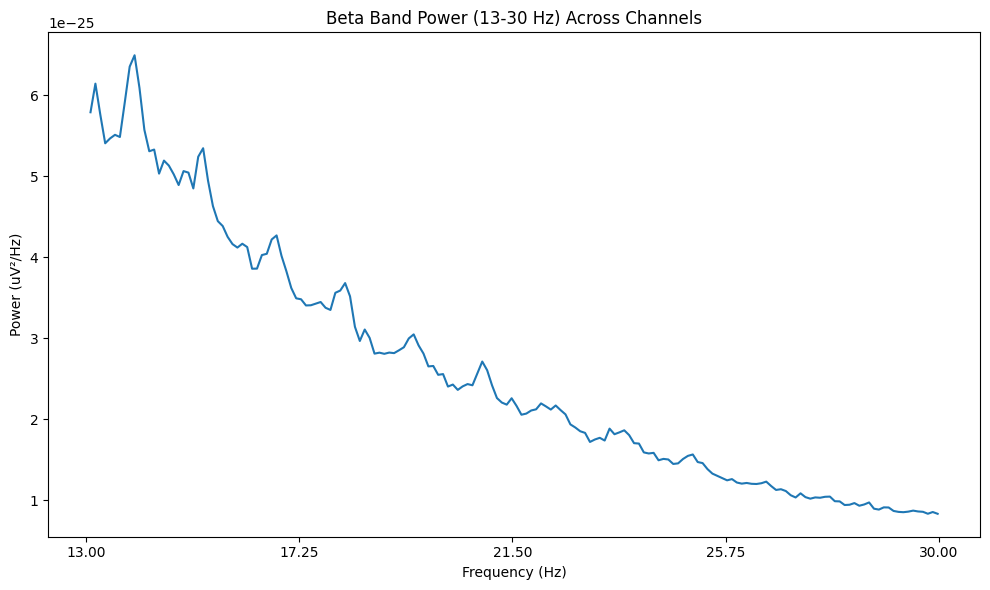

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d4 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d4.head())
print(d4.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d4_clean = d4.replace([np.inf, -np.inf], np.nan)
d4_clean = d4_clean.fillna(d4_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d4_scaled = pd.DataFrame(
    scaler.fit_transform(d4_clean),
    columns=d4_clean.columns,
    index=d4_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d4_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d4_scaled.index,
    columns=d4_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d4_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df4 = d4_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df4["Pd_indicator_meg"] = 1

print("\nShape of df5:", df4.shape)
print(df4.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234 = pd.concat([df123, df4], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234 = df1234.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234):")
print(df1234)

# Print the shape
print("Shape of df1234:", df1234.shape) #(116,7)


Combined top channels (df1234):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.148423             0.060237          3.794677e-12  0.843069   
1      4.089981             0.061125          2.134013e-13  0.767457   
2      4.163265             0.060049          3.607224e-12  0.786598   
3      4.183673             0.059707          4.139047e-12  0.750612   
4      4.333024             0.057641          2.012607e-13  0.775638   
..          ...                  ...                   ...       ...   
227    4.092764             0.061083          4.216763e-12  0.828155   
228    3.883117             0.064381          2.790178e-13  0.808949   
229    4.145640             0.060304          4.843037e-12  0.846924   
230    4.120594             0.060671          4.379038e-12  0.861255   
231    3.864564             0.064690          2.922976e-13  0.850108   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.249889       13.57421

In [ ]:
df1234.to_csv('/content/drive/MyDrive/combined_features_upto_sub04_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234 preserved.")


RAM Used After Cleanup: 1.00 GB
Memory cleaned. df1234 preserved.


sub-5

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-5'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-005_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-005_coordsystem.json', 'sub-005_task-go_run-1_proc-tsss+mc_events.json', 'sub-005_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-005_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-005_task-go_run-1_proc-tsss+mc_meg.json', 'sub-005_task-noise_proc-tsss_channels.tsv', 'sub-005_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-005_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-005_task-noise_proc-tsss_meg.fif', 'sub-005_task-noise_proc-tsss_meg.json', 'sub-005_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-005_task-passive_run-1_proc-tsss+mc_events.json', 'sub-005_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-005_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-005_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-005_task-rest_run-1_proc-tsss+mc_events.json', 'sub-005_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-005_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-005_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-005_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-005_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-005_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-005_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-5/meg/sub-005_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-5/meg/sub-005_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 63000 ... 1143999 =     63.000 ...  1143.999 secs
Ready.
Reading 0 ... 1080999  =      0.000 ...  1080.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitti

Computing Power Spectral Density

Effective window size : 10.240 (s)


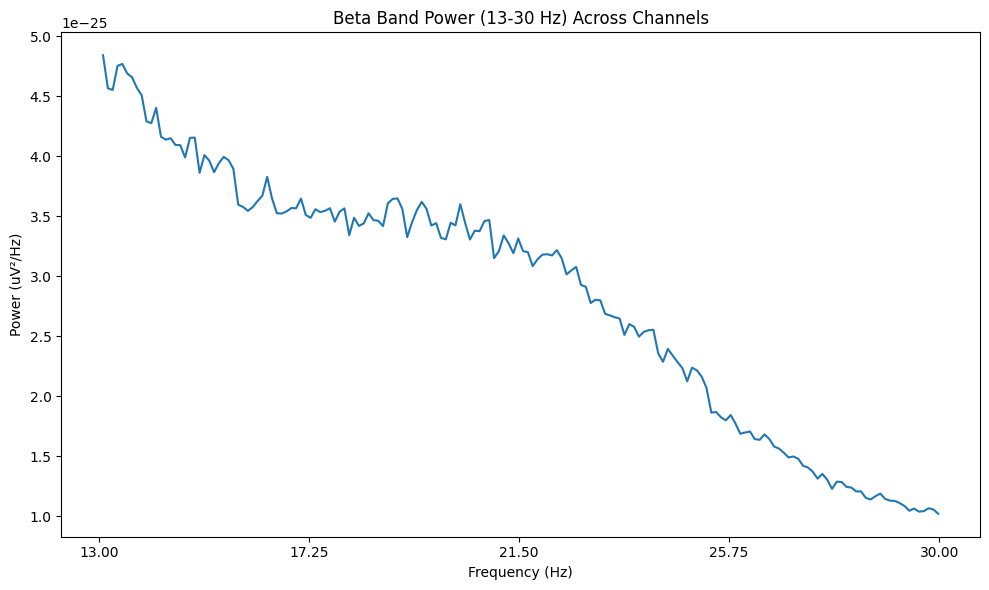

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d5 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d5.head())
print(d5.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d5_clean = d5.replace([np.inf, -np.inf], np.nan)
d5_clean = d5_clean.fillna(d5_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d5_scaled = pd.DataFrame(
    scaler.fit_transform(d5_clean),
    columns=d5_clean.columns,
    index=d5_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d5_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d5_scaled.index,
    columns=d5_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d5_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df5 = d5_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df5["Pd_indicator_meg"] = 1

print("\nShape of df5:", df5.shape)
print(df5.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345 = pd.concat([df1234, df5], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345 = df12345.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345):")
print(df12345)

# Print the shape
print("Shape of df12345:", df12345.shape) #(116,7)


Combined top channels (df12345):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.148423             0.060237          3.794677e-12  0.843069   
1      4.089981             0.061125          2.134013e-13  0.767457   
2      4.163265             0.060049          3.607224e-12  0.786598   
3      4.183673             0.059707          4.139047e-12  0.750612   
4      4.333024             0.057641          2.012607e-13  0.775638   
..          ...                  ...                   ...       ...   
285    3.811286             0.065595          5.095736e-12  0.867571   
286    3.701203             0.067546          2.953719e-13  0.960454   
287    3.861240             0.064746          4.902532e-12  0.895858   
288    3.658649             0.068331          5.627209e-12  1.044357   
289    3.731730             0.066993          3.086342e-13  0.943709   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.249889       13.5742

In [ ]:
df12345.to_csv('/content/drive/MyDrive/combined_features_upto_sub05_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345 preserved.")


RAM Used After Cleanup: 1.00 GB
Memory cleaned. df12345 preserved.


sub-6

In [ ]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-6'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-006_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-006_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-006_task-go_run-1_proc-tsss+mc_events.json', 'sub-006_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-006_coordsystem.json', 'sub-006_task-go_run-1_proc-tsss+mc_meg.json', 'sub-006_task-noise_proc-tsss_channels.tsv', 'sub-006_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-006_task-passive_run-1_proc-tsss+mc_events.json', 'sub-006_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-006_task-noise_proc-tsss_meg.fif', 'sub-006_task-noise_proc-tsss_meg.json', 'sub-006_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-006_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-006_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-006_task-rest_run-1_proc-tsss+mc_events.json', 'sub-006_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-006_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-006_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-006_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-006_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-006_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-006_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-006_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-6/meg/sub-006_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-6/meg/sub-006_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 91000 ... 1173999 =     91.000 ...  1173.999 secs
Ready.
Reading 0 ... 1082999  =      0.000 ...  1082.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitti

Computing Power Spectral Density

Effective window size : 10.240 (s)


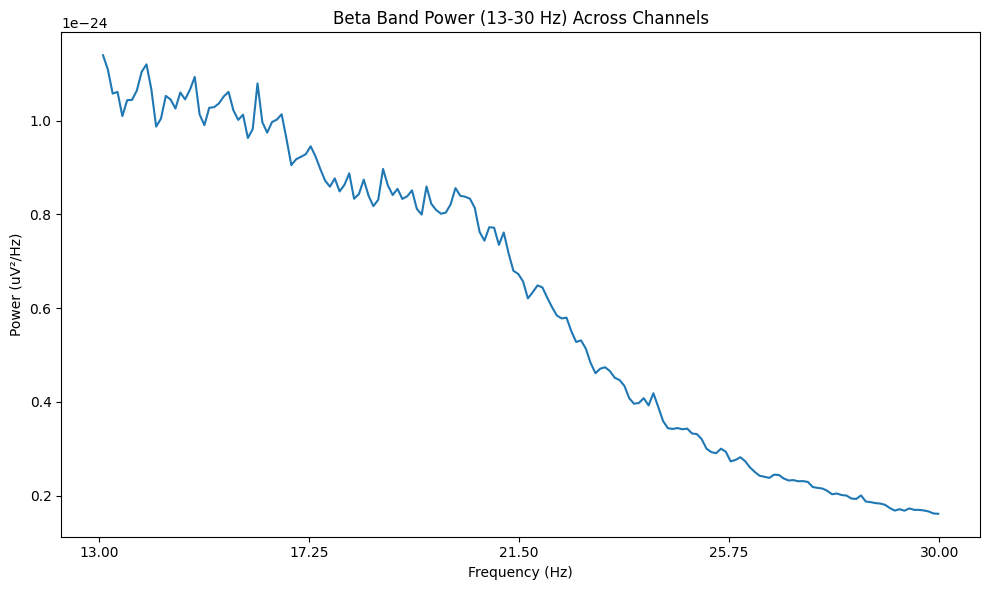

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d6 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d6.head())
print(d6.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d6_clean = d6.replace([np.inf, -np.inf], np.nan)
d6_clean = d6_clean.fillna(d6_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d6_scaled = pd.DataFrame(
    scaler.fit_transform(d6_clean),
    columns=d6_clean.columns,
    index=d6_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d6_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d6_scaled.index,
    columns=d6_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d6_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df6 = d6_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df6["Pd_indicator_meg"] = 0

print("\nShape of df5:", df6.shape)
print(df6.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456 = pd.concat([df12345, df6], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456 = df123456.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456):")
print(df123456)

# Print the shape
print("Shape of df123456:", df123456.shape) #(116,7)


Combined top channels (df123456):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.148423             0.060237          3.794677e-12  0.843069   
1      4.089981             0.061125          2.134013e-13  0.767457   
2      4.163265             0.060049          3.607224e-12  0.786598   
3      4.183673             0.059707          4.139047e-12  0.750612   
4      4.333024             0.057641          2.012607e-13  0.775638   
..          ...                  ...                   ...       ...   
343    3.231764             0.077357          1.009718e-11  1.046793   
344    3.337027             0.074917          5.724891e-13  0.993875   
345    3.287165             0.076053          1.076984e-11  1.056745   
346    3.353647             0.074546          1.100204e-11  1.019374   
347    3.340720             0.074834          5.729824e-13  0.981566   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.249889       13.574

In [ ]:
df123456.to_csv('/content/drive/MyDrive/combined_features_upto_sub06_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456 preserved.")


RAM Used After Cleanup: 1.02 GB
Memory cleaned. df123456 preserved.


sub-7

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-7'  # Replace with your folder path

In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-007_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-007_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-007_coordsystem.json', 'sub-007_task-go_run-1_proc-tsss+mc_events.json', 'sub-007_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-007_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-007_task-noise_proc-tsss_channels.tsv', 'sub-007_task-go_run-1_proc-tsss+mc_meg.json', 'sub-007_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-007_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-007_task-passive_run-1_proc-tsss+mc_events.json', 'sub-007_task-noise_proc-tsss_meg.json', 'sub-007_task-noise_proc-tsss_meg.fif', 'sub-007_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-007_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-007_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-007_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-007_task-rest_run-1_proc-tsss+mc_events.json', 'sub-007_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-007_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-007_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-007_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-007_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-007_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-7/meg/sub-007_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-7/meg/sub-007_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 65000 ... 1139999 =     65.000 ...  1139.999 secs
Ready.
Reading 0 ... 1074999  =      0.000 ...  1074.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitti

Computing Power Spectral Density

Effective window size : 10.240 (s)


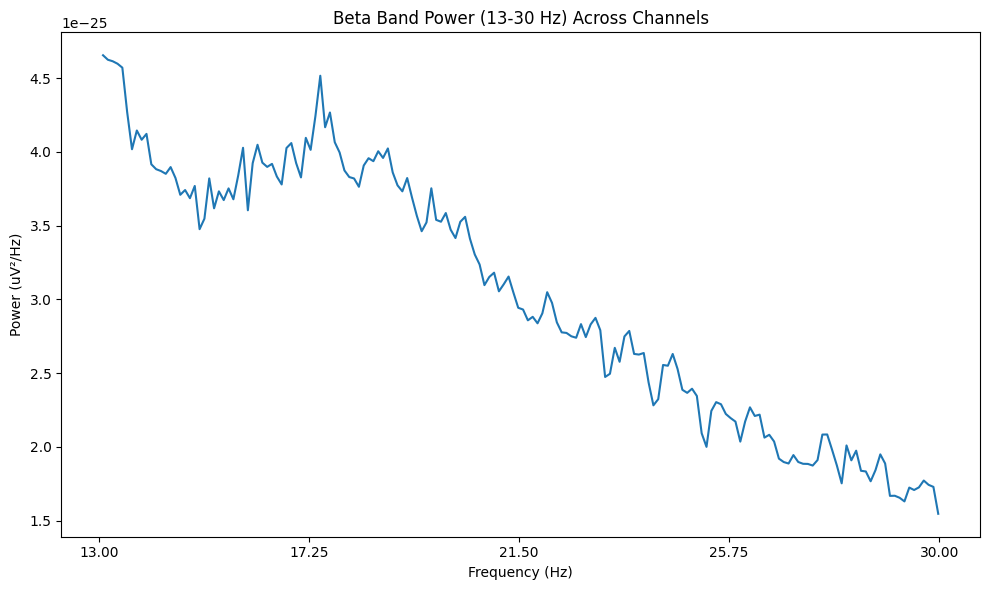

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d7 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d7.head())
print(d7.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d7_clean = d7.replace([np.inf, -np.inf], np.nan)
d7_clean = d7_clean.fillna(d7_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d7_scaled = pd.DataFrame(
    scaler.fit_transform(d7_clean),
    columns=d7_clean.columns,
    index=d7_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d7_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d7_scaled.index,
    columns=d7_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d7_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df7 = d7_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df7["Pd_indicator_meg"] = 0

print("\nShape of df5:", df7.shape)
print(df7.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567 = pd.concat([df123456, df7], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567 = df1234567.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567):")
print(df1234567)

# Print the shape
print("Shape of df1234567:", df1234567.shape) #(116,7)


Combined top channels (df1234567):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.148423             0.060237          3.794677e-12  0.843069   
1      4.089981             0.061125          2.134013e-13  0.767457   
2      4.163265             0.060049          3.607224e-12  0.786598   
3      4.183673             0.059707          4.139047e-12  0.750612   
4      4.333024             0.057641          2.012607e-13  0.775638   
..          ...                  ...                   ...       ...   
401    3.968372             0.062998          4.154307e-12  0.828609   
402    4.067907             0.061457          2.206349e-13  0.793174   
403    4.072558             0.061386          4.200691e-12  0.808658   
404    3.960930             0.063116          4.187425e-12  0.874726   
405    4.066047             0.061485          2.339508e-13  0.803291   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.249889       13.57

In [ ]:
df1234567.to_csv('/content/drive/MyDrive/combined_features_upto_sub07_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567 preserved.")


RAM Used After Cleanup: 1.02 GB
Memory cleaned. df1234567 preserved.


sub-8

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-8'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-008_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-008_task-go_run-1_proc-tsss+mc_events.json', 'sub-008_coordsystem.json', 'sub-008_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-008_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-008_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-008_task-go_run-1_proc-tsss+mc_meg.json', 'sub-008_task-noise_proc-tsss_channels.tsv', 'sub-008_task-noise_proc-tsss_meg.fif', 'sub-008_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-008_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-008_task-passive_run-1_proc-tsss+mc_events.json', 'sub-008_task-noise_proc-tsss_meg.json', 'sub-008_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-008_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-008_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-008_task-rest_run-1_proc-tsss+mc_events.json', 'sub-008_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-008_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-008_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-008_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-008_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-008_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-008_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-8/meg/sub-008_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-8/meg/sub-008_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 77000 ... 1150999 =     77.000 ...  1150.999 secs
Ready.
Reading 0 ... 1073999  =      0.000 ...  1073.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitti

Computing Power Spectral Density

Effective window size : 10.240 (s)


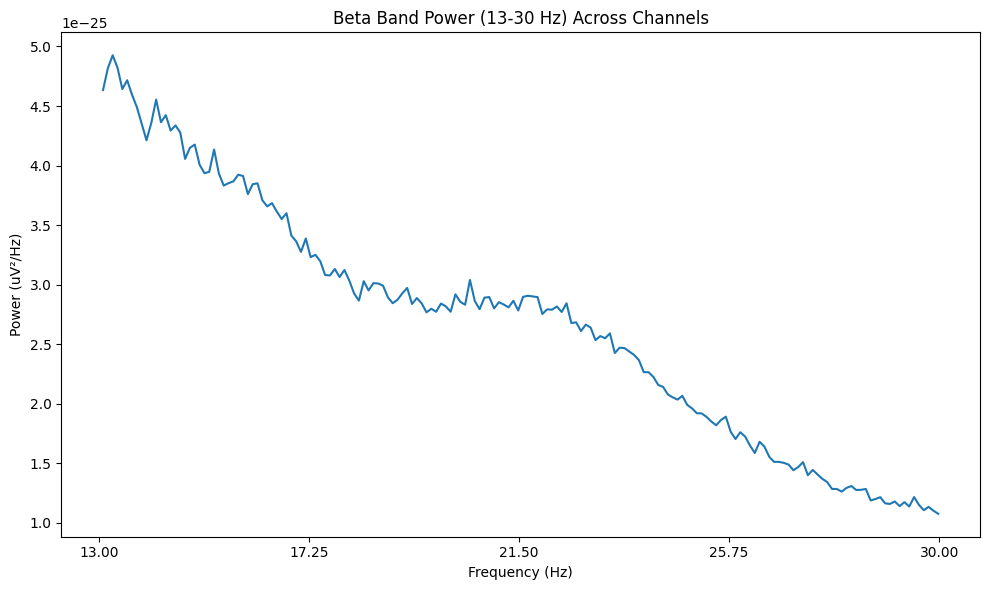

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d8 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d8.head())
print(d8.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channles

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d8_clean = d8.replace([np.inf, -np.inf], np.nan)
d8_clean = d8_clean.fillna(d8_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d8_scaled = pd.DataFrame(
    scaler.fit_transform(d8_clean),
    columns=d8_clean.columns,
    index=d8_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d8_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d8_scaled.index,
    columns=d8_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d8_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df8 = d8_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df8["Pd_indicator_meg"] = 1

print("\nShape of df5:", df8.shape)
print(df8.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678 = pd.concat([df1234567, df8], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678 = df12345678.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678):")
print(df12345678)

# Print the shape
print("Shape of df12345678:", df12345678.shape) #(116,7)


Combined top channels (df12345678):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.148423             0.060237          3.794677e-12  0.843069   
1      4.089981             0.061125          2.134013e-13  0.767457   
2      4.163265             0.060049          3.607224e-12  0.786598   
3      4.183673             0.059707          4.139047e-12  0.750612   
4      4.333024             0.057641          2.012607e-13  0.775638   
..          ...                  ...                   ...       ...   
459    3.926443             0.063671          5.416016e-12  0.813898   
460    3.655493             0.068390          3.370813e-13  0.846384   
461    3.992551             0.062617          5.873115e-12  0.794327   
462    3.970205             0.062969          5.649345e-12  0.835026   
463    3.567039             0.070086          3.446469e-13  0.854833   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.249889       13.5

In [ ]:
df12345678.to_csv('/content/drive/MyDrive/combined_features_upto_sub08_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678 preserved.")


RAM Used After Cleanup: 1.02 GB
Memory cleaned. df12345678 preserved.


sub-10

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-10'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-010_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-010_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-010_coordsystem.json', 'sub-010_task-go_run-1_proc-tsss+mc_events.json', 'sub-010_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-010_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-010_task-noise_proc-tsss_channels.tsv', 'sub-010_task-go_run-1_proc-tsss+mc_meg.json', 'sub-010_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-010_task-noise_proc-tsss_meg.fif', 'sub-010_task-passive_run-1_proc-tsss+mc_events.json', 'sub-010_task-noise_proc-tsss_meg.json', 'sub-010_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-010_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-010_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-010_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-010_task-rest_run-1_proc-tsss+mc_events.json', 'sub-010_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-010_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-010_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-010_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-010_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-010_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-010_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-10/meg/sub-010_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-10/meg/sub-010_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 106000 ... 1179999 =    106.000 ...  1179.999 secs
Ready.
Reading 0 ... 1073999  =      0.000 ...  1073.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


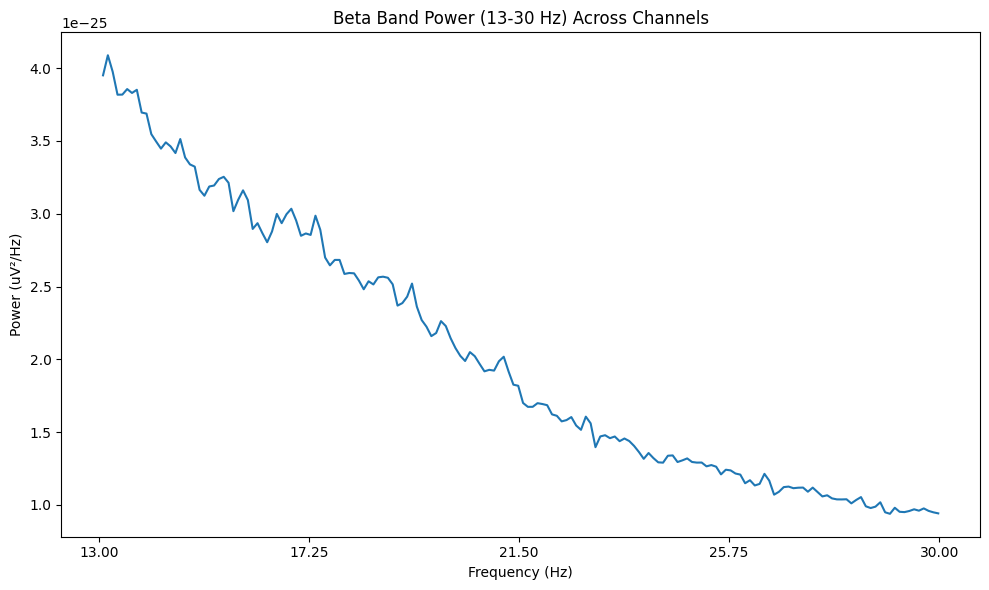

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d10 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d10.head())
print(d10.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d10_clean = d10.replace([np.inf, -np.inf], np.nan)
d10_clean = d10_clean.fillna(d10_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d10_scaled = pd.DataFrame(
    scaler.fit_transform(d10_clean),
    columns=d10_clean.columns,
    index=d10_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d10_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d10_scaled.index,
    columns=d10_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d10_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df10 = d10_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df10["Pd_indicator_meg"] = 1

print("\nShape of df5:", df10.shape)
print(df10.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810 = pd.concat([df12345678, df10], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810 = df1234567810.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810):")
print(df1234567810)

# Print the shape
print("Shape of df1234567810:", df1234567810.shape) #(116,7)


Combined top channels (df1234567810):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.148423             0.060237          3.794677e-12  0.843069   
1      4.089981             0.061125          2.134013e-13  0.767457   
2      4.163265             0.060049          3.607224e-12  0.786598   
3      4.183673             0.059707          4.139047e-12  0.750612   
4      4.333024             0.057641          2.012607e-13  0.775638   
..          ...                  ...                   ...       ...   
517    3.807263             0.065664          6.947952e-12  0.928656   
518    4.073557             0.061371          2.827965e-13  0.870645   
519    4.094041             0.061064          6.300368e-12  0.910290   
520    4.133147             0.060487          5.536156e-12  0.866077   
521    4.060521             0.061568          2.831754e-13  0.838496   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.249889       13

In [ ]:
df1234567810.to_csv('/content/drive/MyDrive/combined_features_upto_sub010_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810 preserved.")


RAM Used After Cleanup: 1.02 GB
Memory cleaned. df1234567810 preserved.


sub-11

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-11'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-011_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-011_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-011_task-go_run-1_proc-tsss+mc_events.json', 'sub-011_coordsystem.json', 'sub-011_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-011_task-go_run-1_proc-tsss+mc_meg.json', 'sub-011_task-noise_proc-tsss_channels.tsv', 'sub-011_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-011_task-noise_proc-tsss_meg.json', 'sub-011_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-011_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-011_task-passive_run-1_proc-tsss+mc_events.json', 'sub-011_task-noise_proc-tsss_meg.fif', 'sub-011_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-011_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-011_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-011_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-011_task-rest_run-1_proc-tsss+mc_events.json', 'sub-011_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-011_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-011_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-011_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-011_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-011_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-11/meg/sub-011_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-11/meg/sub-011_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 247000 ... 1332999 =    247.000 ...  1332.999 secs
Ready.
Reading 0 ... 1085999  =      0.000 ...  1085.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


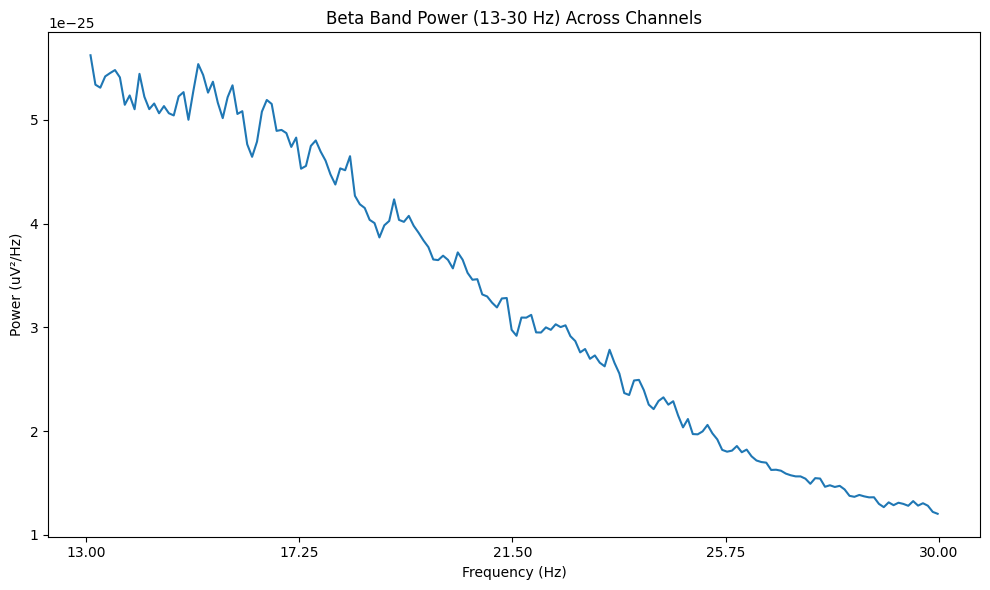

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d11 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d11.head())
print(d11.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d11_clean = d11.replace([np.inf, -np.inf], np.nan)
d11_clean = d11_clean.fillna(d11_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d11_scaled = pd.DataFrame(
    scaler.fit_transform(d11_clean),
    columns=d11_clean.columns,
    index=d11_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d11_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d11_scaled.index,
    columns=d11_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d11_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df11 = d11_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df11["Pd_indicator_meg"] = 0

print("\nShape of df5:", df11.shape)
print(df11.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011 = pd.concat([df1234567810, df11], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011 = df123456781011.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011):")
print(df123456781011)

# Print the shape
print("Shape of df123456781011:", df123456781011.shape) #(116,7)


Combined top channels (df123456781011):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.148423             0.060237          3.794677e-12  0.843069   
1      4.089981             0.061125          2.134013e-13  0.767457   
2      4.163265             0.060049          3.607224e-12  0.786598   
3      4.183673             0.059707          4.139047e-12  0.750612   
4      4.333024             0.057641          2.012607e-13  0.775638   
..          ...                  ...                   ...       ...   
575    3.534991             0.070698          6.900227e-12  0.943724   
576    3.124309             0.080018          4.321803e-13  1.070806   
577    3.503683             0.071353          7.288135e-12  0.967824   
578    3.417127             0.073161          7.745191e-12  0.984998   
579    3.508287             0.071260          3.782657e-13  0.970790   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.249889       

In [ ]:
df123456781011.to_csv('/content/drive/MyDrive/combined_features_upto_sub011_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011 preserved.")


RAM Used After Cleanup: 1.03 GB
Memory cleaned. df123456781011 preserved.


sub-12

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-12'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-012_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-012_task-go_run-1_proc-tsss+mc_events.json', 'sub-012_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-012_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-012_coordsystem.json', 'sub-012_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-012_task-go_run-1_proc-tsss+mc_meg.json', 'sub-012_task-noise_proc-tsss_channels.tsv', 'sub-012_task-noise_proc-tsss_meg.json', 'sub-012_task-noise_proc-tsss_meg.fif', 'sub-012_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-012_task-passive_run-1_proc-tsss+mc_events.json', 'sub-012_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-012_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-012_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-012_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-012_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-012_task-rest_run-1_proc-tsss+mc_events.json', 'sub-012_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-012_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-012_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-012_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-012_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-012_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-12/meg/sub-012_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-12/meg/sub-012_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 41000 ... 1117999 =     41.000 ...  1117.999 secs
Ready.
Reading 0 ... 1076999  =      0.000 ...  1076.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting 

Computing Power Spectral Density

Effective window size : 10.240 (s)


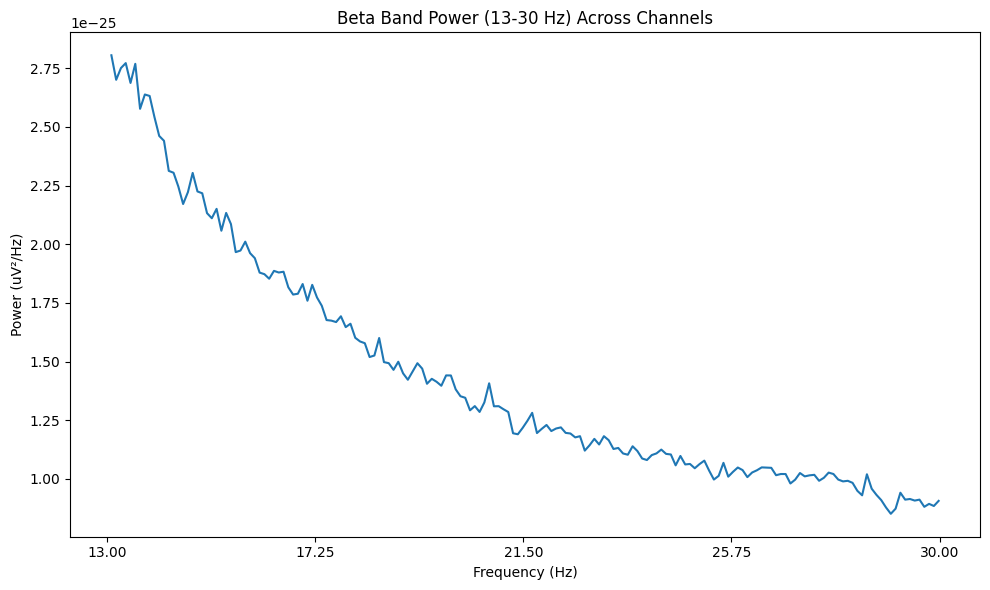

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d12 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d12.head())
print(d12.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d12_clean = d12.replace([np.inf, -np.inf], np.nan)
d12_clean = d12_clean.fillna(d12_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d12_scaled = pd.DataFrame(
    scaler.fit_transform(d12_clean),
    columns=d12_clean.columns,
    index=d12_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d12_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d12_scaled.index,
    columns=d12_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d12_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df12 = d12_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df12["Pd_indicator_meg"] = 1

print("\nShape of df5:", df12.shape)
print(df12.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112 = pd.concat([df123456781011, df12], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112 = df12345678101112.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112):")
print(df12345678101112)

# Print the shape
print("Shape of df12345678101112:", df12345678101112.shape) #(116,7)


Combined top channels (df12345678101112):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.148423             0.060237          3.794677e-12  0.843069   
1      4.089981             0.061125          2.134013e-13  0.767457   
2      4.163265             0.060049          3.607224e-12  0.786598   
3      4.183673             0.059707          4.139047e-12  0.750612   
4      4.333024             0.057641          2.012607e-13  0.775638   
..          ...                  ...                   ...       ...   
633    4.585887             0.054515          3.492889e-12  0.760675   
634    4.501393             0.055538          1.975870e-13  0.828586   
635    4.584958             0.054526          3.520250e-12  0.739614   
636    4.662024             0.053625          3.686936e-12  0.820140   
637    4.421541             0.056541          1.935057e-13  0.816266   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.249889     

In [ ]:
df12345678101112.to_csv('/content/drive/MyDrive/combined_features_upto_sub012_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112 preserved.")


RAM Used After Cleanup: 1.01 GB
Memory cleaned. df12345678101112 preserved.


sub-13

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-13'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-013_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-013_task-go_run-1_proc-tsss+mc_events.json', 'sub-013_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-013_coordsystem.json', 'sub-013_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-013_task-noise_proc-tsss_channels.tsv', 'sub-013_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-013_task-go_run-1_proc-tsss+mc_meg.json', 'sub-013_task-noise_proc-tsss_meg.json', 'sub-013_task-passive_run-1_proc-tsss+mc_events.json', 'sub-013_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-013_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-013_task-noise_proc-tsss_meg.fif', 'sub-013_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-013_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-013_task-rest_run-1_proc-tsss+mc_events.json', 'sub-013_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-013_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-013_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-013_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-013_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-013_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-013_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-013_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-13/meg/sub-013_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-13/meg/sub-013_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 120000 ... 1189999 =    120.000 ...  1189.999 secs
Ready.
Reading 0 ... 1069999  =      0.000 ...  1069.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


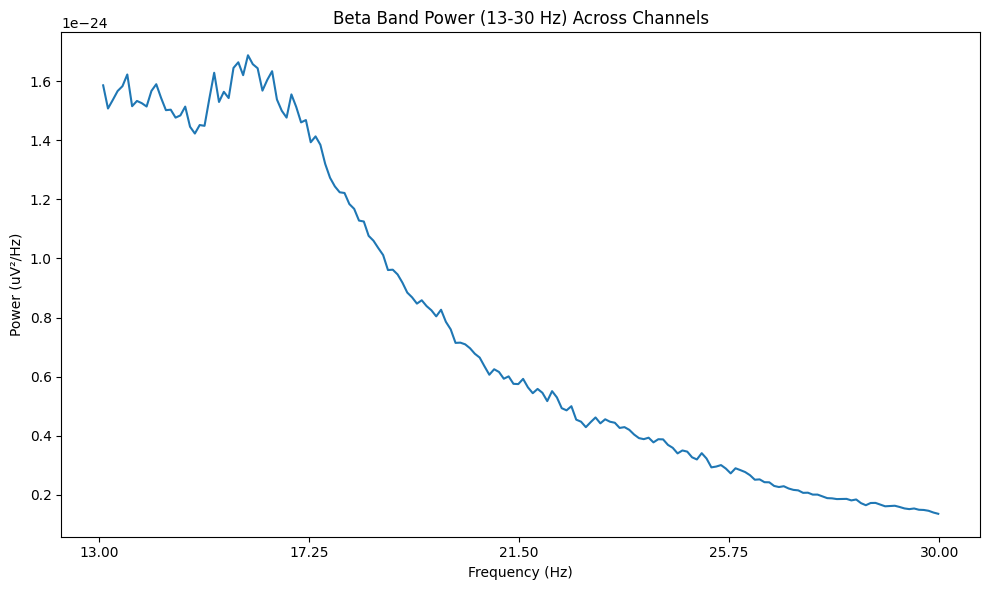

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d13 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d13.head())
print(d13.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d13_clean = d13.replace([np.inf, -np.inf], np.nan)
d13_clean = d13_clean.fillna(d13_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d13_scaled = pd.DataFrame(
    scaler.fit_transform(d13_clean),
    columns=d13_clean.columns,
    index=d13_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d13_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d13_scaled.index,
    columns=d13_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d13_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df13 = d13_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df13["Pd_indicator_meg"] = 1

print("\nShape of df5:", df13.shape)
print(df13.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213 = pd.concat([df12345678101112, df13], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213 = df1234567810111213.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213):")
print(df1234567810111213)

# Print the shape
print("Shape of df1234567810111213:", df1234567810111213.shape) #(116,7)


Combined top channels (df1234567810111213):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.148423             0.060237          3.794677e-12  0.843069   
1      4.089981             0.061125          2.134013e-13  0.767457   
2      4.163265             0.060049          3.607224e-12  0.786598   
3      4.183673             0.059707          4.139047e-12  0.750612   
4      4.333024             0.057641          2.012607e-13  0.775638   
..          ...                  ...                   ...       ...   
691    3.418692             0.073127          8.795559e-12  0.935677   
692    3.503738             0.071352          5.214089e-13  0.964245   
693    3.483178             0.071774          1.016912e-11  0.956030   
694    3.648598             0.068519          9.194698e-12  0.957879   
695    3.480374             0.071831          5.462359e-13  0.946394   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.249889   

In [ ]:
df1234567810111213.to_csv('/content/drive/MyDrive/combined_features_upto_sub013_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213 preserved.")


RAM Used After Cleanup: 1.04 GB
Memory cleaned. df1234567810111213 preserved.


sub-14

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-14'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-014_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-014_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-014_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-014_task-go_run-1_proc-tsss+mc_events.json', 'sub-014_coordsystem.json', 'sub-014_task-go_run-1_proc-tsss+mc_meg.json', 'sub-014_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-014_task-noise_proc-tsss_channels.tsv', 'sub-014_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-014_task-noise_proc-tsss_meg.fif', 'sub-014_task-passive_run-1_proc-tsss+mc_events.json', 'sub-014_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-014_task-noise_proc-tsss_meg.json', 'sub-014_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-014_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-014_task-rest_run-1_proc-tsss+mc_events.json', 'sub-014_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-014_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-014_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-014_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-014_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-014_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-014_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-014_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-14/meg/sub-014_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-14/meg/sub-014_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 51000 ... 1124999 =     51.000 ...  1124.999 secs
Ready.
Reading 0 ... 1073999  =      0.000 ...  1073.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


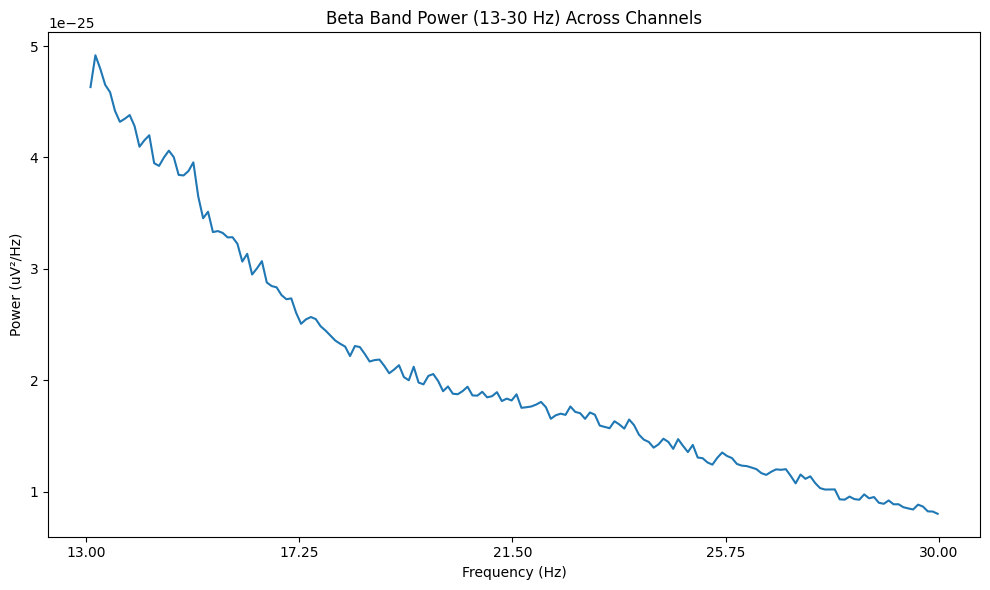

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d14 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d14.head())
print(d14.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extracion of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d14_clean = d14.replace([np.inf, -np.inf], np.nan)
d14_clean = d14_clean.fillna(d14_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d14_scaled = pd.DataFrame(
    scaler.fit_transform(d14_clean),
    columns=d14_clean.columns,
    index=d14_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d14_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d14_scaled.index,
    columns=d14_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d14_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df14 = d14_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df14["Pd_indicator_meg"] = 0

print("\nShape of df5:", df14.shape)
print(df14.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314 = pd.concat([df1234567810111213, df14], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314 = df123456781011121314.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314):")
print(df123456781011121314)

# Print the shape
print("Shape of df123456781011121314:", df123456781011121314.shape) #(116,7)


Combined top channels (df123456781011121314):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.148423             0.060237          3.794677e-12  0.843069   
1      4.089981             0.061125          2.134013e-13  0.767457   
2      4.163265             0.060049          3.607224e-12  0.786598   
3      4.183673             0.059707          4.139047e-12  0.750612   
4      4.333024             0.057641          2.012607e-13  0.775638   
..          ...                  ...                   ...       ...   
749    4.297952             0.058167          4.028105e-12  0.935850   
750    3.905959             0.064005          2.608118e-13  1.115044   
751    4.149907             0.060242          4.735867e-12  1.005120   
752    4.256983             0.058727          4.715593e-12  0.932341   
753    3.933892             0.063550          2.647216e-13  1.097142   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.249889 

In [ ]:
df123456781011121314.to_csv('/content/drive/MyDrive/combined_features_upto_sub014_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314 preserved.")


RAM Used After Cleanup: 1.04 GB
Memory cleaned. df123456781011121314 preserved.


sub-15

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-15'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-015_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-015_task-go_run-1_proc-tsss+mc_events.json', 'sub-015_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-015_coordsystem.json', 'sub-015_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-015_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-015_task-noise_proc-tsss_channels.tsv', 'sub-015_task-go_run-1_proc-tsss+mc_meg.json', 'sub-015_task-noise_proc-tsss_meg.fif', 'sub-015_task-noise_proc-tsss_meg.json', 'sub-015_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-015_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-015_task-passive_run-1_proc-tsss+mc_events.json', 'sub-015_task-rest_run-1_proc-tsss+mc_events.json', 'sub-015_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-015_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-015_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-015_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-015_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-015_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-015_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-015_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-015_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-015_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-15/meg/sub-015_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-15/meg/sub-015_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 80000 ... 1175999 =     80.000 ...  1175.999 secs
Ready.
Reading 0 ... 1095999  =      0.000 ...  1095.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


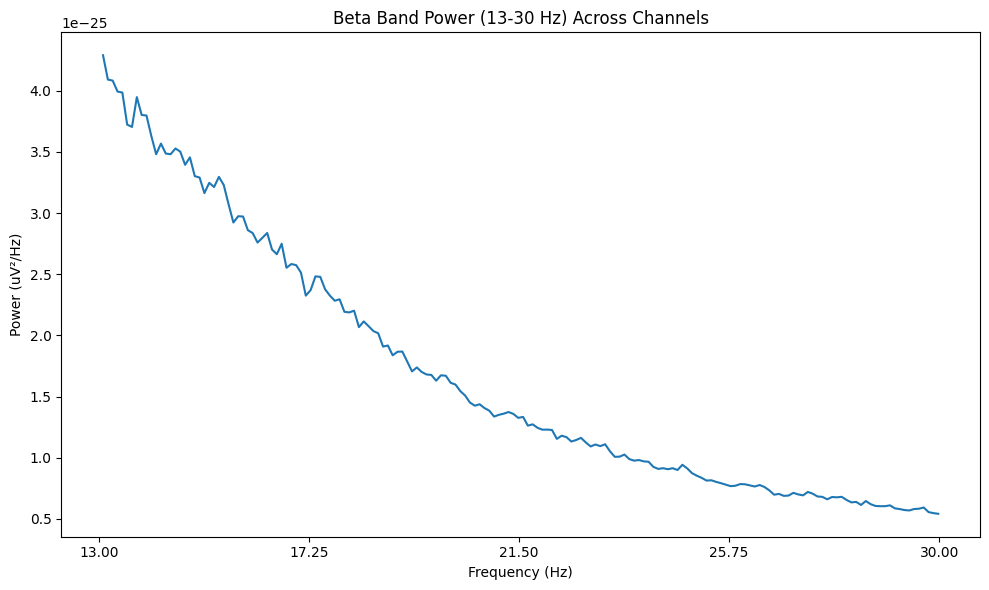

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d15 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d15.head())
print(d15.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d15_clean = d15.replace([np.inf, -np.inf], np.nan)
d15_clean = d15_clean.fillna(d15_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d15_scaled = pd.DataFrame(
    scaler.fit_transform(d15_clean),
    columns=d15_clean.columns,
    index=d15_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d15_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d15_scaled.index,
    columns=d15_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d15_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df15 = d15_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df15["Pd_indicator_meg"] = 1

print("\nShape of df5:", df15.shape)
print(df15.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415 = pd.concat([df123456781011121314, df15], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415 = df12345678101112131415.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415):")
print(df12345678101112131415)

# Print the shape
print("Shape of df12345678101112131415:", df12345678101112131415.shape) #(116,7)


Combined top channels (df12345678101112131415):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.148423             0.060237          3.794677e-12  0.843069   
1      4.089981             0.061125          2.134013e-13  0.767457   
2      4.163265             0.060049          3.607224e-12  0.786598   
3      4.183673             0.059707          4.139047e-12  0.750612   
4      4.333024             0.057641          2.012607e-13  0.775638   
..          ...                  ...                   ...       ...   
807    4.493613             0.055635          2.872989e-12  0.762107   
808    4.150547             0.060233          1.986415e-13  0.798486   
809    4.443431             0.056255          3.146798e-12  0.759559   
810    4.260949             0.058648          3.381577e-12  0.820661   
811    4.087591             0.061161          1.976062e-13  0.806441   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.24988

In [ ]:
df12345678101112131415.to_csv('/content/drive/MyDrive/combined_features_upto_sub015_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415 preserved.")


RAM Used After Cleanup: 1.05 GB
Memory cleaned. df12345678101112131415 preserved.


sub-16

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-16'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-016_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-016_task-go_run-1_proc-tsss+mc_events.json', 'sub-016_coordsystem.json', 'sub-016_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-016_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-016_task-noise_proc-tsss_channels.tsv', 'sub-016_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-016_task-go_run-1_proc-tsss+mc_meg.json', 'sub-016_task-noise_proc-tsss_meg.fif', 'sub-016_task-noise_proc-tsss_meg.json', 'sub-016_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-016_task-passive_run-1_proc-tsss+mc_events.json', 'sub-016_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-016_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-016_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-016_task-rest_run-1_proc-tsss+mc_events.json', 'sub-016_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-016_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-016_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-016_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-016_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-016_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-016_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-016_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-16/meg/sub-016_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-16/meg/sub-016_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 124000 ... 1188999 =    124.000 ...  1188.999 secs
Ready.
Reading 0 ... 1064999  =      0.000 ...  1064.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spetral Density

Effective window size : 10.240 (s)


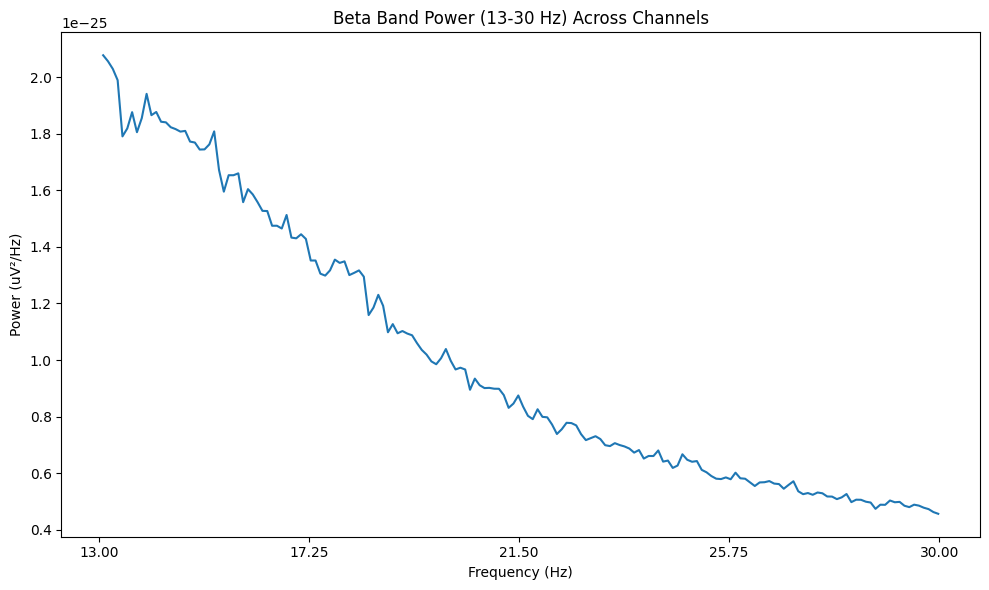

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d16 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d16.head())
print(d16.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d16_clean = d16.replace([np.inf, -np.inf], np.nan)
d16_clean = d16_clean.fillna(d16_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d16_scaled = pd.DataFrame(
    scaler.fit_transform(d16_clean),
    columns=d16_clean.columns,
    index=d16_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d16_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d16_scaled.index,
    columns=d16_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d16_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df16 = d16_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df16["Pd_indicator_meg"] = 0

print("\nShape of df5:", df16.shape)
print(df16.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516 = pd.concat([df12345678101112131415, df16], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516 = df1234567810111213141516.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516):")
print(df1234567810111213141516)

# Print the shape
print("Shape of df1234567810111213141516:", df1234567810111213141516.shape) #(116,7)


Combined top channels (df1234567810111213141516):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.148423             0.060237          3.794677e-12  0.843069   
1      4.089981             0.061125          2.134013e-13  0.767457   
2      4.163265             0.060049          3.607224e-12  0.786598   
3      4.183673             0.059707          4.139047e-12  0.750612   
4      4.333024             0.057641          2.012607e-13  0.775638   
..          ...                  ...                   ...       ...   
865    3.987793             0.062691          2.896219e-12  0.842103   
866    3.401878             0.073489          1.935397e-13  0.962167   
867    4.089202             0.061137          3.257873e-12  0.840718   
868    3.992488             0.062618          2.672820e-12  0.806662   
869    3.439437             0.072686          1.975056e-13  0.918764   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.249

In [ ]:
df1234567810111213141516.to_csv('/content/drive/MyDrive/combined_features_upto_sub016_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516 preserved.")


RAM Used After Cleanup: 1.05 GB
Memory cleaned. df1234567810111213141516 preserved.


sub-17

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-17'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-017_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-017_coordsystem.json', 'sub-017_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-017_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-017_task-go_run-1_proc-tsss+mc_events.json', 'sub-017_task-noise_proc-tsss_channels.tsv', 'sub-017_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-017_task-go_run-1_proc-tsss+mc_meg.json', 'sub-017_task-noise_proc-tsss_meg.json', 'sub-017_task-passive_run-1_proc-tsss+mc_events.json', 'sub-017_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-017_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-017_task-noise_proc-tsss_meg.fif', 'sub-017_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-017_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-017_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-017_task-rest_run-1_proc-tsss+mc_events.json', 'sub-017_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-017_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-017_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-017_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-017_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-017_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-017_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
import os
import mne
import numpy as np

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nLoading .fif file: {fif_file_path}")

        # THIS is the important step
        raw = mne.io.read_raw_fif(fif_file_path, preload=True)

else:
    print(f"No .fif files found for task '{task_to_load}'.")



Loading .fif file: /content/drive/MyDrive/sub-17/meg/sub-017_task-passive_run-1_proc-tsss+mc_meg.fif
Opening raw data file /content/drive/MyDrive/sub-17/meg/sub-017_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 340000 ... 1425999 =    340.000 ...  1425.999 secs
Ready.
Reading 0 ... 1085999  =      0.000 ...  1085.999 secs...


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-17/meg/sub-017_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 340000 ... 1425999 =    340.000 ...  1425.999 secs
Ready.
Reading 0 ... 1085999  =      0.000 ...  1085.999 secs...
Finding events on: STI101
302 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
302 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


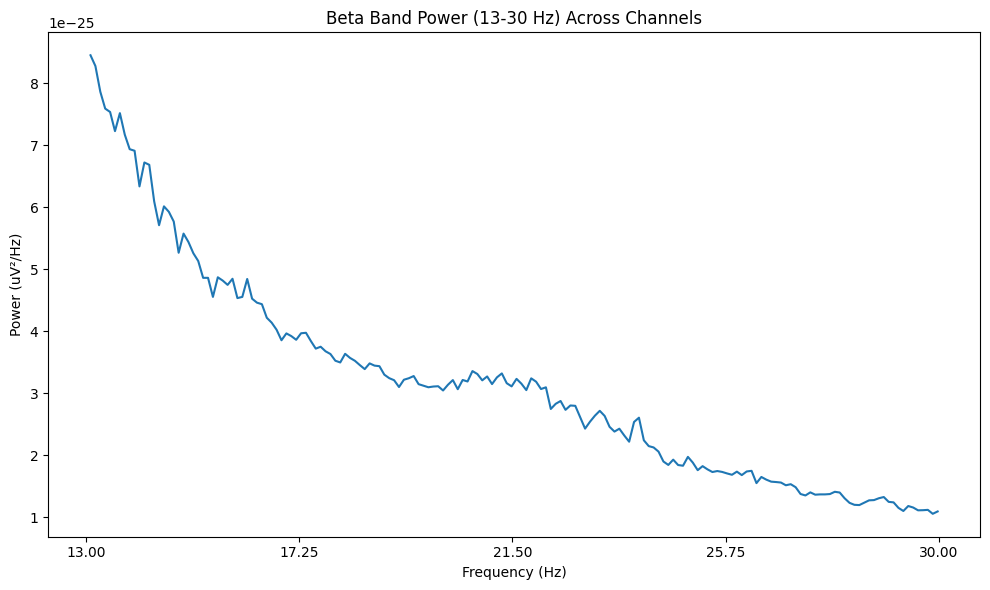

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d17 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d17.head())
print(d17.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d17_clean = d17.replace([np.inf, -np.inf], np.nan)
d17_clean = d17_clean.fillna(d17_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d17_scaled = pd.DataFrame(
    scaler.fit_transform(d17_clean),
    columns=d17_clean.columns,
    index=d17_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d17_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d17_scaled.index,
    columns=d17_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d17_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df17 = d17_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df17["Pd_indicator_meg"] = 0

print("\nShape of df5:", df17.shape)
print(df17.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617 = pd.concat([df1234567810111213141516, df17], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617 = df123456781011121314151617.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617):")
print(df123456781011121314151617)

# Print the shape
print("Shape of df123456781011121314151617:", df123456781011121314151617.shape) #(116,7)


Combined top channels (df123456781011121314151617):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.148423             0.060237          3.794677e-12  0.843069   
1      4.089981             0.061125          2.134013e-13  0.767457   
2      4.163265             0.060049          3.607224e-12  0.786598   
3      4.183673             0.059707          4.139047e-12  0.750612   
4      4.333024             0.057641          2.012607e-13  0.775638   
..          ...                  ...                   ...       ...   
923    3.603131             0.069384          7.992885e-12  1.138800   
924    3.874770             0.064520          4.144527e-13  1.167186   
925    3.664825             0.068216          8.736416e-12  1.100730   
926    3.755064             0.066577          7.728831e-12  1.144969   
927    3.790055             0.065962          4.360621e-13  1.210548   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0.2

In [ ]:
df123456781011121314151617.to_csv('/content/drive/MyDrive/combined_features_upto_sub017_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617 preserved.")


RAM Used After Cleanup: 1.07 GB
Memory cleaned. df123456781011121314151617 preserved.


sub-18

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-18'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-018_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-018_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-018_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-018_task-go_run-1_proc-tsss+mc_events.json', 'sub-018_coordsystem.json', 'sub-018_task-noise_proc-tsss_channels.tsv', 'sub-018_task-go_run-1_proc-tsss+mc_meg.json', 'sub-018_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-018_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-018_task-noise_proc-tsss_meg.fif', 'sub-018_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-018_task-noise_proc-tsss_meg.json', 'sub-018_task-passive_run-1_proc-tsss+mc_events.json', 'sub-018_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-018_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-018_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-018_task-rest_run-1_proc-tsss+mc_events.json', 'sub-018_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-018_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-018_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-018_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-018_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-018_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-018_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-18/meg/sub-018_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-18/meg/sub-018_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 8000 ... 1142999 =      8.000 ...  1142.999 secs
Ready.
Reading 0 ... 1134999  =      0.000 ...  1134.999 secs...
Finding events on: STI101
312 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
312 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting I

Computing Power Spectral Density

Effective window size : 10.240 (s)


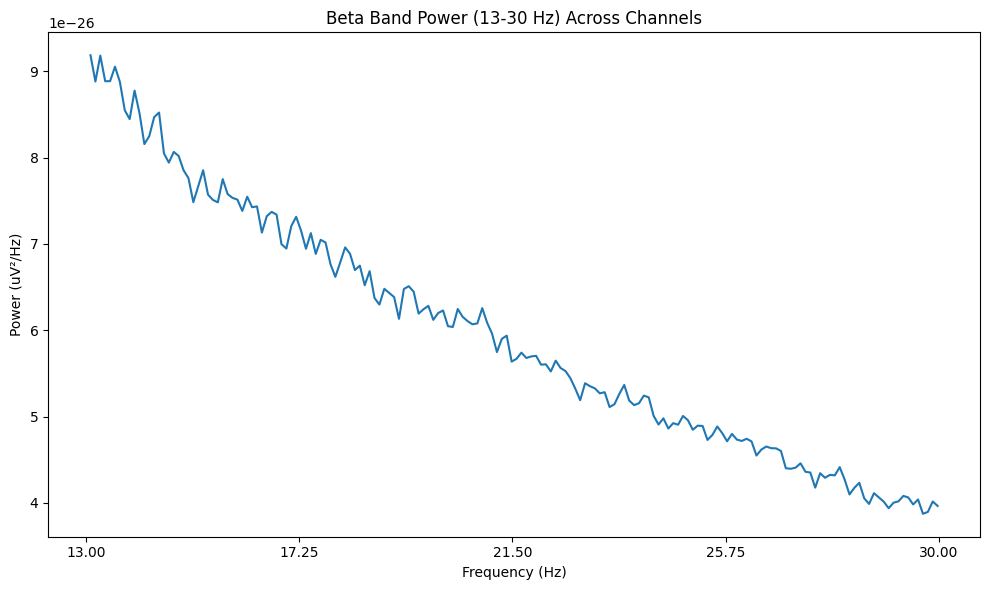

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d18 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d18.head())
print(d18.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d18_clean = d18.replace([np.inf, -np.inf], np.nan)
d18_clean = d18_clean.fillna(d18_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d18_scaled = pd.DataFrame(
    scaler.fit_transform(d18_clean),
    columns=d18_clean.columns,
    index=d18_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d18_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d18_scaled.index,
    columns=d18_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d18_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df18 = d18_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df18["Pd_indicator_meg"] = 0

print("\nShape of df5:", df18.shape)
print(df18.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718 = pd.concat([df123456781011121314151617, df18], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718 = df12345678101112131415161718.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718):")
print(df12345678101112131415161718)

# Print the shape
print("Shape of df12345678101112131415161718:", df12345678101112131415161718.shape) #(116,7)


Combined top channels (df12345678101112131415161718):
     burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0      4.148423             0.060237          3.794677e-12  0.843069   
1      4.089981             0.061125          2.134013e-13  0.767457   
2      4.163265             0.060049          3.607224e-12  0.786598   
3      4.183673             0.059707          4.139047e-12  0.750612   
4      4.333024             0.057641          2.012607e-13  0.775638   
..          ...                  ...                   ...       ...   
981    4.650220             0.053761          2.286671e-12  0.714711   
982    4.369163             0.057219          1.344591e-13  0.732186   
983    4.622026             0.054089          2.526526e-12  0.718980   
984    4.577974             0.054609          2.314223e-12  0.733890   
985    4.358590             0.057358          1.298972e-13  0.737936   

     duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_ibi  \
0      0

In [ ]:
df12345678101112131415161718.to_csv('/content/drive/MyDrive/combined_features_upto_sub018_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718 preserved.")


RAM Used After Cleanup: 1.08 GB
Memory cleaned. df12345678101112131415161718 preserved.


sub-19

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-19'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-019_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-019_task-go_run-1_proc-tsss+mc_events.json', 'sub-019_coordsystem.json', 'sub-019_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-019_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-019_task-go_run-1_proc-tsss+mc_meg.json', 'sub-019_task-noise_proc-tsss_channels.tsv', 'sub-019_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-019_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-019_task-noise_proc-tsss_meg.json', 'sub-019_task-passive_run-1_proc-tsss+mc_events.json', 'sub-019_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-019_task-rest_run-1_proc-tsss+mc_events.json', 'sub-019_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-019_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-019_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


No .fif files found for task 'passive'.


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-18/meg/sub-018_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 8000 ... 1142999 =      8.000 ...  1142.999 secs
Ready.
Reading 0 ... 1134999  =      0.000 ...  1134.999 secs...
Finding events on: STI101
312 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
312 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting I

Computing Power Spectral Density

Effective window size : 10.240 (s)


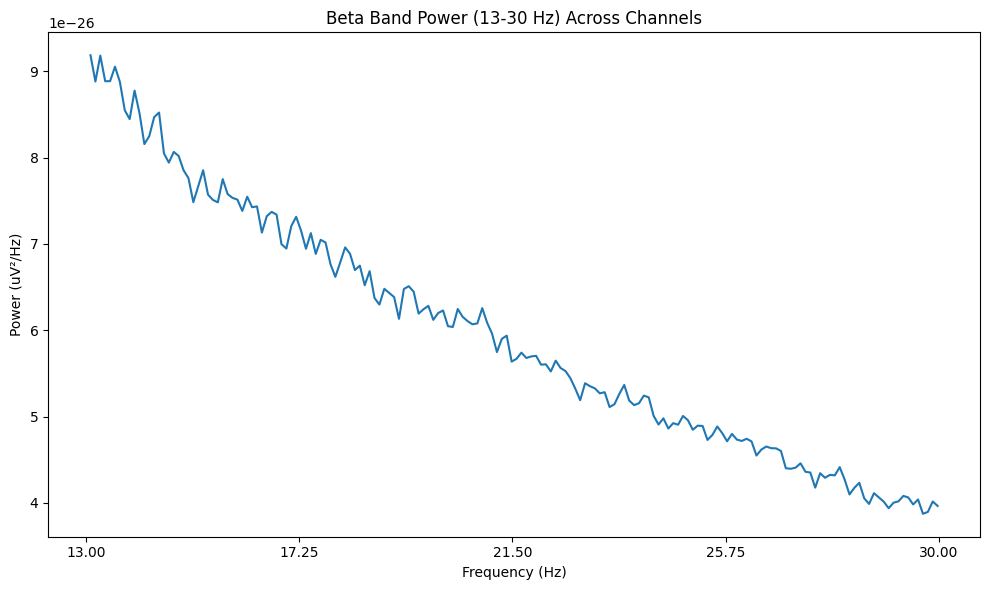

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d19 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d19.head())
print(d19.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d19_clean = d19.replace([np.inf, -np.inf], np.nan)
d19_clean = d19_clean.fillna(d19_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d19_scaled = pd.DataFrame(
    scaler.fit_transform(d19_clean),
    columns=d19_clean.columns,
    index=d19_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d19_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d19_scaled.index,
    columns=d19_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d19_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df19 = d19_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df19["Pd_indicator_meg"] = 0

print("\nShape of df5:", df19.shape)
print(df19.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819 = pd.concat([df12345678101112131415161718, df19], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819 = df1234567810111213141516171819.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819):")
print(df1234567810111213141516171819)

# Print the shape
print("Shape of df1234567810111213141516171819:", df1234567810111213141516171819.shape) #(116,7)


Combined top channels (df1234567810111213141516171819):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
1039    4.650220             0.053761          2.286671e-12  0.714711   
1040    4.369163             0.057219          1.344591e-13  0.732186   
1041    4.622026             0.054089          2.526526e-12  0.718980   
1042    4.577974             0.054609          2.314223e-12  0.733890   
1043    4.358590             0.057358          1.298972e-13  0.737936   

      duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mean_

In [ ]:
df1234567810111213141516171819.to_csv('/content/drive/MyDrive/combined_features_upto_sub019_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819 preserved.")


RAM Used After Cleanup: 1.08 GB
Memory cleaned. df1234567810111213141516171819 preserved.


sub-21

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-21'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-021_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-021_coordsystem.json', 'sub-021_task-go_run-1_proc-tsss+mc_events.json', 'sub-021_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-021_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-021_task-noise_proc-tsss_channels.tsv', 'sub-021_task-go_run-1_proc-tsss+mc_meg.json', 'sub-021_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-021_task-passive_run-1_proc-tsss+mc_events.json', 'sub-021_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-021_task-noise_proc-tsss_meg.json', 'sub-021_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-021_task-rest_run-1_proc-tsss+mc_events.json', 'sub-021_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-021_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-021_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


No .fif files found for task 'passive'.


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-18/meg/sub-018_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 8000 ... 1142999 =      8.000 ...  1142.999 secs
Ready.
Reading 0 ... 1134999  =      0.000 ...  1134.999 secs...
Finding events on: STI101
312 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
312 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting I

Computing Power Spectral Density

Effective window size : 10.240 (s)


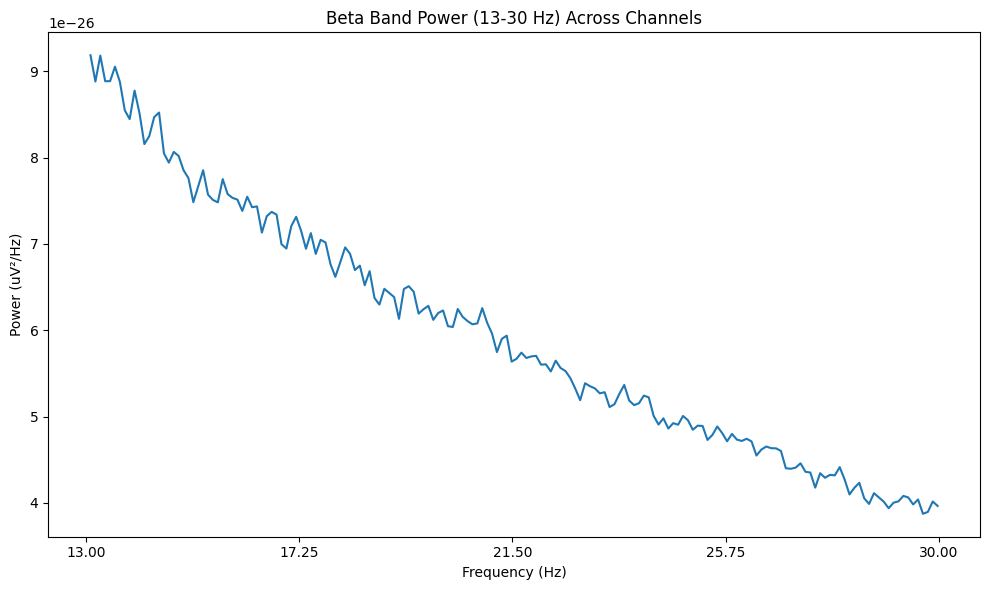

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d21 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d21.head())
print(d21.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d21_clean = d21.replace([np.inf, -np.inf], np.nan)
d21_clean = d21_clean.fillna(d21_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d21_scaled = pd.DataFrame(
    scaler.fit_transform(d21_clean),
    columns=d21_clean.columns,
    index=d21_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d21_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d21_scaled.index,
    columns=d21_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d21_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df21 = d21_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df21["Pd_indicator_meg"] = 0

print("\nShape of df5:", df21.shape)
print(df21.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921 = pd.concat([df1234567810111213141516171819, df21], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921 = df123456781011121314151617181921.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921):")
print(df123456781011121314151617181921)

# Print the shape
print("Shape of df123456781011121314151617181921:", df123456781011121314151617181921.shape) #(116,7)


Combined top channels (df123456781011121314151617181921):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
1097    4.650220             0.053761          2.286671e-12  0.714711   
1098    4.369163             0.057219          1.344591e-13  0.732186   
1099    4.622026             0.054089          2.526526e-12  0.718980   
1100    4.577974             0.054609          2.314223e-12  0.733890   
1101    4.358590             0.057358          1.298972e-13  0.737936   

      duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  mea

In [ ]:
df123456781011121314151617181921.to_csv('/content/drive/MyDrive/combined_features_upto_sub021_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921 preserved.")


RAM Used After Cleanup: 1.07 GB
Memory cleaned. df123456781011121314151617181921 preserved.


sub-22

In [ ]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-22'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-022_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-022_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-022_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-022_coordsystem.json', 'sub-022_task-go_run-1_proc-tsss+mc_events.json', 'sub-022_task-go_run-1_proc-tsss+mc_meg.json', 'sub-022_task-noise_proc-tsss_channels.tsv', 'sub-022_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-022_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-022_task-passive_run-1_proc-tsss+mc_events.json', 'sub-022_task-noise_proc-tsss_meg.json', 'sub-022_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-022_task-rest_run-1_proc-tsss+mc_events.json', 'sub-022_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-022_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-022_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


No .fif files found for task 'passive'.


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-18/meg/sub-018_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 8000 ... 1142999 =      8.000 ...  1142.999 secs
Ready.
Reading 0 ... 1134999  =      0.000 ...  1134.999 secs...
Finding events on: STI101
312 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
312 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting I

Computing Power Spectral Density

Effective window size : 10.240 (s)


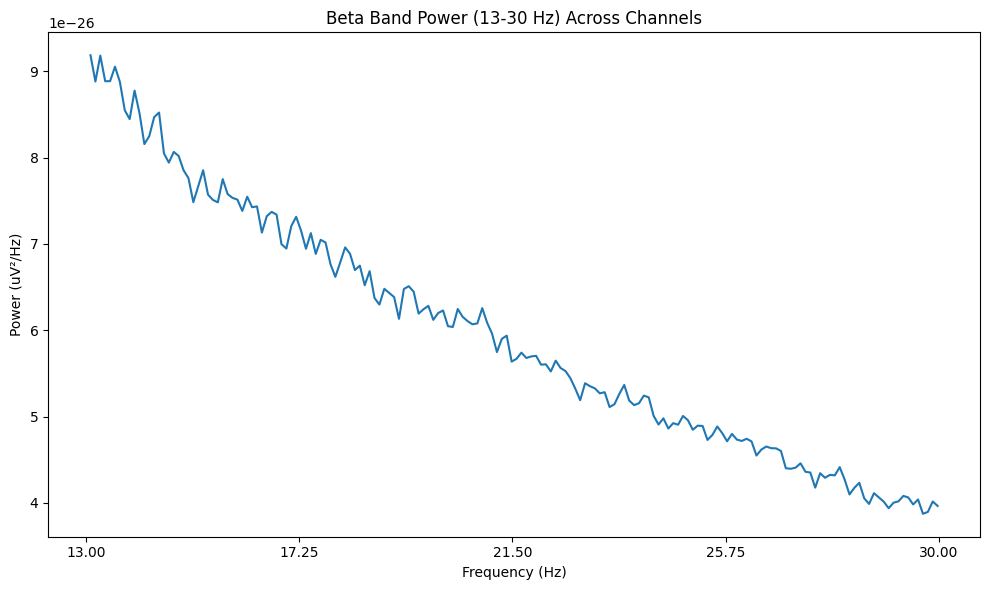

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d22 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d22.head())
print(d22.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d22_clean = d22.replace([np.inf, -np.inf], np.nan)
d22_clean = d22_clean.fillna(d22_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d22_scaled = pd.DataFrame(
    scaler.fit_transform(d22_clean),
    columns=d22_clean.columns,
    index=d22_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d22_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d22_scaled.index,
    columns=d22_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d22_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df22 = d22_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df22["Pd_indicator_meg"] = 1

print("\nShape of df5:", df22.shape)
print(df22.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122 = pd.concat([df123456781011121314151617181921, df22], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122 = df12345678101112131415161718192122.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122):")
print(df12345678101112131415161718192122)

# Print the shape
print("Shape of df12345678101112131415161718192122:", df12345678101112131415161718192122.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
1155    4.650220             0.053761          2.286671e-12  0.714711   
1156    4.369163             0.057219          1.344591e-13  0.732186   
1157    4.622026             0.054089          2.526526e-12  0.718980   
1158    4.577974             0.054609          2.314223e-12  0.733890   
1159    4.358590             0.057358          1.298972e-13  0.737936   

      duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv  m

In [ ]:
df12345678101112131415161718192122.to_csv('/content/drive/MyDrive/combined_features_upto_sub022_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122 preserved.")


RAM Used After Cleanup: 1.07 GB
Memory cleaned. df12345678101112131415161718192122 preserved.


sub-23

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-23'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-023_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-023_task-go_run-1_proc-tsss+mc_events.json', 'sub-023_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-023_coordsystem.json', 'sub-023_task-noise_proc-tsss_channels.tsv', 'sub-023_task-go_run-1_proc-tsss+mc_meg.json', 'sub-023_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-023_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-023_task-noise_proc-tsss_meg.json', 'sub-023_task-passive_run-1_proc-tsss+mc_events.json', 'sub-023_task-rest_run-1_proc-tsss+mc_events.json', 'sub-023_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-023_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-023_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-023_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


No .fif files found for task 'passive'.


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-18/meg/sub-018_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 8000 ... 1142999 =      8.000 ...  1142.999 secs
Ready.
Reading 0 ... 1134999  =      0.000 ...  1134.999 secs...
Finding events on: STI101
312 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
312 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting I

Computing Power Spectral Density

Effective window size : 10.240 (s)


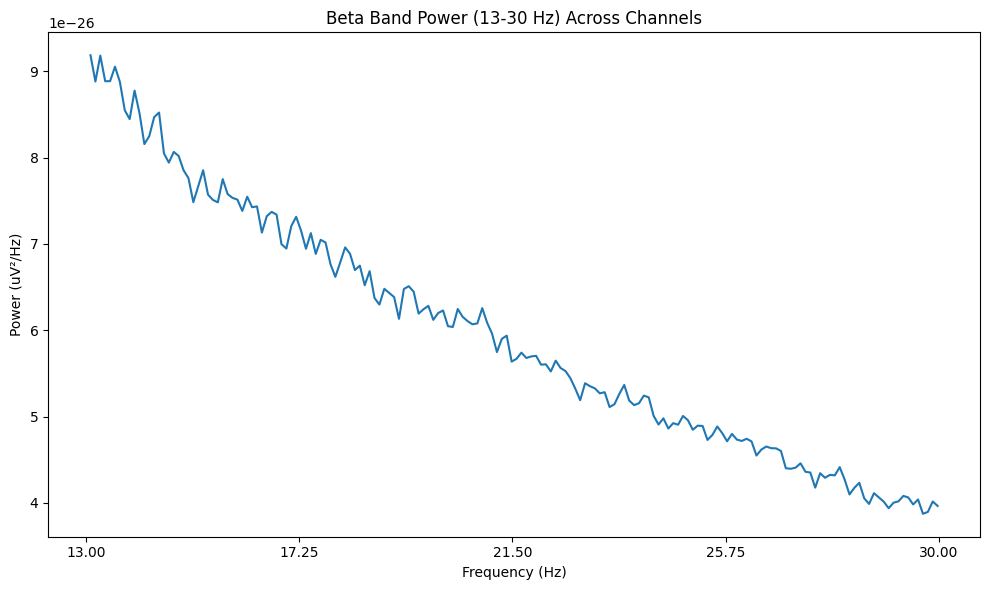

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d23 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d23.head())
print(d23.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d23_clean = d23.replace([np.inf, -np.inf], np.nan)
d23_clean = d23_clean.fillna(d23_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d23_scaled = pd.DataFrame(
    scaler.fit_transform(d23_clean),
    columns=d23_clean.columns,
    index=d23_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d23_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d23_scaled.index,
    columns=d23_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d23_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df23 = d23_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df23["Pd_indicator_meg"] = 0

print("\nShape of df5:", df23.shape)
print(df23.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223 = pd.concat([df12345678101112131415161718192122, df23], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223 = df1234567810111213141516171819212223.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223):")
print(df1234567810111213141516171819212223)

# Print the shape
print("Shape of df1234567810111213141516171819212223:", df1234567810111213141516171819212223.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
1213    4.650220             0.053761          2.286671e-12  0.714711   
1214    4.369163             0.057219          1.344591e-13  0.732186   
1215    4.622026             0.054089          2.526526e-12  0.718980   
1216    4.577974             0.054609          2.314223e-12  0.733890   
1217    4.358590             0.057358          1.298972e-13  0.737936   

      duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_cv 

In [ ]:
df1234567810111213141516171819212223.to_csv('/content/drive/MyDrive/combined_features_upto_sub023_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223 preserved.")


RAM Used After Cleanup: 1.07 GB
Memory cleaned. df1234567810111213141516171819212223 preserved.


sub-24

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-24'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-024_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-024_task-go_run-1_proc-tsss+mc_events.json', 'sub-024_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-024_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-024_coordsystem.json', 'sub-024_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-024_task-noise_proc-tsss_meg.fif', 'sub-024_task-noise_proc-tsss_channels.tsv', 'sub-024_task-go_run-1_proc-tsss+mc_meg.json', 'sub-024_task-noise_proc-tsss_meg.json', 'sub-024_task-passive_run-1_proc-tsss+mc_events.json', 'sub-024_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-024_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-024_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-024_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-024_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-024_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-024_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-024_task-rest_run-1_proc-tsss+mc_events.json', 'sub-024_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-024_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-024_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-024_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-024_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-24/meg/sub-024_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-24/meg/sub-024_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 66000 ... 1134999 =     66.000 ...  1134.999 secs
Ready.
Reading 0 ... 1068999  =      0.000 ...  1068.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


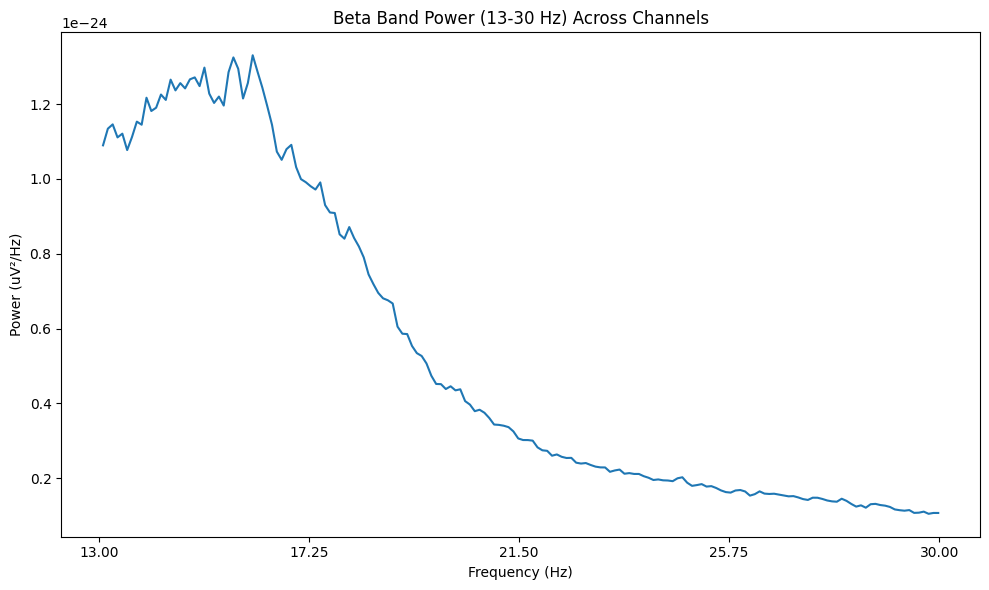

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d24 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d24.head())
print(d24.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d24_clean = d24.replace([np.inf, -np.inf], np.nan)
d24_clean = d24_clean.fillna(d24_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d24_scaled = pd.DataFrame(
    scaler.fit_transform(d24_clean),
    columns=d24_clean.columns,
    index=d24_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d24_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d24_scaled.index,
    columns=d24_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d24_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df24 = d24_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df24["Pd_indicator_meg"] = 0

print("\nShape of df5:", df24.shape)
print(df24.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324 = pd.concat([df1234567810111213141516171819212223, df24], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324 = df123456781011121314151617181921222324.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324):")
print(df123456781011121314151617181921222324)

# Print the shape
print("Shape of df123456781011121314151617181921222324:", df123456781011121314151617181921222324.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
1271    3.372311             0.074133          7.337450e-12  1.217225   
1272    3.261927             0.076642          4.589934e-13  1.206157   
1273    3.064546             0.081578          9.813792e-12  1.249346   
1274    3.668849             0.068141          7.379311e-12  1.113804   
1275    3.194574             0.078258          4.839318e-13  1.187671   

      duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp_c

In [ ]:
df123456781011121314151617181921222324.to_csv('/content/drive/MyDrive/combined_features_upto_sub024_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324 preserved.")


RAM Used After Cleanup: 1.07 GB
Memory cleaned. df123456781011121314151617181921222324 preserved.


sub-25

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-25'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-025_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-025_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-025_coordsystem.json', 'sub-025_task-go_run-1_proc-tsss+mc_events.json', 'sub-025_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-025_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-025_task-noise_proc-tsss_meg.fif', 'sub-025_task-go_run-1_proc-tsss+mc_meg.json', 'sub-025_task-noise_proc-tsss_channels.tsv', 'sub-025_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-025_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-025_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-025_task-noise_proc-tsss_meg.json', 'sub-025_task-passive_run-1_proc-tsss+mc_events.json', 'sub-025_task-rest_run-1_proc-tsss_channels.tsv', 'sub-025_task-rest_run-1_proc-tsss_events.json', 'sub-025_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-025_task-rest_run-1_proc-tsss_events.tsv', 'sub-025_task-rest_run-1_proc-tsss_meg.fif', 'sub-025_task-rest_run-1_proc-tsss_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-025_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-025_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-025_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-025_task-rest_run-1_proc-tsss_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-25/meg/sub-025_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-25/meg/sub-025_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 241000 ... 1314999 =    241.000 ...  1314.999 secs
Ready.
Reading 0 ... 1073999  =      0.000 ...  1073.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


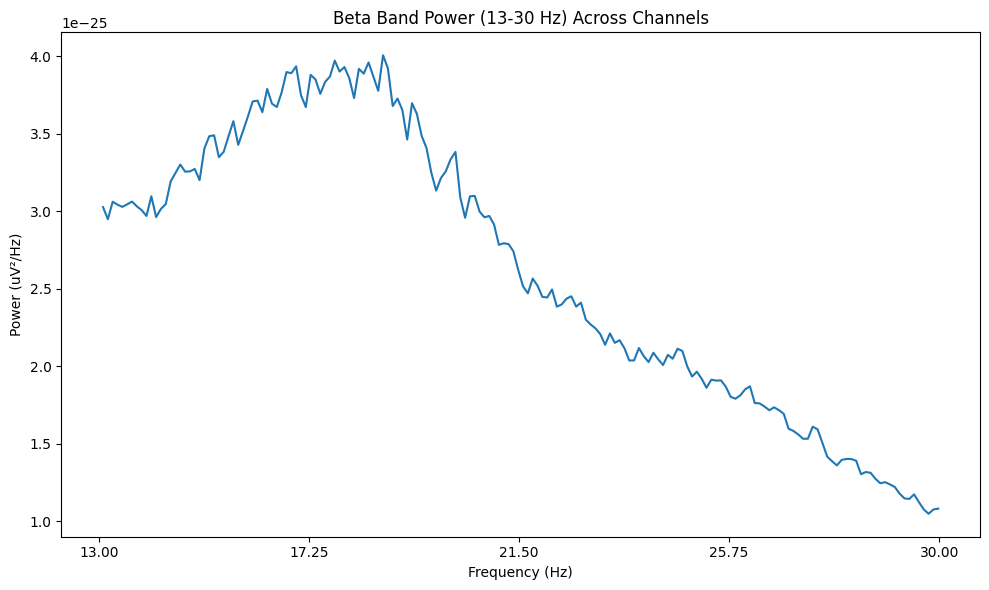

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Exraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d25 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d25.head())
print(d25.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 25 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d25_clean = d25.replace([np.inf, -np.inf], np.nan)
d25_clean = d25_clean.fillna(d25_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d25_scaled = pd.DataFrame(
    scaler.fit_transform(d25_clean),
    columns=d25_clean.columns,
    index=d25_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d25_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d25_scaled.index,
    columns=d25_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d25_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df25 = d25_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df25["Pd_indicator_meg"] = 0

print("\nShape of df5:", df25.shape)
print(df25.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425 = pd.concat([df123456781011121314151617181921222324, df25], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425 = df12345678101112131415161718192122232425.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425):")
print(df12345678101112131415161718192122232425)

# Print the shape
print("Shape of df12345678101112131415161718192122232425:", df12345678101112131415161718192122232425.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
1329    3.635940             0.068758          6.502661e-12  0.981941   
1330    3.684358             0.067854          3.580430e-13  0.989459   
1331    3.473929             0.071965          7.928650e-12  0.979883   
1332    3.538175             0.070658          7.040781e-12  1.049818   
1333    3.614525             0.069165          3.506778e-13  0.979210   

      duty_cycle  peak_beta_freq  burst_dur_cv  burst_amp

In [ ]:
df12345678101112131415161718192122232425.to_csv('/content/drive/MyDrive/combined_features_upto_sub025_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425 preserved.")


RAM Used After Cleanup: 1.07 GB
Memory cleaned. df12345678101112131415161718192122232425 preserved.


sub-26

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-26'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-026_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-026_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-026_coordsystem.json', 'sub-026_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-026_task-go_run-1_proc-tsss+mc_events.json', 'sub-026_task-go_run-1_proc-tsss+mc_meg.json', 'sub-026_task-noise_proc-tsss_channels.tsv', 'sub-026_task-noise_proc-tsss_meg.json', 'sub-026_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-026_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-026_task-passive_run-1_proc-tsss+mc_events.json', 'sub-026_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-026_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-026_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-026_task-rest_run-1_proc-tsss+mc_events.json', 'sub-026_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


No .fif files found for task 'passive'.


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-25/meg/sub-025_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 241000 ... 1314999 =    241.000 ...  1314.999 secs
Ready.
Reading 0 ... 1073999  =      0.000 ...  1073.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


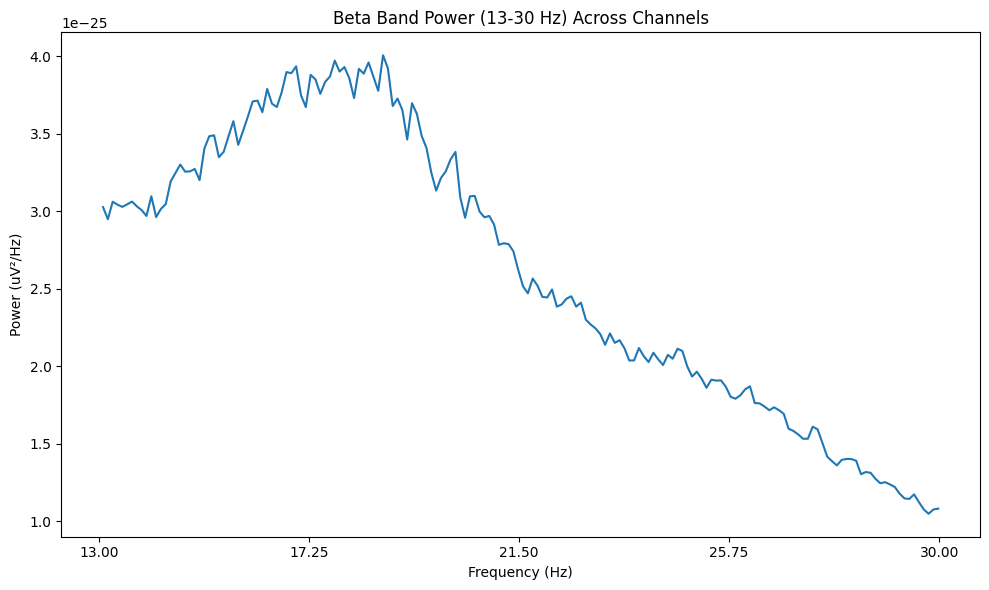

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d26 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d26.head())
print(d26.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d26_clean = d26.replace([np.inf, -np.inf], np.nan)
d26_clean = d26_clean.fillna(d26_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d26_scaled = pd.DataFrame(
    scaler.fit_transform(d26_clean),
    columns=d26_clean.columns,
    index=d26_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d26_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d26_scaled.index,
    columns=d26_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d26_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df26 = d26_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df26["Pd_indicator_meg"] = 0

print("\nShape of df5:", df26.shape)
print(df26.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526 = pd.concat([df12345678101112131415161718192122232425, df26], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526 = df1234567810111213141516171819212223242526.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526):")
print(df1234567810111213141516171819212223242526)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526:", df1234567810111213141516171819212223242526.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
1387    3.635940             0.068758          6.502661e-12  0.981941   
1388    3.684358             0.067854          3.580430e-13  0.989459   
1389    3.473929             0.071965          7.928650e-12  0.979883   
1390    3.538175             0.070658          7.040781e-12  1.049818   
1391    3.614525             0.069165          3.506778e-13  0.979210   

      duty_cycle  peak_beta_freq  burst_dur_cv  burst_a

In [ ]:
df1234567810111213141516171819212223242526.to_csv('/content/drive/MyDrive/combined_features_upto_sub026_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526 preserved.")


RAM Used After Cleanup: 1.08 GB
Memory cleaned. df1234567810111213141516171819212223242526 preserved.


sub-27

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-27'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-027_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-027_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-027_task-go_run-1_proc-tsss+mc_events.json', 'sub-027_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-027_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-027_coordsystem.json', 'sub-027_task-noise_proc-tsss_channels.tsv', 'sub-027_task-go_run-1_proc-tsss+mc_meg.json', 'sub-027_task-noise_proc-tsss_meg.fif', 'sub-027_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-027_task-passive_run-1_proc-tsss+mc_events.json', 'sub-027_task-noise_proc-tsss_meg.json', 'sub-027_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-027_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-027_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-027_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-027_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-027_task-rest_run-1_proc-tsss+mc_events.json', 'sub-027_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-027_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-027_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-027_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-027_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-027_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-27/meg/sub-027_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-27/meg/sub-027_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 80000 ... 1162999 =     80.000 ...  1162.999 secs
Ready.
Reading 0 ... 1082999  =      0.000 ...  1082.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


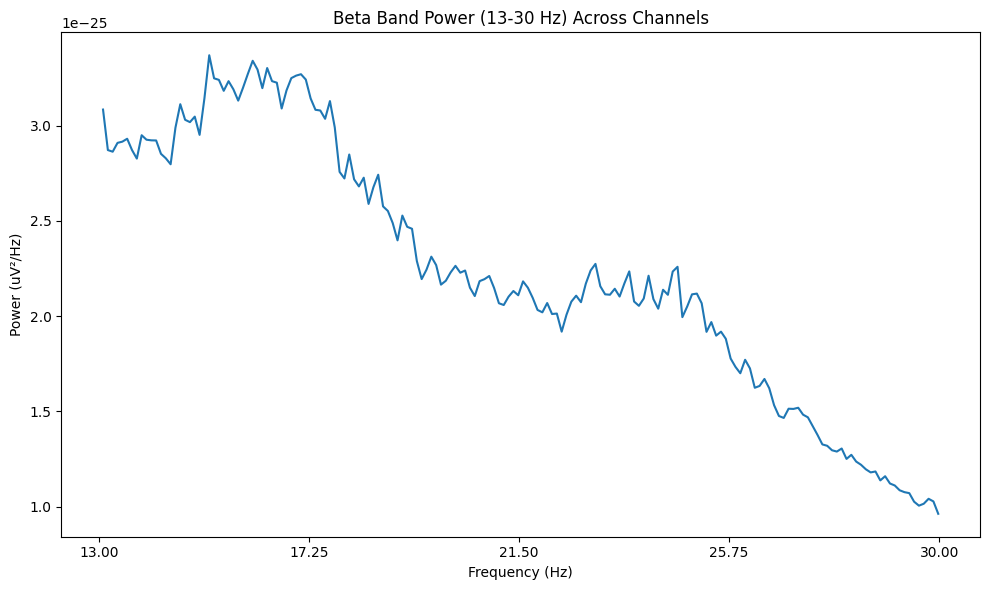

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d27 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d27.head())
print(d27.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d27_clean = d27.replace([np.inf, -np.inf], np.nan)
d27_clean = d27_clean.fillna(d27_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d27_scaled = pd.DataFrame(
    scaler.fit_transform(d27_clean),
    columns=d27_clean.columns,
    index=d27_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d27_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d27_scaled.index,
    columns=d27_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d27_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df27 = d27_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df27["Pd_indicator_meg"] = 0

print("\nShape of df5:", df27.shape)
print(df27.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627 = pd.concat([df1234567810111213141516171819212223242526, df27], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627 = df123456781011121314151617181921222324252627.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627):")
print(df123456781011121314151617181921222324252627)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627:", df123456781011121314151617181921222324252627.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
1445    4.147738             0.060274          6.270408e-12  0.891635   
1446    4.109880             0.060829          3.535211e-13  0.968759   
1447    4.128347             0.060557          6.800071e-12  0.906783   
1448    4.086796             0.061173          6.587151e-12  0.969300   
1449    3.999077             0.062514          3.613371e-13  0.953444   

      duty_cycle  peak_beta_freq  burst_dur_cv  burst

In [ ]:
df123456781011121314151617181921222324252627.to_csv('/content/drive/MyDrive/combined_features_upto_sub027_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627 preserved.")


RAM Used After Cleanup: 1.08 GB
Memory cleaned. df123456781011121314151617181921222324252627 preserved.


sub-28

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-28'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-028_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-028_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-028_task-go_run-1_proc-tsss+mc_events.json', 'sub-028_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-028_coordsystem.json', 'sub-028_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-028_task-go_run-1_proc-tsss+mc_meg.json', 'sub-028_task-noise_proc-tsss_channels.tsv', 'sub-028_task-noise_proc-tsss_meg.fif', 'sub-028_task-noise_proc-tsss_meg.json', 'sub-028_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-028_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-028_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-028_task-passive_run-1_proc-tsss+mc_events.json', 'sub-028_task-rest_run-1_proc-tsss+mc_events.json', 'sub-028_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-028_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-028_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-028_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-028_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-028_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-028_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-028_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-028_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-28/meg/sub-028_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-28/meg/sub-028_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 218000 ... 1298999 =    218.000 ...  1298.999 secs
Ready.
Reading 0 ... 1080999  =      0.000 ...  1080.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


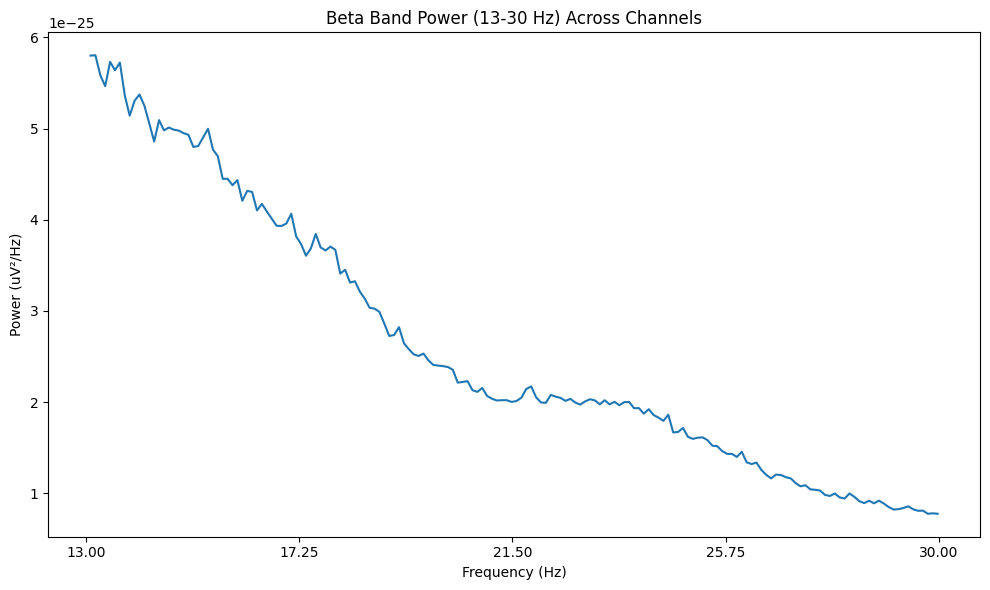

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d28 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d28.head())
print(d28.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d28_clean = d28.replace([np.inf, -np.inf], np.nan)
d28_clean = d28_clean.fillna(d28_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d28_scaled = pd.DataFrame(
    scaler.fit_transform(d28_clean),
    columns=d28_clean.columns,
    index=d28_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d28_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d28_scaled.index,
    columns=d28_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d28_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df28 = d28_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df28["Pd_indicator_meg"] = 0

print("\nShape of df5:", df28.shape)
print(df28.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728 = pd.concat([df123456781011121314151617181921222324252627, df28], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728 = df12345678101112131415161718192122232425262728.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728):")
print(df12345678101112131415161718192122232425262728)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728:", df12345678101112131415161718192122232425262728.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
1503    3.719704             0.067210          4.641078e-12  0.887570   
1504    3.498612             0.071457          2.400476e-13  0.923676   
1505    3.714154             0.067310          4.895502e-12  0.881640   
1506    3.580944             0.069814          4.391005e-12  0.967036   
1507    3.473636             0.071971          2.496047e-13  0.956816   

      duty_cycle  peak_beta_freq  burst_dur_cv  bur

In [ ]:
df12345678101112131415161718192122232425262728.to_csv('/content/drive/MyDrive/combined_features_upto_sub028_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728 preserved.")


RAM Used After Cleanup: 1.06 GB
Memory cleaned. df12345678101112131415161718192122232425262728 preserved.


sub-29

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-29'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-029_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-029_coordsystem.json', 'sub-029_task-go_run-1_proc-tsss+mc_events.json', 'sub-029_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-029_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-029_task-go_run-1_proc-tsss+mc_meg.json', 'sub-029_task-noise_proc-tsss_channels.tsv', 'sub-029_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-029_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-029_task-noise_proc-tsss_meg.json', 'sub-029_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-029_task-passive_run-1_proc-tsss+mc_events.json', 'sub-029_task-noise_proc-tsss_meg.fif', 'sub-029_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-029_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-029_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-029_task-rest_run-1_proc-tsss+mc_events.json', 'sub-029_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-029_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-029_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-029_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-029_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-029_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-029_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-29/meg/sub-029_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-29/meg/sub-029_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 202000 ... 1285999 =    202.000 ...  1285.999 secs
Ready.
Reading 0 ... 1083999  =      0.000 ...  1083.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


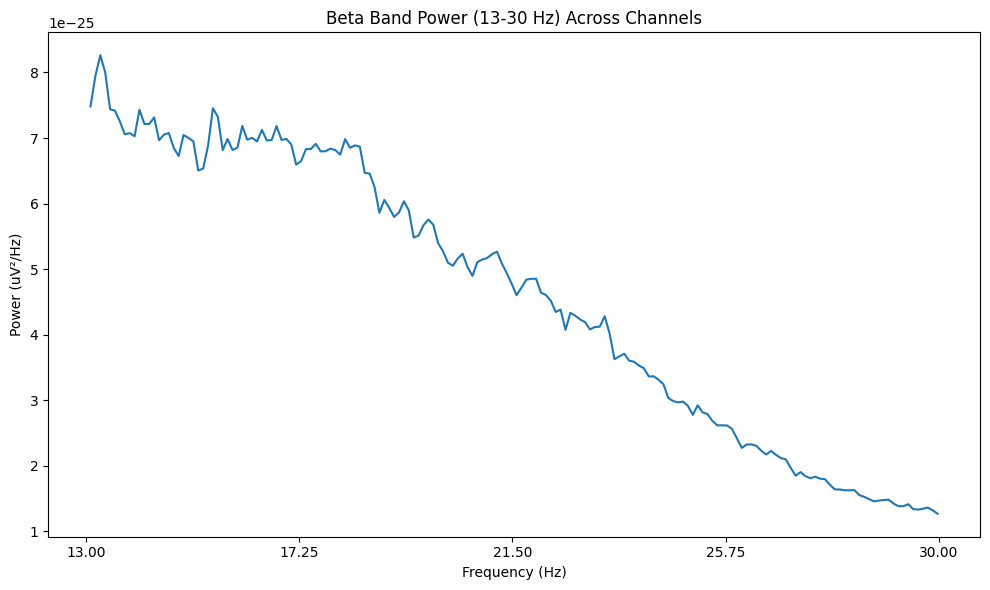

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Featre Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d29 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d29.head())
print(d29.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d29_clean = d29.replace([np.inf, -np.inf], np.nan)
d29_clean = d29_clean.fillna(d29_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d29_scaled = pd.DataFrame(
    scaler.fit_transform(d29_clean),
    columns=d29_clean.columns,
    index=d29_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d29_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d29_scaled.index,
    columns=d29_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d29_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df29 = d29_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df29["Pd_indicator_meg"] = 1

print("\nShape of df5:", df29.shape)
print(df29.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829 = pd.concat([df12345678101112131415161718192122232425262728, df29], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829 = df1234567810111213141516171819212223242526272829.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829):")
print(df1234567810111213141516171819212223242526272829)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829:", df1234567810111213141516171819212223242526272829.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
1561    3.694649             0.067665          5.306612e-12  0.833633   
1562    3.690959             0.067733          3.371251e-13  0.831915   
1563    3.713100             0.067329          5.511103e-12  0.828654   
1564    3.882841             0.064386          4.990320e-12  0.822808   
1565    3.736162             0.066914          3.400794e-13  0.850405   

      duty_cycle  peak_beta_freq  burst_dur_cv  b

In [ ]:
df1234567810111213141516171819212223242526272829.to_csv('/content/drive/MyDrive/combined_features_upto_sub029_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829 preserved.")


RAM Used After Cleanup: 1.07 GB
Memory cleaned. df1234567810111213141516171819212223242526272829 preserved.


sub-30

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-30'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-030_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-030_coordsystem.json', 'sub-030_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-030_task-go_run-1_proc-tsss+mc_events.json', 'sub-030_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-030_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-030_task-go_run-1_proc-tsss+mc_meg.json', 'sub-030_task-noise_proc-tsss_channels.tsv', 'sub-030_task-noise_proc-tsss_meg.fif', 'sub-030_task-noise_proc-tsss_meg.json', 'sub-030_task-passive_run-1_proc-tsss+mc_events.json', 'sub-030_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-030_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-030_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-030_task-rest_run-1_proc-tsss+mc_events.json', 'sub-030_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-030_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-030_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-030_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-030_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-030_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-030_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-030_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-030_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-30/meg/sub-030_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-30/meg/sub-030_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 284000 ... 1363999 =    284.000 ...  1363.999 secs
Ready.
Reading 0 ... 1079999  =      0.000 ...  1079.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


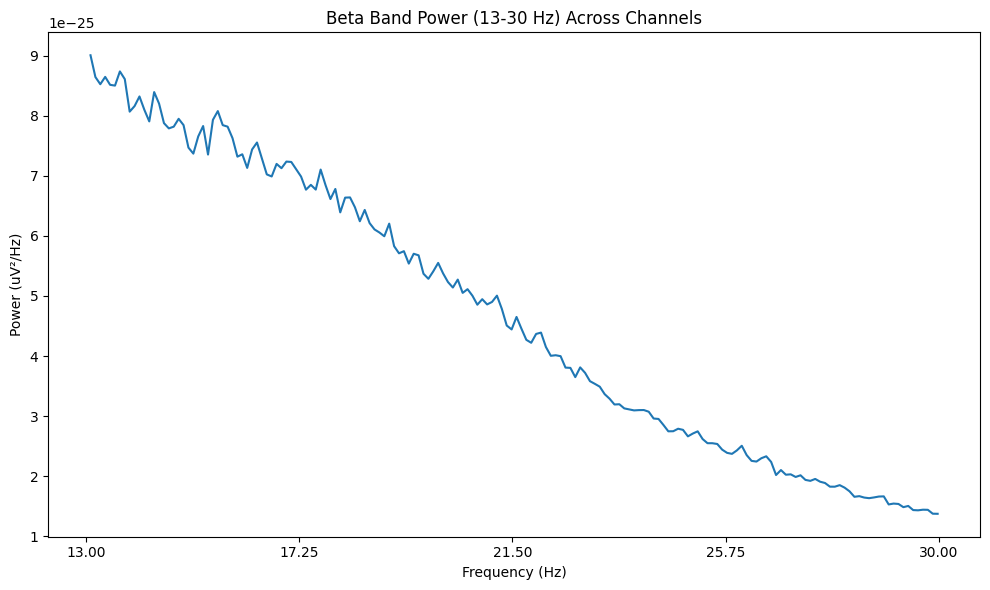

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d30 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d30.head())
print(d30.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d30_clean = d30.replace([np.inf, -np.inf], np.nan)
d30_clean = d30_clean.fillna(d30_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d30_scaled = pd.DataFrame(
    scaler.fit_transform(d30_clean),
    columns=d30_clean.columns,
    index=d30_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d30_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d30_scaled.index,
    columns=d30_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d30_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df30 = d30_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df30["Pd_indicator_meg"] = 0

print("\nShape of df5:", df30.shape)
print(df30.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930 = pd.concat([df1234567810111213141516171819212223242526272829, df30], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930 = df123456781011121314151617181921222324252627282930.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930):")
print(df123456781011121314151617181921222324252627282930)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930:", df123456781011121314151617181921222324252627282930.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
1619    3.830556             0.065265          6.701154e-12  0.889213   
1620    3.724074             0.067131          3.995924e-13  0.917870   
1621    3.844444             0.065029          7.445850e-12  0.879106   
1622    3.653704             0.068424          7.260723e-12  0.946746   
1623    3.617593             0.069107          4.237907e-13  0.937557   

      duty_cycle  peak_beta_freq  burst_dur_cv 

In [ ]:
df123456781011121314151617181921222324252627282930.to_csv('/content/drive/MyDrive/combined_features_upto_sub030_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930 preserved.")


RAM Used After Cleanup: 1.09 GB
Memory cleaned. df123456781011121314151617181921222324252627282930 preserved.


sub-31

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-31'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-031_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-031_coordsystem.json', 'sub-031_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-031_task-go_run-1_proc-tsss+mc_events.json', 'sub-031_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-031_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-031_task-go_run-1_proc-tsss+mc_meg.json', 'sub-031_task-noise_proc-tsss_meg.fif', 'sub-031_task-noise_proc-tsss_channels.tsv', 'sub-031_task-noise_proc-tsss_meg.json', 'sub-031_task-passive_run-1_proc-tsss+mc_events.json', 'sub-031_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-031_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-031_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-031_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-031_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-031_task-rest_run-1_proc-tsss+mc_events.json', 'sub-031_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-031_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-031_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-031_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-031_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-031_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-031_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-31/meg/sub-031_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-31/meg/sub-031_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 105000 ... 1180999 =    105.000 ...  1180.999 secs
Ready.
Reading 0 ... 1075999  =      0.000 ...  1075.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting

Computing Power Spectral Density

Effective window size : 10.240 (s)


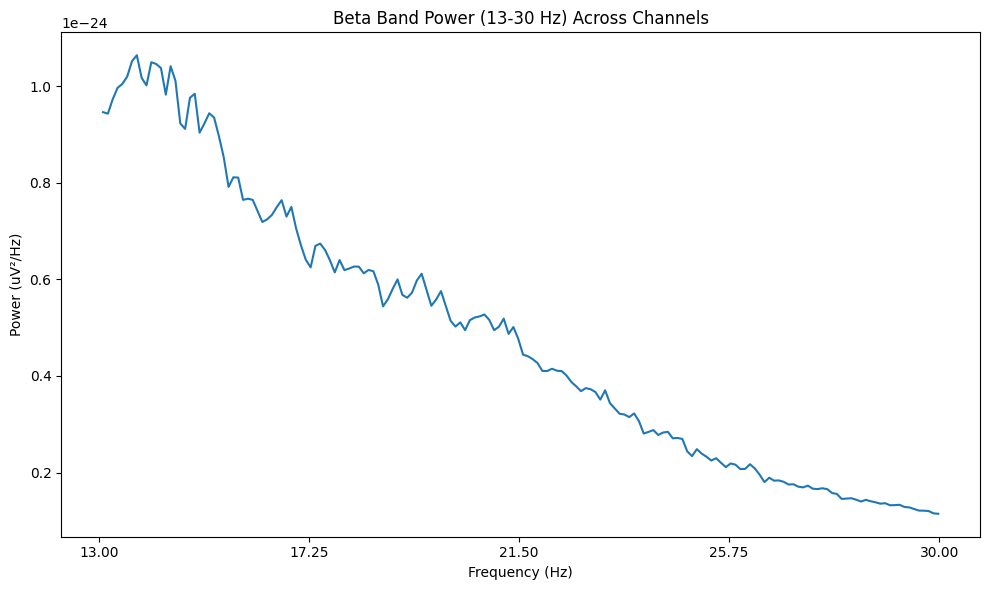

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d31 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d31.head())
print(d31.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d31_clean = d31.replace([np.inf, -np.inf], np.nan)
d31_clean = d31_clean.fillna(d31_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d31_scaled = pd.DataFrame(
    scaler.fit_transform(d31_clean),
    columns=d31_clean.columns,
    index=d31_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d31_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d31_scaled.index,
    columns=d31_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d31_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df31 = d31_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df31["Pd_indicator_meg"] = 1

print("\nShape of df5:", df31.shape)
print(df31.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031 = pd.concat([df123456781011121314151617181921222324252627282930, df31], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031 = df12345678101112131415161718192122232425262728293031.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031):")
print(df12345678101112131415161718192122232425262728293031)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031:", df12345678101112131415161718192122232425262728293031.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
1677    4.042751             0.061839          1.163700e-11  0.788234   
1678    4.001859             0.062471          5.531700e-13  0.754205   
1679    4.017658             0.062225          1.230039e-11  0.803897   
1680    4.037175             0.061924          1.036299e-11  0.740274   
1681    3.940520             0.063443          5.678473e-13  0.731173   

      duty_cycle  peak_beta_freq  burst_dur_c

In [ ]:
df12345678101112131415161718192122232425262728293031.to_csv('/content/drive/MyDrive/combined_features_upto_sub031_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031 preserved.")


RAM Used After Cleanup: 1.09 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031 preserved.


sub-32

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-32'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-032_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-032_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-032_task-go_run-1_proc-tsss+mc_events.json', 'sub-032_coordsystem.json', 'sub-032_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-032_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-032_task-noise_proc-tsss_meg.fif', 'sub-032_task-noise_proc-tsss_channels.tsv', 'sub-032_task-go_run-1_proc-tsss+mc_meg.json', 'sub-032_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-032_task-passive_run-1_proc-tsss+mc_events.json', 'sub-032_task-noise_proc-tsss_meg.json', 'sub-032_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-032_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-032_task-rest_run-1_proc-tsss+mc_events.json', 'sub-032_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-032_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-032_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-032_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-032_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-032_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-032_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-032_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-032_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-32/meg/sub-032_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-32/meg/sub-032_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 28000 ... 1100999 =     28.000 ...  1100.999 secs
Ready.
Reading 0 ... 1072999  =      0.000 ...  1072.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


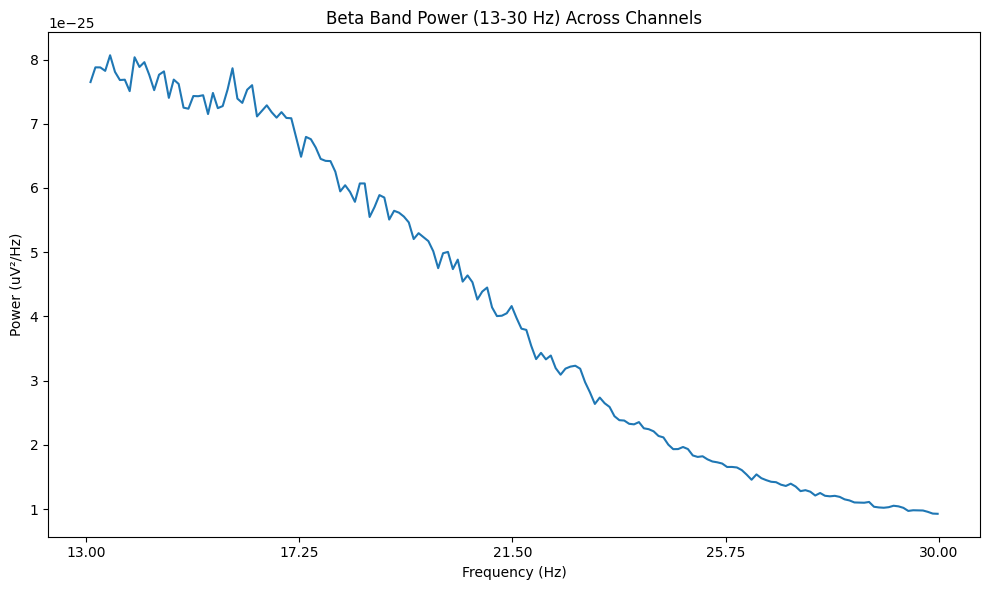

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d32 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d32.head())
print(d32.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d32_clean = d32.replace([np.inf, -np.inf], np.nan)
d32_clean = d32_clean.fillna(d32_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d32_scaled = pd.DataFrame(
    scaler.fit_transform(d32_clean),
    columns=d32_clean.columns,
    index=d32_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d32_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d32_scaled.index,
    columns=d32_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d32_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df32 = d32_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df32["Pd_indicator_meg"] = 0

print("\nShape of df5:", df32.shape)
print(df32.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132 = pd.concat([df12345678101112131415161718192122232425262728293031, df32], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132 = df1234567810111213141516171819212223242526272829303132.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132):")
print(df1234567810111213141516171819212223242526272829303132)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132:", df1234567810111213141516171819212223242526272829303132.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
1735    3.682199             0.067850          8.031761e-12  0.794166   
1736    3.675676             0.068015          4.524798e-13  0.791991   
1737    3.826654             0.065331          8.266162e-12  0.783962   
1738    3.777260             0.066186          7.818623e-12  0.777465   
1739    3.567568             0.070076          5.093391e-13  0.796984   

      duty_cycle  peak_beta_freq  burst_dur

In [ ]:
df1234567810111213141516171819212223242526272829303132.to_csv('/content/drive/MyDrive/combined_features_upto_sub032_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132 preserved.")


RAM Used After Cleanup: 1.09 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132 preserved.


sub-33

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-33'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-033_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-033_coordsystem.json', 'sub-033_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-033_task-go_run-1_proc-tsss+mc_events.json', 'sub-033_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-033_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-033_task-go_run-1_proc-tsss+mc_meg.json', 'sub-033_task-noise_proc-tsss_channels.tsv', 'sub-033_task-noise_proc-tsss_meg.fif', 'sub-033_task-passive_run-1_proc-tsss+mc_events.json', 'sub-033_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-033_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-033_task-noise_proc-tsss_meg.json', 'sub-033_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-033_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-033_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-033_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-033_task-rest_run-1_proc-tsss+mc_events.json', 'sub-033_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-033_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-033_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-033_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-033_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-033_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-33/meg/sub-033_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-33/meg/sub-033_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 81000 ... 1152999 =     81.000 ...  1152.999 secs
Ready.
Reading 0 ... 1071999  =      0.000 ...  1071.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


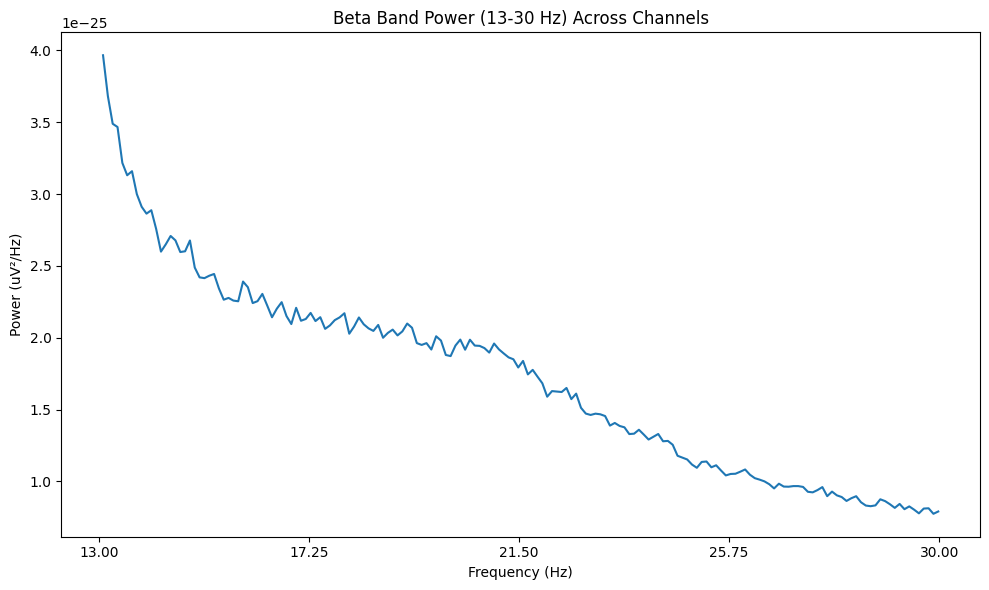

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d33 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d33.head())
print(d33.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d33_clean = d33.replace([np.inf, -np.inf], np.nan)
d33_clean = d33_clean.fillna(d33_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d33_scaled = pd.DataFrame(
    scaler.fit_transform(d33_clean),
    columns=d33_clean.columns,
    index=d33_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d33_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d33_scaled.index,
    columns=d33_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d33_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df33 = d33_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df33["Pd_indicator_meg"] = 1

print("\nShape of df5:", df33.shape)
print(df33.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233 = pd.concat([df1234567810111213141516171819212223242526272829303132, df33], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233 = df123456781011121314151617181921222324252627282930313233.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233):")
print(df123456781011121314151617181921222324252627282930313233)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233:", df123456781011121314151617181921222324252627282930313233.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
1793    4.277052             0.058451          4.371808e-12  0.818635   
1794    4.179104             0.059821          2.263734e-13  0.853604   
1795    4.206157             0.059437          4.699367e-12  0.837720   
1796    4.122201             0.060647          4.230616e-12  0.852807   
1797    4.231343             0.059083          2.183385e-13  0.850460   

      duty_cycle  peak_beta_freq  burst_d

In [ ]:
df123456781011121314151617181921222324252627282930313233.to_csv('/content/drive/MyDrive/combined_features_upto_sub033_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233 preserved.")


RAM Used After Cleanup: 1.06 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233 preserved.


sub-35

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-35'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-035_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-035_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-035_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-035_coordsystem.json', 'sub-035_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-035_task-go_run-1_proc-tsss+mc_events.json', 'sub-035_task-noise_proc-tsss_meg.fif', 'sub-035_task-noise_proc-tsss_channels.tsv', 'sub-035_task-go_run-1_proc-tsss+mc_meg.json', 'sub-035_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-035_task-noise_proc-tsss_meg.json', 'sub-035_task-passive_run-1_proc-tsss+mc_events.json', 'sub-035_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-035_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-035_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-035_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-035_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-035_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-035_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-035_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-035_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-035_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-35/meg/sub-035_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-35/meg/sub-035_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 94000 ... 1170999 =     94.000 ...  1170.999 secs
Ready.
Reading 0 ... 1076999  =      0.000 ...  1076.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


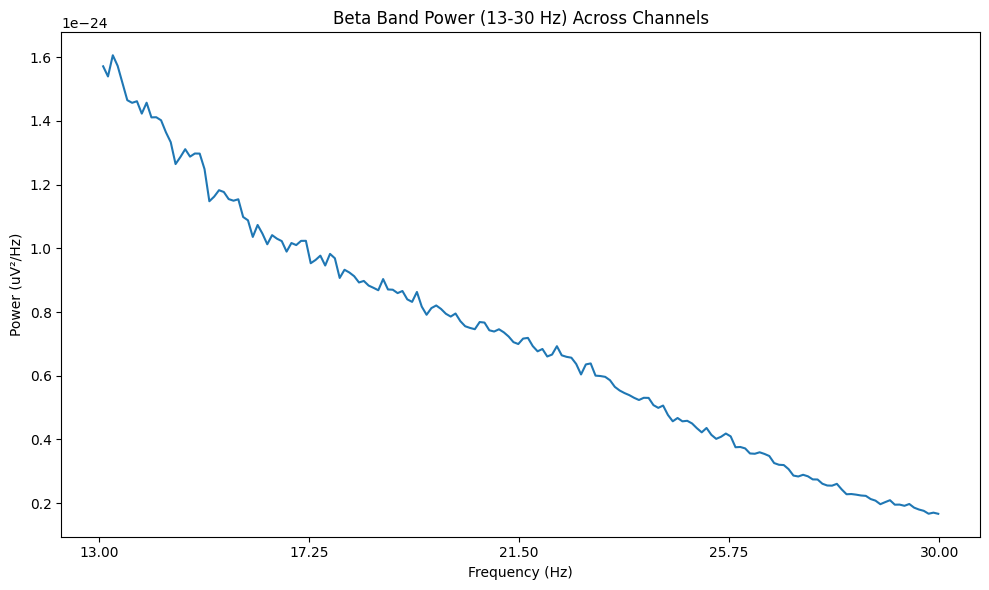

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d35 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d35.head())
print(d35.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d35_clean = d35.replace([np.inf, -np.inf], np.nan)
d35_clean = d35_clean.fillna(d35_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d35_scaled = pd.DataFrame(
    scaler.fit_transform(d35_clean),
    columns=d35_clean.columns,
    index=d35_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d35_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d35_scaled.index,
    columns=d35_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d35_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df35 = d35_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df35["Pd_indicator_meg"] = 1

print("\nShape of df5:", df35.shape)
print(df35.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG0112', 'MEG0113', 'MEG0121', 'MEG0122', 'MEG0123', 'MEG0131', 'MEG0132', 'MEG0133', 'MEG0141', 'MEG0142', 'MEG0143', 'MEG0211', 'MEG0212', 'MEG0213', 'MEG0221', 'MEG0222', 'MEG2333', 'MEG2341', 'MEG2342', 'MEG2343', 'MEG2411', 'MEG2412', 'MEG2413', 'MEG2421', 'MEG2311', 'MEG2312', 'MEG2313', 'MEG2321', 'MEG2322', 'MEG2323', 'MEG2331', 'MEG2332', 'MEG2222', 'MEG2223', 'MEG2231', 'MEG2232', 'MEG2233', 'MEG2241', 'MEG2242', 'MEG2243', 'MEG2133', 'MEG2141', 'MEG2142', 'MEG2143', 'MEG2211', 'MEG2212', 'MEG2213', 'MEG2221', 'MEG0713', 'MEG0721', 'MEG0722', 'MEG0723', 'MEG0731', 'MEG0732', 'MEG0733', 'MEG0741']

Top 58 channel numbers:
[305, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 266, 267, 268, 269, 270, 271, 272, 273, 258, 259, 260, 261, 262, 263, 264, 265, 250, 251, 252, 253, 254, 255, 256, 257, 242, 243, 244, 245, 246, 247, 248, 249, 74, 75, 76, 77, 78, 79, 80, 81]

Shape of df5: (58, 22)
         burst_rate  mean_burst_du

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335 = pd.concat([df123456781011121314151617181921222324252627282930313233, df35], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335 = df12345678101112131415161718192122232425262728293031323335.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335):")
print(df12345678101112131415161718192122232425262728293031323335)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335:", df12345678101112131415161718192122232425262728293031323335.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
1851    3.740019             0.066845          1.183688e-11  1.028539   
1852    3.948004             0.063323          5.386859e-13  0.917872   
1853    3.741876             0.066811          1.076117e-11  1.064949   
1854    3.839369             0.065115          9.468612e-12  0.937670   
1855    3.893222             0.064214          5.643085e-13  0.874273   

      duty_cycle  peak_beta_freq  burst

In [ ]:
df12345678101112131415161718192122232425262728293031323335.to_csv('/content/drive/MyDrive/combined_features_upto_sub035_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335 preserved.")


RAM Used After Cleanup: 1.07 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335 preserved.


sub-36

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import pandas as pd

previous_df = pd.read_csv('/content/drive/MyDrive/combined_features_upto_sub035_21.csv')

print("Loaded previous shape:", previous_df.shape)


Loaded previous shape: (1856, 22)


In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-36'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-036_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-036_coordsystem.json', 'sub-036_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-036_task-go_run-1_proc-tsss+mc_events.json', 'sub-036_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-036_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-036_task-noise_proc-tsss_channels.tsv', 'sub-036_task-go_run-1_proc-tsss+mc_meg.json', 'sub-036_task-noise_proc-tsss_meg.fif', 'sub-036_task-noise_proc-tsss_meg.json', 'sub-036_task-passive_run-1_proc-tsss+mc_events.json', 'sub-036_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-036_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-036_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-036_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-036_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-036_task-rest_run-1_proc-tsss+mc_events.json', 'sub-036_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-036_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-036_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-036_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-036_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-036_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-036_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 54.7 MB/s eta 0:00:00

Found .fif file: /content/drive/MyDrive/sub-36/meg/sub-036_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-36/meg/sub-036_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 177000 ... 1244999 =    177.000 ...  1244.999 secs
Ready.
Reading 0 ... 1067999  =      0.000 ...  1067.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting

Computing Power Spectral Density

Effective window size : 10.240 (s)


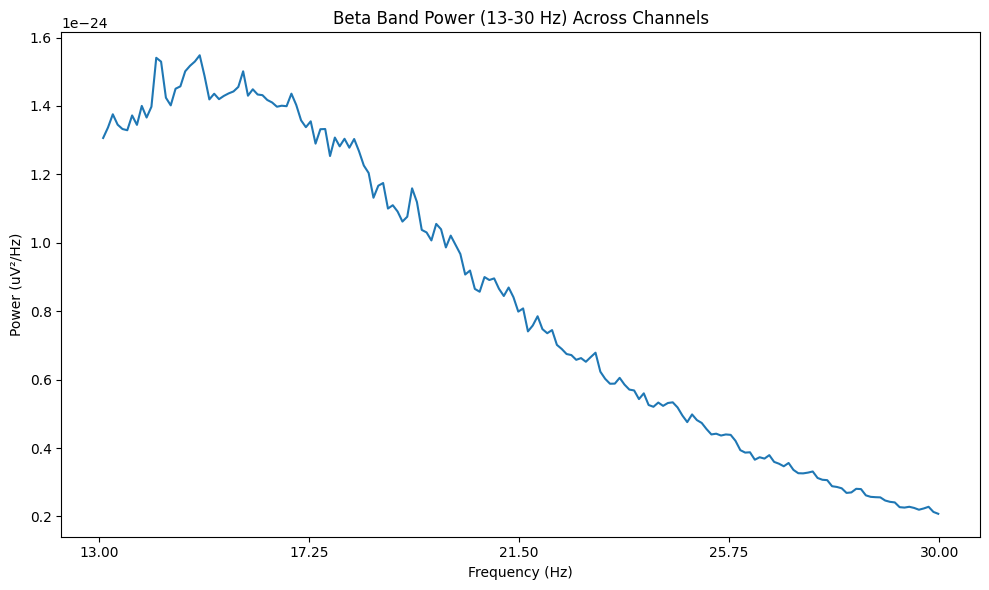

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d36 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d36.head())
print(d36.shape)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.2/115.2 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.5/130.5 kB 5.4 MB/s eta 0:00:00
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.12

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d36_clean = d36.replace([np.inf, -np.inf], np.nan)
d36_clean = d36_clean.fillna(d36_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d36_scaled = pd.DataFrame(
    scaler.fit_transform(d36_clean),
    columns=d36_clean.columns,
    index=d36_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d36_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d36_scaled.index,
    columns=d36_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d36_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df36 = d36_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df36["Pd_indicator_meg"] = 0

print("\nShape of df5:", df36.shape)
print(df36.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536 = pd.concat([previous_df, df36], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536 = df1234567810111213141516171819212223242526272829303132333536.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536):")
print(df1234567810111213141516171819212223242526272829303132333536)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536:", df1234567810111213141516171819212223242526272829303132333536.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
1909    3.568352             0.070060          5.701413e-12  0.887414   
1910    3.563670             0.070152          4.899294e-12  0.917100   
1911    3.471910             0.072006          2.931875e-13  0.921735   
1912    3.566479             0.070097          5.994513e-12  0.932683   
1913    3.405431             0.073412          6.128922e-12  0.911260   

      duty_cycle  peak_beta_freq  bur

In [ ]:
df1234567810111213141516171819212223242526272829303132333536.to_csv('/content/drive/MyDrive/combined_features_upto_sub036_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536 preserved.")


RAM Used After Cleanup: 0.96 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536 preserved.


sub-37

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-37'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-037_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-037_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-037_task-go_run-1_proc-tsss+mc_events.json', 'sub-037_coordsystem.json', 'sub-037_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-037_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-037_task-go_run-1_proc-tsss+mc_meg.json', 'sub-037_task-noise_proc-tsss_channels.tsv', 'sub-037_task-noise_proc-tsss_meg.fif', 'sub-037_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-037_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-037_task-passive_run-1_proc-tsss+mc_events.json', 'sub-037_task-noise_proc-tsss_meg.json', 'sub-037_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-037_task-rest_run-1_proc-tsss+mc_events.json', 'sub-037_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-037_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-037_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-037_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-037_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-037_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-037_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-037_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-037_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-37/meg/sub-037_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-37/meg/sub-037_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 78000 ... 1163999 =     78.000 ...  1163.999 secs
Ready.
Reading 0 ... 1085999  =      0.000 ...  1085.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


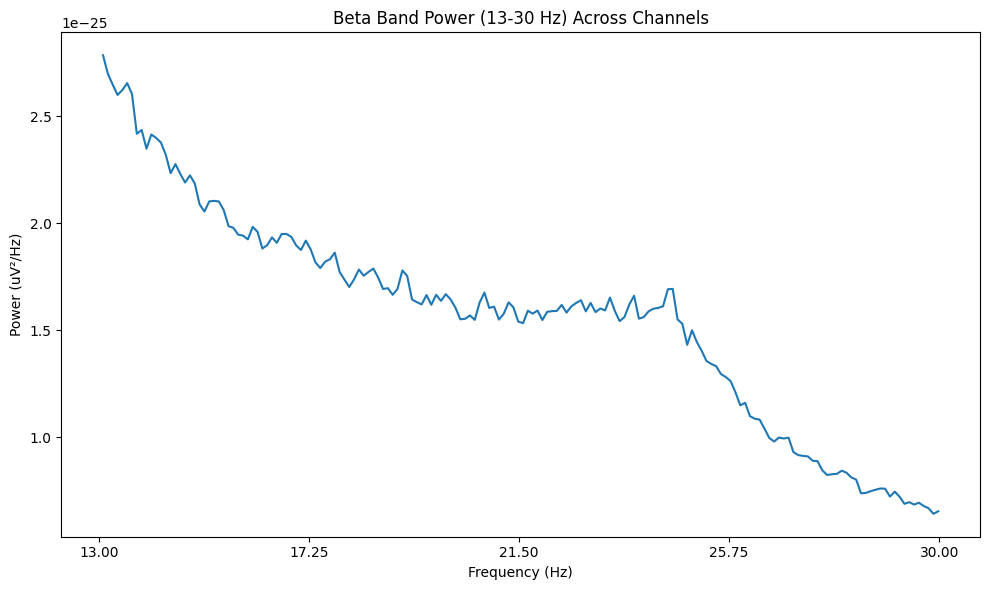

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d37 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d37.head())
print(d37.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d37_clean = d37.replace([np.inf, -np.inf], np.nan)
d37_clean = d37_clean.fillna(d37_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d37_scaled = pd.DataFrame(
    scaler.fit_transform(d37_clean),
    columns=d37_clean.columns,
    index=d37_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d37_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d37_scaled.index,
    columns=d37_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d37_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df37 = d37_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df37["Pd_indicator_meg"] = 1

print("\nShape of df5:", df37.shape)
print(df37.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637 = pd.concat([df1234567810111213141516171819212223242526272829303132333536, df37], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637 = df123456781011121314151617181921222324252627282930313233353637.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637):")
print(df123456781011121314151617181921222324252627282930313233353637)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637:", df123456781011121314151617181921222324252627282930313233353637.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
1967    4.351750             0.057448          2.253305e-12  0.731036   
1968    4.069061             0.061439          2.574214e-12  0.812956   
1969    4.342541             0.057570          1.430416e-13  0.788082   
1970    4.092081             0.061094          2.774886e-12  0.814848   
1971    4.348066             0.057497          2.277089e-12  0.745372   

      duty_cycle  peak_beta_freq  b

In [ ]:
df123456781011121314151617181921222324252627282930313233353637.to_csv('/content/drive/MyDrive/combined_features_upto_sub037_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637 preserved.")


RAM Used After Cleanup: 0.96 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637 preserved.


sub-38

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-38'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-038_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-038_coordsystem.json', 'sub-038_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-038_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-038_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-038_task-go_run-1_proc-tsss+mc_events.json', 'sub-038_task-go_run-1_proc-tsss+mc_meg.json', 'sub-038_task-noise_proc-tsss_meg.fif', 'sub-038_task-noise_proc-tsss_channels.tsv', 'sub-038_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-038_task-noise_proc-tsss_meg.json', 'sub-038_task-passive_run-1_proc-tsss+mc_events.json', 'sub-038_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-038_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-038_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-038_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-038_task-rest_run-1_proc-tsss+mc_events.json', 'sub-038_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-038_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-038_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-038_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-038_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-038_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-038_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-38/meg/sub-038_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-38/meg/sub-038_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 50000 ... 1125999 =     50.000 ...  1125.999 secs
Ready.
Reading 0 ... 1075999  =      0.000 ...  1075.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


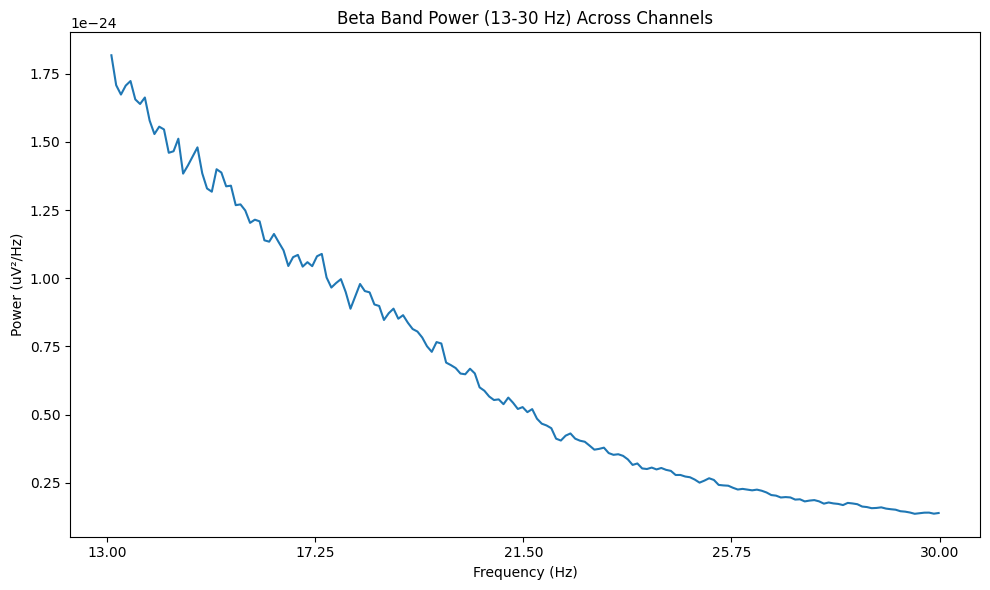

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d38 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d38.head())
print(d38.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d38_clean = d38.replace([np.inf, -np.inf], np.nan)
d38_clean = d38_clean.fillna(d38_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d38_scaled = pd.DataFrame(
    scaler.fit_transform(d38_clean),
    columns=d38_clean.columns,
    index=d38_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d38_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d38_scaled.index,
    columns=d38_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d38_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df38 = d38_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df38["Pd_indicator_meg"] = 0

print("\nShape of df5:", df38.shape)
print(df38.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738 = pd.concat([df123456781011121314151617181921222324252627282930313233353637, df38], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738 = df12345678101112131415161718192122232425262728293031323335363738.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738):")
print(df12345678101112131415161718192122232425262728293031323335363738)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738:", df12345678101112131415161718192122232425262728293031323335363738.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
2025    3.807621             0.065658          4.093211e-12  0.914296   
2026    3.789963             0.065964          4.560959e-12  0.977102   
2027    3.717472             0.067250          2.630856e-13  0.976526   
2028    3.713755             0.067317          5.473618e-12  0.951468   
2029    3.885688             0.064339          4.368012e-12  0.865011   

      duty_cycle  peak_beta_freq 

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738.to_csv('/content/drive/MyDrive/combined_features_upto_sub038_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738 preserved.")


RAM Used After Cleanup: 0.97 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738 preserved.


sub-39

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-39'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-039_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-039_coordsystem.json', 'sub-039_task-go_run-1_proc-tsss+mc_events.json', 'sub-039_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-039_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-039_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-039_task-go_run-1_proc-tsss+mc_meg.json', 'sub-039_task-noise_proc-tsss_channels.tsv', 'sub-039_task-noise_proc-tsss_meg.fif', 'sub-039_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-039_task-noise_proc-tsss_meg.json', 'sub-039_task-passive_run-1_proc-tsss+mc_events.json', 'sub-039_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-039_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-039_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-039_task-rest_run-1_proc-tsss+mc_events.json', 'sub-039_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-039_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-039_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-039_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-039_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-039_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-039_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-039_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-39/meg/sub-039_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-39/meg/sub-039_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 71000 ... 1147999 =     71.000 ...  1147.999 secs
Ready.
Reading 0 ... 1076999  =      0.000 ...  1076.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


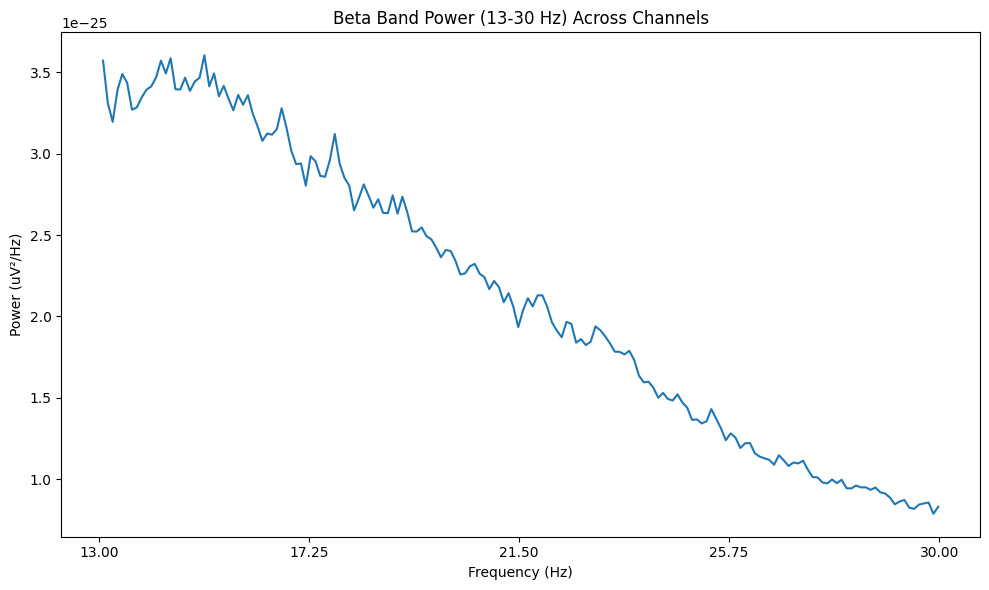

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d39 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d39.head())
print(d39.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d39_clean = d39.replace([np.inf, -np.inf], np.nan)
d39_clean = d39_clean.fillna(d39_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d39_scaled = pd.DataFrame(
    scaler.fit_transform(d39_clean),
    columns=d39_clean.columns,
    index=d39_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d39_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d39_scaled.index,
    columns=d39_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d39_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df39 = d39_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df39["Pd_indicator_meg"] = 0

print("\nShape of df5:", df39.shape)
print(df39.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738, df39], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839 = df1234567810111213141516171819212223242526272829303132333536373839.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839):")
print(df1234567810111213141516171819212223242526272829303132333536373839)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839:", df1234567810111213141516171819212223242526272829303132333536373839.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
2083    3.980501             0.062806          3.045022e-12  0.850526   
2084    4.175487             0.059873          2.690129e-12  0.836204   
2085    4.173630             0.059900          1.449661e-13  0.807062   
2086    4.036212             0.061939          3.078310e-12  0.818112   
2087    4.110492             0.060820          2.879790e-12  0.800555   

      duty_cycle  peak_beta_fre

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839.to_csv('/content/drive/MyDrive/combined_features_upto_sub039_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839 preserved.")


RAM Used After Cleanup: 0.98 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839 preserved.


sub-40

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-40'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-040_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-040_coordsystem.json', 'sub-040_task-go_run-1_proc-tsss+mc_events.json', 'sub-040_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-040_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-040_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-040_task-go_run-1_proc-tsss+mc_meg.json', 'sub-040_task-noise_proc-tsss_meg.fif', 'sub-040_task-noise_proc-tsss_channels.tsv', 'sub-040_task-passive_run-1_proc-tsss+mc_events.json', 'sub-040_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-040_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-040_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-040_task-noise_proc-tsss_meg.json', 'sub-040_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-040_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-040_task-rest_run-1_proc-tsss+mc_events.json', 'sub-040_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-040_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-040_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-040_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-040_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-040_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-040_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-40/meg/sub-040_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-40/meg/sub-040_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 10000 ... 1228999 =     10.000 ...  1228.999 secs
Ready.
Reading 0 ... 1218999  =      0.000 ...  1218.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 2 contiguous segments
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting

Computing Power Spectral Density

Setting 24000 of 243800 (9.84%) samples to NaN, retaining 219800 (90.16%) samples.
Effective window size : 10.240 (s)
At least one good data span is shorter than n_per_seg, and will be analyzed with a shorter window than the rest of the file.


/usr/local/lib/python3.12/dist-packages/mne/time_frequency/psd.py:291: UserWarning: nperseg = 2048 is greater than input length  = 2000, using nperseg = 2000
  return _func(*args, **kwargs)


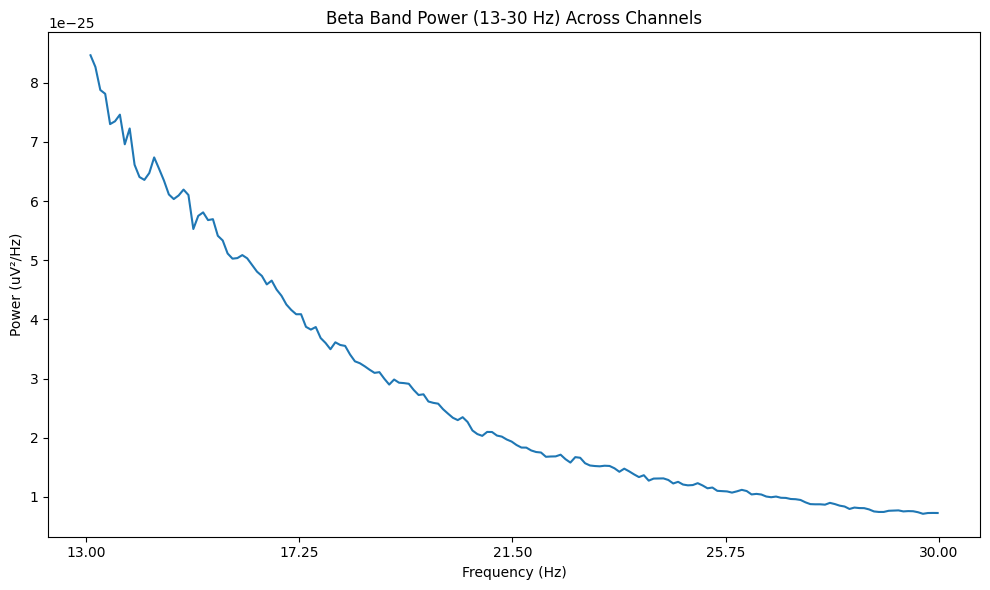

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d40 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d40.head())
print(d40.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d40_clean = d40.replace([np.inf, -np.inf], np.nan)
d40_clean = d40_clean.fillna(d40_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d40_scaled = pd.DataFrame(
    scaler.fit_transform(d40_clean),
    columns=d40_clean.columns,
    index=d40_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d40_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d40_scaled.index,
    columns=d40_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d40_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df40 = d40_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df40["Pd_indicator_meg"] = 1

print("\nShape of df5:", df40.shape)
print(df40.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839, df40], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940 = df123456781011121314151617181921222324252627282930313233353637383940.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940):")
print(df123456781011121314151617181921222324252627282930313233353637383940)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940:", df123456781011121314151617181921222324252627282930313233353637383940.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
2141    3.981952             0.062783          2.806844e-12  6.917924   
2142    3.931911             0.063552          2.779428e-12  6.957737   
2143    3.835111             0.065187          1.723461e-13  6.785345   
2144    3.915505             0.063832          3.437704e-12  6.865604   
2145    3.831829             0.065243          3.365967e-12  6.816818   

      duty_cycle  peak_beta_f

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940.to_csv('/content/drive/MyDrive/combined_features_upto_sub040_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940 preserved.")


RAM Used After Cleanup: 1.05 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940 preserved.


sub-41

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-41'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-041_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-041_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-041_coordsystem.json', 'sub-041_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-041_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-041_task-go_run-1_proc-tsss+mc_events.json', 'sub-041_task-noise_proc-tsss_meg.fif', 'sub-041_task-go_run-1_proc-tsss+mc_meg.json', 'sub-041_task-noise_proc-tsss_channels.tsv', 'sub-041_task-noise_proc-tsss_meg.json', 'sub-041_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-041_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-041_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-041_task-passive_run-1_proc-tsss+mc_events.json', 'sub-041_task-rest_run-1_proc-tsss+mc_events.json', 'sub-041_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-041_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-041_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-041_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-041_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-041_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-041_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-041_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-041_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-41/meg/sub-041_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import os
import mne
import numpy as np
from mne.preprocessing import ICA
import gc

task_name = "passive"

if task_name in fif_files_by_task:

    print(f"\n========== Processing Task: {task_name.upper()} ==========")

    for fif_file in fif_files_by_task[task_name]:

        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"Loading file: {fif_file_path}")

        # Load raw
        raw = mne.io.read_raw_fif(
            fif_file_path,
            preload=True,
            verbose=False
        )

        # Pick only MEG
        raw.pick("meg")   # modern version (no warning)

        # Downsample
        raw.resample(200, npad="auto")

        # Filter
        raw.filter(
            l_freq=1.0,
            h_freq=40.0,
            fir_design="firwin",
            n_jobs=1
        )

        # Fix NaN/Inf
        raw._data[~np.isfinite(raw._data)] = 0.0

        print("NaN count:", np.isnan(raw._data).sum())
        print("Inf count:", np.isinf(raw._data).sum())

        # ICA
        ica = ICA(
            n_components=20,
            method="fastica",
            random_state=42,
            max_iter=300
        )

        ica.fit(raw, reject_by_annotation=True, verbose=False)

        print("ICA completed for PASSIVE task")


        del ica
        gc.collect()

else:
    print("Passive task not found in dictionary.")



========== Processing Task: PASSIVE ==========
Loading file: /content/drive/MyDrive/sub-41/meg/sub-041_task-passive_run-1_proc-tsss+mc_meg.fif


/usr/local/lib/python3.12/dist-packages/mne/_fiff/utils.py:76: RuntimeWarning: invalid value encountered in cast
  one = np.asarray(one, dtype=data_view.dtype)


Filtering raw data in 2 contiguous segments
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

NaN count: 0
Inf count: 0


/tmp/ipykernel_169/2696681471.py:53: RuntimeWarning: Using n_components=20 (resulting in n_components_=20) may lead to an unstable mixing matrix estimation because the ratio between the largest (2.8e+02) and smallest (9.7e-08) variances is too large (> 1e6); consider setting n_components=0.999999 or an integer <= 13
  ica.fit(raw, reject_by_annotation=True, verbose=False)


ICA completed for PASSIVE task


Computing Power Spectral Density

Setting 12200 of 204000 (5.98%) samples to NaN, retaining 191800 (94.02%) samples.
Effective window size : 10.240 (s)
At least one good data span is shorter than n_per_seg, and will be analyzed with a shorter window than the rest of the file.


/usr/local/lib/python3.12/dist-packages/mne/time_frequency/psd.py:291: UserWarning: nperseg = 2048 is greater than input length  = 1600, using nperseg = 1600
  return _func(*args, **kwargs)
/tmp/ipykernel_169/2166243642.py:5: UserWarning: Zero value in spectrum for channels MEG0331, MEG0532, MEG0632, MEG0823, MEG0922, MEG0941, MEG1043
  psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)


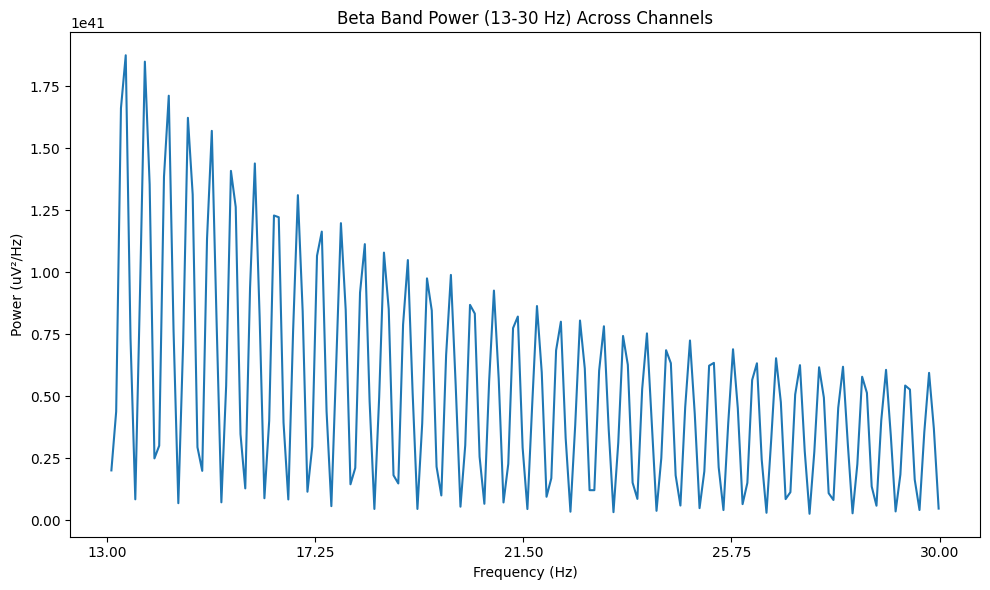

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d41 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d41.head())
print(d41.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

/tmp/ipykernel_169/1495807098.py:129: RuntimeWarning: invalid value encountered in divide
  beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
/tmp/ipykernel_169/1495807098.py:137: RuntimeWarning: invalid value encountered in scalar divide
  spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0


Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)


Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d41_clean = d41.replace([np.inf, -np.inf], np.nan)
d41_clean = d41_clean.fillna(d41_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d41_scaled = pd.DataFrame(
    scaler.fit_transform(d41_clean),
    columns=d41_clean.columns,
    index=d41_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d41_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d41_scaled.index,
    columns=d41_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d41_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df41 = d41_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df41["Pd_indicator_meg"] = 1

print("\nShape of df5:", df41.shape)
print(df41.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940, df41], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041 = df12345678101112131415161718192122232425262728293031323335363738394041.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041):")
print(df12345678101112131415161718192122232425262728293031323335363738394041)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041:", df12345678101112131415161718192122232425262728293031323335363738394041.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041):
      burst_rate  mean_burst_duration  mean_burst_amplitude     ibi_cv  \
0       4.148423             0.060237          3.794677e-12   0.843069   
1       4.089981             0.061125          2.134013e-13   0.767457   
2       4.163265             0.060049          3.607224e-12   0.786598   
3       4.183673             0.059707          4.139047e-12   0.750612   
4       4.333024             0.057641          2.012607e-13   0.775638   
...          ...                  ...                   ...        ...   
2199    2.227451             0.028299          5.775664e+13  43.402072   
2200    2.261765             0.027945          6.576593e+20  43.715890   
2201    5.697059             0.012618          2.445090e+12  67.025659   
2202    7.986275             0.009737          7.623760e+18  77.516593   
2203    2.310784             0.078239          5.779758e+17  44.158936   

      duty_cycl

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041.to_csv(
    '/content/drive/MyDrive/combined_features_upto_sub041_21.csv',
    index=False
)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects (safe version, same style)

try:
    del raw
except NameError:
    pass

try:
    del ica
except NameError:
    pass

try:
    del psd_obj
except NameError:
    pass

try:
    del psds
except NameError:
    pass

try:
    del beta_band_psd
except NameError:
    pass

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041 preserved.")


RAM Used After Cleanup: 0.98 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041 preserved.


sub-42

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-42'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-042_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-042_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-042_coordsystem.json', 'sub-042_task-go_run-1_proc-tsss+mc_events.json', 'sub-042_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-042_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-042_task-go_run-1_proc-tsss+mc_meg.json', 'sub-042_task-noise_proc-tsss_channels.tsv', 'sub-042_task-noise_proc-tsss_meg.fif', 'sub-042_task-noise_proc-tsss_meg.json', 'sub-042_task-passive_run-1_proc-tsss+mc_events.json', 'sub-042_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-042_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-042_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-042_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-042_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-042_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-042_task-rest_run-1_proc-tsss+mc_events.json', 'sub-042_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-042_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-042_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-042_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-042_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-042_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-42/meg/sub-042_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-42/meg/sub-042_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 68000 ... 1153999 =     68.000 ...  1153.999 secs
Ready.
Reading 0 ... 1085999  =      0.000 ...  1085.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


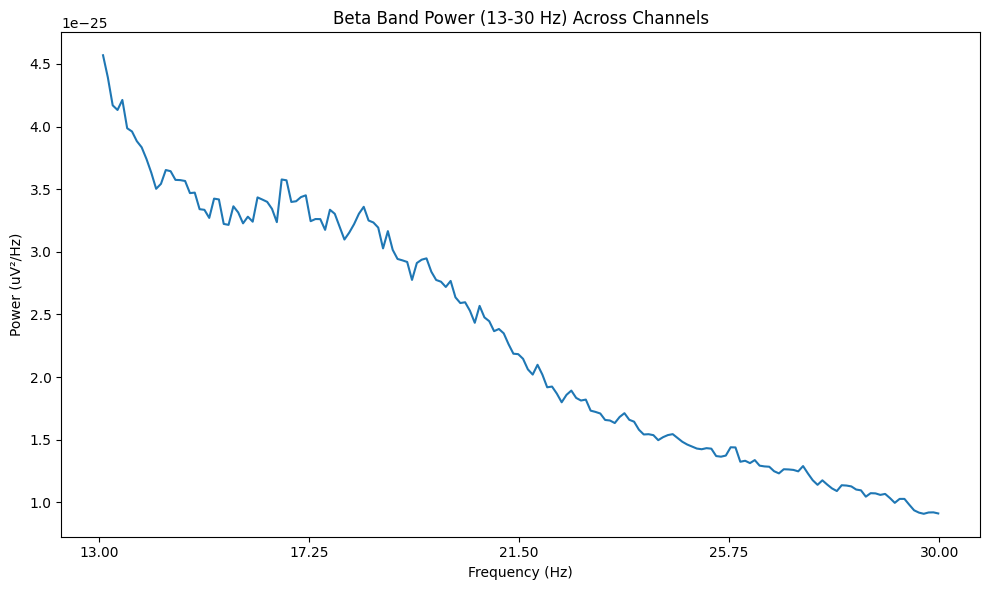

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d42 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d42.head())
print(d42.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d42_clean = d42.replace([np.inf, -np.inf], np.nan)
d42_clean = d42_clean.fillna(d42_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d42_scaled = pd.DataFrame(
    scaler.fit_transform(d42_clean),
    columns=d42_clean.columns,
    index=d42_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d42_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d42_scaled.index,
    columns=d42_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d42_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df42 = d42_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df42["Pd_indicator_meg"] = 1

print("\nShape of df5:", df42.shape)
print(df42.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041, df42], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142 = df1234567810111213141516171819212223242526272829303132333536373839404142.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142:", df1234567810111213141516171819212223242526272829303132333536373839404142.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
2257    4.485267             0.055738          2.718547e-12  0.755400   
2258    4.454880             0.056118          2.368192e-12  0.771758   
2259    4.370166             0.057178          1.352581e-13  0.747581   
2260    4.318600             0.057889          2.639510e-12  0.738035   
2261    4.477901             0.055814          2.744661e-12  0.741111   

      duty_cycle  peak_be

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142.to_csv('/content/drive/MyDrive/combined_features_upto_sub042_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142 preserved.")


RAM Used After Cleanup: 1.02 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142 preserved.


sub-43

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-43'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-043_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-043_task-go_run-1_proc-tsss+mc_events.json', 'sub-043_coordsystem.json', 'sub-043_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-043_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-043_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-043_task-noise_proc-tsss_channels.tsv', 'sub-043_task-noise_proc-tsss_meg.fif', 'sub-043_task-go_run-1_proc-tsss+mc_meg.json', 'sub-043_task-passive_run-1_proc-tsss+mc_events.json', 'sub-043_task-noise_proc-tsss_meg.json', 'sub-043_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-043_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-043_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-043_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-043_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-043_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-043_task-rest_run-1_proc-tsss+mc_events.json', 'sub-043_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-043_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-043_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-043_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-043_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-043_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-43/meg/sub-043_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-43/meg/sub-043_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 119000 ... 1197999 =    119.000 ...  1197.999 secs
Ready.
Reading 0 ... 1078999  =      0.000 ...  1078.999 secs...
Finding events on: STI101
302 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
302 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


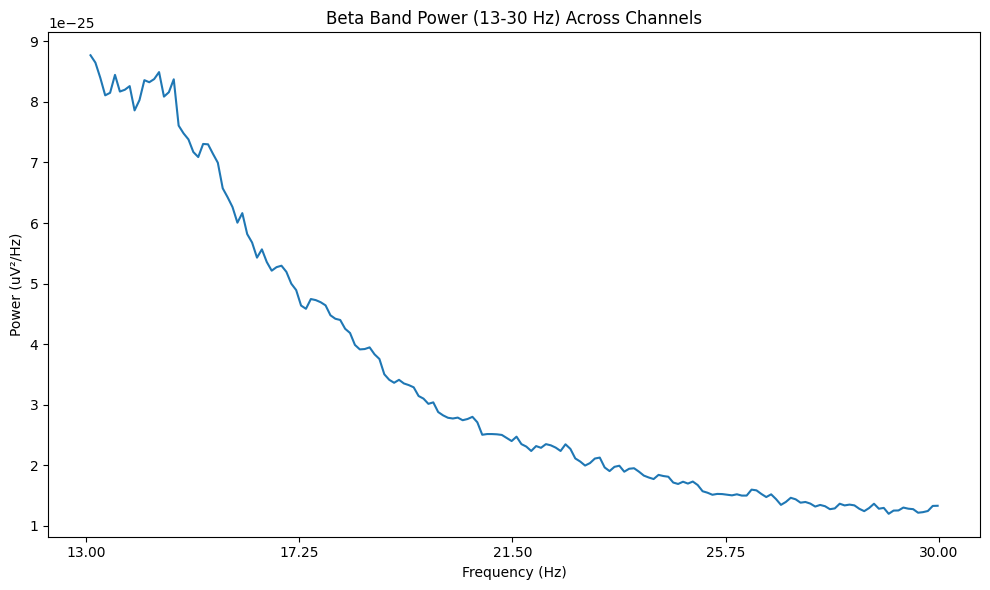

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d43 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d43.head())
print(d43.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d43_clean = d43.replace([np.inf, -np.inf], np.nan)
d43_clean = d43_clean.fillna(d43_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d43_scaled = pd.DataFrame(
    scaler.fit_transform(d43_clean),
    columns=d43_clean.columns,
    index=d43_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d43_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d43_scaled.index,
    columns=d43_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d43_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df43 = d43_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df43["Pd_indicator_meg"] = 1

print("\nShape of df5:", df43.shape)
print(df43.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142, df43], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243 = df123456781011121314151617181921222324252627282930313233353637383940414243.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243:", df123456781011121314151617181921222324252627282930313233353637383940414243.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
2315    3.844300             0.065031          2.923370e-12  0.827716   
2316    3.849861             0.064937          2.938773e-12  0.881221   
2317    3.873957             0.064533          1.661502e-13  0.875619   
2318    4.092678             0.061085          3.418363e-12  0.881867   
2319    3.920297             0.063771          3.180165e-12  0.801904   

      duty_cycle  peak_

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243.to_csv('/content/drive/MyDrive/combined_features_upto_sub043_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243 preserved.")


RAM Used After Cleanup: 1.02 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243 preserved.


sub-44

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-44'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-044_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-044_coordsystem.json', 'sub-044_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-044_task-go_run-1_proc-tsss+mc_events.json', 'sub-044_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-044_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-044_task-noise_proc-tsss_channels.tsv', 'sub-044_task-noise_proc-tsss_meg.fif', 'sub-044_task-go_run-1_proc-tsss+mc_meg.json', 'sub-044_task-noise_proc-tsss_meg.json', 'sub-044_task-passive_run-1_proc-tsss+mc_events.json', 'sub-044_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-044_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-044_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-044_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-044_task-rest_run-1_proc-tsss+mc_events.json', 'sub-044_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-044_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-044_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-044_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-044_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-044_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-044_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-044_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-44/meg/sub-044_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-44/meg/sub-044_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 55000 ... 1131999 =     55.000 ...  1131.999 secs
Ready.
Reading 0 ... 1076999  =      0.000 ...  1076.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


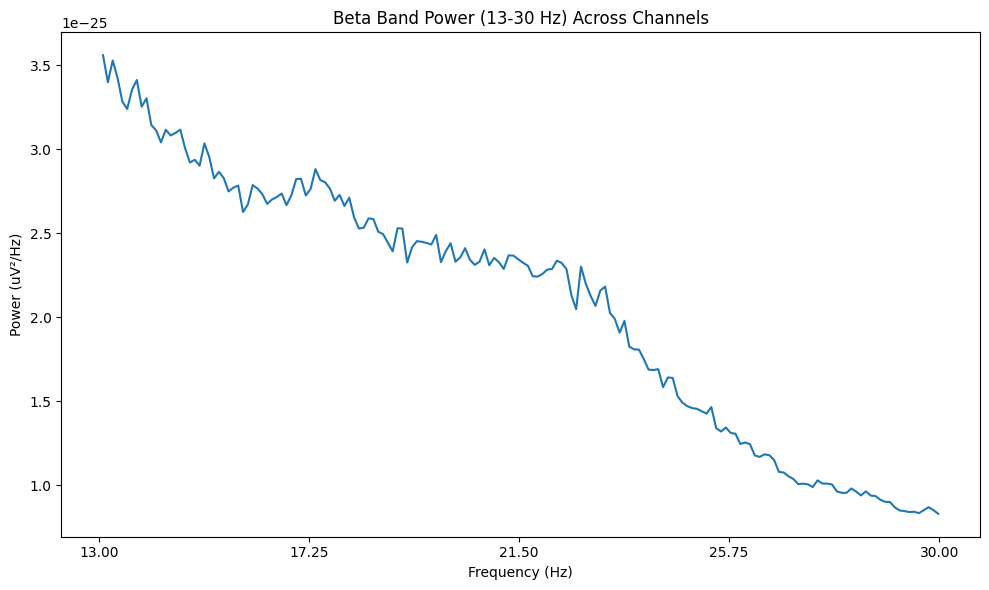

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d44 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d44.head())
print(d44.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d44_clean = d44.replace([np.inf, -np.inf], np.nan)
d44_clean = d44_clean.fillna(d44_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d44_scaled = pd.DataFrame(
    scaler.fit_transform(d44_clean),
    columns=d44_clean.columns,
    index=d44_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d44_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d44_scaled.index,
    columns=d44_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d44_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df44 = d44_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df44["Pd_indicator_meg"] = 0

print("\nShape of df5:", df44.shape)
print(df44.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243, df44], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344 = df12345678101112131415161718192122232425262728293031323335363738394041424344.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344:", df12345678101112131415161718192122232425262728293031323335363738394041424344.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
2373    4.306407             0.058053          2.534394e-12  0.743905   
2374    4.047354             0.061769          2.375685e-12  0.744059   
2375    4.092851             0.061082          1.319744e-13  0.750826   
2376    3.995357             0.062573          2.593492e-12  0.741328   
2377    4.404828             0.056756          2.520381e-12  0.739698   

      duty_cycle  pea

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041424344.to_csv('/content/drive/MyDrive/combined_features_upto_sub044_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344 preserved.")


RAM Used After Cleanup: 1.03 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344 preserved.


sub-45

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-45'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-045_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-045_coordsystem.json', 'sub-045_task-go_run-1_proc-tsss+mc_events.json', 'sub-045_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-045_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-045_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-045_task-go_run-1_proc-tsss+mc_meg.json', 'sub-045_task-noise_proc-tsss_channels.tsv', 'sub-045_task-noise_proc-tsss_meg.fif', 'sub-045_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-045_task-noise_proc-tsss_meg.json', 'sub-045_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-045_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-045_task-passive_run-1_proc-tsss+mc_events.json', 'sub-045_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-045_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-045_task-rest_run-1_proc-tsss+mc_events.json', 'sub-045_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-045_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-045_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-045_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-045_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-045_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-045_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-45/meg/sub-045_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-45/meg/sub-045_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 102000 ... 1175999 =    102.000 ...  1175.999 secs
Ready.
Reading 0 ... 1073999  =      0.000 ...  1073.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


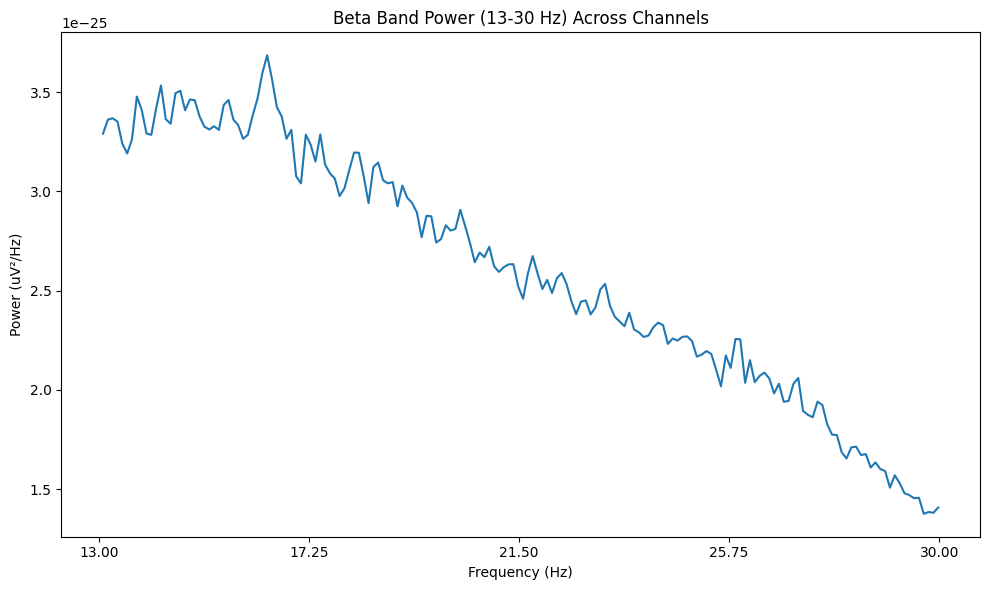

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d45 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d45.head())
print(d45.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d45_clean = d45.replace([np.inf, -np.inf], np.nan)
d45_clean = d45_clean.fillna(d45_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d45_scaled = pd.DataFrame(
    scaler.fit_transform(d45_clean),
    columns=d45_clean.columns,
    index=d45_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d45_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d45_scaled.index,
    columns=d45_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d45_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df45 = d45_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df45["Pd_indicator_meg"] = 1

print("\nShape of df5:", df45.shape)
print(df45.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344, df45], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445 = df1234567810111213141516171819212223242526272829303132333536373839404142434445.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445:", df1234567810111213141516171819212223242526272829303132333536373839404142434445.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
2431    4.257914             0.058714          2.357310e-12  0.791762   
2432    4.248603             0.058843          1.976840e-12  0.785174   
2433    4.336127             0.057655          1.259447e-13  0.786449   
2434    4.189944             0.059667          2.219230e-12  0.822992   
2435    4.200186             0.059521          2.284987e-12  0.805418   

      duty_cycle  p

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445.to_csv('/content/drive/MyDrive/combined_features_upto_sub045_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445 preserved.")


RAM Used After Cleanup: 1.03 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445 preserved.


sub-46

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-46'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-046_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-046_coordsystem.json', 'sub-046_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-046_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-046_task-go_run-1_proc-tsss+mc_events.json', 'sub-046_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-046_task-noise_proc-tsss_meg.fif', 'sub-046_task-go_run-1_proc-tsss+mc_meg.json', 'sub-046_task-noise_proc-tsss_channels.tsv', 'sub-046_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-046_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-046_task-passive_run-1_proc-tsss+mc_events.json', 'sub-046_task-noise_proc-tsss_meg.json', 'sub-046_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-046_task-rest_run-1_proc-tsss+mc_events.json', 'sub-046_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-046_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-046_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-046_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-046_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-046_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-046_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-046_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-046_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-46/meg/sub-046_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-46/meg/sub-046_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 112000 ... 1220999 =    112.000 ...  1220.999 secs
Ready.
Reading 0 ... 1108999  =      0.000 ...  1108.999 secs...
Finding events on: STI101
302 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
302 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


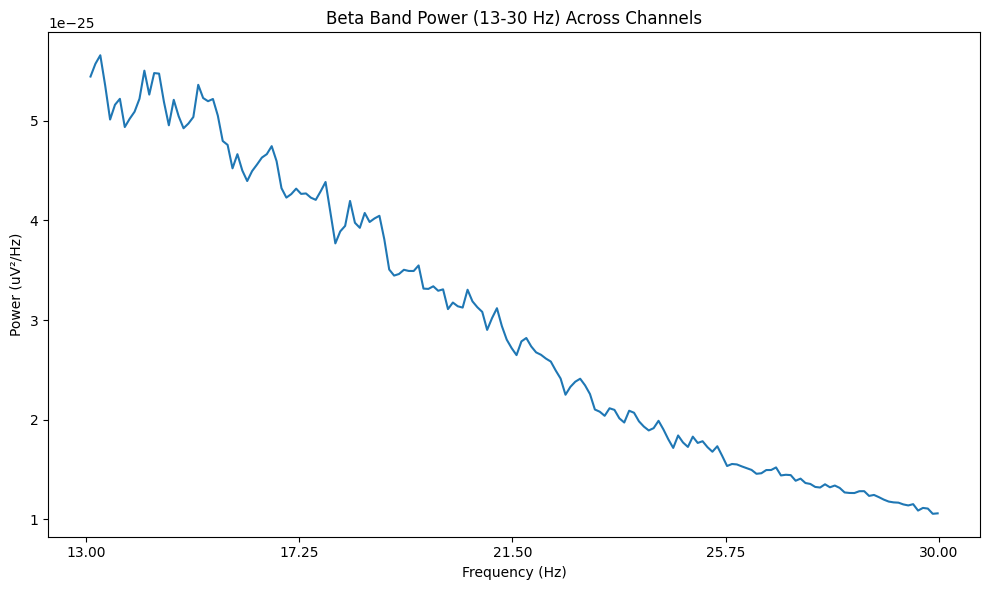

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d46 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d46.head())
print(d46.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d46_clean = d46.replace([np.inf, -np.inf], np.nan)
d46_clean = d46_clean.fillna(d46_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d46_scaled = pd.DataFrame(
    scaler.fit_transform(d46_clean),
    columns=d46_clean.columns,
    index=d46_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d46_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d46_scaled.index,
    columns=d46_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d46_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df46 = d46_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df46["Pd_indicator_meg"] = 1

print("\nShape of df5:", df46.shape)
print(df46.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445, df46], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546 = df123456781011121314151617181921222324252627282930313233353637383940414243444546.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546:", df123456781011121314151617181921222324252627282930313233353637383940414243444546.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
2489    4.020739             0.062178          3.747042e-12  0.796286   
2490    3.919748             0.063752          3.852768e-12  0.832882   
2491    3.998197             0.062528          1.978347e-13  0.843227   
2492    3.917042             0.063814          4.312392e-12  0.822360   
2493    4.028855             0.062052          3.934421e-12  0.801432   

      duty_cycle 

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546.to_csv('/content/drive/MyDrive/combined_features_upto_sub046_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546 preserved.")


RAM Used After Cleanup: 1.06 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546 preserved.


sub-47

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-47'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-047_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-047_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-047_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-047_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-047_task-go_run-1_proc-tsss+mc_events.json', 'sub-047_coordsystem.json', 'sub-047_task-go_run-1_proc-tsss+mc_meg.json', 'sub-047_task-noise_proc-tsss_meg.fif', 'sub-047_task-noise_proc-tsss_channels.tsv', 'sub-047_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-047_task-passive_run-1_proc-tsss+mc_events.json', 'sub-047_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-047_task-noise_proc-tsss_meg.json', 'sub-047_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-047_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-047_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-047_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-047_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-047_task-rest_run-1_proc-tsss+mc_events.json', 'sub-047_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-047_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-047_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-047_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-047_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-47/meg/sub-047_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-47/meg/sub-047_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 68000 ... 1136999 =     68.000 ...  1136.999 secs
Ready.
Reading 0 ... 1068999  =      0.000 ...  1068.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


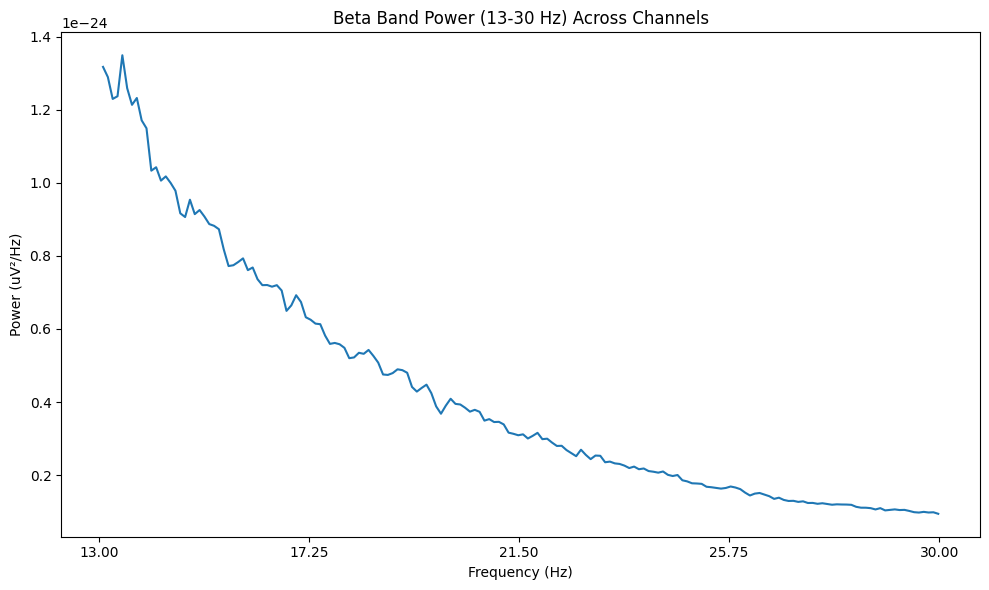

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d47 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d47.head())
print(d47.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d47_clean = d47.replace([np.inf, -np.inf], np.nan)
d47_clean = d47_clean.fillna(d47_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d47_scaled = pd.DataFrame(
    scaler.fit_transform(d47_clean),
    columns=d47_clean.columns,
    index=d47_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d47_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d47_scaled.index,
    columns=d47_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d47_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df47 = d47_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df47["Pd_indicator_meg"] = 0

print("\nShape of df5:", df47.shape)
print(df47.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546, df47], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
2547    3.768943             0.066332          3.009319e-12  1.041513   
2548    4.018709             0.062209          2.566447e-12  0.924637   
2549    4.013096             0.062296          1.460139e-13  0.915044   
2550    3.993452             0.062602          2.704530e-12  0.967905   
2551    3.944808             0.063374          2.685591e-12  0.933808   

      duty_cycl

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647.to_csv('/content/drive/MyDrive/combined_features_upto_sub047_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647 preserved.")


RAM Used After Cleanup: 1.06 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647 preserved.


sub-48

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-48'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-048_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-048_coordsystem.json', 'sub-048_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-048_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-048_task-go_run-1_proc-tsss+mc_events.json', 'sub-048_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-048_task-go_run-1_proc-tsss+mc_meg.json', 'sub-048_task-noise_proc-tsss_meg.fif', 'sub-048_task-noise_proc-tsss_channels.tsv', 'sub-048_task-noise_proc-tsss_meg.json', 'sub-048_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-048_task-passive_run-1_proc-tsss+mc_events.json', 'sub-048_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-048_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-048_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-048_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-048_task-rest_run-1_proc-tsss+mc_events.json', 'sub-048_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-048_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-048_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-048_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-048_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-048_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-048_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-48/meg/sub-048_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-48/meg/sub-048_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 84000 ... 1156999 =     84.000 ...  1156.999 secs
Ready.
Reading 0 ... 1072999  =      0.000 ...  1072.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


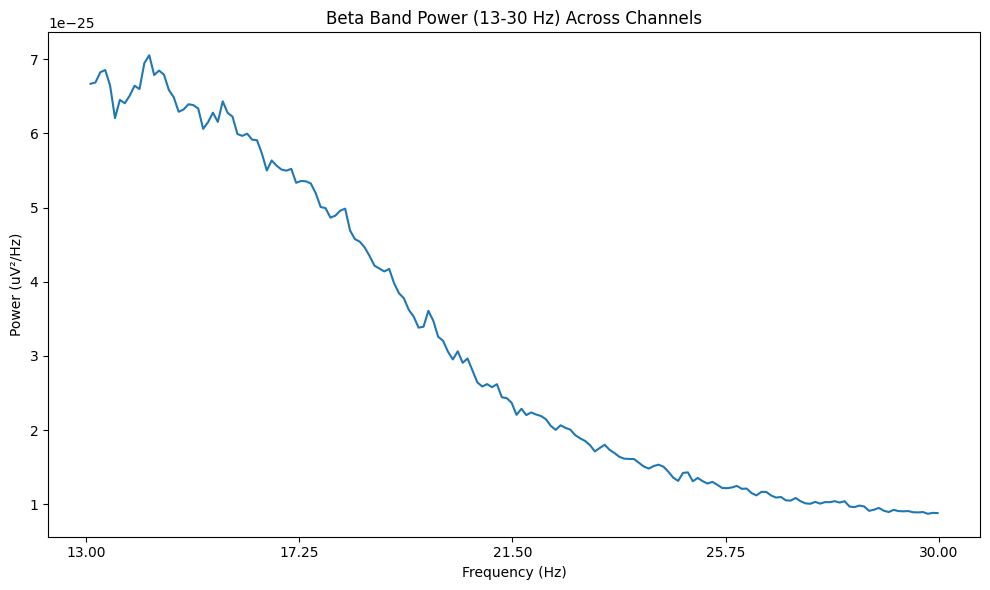

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d48 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d48.head())
print(d48.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d48_clean = d48.replace([np.inf, -np.inf], np.nan)
d48_clean = d48_clean.fillna(d48_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d48_scaled = pd.DataFrame(
    scaler.fit_transform(d48_clean),
    columns=d48_clean.columns,
    index=d48_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d48_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d48_scaled.index,
    columns=d48_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d48_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df48 = d48_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df48["Pd_indicator_meg"] = 0

print("\nShape of df5:", df48.shape)
print(df48.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647, df48], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
2605    3.696179             0.067637          2.654525e-12  0.858051   
2606    3.952470             0.063252          2.491192e-12  0.865832   
2607    3.892824             0.064221          1.681947e-13  0.820922   
2608    4.085741             0.061188          2.606621e-12  0.845059   
2609    3.828518             0.065299          2.555225e-12  0.853615   

      duty_cy

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748.to_csv('/content/drive/MyDrive/combined_features_upto_sub048_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748 preserved.")


RAM Used After Cleanup: 1.08 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748 preserved.


sub-49

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-49'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-049_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-049_task-go_run-1_proc-tsss+mc_events.json', 'sub-049_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-049_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-049_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-049_coordsystem.json', 'sub-049_task-go_run-1_proc-tsss+mc_meg.json', 'sub-049_task-noise_proc-tsss_channels.tsv', 'sub-049_task-noise_proc-tsss_meg.fif', 'sub-049_task-noise_proc-tsss_meg.json', 'sub-049_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-049_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-049_task-passive_run-1_proc-tsss+mc_events.json', 'sub-049_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-049_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-049_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-049_task-rest_run-1_proc-tsss+mc_events.json', 'sub-049_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-049_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-049_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-049_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-049_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-049_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-049_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-49/meg/sub-049_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-49/meg/sub-049_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 66000 ... 1144999 =     66.000 ...  1144.999 secs
Ready.
Reading 0 ... 1078999  =      0.000 ...  1078.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spetral Density

Effective window size : 10.240 (s)


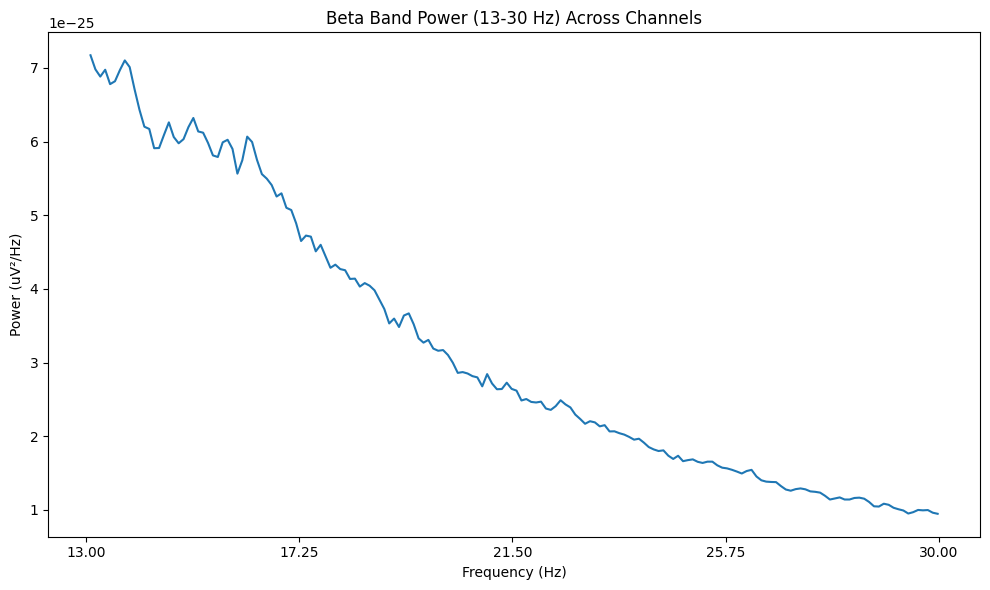

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d49 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d49.head())
print(d49.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d49_clean = d49.replace([np.inf, -np.inf], np.nan)
d49_clean = d49_clean.fillna(d49_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d49_scaled = pd.DataFrame(
    scaler.fit_transform(d49_clean),
    columns=d49_clean.columns,
    index=d49_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d49_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d49_scaled.index,
    columns=d49_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d49_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df49 = d49_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df49["Pd_indicator_meg"] = 1

print("\nShape of df5:", df49.shape)
print(df49.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748, df49], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
2663    4.336423             0.057651          3.018726e-12  0.766847   
2664    4.286376             0.058324          2.636930e-12  0.752309   
2665    4.284523             0.058350          1.532039e-13  0.779374   
2666    4.410565             0.056682          2.874535e-12  0.740771   
2667    4.421687             0.056540          3.302637e-12  0.754041   

      duty_

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849.to_csv('/content/drive/MyDrive/combined_features_upto_sub049_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849 preserved.")


RAM Used After Cleanup: 1.09 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849 preserved.


sub-50

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-50'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-050_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-050_coordsystem.json', 'sub-050_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-050_task-go_run-1_proc-tsss+mc_events.json', 'sub-050_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-050_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-050_task-go_run-1_proc-tsss+mc_meg.json', 'sub-050_task-noise_proc-tsss_channels.tsv', 'sub-050_task-noise_proc-tsss_meg.fif', 'sub-050_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-050_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-050_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-050_task-passive_run-1_proc-tsss+mc_events.json', 'sub-050_task-noise_proc-tsss_meg.json', 'sub-050_task-rest_run-1_proc-tsss+mc_events.json', 'sub-050_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-050_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-050_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-050_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-050_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-050_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-050_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-050_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-050_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-50/meg/sub-050_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-50/meg/sub-050_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 138000 ... 1209999 =    138.000 ...  1209.999 secs
Ready.
Reading 0 ... 1071999  =      0.000 ...  1071.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


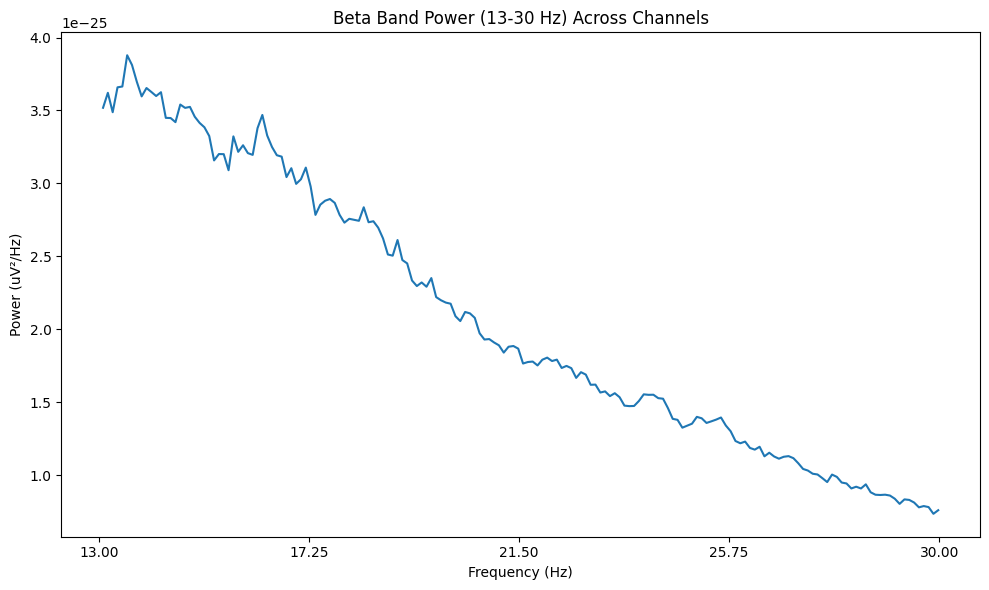

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d50 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d50.head())
print(d50.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d50_clean = d50.replace([np.inf, -np.inf], np.nan)
d50_clean = d50_clean.fillna(d50_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d50_scaled = pd.DataFrame(
    scaler.fit_transform(d50_clean),
    columns=d50_clean.columns,
    index=d50_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d50_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d50_scaled.index,
    columns=d50_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d50_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df50 = d50_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df50["Pd_indicator_meg"] = 0

print("\nShape of df5:", df50.shape)
print(df50.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849, df50], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
2721    3.975746             0.062881          2.500659e-12  0.863678   
2722    4.067164             0.061468          2.523265e-12  0.837866   
2723    4.177239             0.059835          1.303997e-13  0.811536   
2724    4.010261             0.062340          2.724286e-12  0.855358   
2725    4.050373             0.061723          2.660467e-12  0.862573   

      dut

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950.to_csv('/content/drive/MyDrive/combined_features_upto_sub050_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950 preserved.")


RAM Used After Cleanup: 1.08 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950 preserved.


sub-51

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-51'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-051_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-051_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-051_coordsystem.json', 'sub-051_task-go_run-1_proc-tsss+mc_events.json', 'sub-051_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-051_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-051_task-noise_proc-tsss_meg.fif', 'sub-051_task-noise_proc-tsss_channels.tsv', 'sub-051_task-go_run-1_proc-tsss+mc_meg.json', 'sub-051_task-noise_proc-tsss_meg.json', 'sub-051_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-051_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-051_task-passive_run-1_proc-tsss+mc_events.json', 'sub-051_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-051_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-051_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-051_task-rest_run-1_proc-tsss+mc_events.json', 'sub-051_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-051_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-051_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-051_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-051_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-051_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-051_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-51/meg/sub-051_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-51/meg/sub-051_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 73000 ... 1149999 =     73.000 ...  1149.999 secs
Ready.
Reading 0 ... 1076999  =      0.000 ...  1076.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


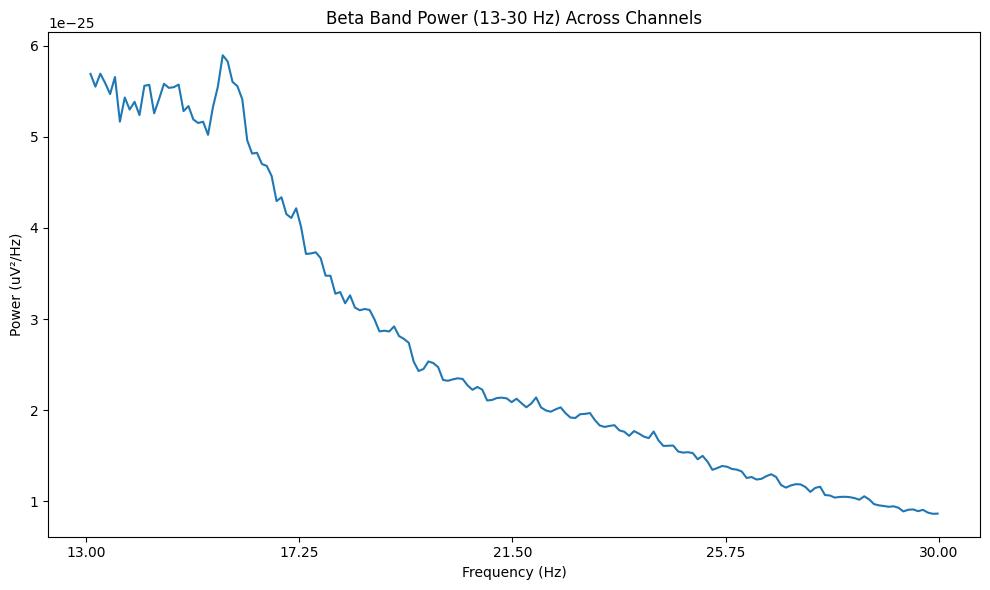

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d51 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d51.head())
print(d51.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d51_clean = d51.replace([np.inf, -np.inf], np.nan)
d51_clean = d51_clean.fillna(d51_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d51_scaled = pd.DataFrame(
    scaler.fit_transform(d51_clean),
    columns=d51_clean.columns,
    index=d51_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d51_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d51_scaled.index,
    columns=d51_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d51_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df51 = d51_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df51["Pd_indicator_meg"] = 1

print("\nShape of df5:", df51.shape)
print(df51.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950, df51], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
2779    4.259053             0.058676          2.942132e-12  0.794243   
2780    4.241411             0.058943          2.861697e-12  0.807485   
2781    4.212628             0.059345          1.517349e-13  0.810821   
2782    4.264624             0.058622          2.991699e-12  0.799404   
2783    4.222841             0.059202          2.909328e-12  0.775065   

      d

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051.to_csv('/content/drive/MyDrive/combined_features_upto_sub051_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051 preserved.")


RAM Used After Cleanup: 1.08 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051 preserved.


sub-52

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-52'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-052_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-052_coordsystem.json', 'sub-052_task-go_run-1_proc-tsss+mc_events.json', 'sub-052_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-052_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-052_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-052_task-go_run-1_proc-tsss+mc_meg.json', 'sub-052_task-noise_proc-tsss_channels.tsv', 'sub-052_task-noise_proc-tsss_meg.fif', 'sub-052_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-052_task-passive_run-1_proc-tsss+mc_events.json', 'sub-052_task-noise_proc-tsss_meg.json', 'sub-052_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-052_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-052_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-052_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-052_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-052_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-052_task-rest_run-1_proc-tsss+mc_events.json', 'sub-052_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-052_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-052_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-052_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-052_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-52/meg/sub-052_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-52/meg/sub-052_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 75000 ... 1146999 =     75.000 ...  1146.999 secs
Ready.
Reading 0 ... 1071999  =      0.000 ...  1071.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


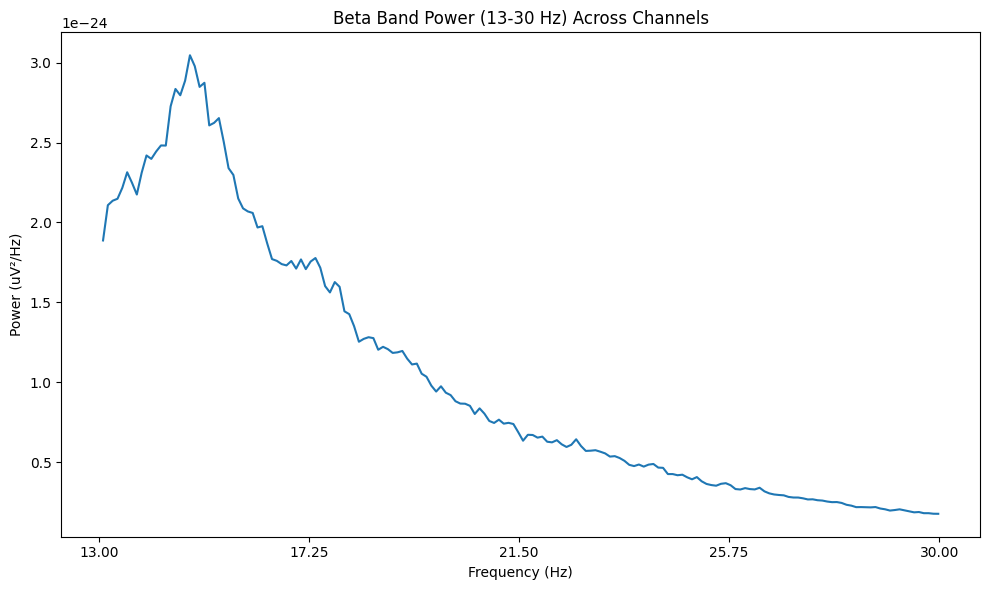

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d52 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d52.head())
print(d52.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d52_clean = d52.replace([np.inf, -np.inf], np.nan)
d52_clean = d52_clean.fillna(d52_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d52_scaled = pd.DataFrame(
    scaler.fit_transform(d52_clean),
    columns=d52_clean.columns,
    index=d52_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d52_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d52_scaled.index,
    columns=d52_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d52_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df52 = d52_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df52["Pd_indicator_meg"] = 1

print("\nShape of df5:", df52.shape)
print(df52.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051, df52], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
2837    3.787313             0.066010          4.160755e-12  0.821532   
2838    3.824627             0.065366          3.958665e-12  0.845721   
2839    3.757463             0.066534          2.692103e-13  0.833717   
2840    3.747201             0.066716          4.164155e-12  0.856826   
2841    3.823694             0.065382          3.959890e-12  0.814434   

     

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152.to_csv('/content/drive/MyDrive/combined_features_upto_sub052_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152 preserved.")


RAM Used After Cleanup: 1.08 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152 preserved.


sub-53

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-53'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-053_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-053_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-053_task-go_run-1_proc-tsss+mc_events.json', 'sub-053_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-053_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-053_coordsystem.json', 'sub-053_task-go_run-1_proc-tsss+mc_meg.json', 'sub-053_task-noise_proc-tsss_meg.fif', 'sub-053_task-noise_proc-tsss_channels.tsv', 'sub-053_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-053_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-053_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-053_task-passive_run-1_proc-tsss+mc_events.json', 'sub-053_task-noise_proc-tsss_meg.json', 'sub-053_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-053_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-053_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-053_task-rest_run-1_proc-tsss+mc_events.json', 'sub-053_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-053_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-053_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-053_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-053_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-053_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-53/meg/sub-053_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-53/meg/sub-053_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 34000 ... 1102999 =     34.000 ...  1102.999 secs
Ready.
Reading 0 ... 1068999  =      0.000 ...  1068.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing power Spectral Density

Effective window size : 10.240 (s)


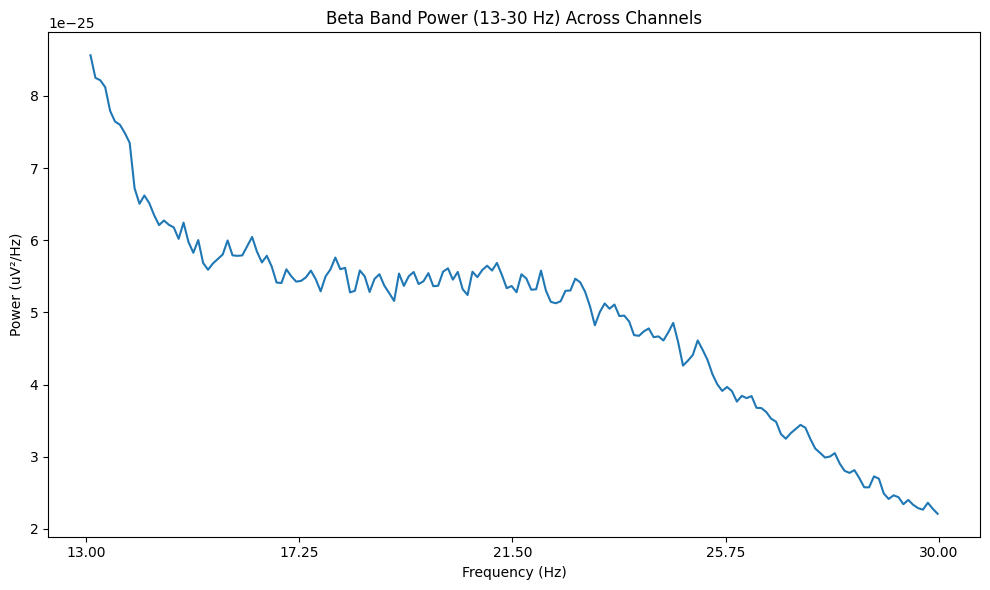

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d53 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d53.head())
print(d53.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d53_clean = d53.replace([np.inf, -np.inf], np.nan)
d53_clean = d53_clean.fillna(d53_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d53_scaled = pd.DataFrame(
    scaler.fit_transform(d53_clean),
    columns=d53_clean.columns,
    index=d53_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d53_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d53_scaled.index,
    columns=d53_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d53_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df53 = d53_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df53["Pd_indicator_meg"] = 0

print("\nShape of df5:", df53.shape)
print(df53.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152, df53], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
2895    3.769878             0.066315          5.491955e-12  0.879281   
2896    3.946679             0.063344          4.765526e-12  0.838021   
2897    3.816651             0.065502          3.252551e-13  0.886614   
2898    3.927035             0.063661          5.232614e-12  0.868027   
2899    3.739008             0.066863          5.531395e-12  0.905796   

   

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253.to_csv('/content/drive/MyDrive/combined_features_upto_sub053_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253 preserved.")


RAM Used After Cleanup: 1.06 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253 preserved.


sub-54

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-54'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-054_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-054_task-go_run-1_proc-tsss+mc_events.json', 'sub-054_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-054_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-054_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-054_coordsystem.json', 'sub-054_task-noise_proc-tsss_meg.fif', 'sub-054_task-noise_proc-tsss_channels.tsv', 'sub-054_task-go_run-1_proc-tsss+mc_meg.json', 'sub-054_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-054_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-054_task-noise_proc-tsss_meg.json', 'sub-054_task-passive_run-1_proc-tsss+mc_events.json', 'sub-054_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-054_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-054_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-054_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-054_task-rest_run-1_proc-tsss+mc_events.json', 'sub-054_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-054_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-054_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-054_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-054_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-054_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-54/meg/sub-054_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-54/meg/sub-054_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 75000 ... 1164999 =     75.000 ...  1164.999 secs
Ready.
Reading 0 ... 1089999  =      0.000 ...  1089.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


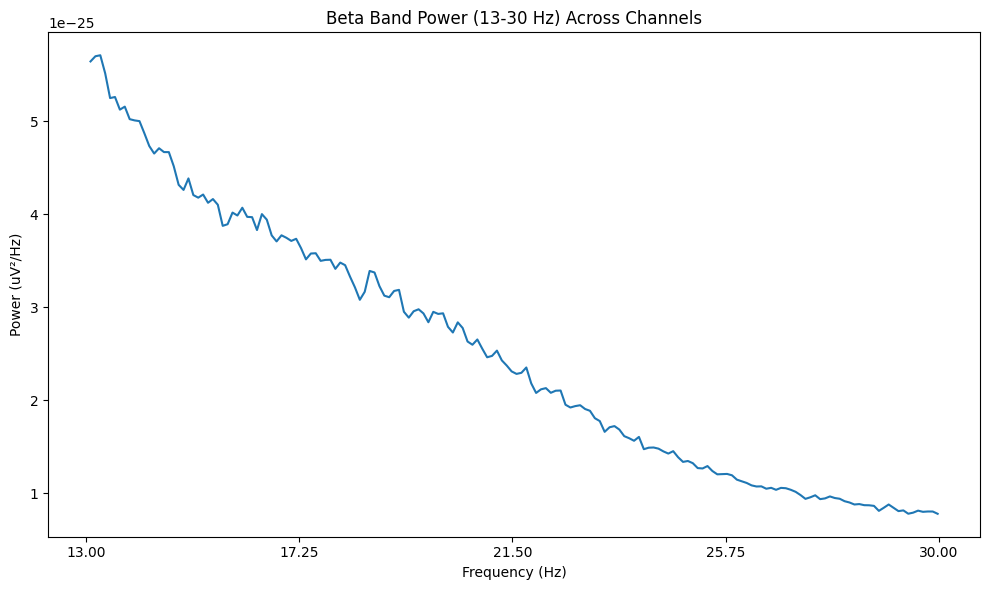

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d54 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d54.head())
print(d54.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d54_clean = d54.replace([np.inf, -np.inf], np.nan)
d54_clean = d54_clean.fillna(d54_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d54_scaled = pd.DataFrame(
    scaler.fit_transform(d54_clean),
    columns=d54_clean.columns,
    index=d54_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d54_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d54_scaled.index,
    columns=d54_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d54_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df54 = d54_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df54["Pd_indicator_meg"] = 1

print("\nShape of df5:", df54.shape)
print(df54.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253, df54], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
2953    3.965138             0.063050          3.319663e-12  0.788478   
2954    4.044037             0.061819          3.108443e-12  0.797370   
2955    3.826606             0.065332          1.985032e-13  0.810960   
2956    4.144954             0.060314          3.304913e-12  0.790001   
2957    4.006422             0.062400          3.434772e-12  0.793772   

 

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354.to_csv('/content/drive/MyDrive/combined_features_upto_sub054_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354 preserved.")


RAM Used After Cleanup: 1.07 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354 preserved.


sub-55

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-55'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-055_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-055_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-055_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-055_coordsystem.json', 'sub-055_task-go_run-1_proc-tsss+mc_events.json', 'sub-055_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-055_task-go_run-1_proc-tsss+mc_meg.json', 'sub-055_task-noise_proc-tsss_meg.fif', 'sub-055_task-noise_proc-tsss_channels.tsv', 'sub-055_task-noise_proc-tsss_meg.json', 'sub-055_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-055_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-055_task-passive_run-1_proc-tsss+mc_events.json', 'sub-055_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-055_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-055_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-055_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-055_task-rest_run-1_proc-tsss+mc_events.json', 'sub-055_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-055_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-055_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-055_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-055_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-055_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-55/meg/sub-055_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-55/meg/sub-055_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 65000 ... 1152999 =     65.000 ...  1152.999 secs
Ready.
Reading 0 ... 1087999  =      0.000 ...  1087.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


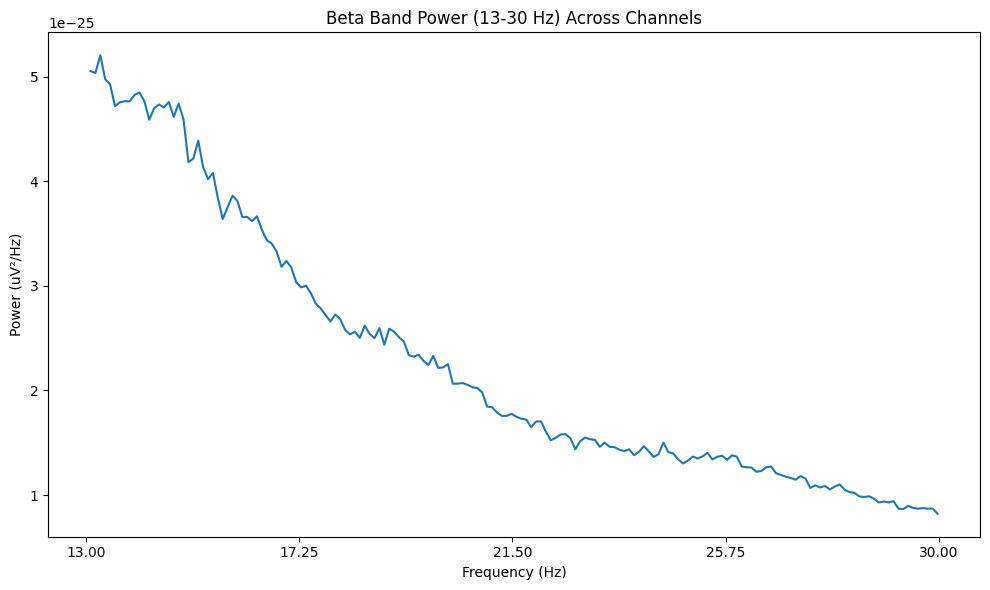

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d55 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d55.head())
print(d55.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d55_clean = d55.replace([np.inf, -np.inf], np.nan)
d55_clean = d55_clean.fillna(d55_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d55_scaled = pd.DataFrame(
    scaler.fit_transform(d55_clean),
    columns=d55_clean.columns,
    index=d55_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d55_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d55_scaled.index,
    columns=d55_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d55_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df55 = d55_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df55["Pd_indicator_meg"] = 1

print("\nShape of df5:", df55.shape)
print(df55.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354, df55], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3011    4.239890             0.058964          2.876064e-12  0.829902   
3012    4.341912             0.057578          2.409036e-12  0.780264   
3013    4.465993             0.055979          1.448097e-13  0.800009   
3014    4.372243             0.057179          2.706499e-12  0.790486   
3015    4.503676             0.055510          2.695154e-12  0.751364   


In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455.to_csv('/content/drive/MyDrive/combined_features_upto_sub055_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455 preserved.")


RAM Used After Cleanup: 1.07 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455 preserved.


sub-56

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-56'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-056_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-056_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-056_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-056_coordsystem.json', 'sub-056_task-go_run-1_proc-tsss+mc_events.json', 'sub-056_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-056_task-noise_proc-tsss_channels.tsv', 'sub-056_task-go_run-1_proc-tsss+mc_meg.json', 'sub-056_task-noise_proc-tsss_meg.fif', 'sub-056_task-noise_proc-tsss_meg.json', 'sub-056_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-056_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-056_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-056_task-passive_run-1_proc-tsss+mc_events.json', 'sub-056_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-056_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-056_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-056_task-rest_run-1_proc-tsss+mc_events.json', 'sub-056_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-056_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-056_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-056_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-056_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-056_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-56/meg/sub-056_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-56/meg/sub-056_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 49000 ... 1145999 =     49.000 ...  1145.999 secs
Ready.
Reading 0 ... 1096999  =      0.000 ...  1096.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting 

Computing Power Spectral Density

Effective window size : 10.240 (s)


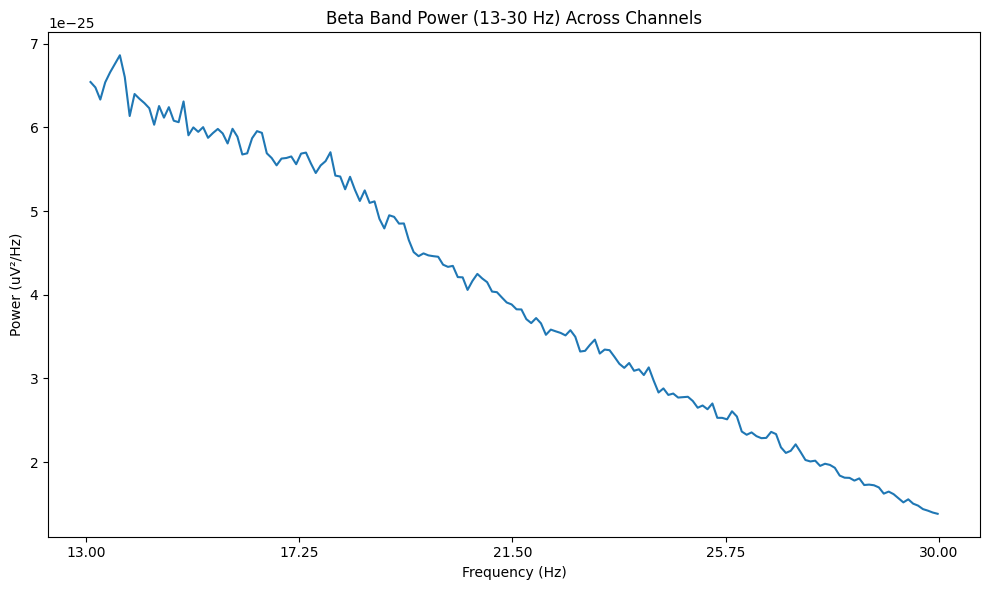

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d56 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d56.head())
print(d56.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d56_clean = d56.replace([np.inf, -np.inf], np.nan)
d56_clean = d56_clean.fillna(d56_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d56_scaled = pd.DataFrame(
    scaler.fit_transform(d56_clean),
    columns=d56_clean.columns,
    index=d56_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d56_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d56_scaled.index,
    columns=d56_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d56_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df56 = d56_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df56["Pd_indicator_meg"] = 1

print("\nShape of df5:", df56.shape)
print(df56.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455, df56], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3069    4.082042             0.061244          3.999500e-12  0.888898   
3070    3.987238             0.062700          3.952445e-12  0.912078   
3071    3.846855             0.064988          2.130671e-13  0.936030   
3072    3.846855             0.064979          4.187964e-12  0.966395   
3073    3.922516             0.063723          4.123723e-12  0.909514  

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556.to_csv('/content/drive/MyDrive/combined_features_upto_sub056_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556 preserved.")


RAM Used After Cleanup: 1.09 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556 preserved.


sub-57

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-57'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-057_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-057_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-057_task-noise_proc-tsss_meg.fif', 'sub-057_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-057_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-057_task-go_run-1_proc-tsss+mc_events.json', 'sub-057_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-057_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-057_task-noise_proc-tsss_meg.json', 'sub-057_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-057_task-passive_run-1_proc-tsss+mc_events.json', 'sub-057_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-057_task-noise_proc-tsss_channels.tsv', 'sub-057_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-057_coordsystem.json', 'sub-057_task-rest_run-1_proc-tsss+mc_events.json', 'sub-057_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-057_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-057_task-go_run-1_proc-tsss+mc_meg.json', 'sub-057_task-passive_run-1_proc-tsss+mc_channels.tsv']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-057_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-057_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-057_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-057_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-57/meg/sub-057_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-57/meg/sub-057_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 162000 ... 1241999 =    162.000 ...  1241.999 secs
Ready.
Reading 0 ... 1079999  =      0.000 ...  1079.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


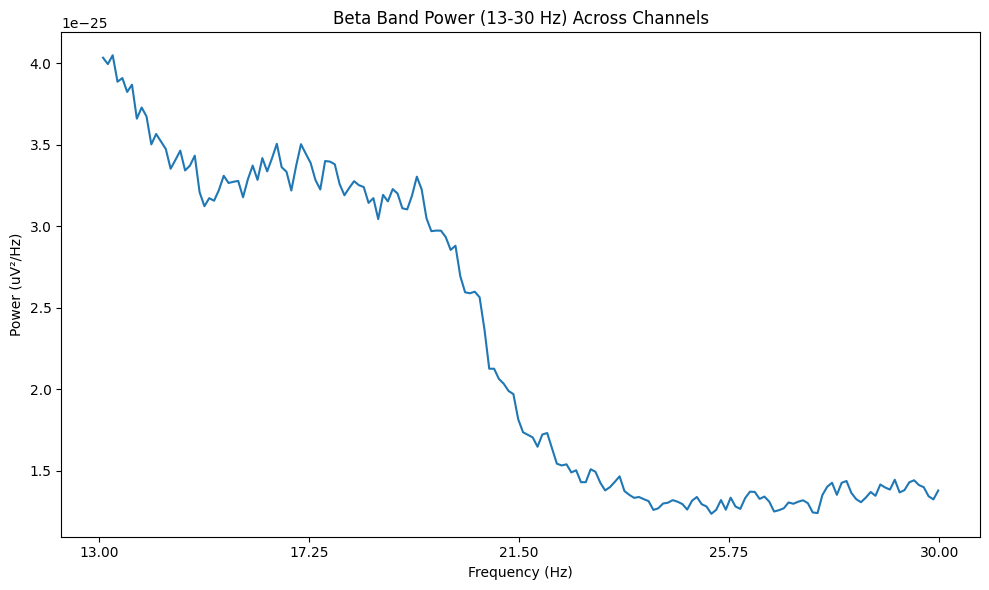

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d57 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d57.head())
print(d57.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d57_clean = d57.replace([np.inf, -np.inf], np.nan)
d57_clean = d57_clean.fillna(d57_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d57_scaled = pd.DataFrame(
    scaler.fit_transform(d57_clean),
    columns=d57_clean.columns,
    index=d57_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d57_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d57_scaled.index,
    columns=d57_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d57_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df57 = d57_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df57["Pd_indicator_meg"] = 0

print("\nShape of df5:", df57.shape)
print(df57.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556, df57], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3127    4.767593             0.052427          2.317768e-12  0.740852   
3128    4.699074             0.053202          2.063353e-12  0.748327   
3129    4.629630             0.054000          1.174858e-13  0.808056   
3130    4.603704             0.054304          2.110363e-12  0.758976   
3131    4.762963             0.052488          2.014860e-12  0.732432

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657.to_csv('/content/drive/MyDrive/combined_features_upto_sub057_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657 preserved.")


RAM Used After Cleanup: 1.11 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657 preserved.


sub-58

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-58'  # Replace with your folder paths

In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['meg', 'sub-058_scans.tsv']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-058_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-058_task-noise_proc-tsss_meg.fif', 'sub-058_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-058_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-058_coordsystem.json', 'sub-058_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-058_task-go_run-1_proc-tsss+mc_meg.json', 'sub-058_task-passive_run-1_proc-tsss+mc_events.json', 'sub-058_task-noise_proc-tsss_meg.json', 'sub-058_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-058_task-noise_proc-tsss_channels.tsv', 'sub-058_task-rest_run-1_proc-tsss+mc_events.json', 'sub-058_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-058_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-058_task-go_run-1_proc-tsss+mc_events.json', 'sub-058_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-058_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-058_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-058_task-go_run-1_proc-tsss+mc_events.tsv']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-058_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-058_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-058_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-058_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-58/meg/sub-058_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-58/meg/sub-058_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 93000 ... 1181999 =     93.000 ...  1181.999 secs
Ready.
Reading 0 ... 1088999  =      0.000 ...  1088.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


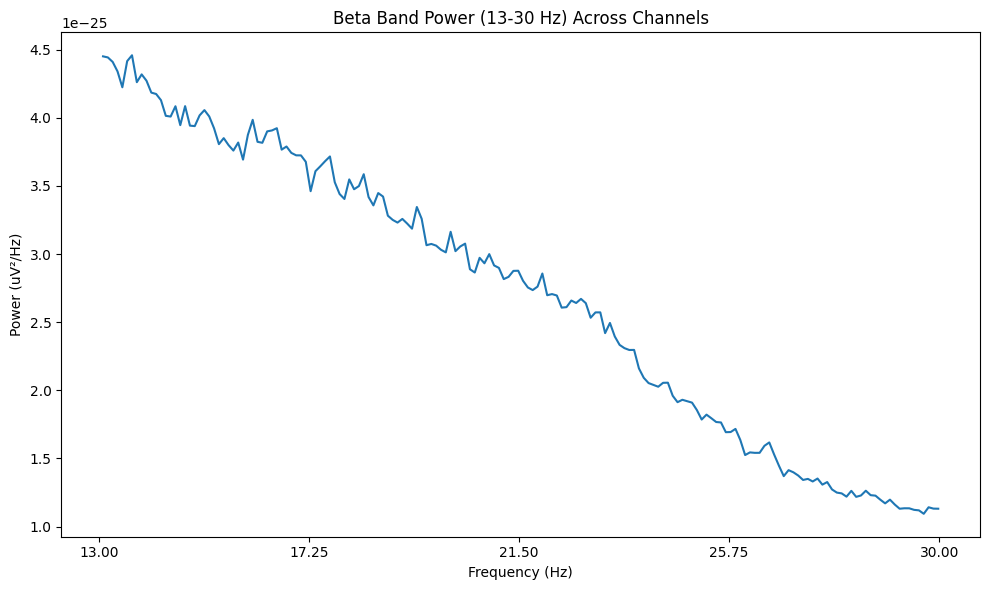

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d58 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d58.head())
print(d58.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d58_clean = d58.replace([np.inf, -np.inf], np.nan)
d58_clean = d58_clean.fillna(d58_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d58_scaled = pd.DataFrame(
    scaler.fit_transform(d58_clean),
    columns=d58_clean.columns,
    index=d58_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d58_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d58_scaled.index,
    columns=d58_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d58_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df58 = d58_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df58["Pd_indicator_meg"] = 0

print("\nShape of df5:", df58.shape)
print(df58.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657, df58], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3185    4.407713             0.056706          3.070742e-12  0.730031   
3186    4.221304             0.059223          2.835109e-12  0.738284   
3187    4.157943             0.060126          1.791434e-13  0.776331   
3188    4.158861             0.060113          3.331692e-12  0.769262   
3189    4.536272             0.055079          4.804795e-12  0.7139

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758.to_csv('/content/drive/MyDrive/combined_features_upto_sub058_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758 preserved.")


RAM Used After Cleanup: 1.11 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758 preserved.


sub-59

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-59'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-059_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-059_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-059_task-go_run-1_proc-tsss+mc_events.json', 'sub-059_coordsystem.json', 'sub-059_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-059_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-059_task-noise_proc-tsss_meg.fif', 'sub-059_task-noise_proc-tsss_channels.tsv', 'sub-059_task-go_run-1_proc-tsss+mc_meg.json', 'sub-059_task-passive_run-1_proc-tsss+mc_events.json', 'sub-059_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-059_task-noise_proc-tsss_meg.json', 'sub-059_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-059_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-059_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-059_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-059_task-rest_run-1_proc-tsss+mc_events.json', 'sub-059_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-059_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-059_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-059_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-059_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-059_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-059_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-59/meg/sub-059_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-59/meg/sub-059_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 237000 ... 1318999 =    237.000 ...  1318.999 secs
Ready.
Reading 0 ... 1081999  =      0.000 ...  1081.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


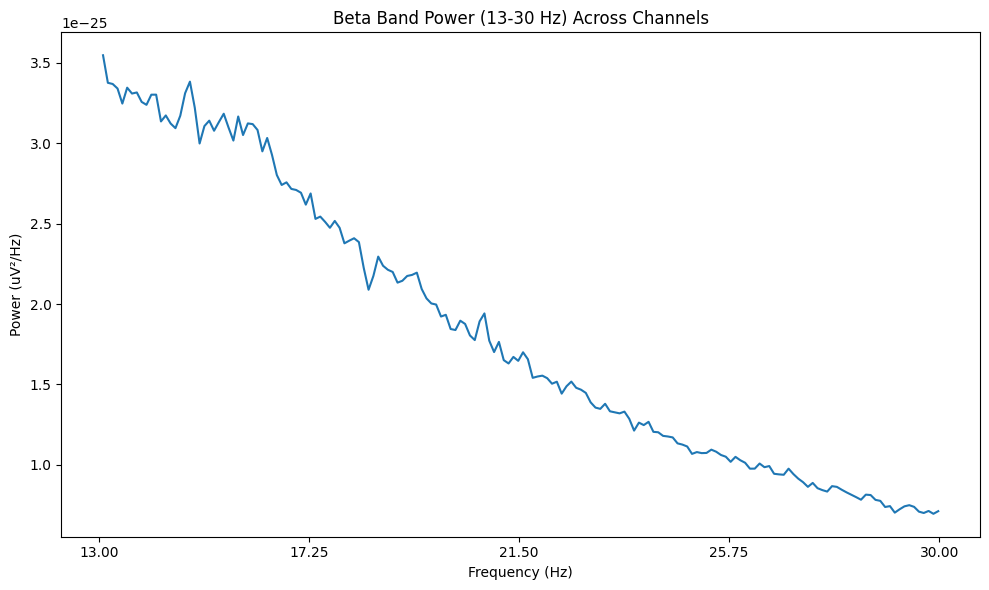

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d59 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d59.head())
print(d59.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d59_clean = d59.replace([np.inf, -np.inf], np.nan)
d59_clean = d59_clean.fillna(d59_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d59_scaled = pd.DataFrame(
    scaler.fit_transform(d59_clean),
    columns=d59_clean.columns,
    index=d59_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d59_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d59_scaled.index,
    columns=d59_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d59_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df59 = d59_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df59["Pd_indicator_meg"] = 0

print("\nShape of df5:", df59.shape)
print(df59.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758, df59], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3243    4.217190             0.059281          2.649054e-12  0.818811   
3244    4.274492             0.058486          2.366310e-12  0.779447   
3245    4.074861             0.061352          1.446848e-13  0.857792   
3246    4.267098             0.058588          2.412576e-12  0.783951   
3247    4.243993             0.058907          2.293596e-12  0.76

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859.to_csv('/content/drive/MyDrive/combined_features_upto_sub059_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859 preserved.")


RAM Used After Cleanup: 1.10 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859 preserved.


sub-60

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-60'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-060_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-060_coordsystem.json', 'sub-060_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-060_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-060_task-go_run-1_proc-tsss+mc_events.json', 'sub-060_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-060_task-noise_proc-tsss_channels.tsv', 'sub-060_task-go_run-1_proc-tsss+mc_meg.json', 'sub-060_task-noise_proc-tsss_meg.fif', 'sub-060_task-noise_proc-tsss_meg.json', 'sub-060_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-060_task-passive_run-1_proc-tsss+mc_events.json', 'sub-060_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-060_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-060_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-060_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-060_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-060_task-rest_run-1_proc-tsss+mc_events.json', 'sub-060_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-060_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-060_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-060_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-060_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-060_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-60/meg/sub-060_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-60/meg/sub-060_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 118000 ... 1196999 =    118.000 ...  1196.999 secs
Ready.
Reading 0 ... 1078999  =      0.000 ...  1078.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


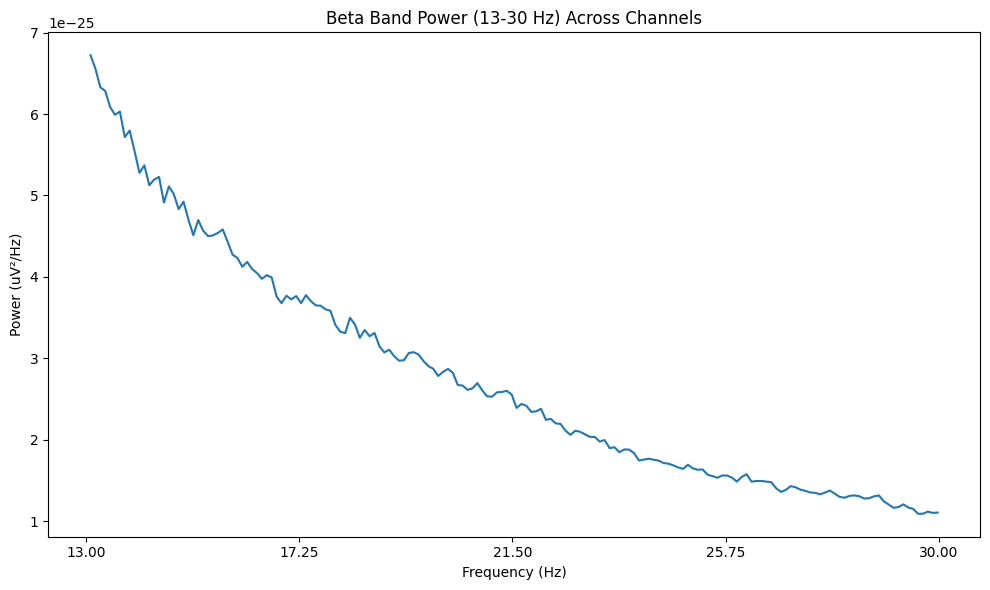

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d60 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d60.head())
print(d60.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d60_clean = d60.replace([np.inf, -np.inf], np.nan)
d60_clean = d60_clean.fillna(d60_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d60_scaled = pd.DataFrame(
    scaler.fit_transform(d60_clean),
    columns=d60_clean.columns,
    index=d60_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d60_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d60_scaled.index,
    columns=d60_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d60_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df60 = d60_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df60["Pd_indicator_meg"] = 1

print("\nShape of df5:", df60.shape)
print(df60.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859, df60], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3301    4.347544             0.057488          2.297866e-12  0.749468   
3302    4.590361             0.054462          2.486295e-12  0.842749   
3303    4.339203             0.057605          1.409418e-13  0.803278   
3304    4.543095             0.055029          3.049593e-12  0.907362   
3305    4.538462             0.055085          2.568441e-12  0.

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960.to_csv('/content/drive/MyDrive/combined_features_upto_sub060_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960 preserved.")


RAM Used After Cleanup: 1.12 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960 preserved.


sub-61

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-61'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-061_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-061_coordsystem.json', 'sub-061_task-go_run-1_proc-tsss+mc_events.json', 'sub-061_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-061_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-061_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-061_task-noise_proc-tsss_meg.fif', 'sub-061_task-go_run-1_proc-tsss+mc_meg.json', 'sub-061_task-noise_proc-tsss_channels.tsv', 'sub-061_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-061_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-061_task-passive_run-1_proc-tsss+mc_events.json', 'sub-061_task-noise_proc-tsss_meg.json', 'sub-061_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-061_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-061_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-061_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-061_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-061_task-rest_run-1_proc-tsss+mc_events.json', 'sub-061_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-061_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-061_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-061_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-061_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-61/meg/sub-061_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-61/meg/sub-061_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 325000 ... 1412999 =    325.000 ...  1412.999 secs
Ready.
Reading 0 ... 1087999  =      0.000 ...  1087.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


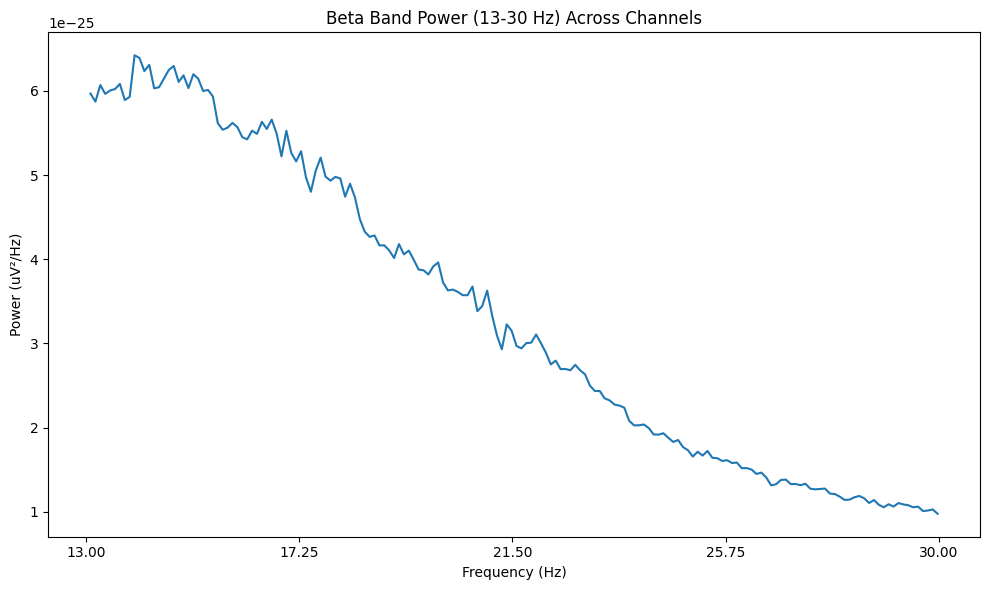

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d61 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d61.head())
print(d61.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d61_clean = d61.replace([np.inf, -np.inf], np.nan)
d61_clean = d61_clean.fillna(d61_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d61_scaled = pd.DataFrame(
    scaler.fit_transform(d61_clean),
    columns=d61_clean.columns,
    index=d61_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d61_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d61_scaled.index,
    columns=d61_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d61_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df61 = d61_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df61["Pd_indicator_meg"] = 0

print("\nShape of df5:", df61.shape)
print(df61.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960, df61], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3359    4.029412             0.062044          2.254517e-12  0.776472   
3360    4.063419             0.061525          2.691230e-12  0.893638   
3361    4.102022             0.060946          1.332908e-13  0.760498   
3362    4.070772             0.061413          2.973176e-12  0.935664   
3363    4.288603             0.058294          2.333924e-12  

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061.to_csv('/content/drive/MyDrive/combined_features_upto_sub061_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061 preserved.")


RAM Used After Cleanup: 1.12 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061 preserved.


sub-63

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-63'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-063_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-063_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-063_coordsystem.json', 'sub-063_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-063_task-go_run-1_proc-tsss+mc_events.json', 'sub-063_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-063_task-go_run-1_proc-tsss+mc_meg.json', 'sub-063_task-noise_proc-tsss_channels.tsv', 'sub-063_task-noise_proc-tsss_meg.fif', 'sub-063_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-063_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-063_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-063_task-noise_proc-tsss_meg.json', 'sub-063_task-passive_run-1_proc-tsss+mc_events.json', 'sub-063_task-rest_run-1_proc-tsss+mc_events.json', 'sub-063_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-063_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-063_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-063_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-063_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-063_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-063_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-063_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-063_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-63/meg/sub-063_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-63/meg/sub-063_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 100000 ... 1179999 =    100.000 ...  1179.999 secs
Ready.
Reading 0 ... 1079999  =      0.000 ...  1079.999 secs...
Finding events on: STI101
Trigger channel STI101 has a non-zero initial value of 14592 (consider using initial_event=True to detect this event)
301 events found on stim channel STI101
Event IDs: [14593 14594 14600]
Finding events on: STI101
Trigger channel STI101 has a non-zero initial value of 14592 (consider using initial_event=True to detect this event)
301 events found on stim channel STI101
Event IDs: [14593 14594 14600]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lo

Computing Power Spectral Density

Effective window size : 10.240 (s)


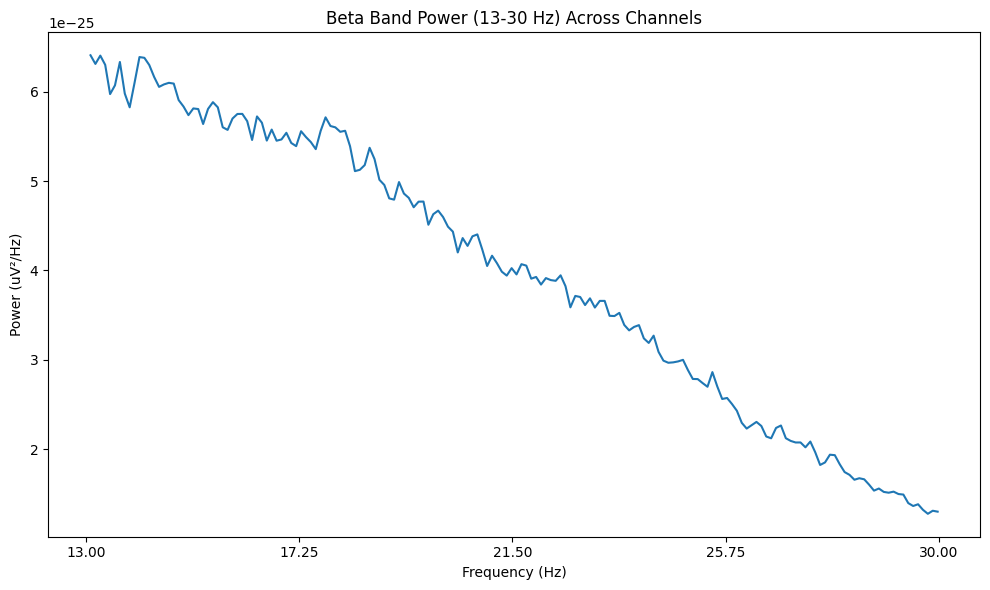

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d63 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d63.head())
print(d63.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d63_clean = d63.replace([np.inf, -np.inf], np.nan)
d63_clean = d63_clean.fillna(d63_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d63_scaled = pd.DataFrame(
    scaler.fit_transform(d63_clean),
    columns=d63_clean.columns,
    index=d63_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d63_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d63_scaled.index,
    columns=d63_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d63_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df63 = d63_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df63["Pd_indicator_meg"] = 0

print("\nShape of df5:", df63.shape)
print(df63.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061, df63], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3417    3.762963             0.066437          4.530430e-12  0.858565   
3418    3.745370             0.066749          4.014406e-12  0.829381   
3419    3.682407             0.067890          2.335312e-13  0.898022   
3420    3.891667             0.064240          4.339902e-12  0.796508   
3421    3.683333             0.067873          4.638492e-12

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163.to_csv('/content/drive/MyDrive/combined_features_upto_sub063_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163 preserved.")


RAM Used After Cleanup: 1.11 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163 preserved.


sub-64

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-64'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-064_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-064_coordsystem.json', 'sub-064_task-go_run-1_proc-tsss+mc_events.json', 'sub-064_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-064_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-064_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-064_task-noise_proc-tsss_meg.fif', 'sub-064_task-noise_proc-tsss_channels.tsv', 'sub-064_task-go_run-1_proc-tsss+mc_meg.json', 'sub-064_task-passive_run-1_proc-tsss+mc_events.json', 'sub-064_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-064_task-noise_proc-tsss_meg.json', 'sub-064_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-064_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-064_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-064_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-064_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-064_task-rest_run-1_proc-tsss+mc_events.json', 'sub-064_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-064_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-064_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-064_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-064_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-064_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-64/meg/sub-064_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-64/meg/sub-064_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 202000 ... 1283999 =    202.000 ...  1283.999 secs
Ready.
Reading 0 ... 1081999  =      0.000 ...  1081.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


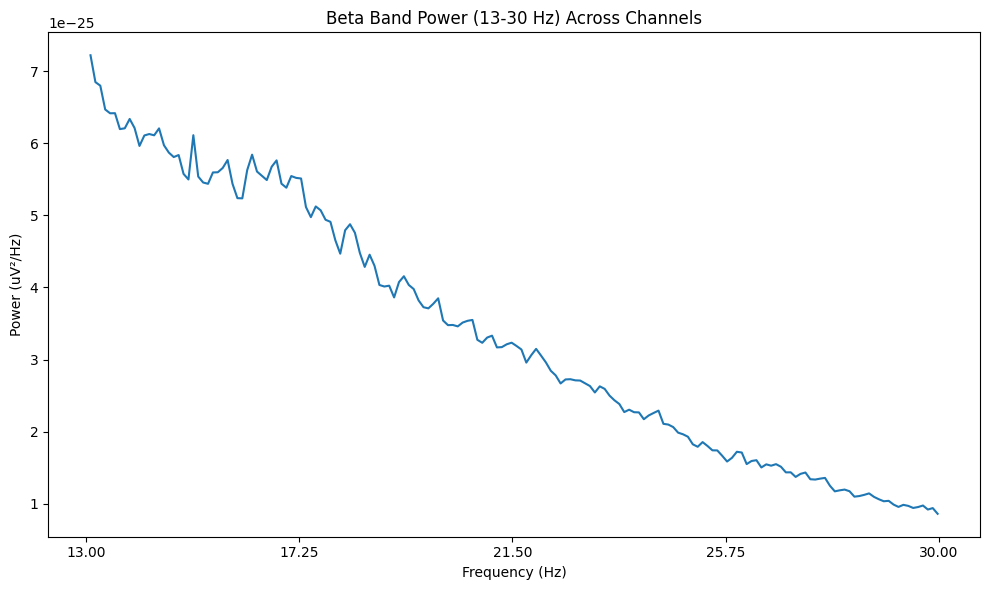

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d64 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d64.head())
print(d64.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d64_clean = d64.replace([np.inf, -np.inf], np.nan)
d64_clean = d64_clean.fillna(d64_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d64_scaled = pd.DataFrame(
    scaler.fit_transform(d64_clean),
    columns=d64_clean.columns,
    index=d64_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d64_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d64_scaled.index,
    columns=d64_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d64_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df64 = d64_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df64["Pd_indicator_meg"] = 1

print("\nShape of df5:", df64.shape)
print(df64.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163, df64], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3475    4.163586             0.060044          3.482153e-12  0.823229   
3476    3.921442             0.063752          3.794863e-12  0.871321   
3477    4.220887             0.059229          1.644129e-13  0.783394   
3478    4.001848             0.062471          3.655585e-12  0.802279   
3479    4.159889             0.060098          3.104565e-

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364.to_csv('/content/drive/MyDrive/combined_features_upto_sub064_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364 preserved.")


RAM Used After Cleanup: 1.11 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364 preserved.


sub-65

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-65'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-065_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-065_task-go_run-1_proc-tsss+mc_events.json', 'sub-065_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-065_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-065_coordsystem.json', 'sub-065_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-065_task-go_run-1_proc-tsss+mc_meg.json', 'sub-065_task-noise_proc-tsss_meg.fif', 'sub-065_task-noise_proc-tsss_channels.tsv', 'sub-065_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-065_task-passive_run-1_proc-tsss+mc_events.json', 'sub-065_task-noise_proc-tsss_meg.json', 'sub-065_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-065_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-065_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-065_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-065_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-065_task-rest_run-1_proc-tsss+mc_events.json', 'sub-065_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-065_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-065_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-065_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-065_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-065_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-65/meg/sub-065_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-65/meg/sub-065_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 92000 ... 1165999 =     92.000 ...  1165.999 secs
Ready.
Reading 0 ... 1073999  =      0.000 ...  1073.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


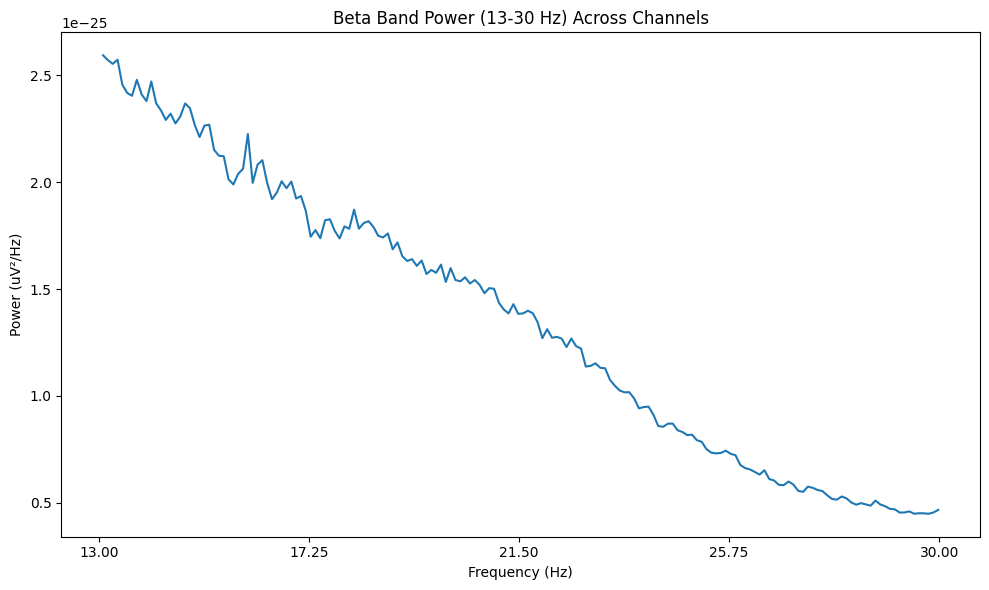

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d65 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d65.head())
print(d65.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d65_clean = d65.replace([np.inf, -np.inf], np.nan)
d65_clean = d65_clean.fillna(d65_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d65_scaled = pd.DataFrame(
    scaler.fit_transform(d65_clean),
    columns=d65_clean.columns,
    index=d65_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d65_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d65_scaled.index,
    columns=d65_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d65_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df65 = d65_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df65["Pd_indicator_meg"] = 0

print("\nShape of df5:", df65.shape)
print(df65.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364, df65], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3533    4.303538             0.058092          2.404524e-12  0.715489   
3534    4.216015             0.059298          2.150217e-12  0.713044   
3535    4.059590             0.061583          1.256483e-13  0.723124   
3536    4.146182             0.060296          2.282147e-12  0.725975   
3537    4.309125             0.058016          2.301520

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465.to_csv('/content/drive/MyDrive/combined_features_upto_sub065_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465 preserved.")


RAM Used After Cleanup: 1.11 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465 preserved.


sub-66

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-66'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-066_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-066_coordsystem.json', 'sub-066_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-066_task-go_run-1_proc-tsss+mc_events.json', 'sub-066_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-066_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-066_task-noise_proc-tsss_meg.fif', 'sub-066_task-go_run-1_proc-tsss+mc_meg.json', 'sub-066_task-noise_proc-tsss_channels.tsv', 'sub-066_task-passive_run-1_proc-tsss+mc_events.json', 'sub-066_task-noise_proc-tsss_meg.json', 'sub-066_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-066_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-066_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-066_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-066_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-066_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-066_task-rest_run-1_proc-tsss+mc_events.json', 'sub-066_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-066_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-066_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-066_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-066_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-066_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-66/meg/sub-066_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-66/meg/sub-066_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 95000 ... 1175999 =     95.000 ...  1175.999 secs
Ready.
Reading 0 ... 1080999  =      0.000 ...  1080.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


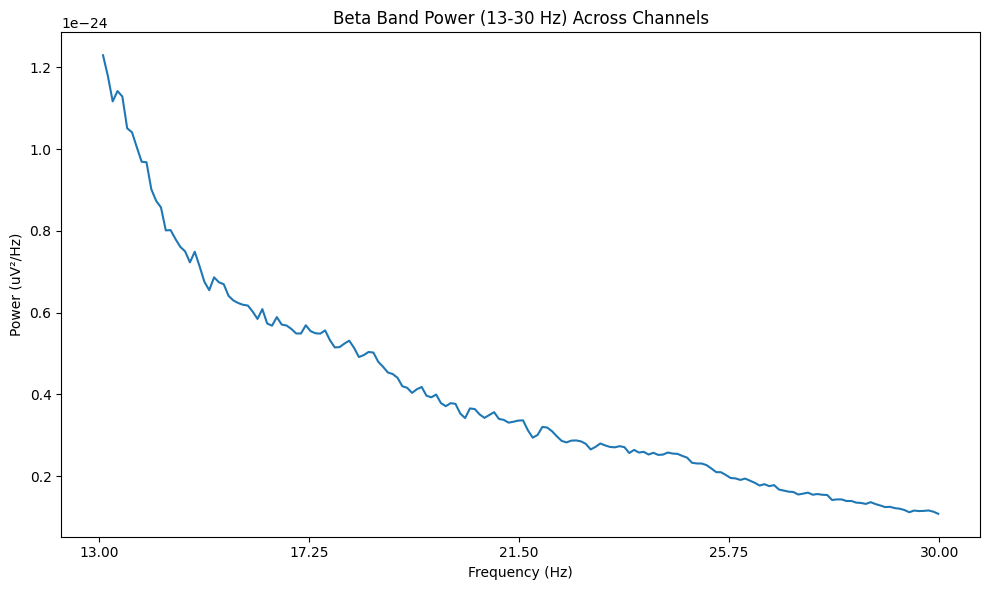

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d66 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d66.head())
print(d66.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d66_clean = d66.replace([np.inf, -np.inf], np.nan)
d66_clean = d66_clean.fillna(d66_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d66_scaled = pd.DataFrame(
    scaler.fit_transform(d66_clean),
    columns=d66_clean.columns,
    index=d66_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d66_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d66_scaled.index,
    columns=d66_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d66_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df66 = d66_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df66["Pd_indicator_meg"] = 0

print("\nShape of df5:", df66.shape)
print(df66.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465, df66], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3591    4.226642             0.059149          2.973661e-12  0.866981   
3592    4.052729             0.061687          3.039391e-12  0.895593   
3593    4.009251             0.062356          1.738289e-13  0.943453   
3594    4.068455             0.061448          3.202201e-12  0.892374   
3595    4.232192             0.059071          2.7487

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566.to_csv('/content/drive/MyDrive/combined_features_upto_sub066_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566 preserved.")


RAM Used After Cleanup: 1.12 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566 preserved.


sub-67

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-67'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-067_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-067_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-067_coordsystem.json', 'sub-067_task-go_run-1_proc-tsss+mc_events.json', 'sub-067_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-067_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-067_task-noise_proc-tsss_channels.tsv', 'sub-067_task-go_run-1_proc-tsss+mc_meg.json', 'sub-067_task-noise_proc-tsss_meg.fif', 'sub-067_task-noise_proc-tsss_meg.json', 'sub-067_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-067_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-067_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-067_task-passive_run-1_proc-tsss+mc_events.json', 'sub-067_task-rest_run-1_proc-tsss+mc_events.json', 'sub-067_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-067_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-067_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-067_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-067_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-067_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-067_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-067_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-067_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-67/meg/sub-067_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-67/meg/sub-067_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 57000 ... 1144999 =     57.000 ...  1144.999 secs
Ready.
Reading 0 ... 1087999  =      0.000 ...  1087.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


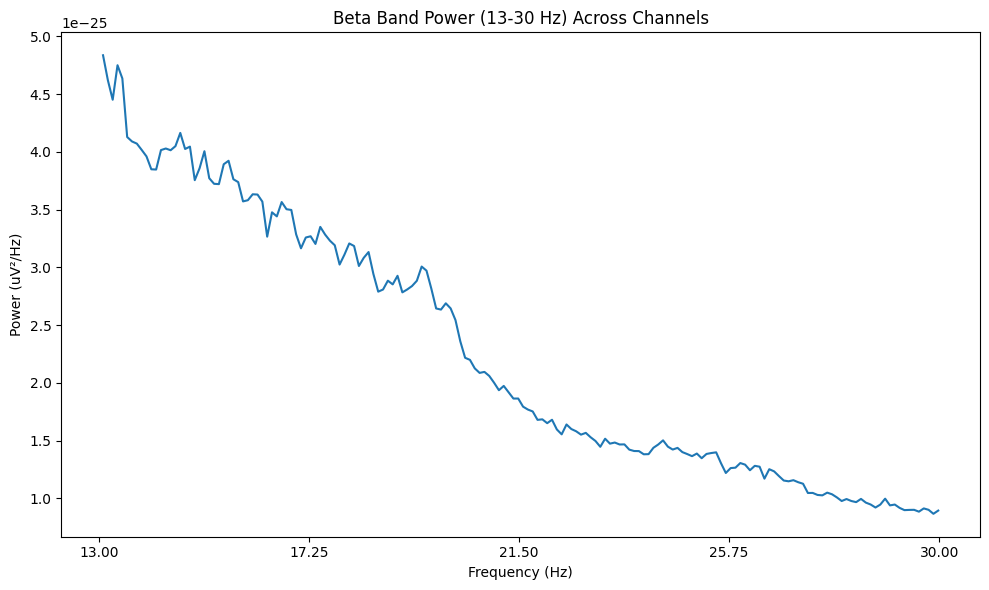

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d67 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d67.head())
print(d67.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d67_clean = d67.replace([np.inf, -np.inf], np.nan)
d67_clean = d67_clean.fillna(d67_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d67_scaled = pd.DataFrame(
    scaler.fit_transform(d67_clean),
    columns=d67_clean.columns,
    index=d67_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d67_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d67_scaled.index,
    columns=d67_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d67_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df67 = d67_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df67["Pd_indicator_meg"] = 1

print("\nShape of df5:", df67.shape)
print(df67.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566, df67], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3649    4.024816             0.062115          3.714767e-12  0.850443   
3650    3.951287             0.063271          3.488570e-12  0.870069   
3651    4.094669             0.061055          1.873133e-13  0.815304   
3652    3.970588             0.062963          3.366287e-12  0.830111   
3653    4.089154             0.061137          3.60

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667.to_csv('/content/drive/MyDrive/combined_features_upto_sub067_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667 preserved.")


RAM Used After Cleanup: 1.12 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667 preserved.


sub-68

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-68'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-068_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-068_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-068_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-068_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-068_coordsystem.json', 'sub-068_task-go_run-1_proc-tsss+mc_events.json', 'sub-068_task-noise_proc-tsss_channels.tsv', 'sub-068_task-noise_proc-tsss_meg.fif', 'sub-068_task-go_run-1_proc-tsss+mc_meg.json', 'sub-068_task-passive_run-1_proc-tsss+mc_events.json', 'sub-068_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-068_task-noise_proc-tsss_meg.json', 'sub-068_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-068_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-068_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-068_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-068_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-068_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-068_task-rest_run-1_proc-tsss+mc_events.json', 'sub-068_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-068_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-068_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-068_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-068_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-68/meg/sub-068_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-68/meg/sub-068_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 293000 ... 1370999 =    293.000 ...  1370.999 secs
Ready.
Reading 0 ... 1077999  =      0.000 ...  1077.999 secs...
Finding events on: STI101
300 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
300 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting

Computing Power Spectral Density

Effective window size : 10.240 (s)


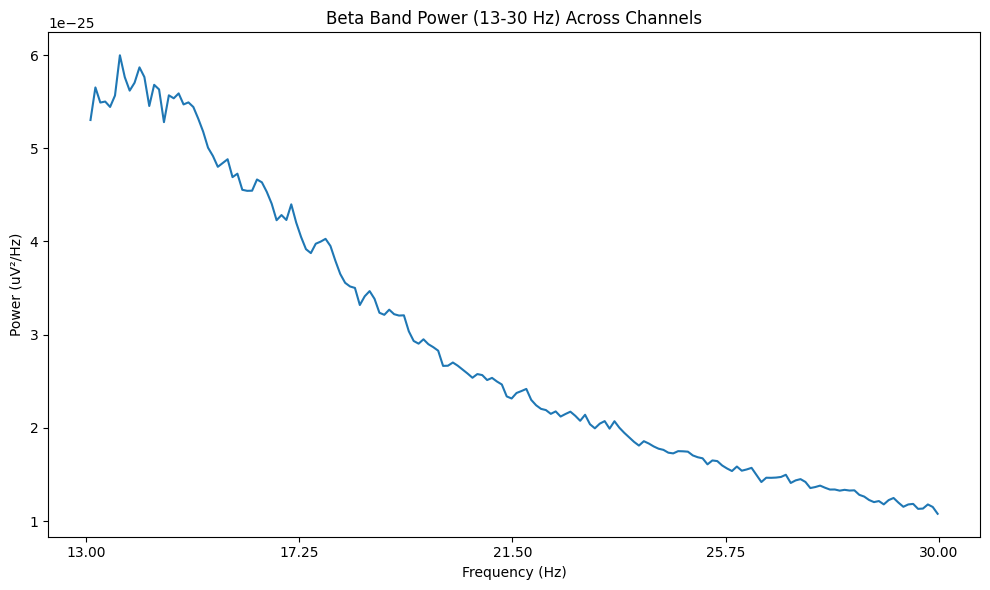

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d68 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d68.head())
print(d68.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d68_clean = d68.replace([np.inf, -np.inf], np.nan)
d68_clean = d68_clean.fillna(d68_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d68_scaled = pd.DataFrame(
    scaler.fit_transform(d68_clean),
    columns=d68_clean.columns,
    index=d68_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d68_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d68_scaled.index,
    columns=d68_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d68_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df68 = d68_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df68["Pd_indicator_meg"] = 0

print("\nShape of df5:", df68.shape)
print(df68.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667, df68], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3707    4.017625             0.062226          2.447115e-12  0.911201   
3708    4.179963             0.059809          2.546128e-12  0.832601   
3709    3.883117             0.064381          1.586686e-13  0.946340   
3710    4.250464             0.058817          3.329557e-12  0.909807   
3711    4.157699             0.060129          3.

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768.to_csv('/content/drive/MyDrive/combined_features_upto_sub068_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768 preserved.")


RAM Used After Cleanup: 1.12 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768 preserved.


sub-69

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-69'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-069_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-069_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-069_coordsystem.json', 'sub-069_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-069_task-go_run-1_proc-tsss+mc_events.json', 'sub-069_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-069_task-go_run-1_proc-tsss+mc_meg.json', 'sub-069_task-noise_proc-tsss_meg.fif', 'sub-069_task-noise_proc-tsss_channels.tsv', 'sub-069_task-noise_proc-tsss_meg.json', 'sub-069_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-069_task-passive_run-1_proc-tsss+mc_events.json', 'sub-069_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-069_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-069_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-069_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-069_task-rest_run-1_proc-tsss+mc_events.json', 'sub-069_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-069_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-069_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-069_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-069_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-069_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-069_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-69/meg/sub-069_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-69/meg/sub-069_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 74000 ... 1158999 =     74.000 ...  1158.999 secs
Ready.
Reading 0 ... 1084999  =      0.000 ...  1084.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


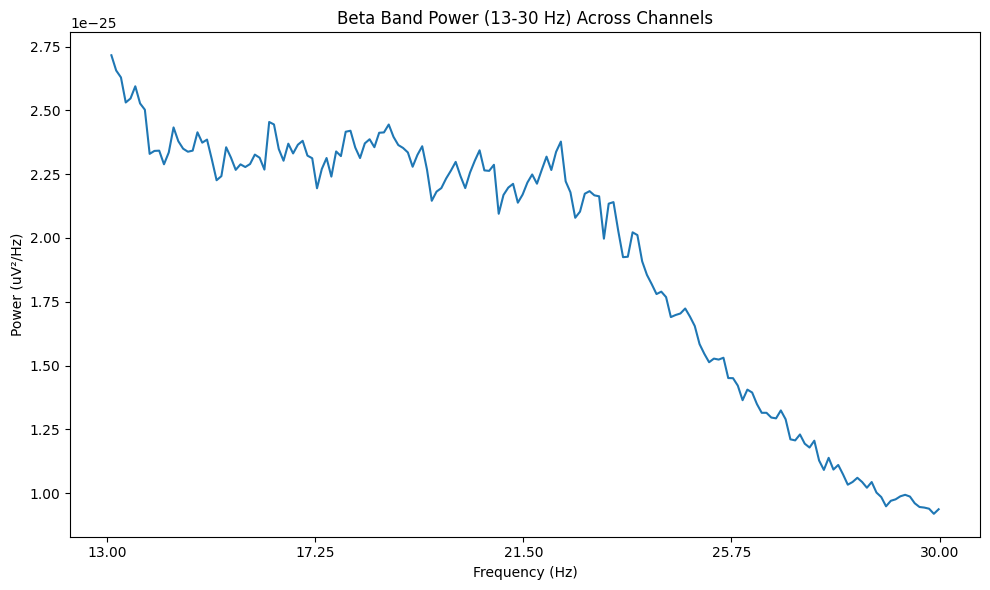

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d69 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d69.head())
print(d69.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d69_clean = d69.replace([np.inf, -np.inf], np.nan)
d69_clean = d69_clean.fillna(d69_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d69_scaled = pd.DataFrame(
    scaler.fit_transform(d69_clean),
    columns=d69_clean.columns,
    index=d69_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d69_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d69_scaled.index,
    columns=d69_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d69_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df69 = d69_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df69["Pd_indicator_meg"] = 0

print("\nShape of df5:", df69.shape)
print(df69.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768, df69], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3765    4.022120             0.062156          2.624821e-12  0.784783   
3766    4.201843             0.059498          2.394132e-12  0.794106   
3767    4.105991             0.060887          1.384214e-13  0.781132   
3768    4.197235             0.059563          2.522434e-12  0.797865   
3769    4.205530             0.059446          

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869.to_csv('/content/drive/MyDrive/combined_features_upto_sub069_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869 preserved.")


RAM Used After Cleanup: 1.11 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869 preserved.


sub-70

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-70'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-070_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-070_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-070_coordsystem.json', 'sub-070_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-070_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-070_task-go_run-1_proc-tsss+mc_events.json', 'sub-070_task-go_run-1_proc-tsss+mc_meg.json', 'sub-070_task-noise_proc-tsss_meg.fif', 'sub-070_task-noise_proc-tsss_channels.tsv', 'sub-070_task-noise_proc-tsss_meg.json', 'sub-070_task-passive_run-1_proc-tsss+mc_events.json', 'sub-070_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-070_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-070_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-070_task-rest_run-1_proc-tsss+mc_events.json', 'sub-070_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-070_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-070_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-070_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-070_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-070_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-070_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-070_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-070_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-70/meg/sub-070_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-70/meg/sub-070_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 123000 ... 1205999 =    123.000 ...  1205.999 secs
Ready.
Reading 0 ... 1082999  =      0.000 ...  1082.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


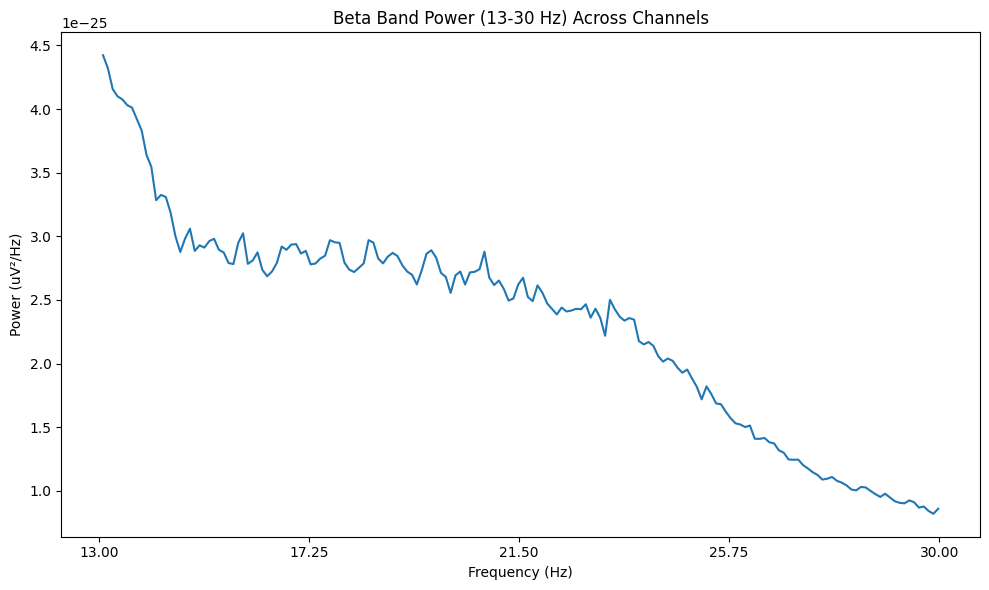

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d70 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d70.head())
print(d70.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d70_clean = d70.replace([np.inf, -np.inf], np.nan)
d70_clean = d70_clean.fillna(d70_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d70_scaled = pd.DataFrame(
    scaler.fit_transform(d70_clean),
    columns=d70_clean.columns,
    index=d70_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d70_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d70_scaled.index,
    columns=d70_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d70_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df70 = d70_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df70["Pd_indicator_meg"] = 1

print("\nShape of df5:", df70.shape)
print(df70.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869, df70], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3823    4.164358             0.060033          2.491326e-12  0.745421   
3824    4.108033             0.060856          2.362846e-12  0.819183   
3825    4.235457             0.059026          1.363079e-13  0.744858   
3826    4.188366             0.059689          2.303049e-12  0.789291   
3827    4.266851             0.058591        

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970.to_csv('/content/drive/MyDrive/combined_features_upto_sub070_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970 preserved.")


RAM Used After Cleanup: 1.11 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970 preserved.


sub-71

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import pandas as pd

previous_df1 = pd.read_csv('/content/drive/MyDrive/combined_features_upto_sub070_21.csv')

print("Loaded previous shape:", previous_df1.shape)


Loaded previous shape: (3828, 22)


In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-71'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-071_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-071_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-071_task-noise_proc-tsss_meg.fif', 'sub-071_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-071_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-071_task-rest_run-1_proc-tsss+mc_events.json', 'sub-071_coordsystem.json', 'sub-071_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-071_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-071_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-071_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-071_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-071_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-071_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-071_task-passive_run-1_proc-tsss+mc_events.json', 'sub-071_task-noise_proc-tsss_channels.tsv', 'sub-071_task-go_run-1_proc-tsss+mc_meg.json', 'sub-071_task-noise_proc-tsss_meg.json', 'sub-071_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-071_task-go_run-1_proc-tsss+mc_events.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-071_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-071_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-071_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-071_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 88.0 MB/s eta 0:00:00

Found .fif file: /content/drive/MyDrive/sub-71/meg/sub-071_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-71/meg/sub-071_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 21000 ... 1098999 =     21.000 ...  1098.999 secs
Ready.
Reading 0 ... 1077999  =      0.000 ...  1077.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


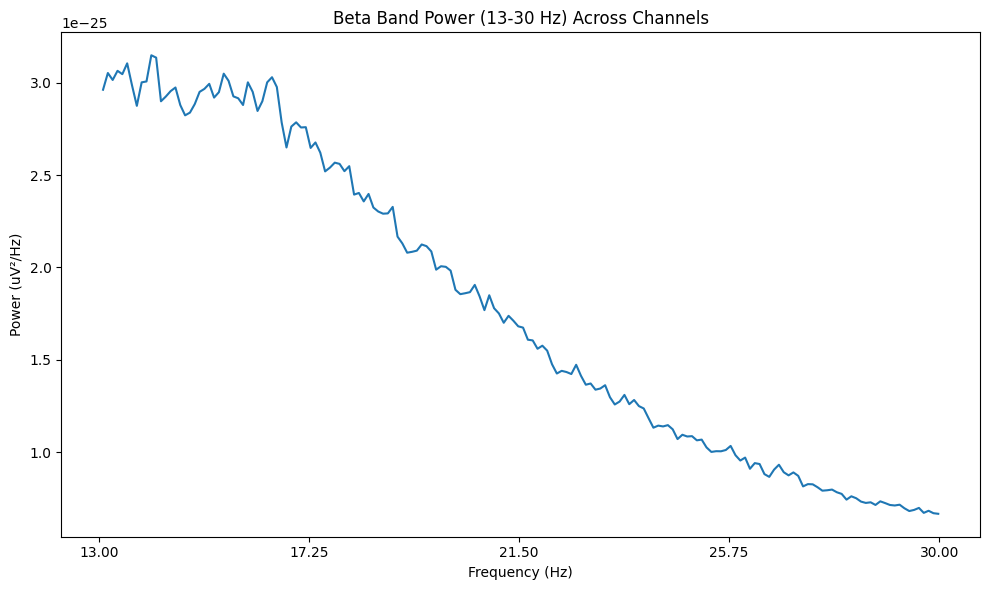

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d71 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d71.head())
print(d71.shape)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.2/115.2 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 85.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 24.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.5/130.5 kB 8.7 MB/s eta 0:00:00
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.12

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d71_clean = d71.replace([np.inf, -np.inf], np.nan)
d71_clean = d71_clean.fillna(d71_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d71_scaled = pd.DataFrame(
    scaler.fit_transform(d71_clean),
    columns=d71_clean.columns,
    index=d71_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d71_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d71_scaled.index,
    columns=d71_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d71_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df71 = d71_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df71["Pd_indicator_meg"] = 0

print("\nShape of df5:", df71.shape)
print(df71.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071 = pd.concat([previous_df1, df71], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3881    4.295918             0.058169          3.041840e-12  0.725975   
3882    4.320037             0.057861          2.812766e-12  0.736341   
3883    4.256030             0.058740          1.491245e-13  0.728720   
3884    4.262523             0.058641          3.044387e-12  0.746460   
3885    4.313544             0.057927      

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071.to_csv('/content/drive/MyDrive/combined_features_upto_sub071_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071 preserved.")


RAM Used After Cleanup: 0.97 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071 preserved.


sub-72

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-72'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-072_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-072_coordsystem.json', 'sub-072_task-go_run-1_proc-tsss+mc_events.json', 'sub-072_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-072_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-072_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-072_task-noise_proc-tsss_channels.tsv', 'sub-072_task-go_run-1_proc-tsss+mc_meg.json', 'sub-072_task-noise_proc-tsss_meg.fif', 'sub-072_task-noise_proc-tsss_meg.json', 'sub-072_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-072_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-072_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-072_task-passive_run-1_proc-tsss+mc_events.json', 'sub-072_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-072_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-072_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-072_task-rest_run-1_proc-tsss+mc_events.json', 'sub-072_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-072_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-072_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-072_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-072_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-072_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-72/meg/sub-072_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-72/meg/sub-072_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 64000 ... 1144999 =     64.000 ...  1144.999 secs
Ready.
Reading 0 ... 1080999  =      0.000 ...  1080.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


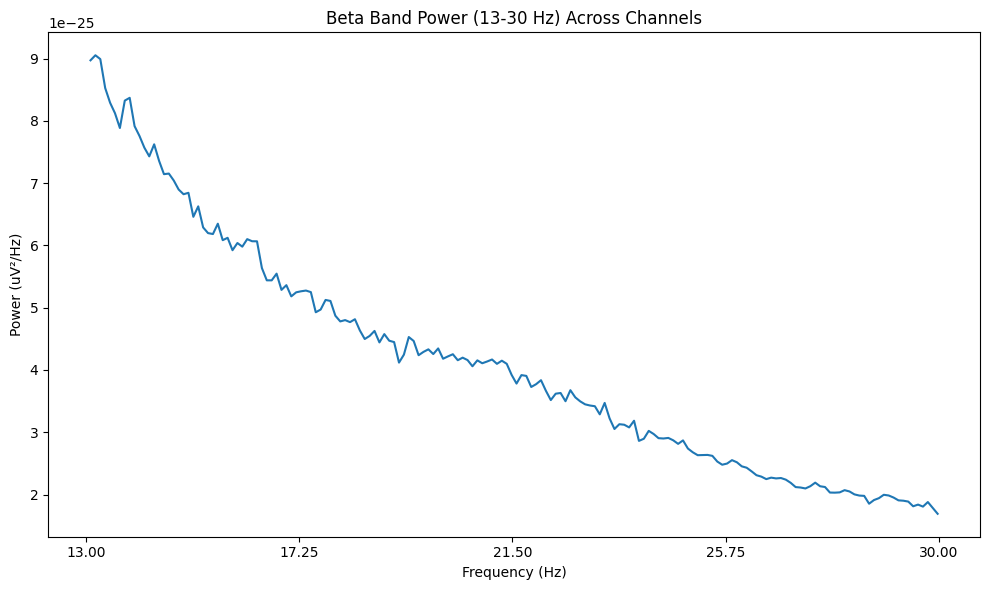

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d72 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d72.head())
print(d72.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d72_clean = d72.replace([np.inf, -np.inf], np.nan)
d72_clean = d72_clean.fillna(d72_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d72_scaled = pd.DataFrame(
    scaler.fit_transform(d72_clean),
    columns=d72_clean.columns,
    index=d72_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d72_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d72_scaled.index,
    columns=d72_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d72_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df72 = d72_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df72["Pd_indicator_meg"] = 0

print("\nShape of df5:", df72.shape)
print(df72.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071, df72], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3939    4.211841             0.059342          3.607243e-12  0.785113   
3940    4.398705             0.056826          3.812718e-12  0.777455   
3941    4.220167             0.059239          2.000985e-13  0.774652   
3942    4.385754             0.057003          3.710473e-12  0.751931   
3943    4.408881             0.056693    

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172.to_csv('/content/drive/MyDrive/combined_features_upto_sub072_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172 preserved.")


RAM Used After Cleanup: 0.97 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172 preserved.


sub-73

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-73'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-073_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-073_coordsystem.json', 'sub-073_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-073_task-go_run-1_proc-tsss+mc_events.json', 'sub-073_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-073_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-073_task-noise_proc-tsss_meg.fif', 'sub-073_task-go_run-1_proc-tsss+mc_meg.json', 'sub-073_task-noise_proc-tsss_channels.tsv', 'sub-073_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-073_task-passive_run-1_proc-tsss+mc_events.json', 'sub-073_task-noise_proc-tsss_meg.json', 'sub-073_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-073_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-073_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-073_task-rest_run-1_proc-tsss+mc_events.json', 'sub-073_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-073_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-073_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-073_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-073_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-073_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-073_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-073_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-73/meg/sub-073_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-73/meg/sub-073_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 88000 ... 1162999 =     88.000 ...  1162.999 secs
Ready.
Reading 0 ... 1074999  =      0.000 ...  1074.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


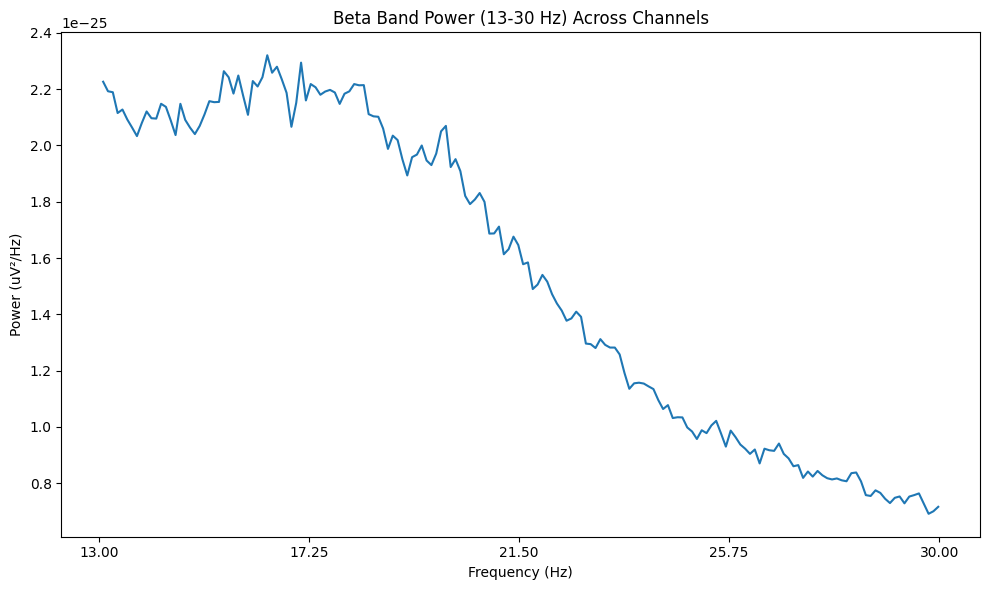

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d73 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d73.head())
print(d73.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d73_clean = d73.replace([np.inf, -np.inf], np.nan)
d73_clean = d73_clean.fillna(d73_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d73_scaled = pd.DataFrame(
    scaler.fit_transform(d73_clean),
    columns=d73_clean.columns,
    index=d73_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d73_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d73_scaled.index,
    columns=d73_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d73_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df73 = d73_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df73["Pd_indicator_meg"] = 0

print("\nShape of df5:", df73.shape)
print(df73.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172, df73], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
3997    4.066047             0.061485          1.884689e-12  0.806004   
3998    4.276279             0.058462          1.771671e-12  0.751970   
3999    4.204651             0.059458          1.183440e-13  0.767710   
4000    4.280000             0.058411          1.960292e-12  0.765153   
4001    4.133953             0.060475  

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273.to_csv('/content/drive/MyDrive/combined_features_upto_sub073_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273 preserved.")


RAM Used After Cleanup: 0.97 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273 preserved.


sub-74

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

previous_df2 = pd.read_csv('/content/drive/MyDrive/combined_features_upto_sub073_21.csv')

print("Loaded previous shape:", previous_df2.shape)


Loaded previous shape: (4002, 22)


In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-74'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-074_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-074_task-go_run-1_proc-tsss+mc_events.json', 'sub-074_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-074_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-074_coordsystem.json', 'sub-074_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-074_task-noise_proc-tsss_meg.fif', 'sub-074_task-go_run-1_proc-tsss+mc_meg.json', 'sub-074_task-noise_proc-tsss_channels.tsv', 'sub-074_task-noise_proc-tsss_meg.json', 'sub-074_task-passive_run-1_proc-tsss+mc_events.json', 'sub-074_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-074_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-074_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-074_task-rest_run-1_proc-tsss+mc_events.json', 'sub-074_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-074_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-074_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-074_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-074_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-074_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-074_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-074_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-074_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-74/meg/sub-074_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-74/meg/sub-074_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 66000 ... 1146999 =     66.000 ...  1146.999 secs
Ready.
Reading 0 ... 1080999  =      0.000 ...  1080.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


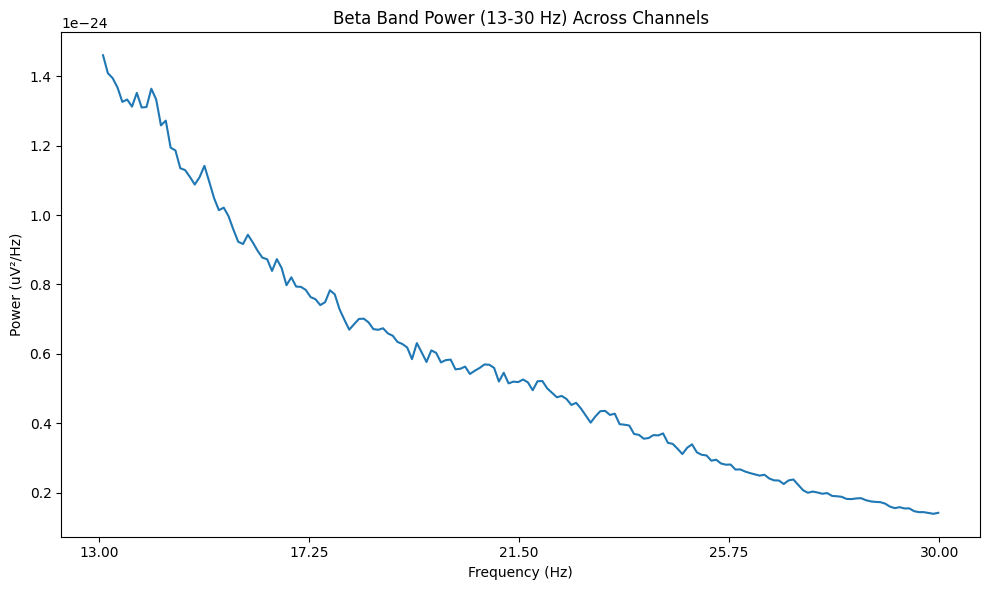

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d74 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d74.head())
print(d74.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d74_clean = d74.replace([np.inf, -np.inf], np.nan)
d74_clean = d74_clean.fillna(d74_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d74_scaled = pd.DataFrame(
    scaler.fit_transform(d74_clean),
    columns=d74_clean.columns,
    index=d74_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d74_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d74_scaled.index,
    columns=d74_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d74_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df74 = d74_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df74["Pd_indicator_meg"] = 0

print("\nShape of df5:", df74.shape)
print(df74.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374 = pd.concat([previous_df2, df74], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
4055    3.852914             0.064886          3.805647e-12  0.838302   
4056    3.934320             0.063543          3.680721e-12  0.823662   
4057    3.777058             0.066189          2.287797e-13  0.868879   
4058    3.884366             0.064361          4.157620e-12  0.816338   
4059    3.770583             0.066303

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374.to_csv('/content/drive/MyDrive/combined_features_upto_sub074_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374 preserved.")


RAM Used After Cleanup: 0.99 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374 preserved.


sub-75

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-75'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-075_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-075_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-075_task-go_run-1_proc-tsss+mc_events.json', 'sub-075_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-075_coordsystem.json', 'sub-075_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-075_task-go_run-1_proc-tsss+mc_meg.json', 'sub-075_task-noise_proc-tsss_channels.tsv', 'sub-075_task-noise_proc-tsss_meg.fif', 'sub-075_task-noise_proc-tsss_meg.json', 'sub-075_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-075_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-075_task-passive_run-1_proc-tsss+mc_events.json', 'sub-075_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-075_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-075_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-075_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-075_task-rest_run-1_proc-tsss+mc_events.json', 'sub-075_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-075_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-075_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-075_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-075_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-075_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-75/meg/sub-075_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-75/meg/sub-075_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 120000 ... 1195999 =    120.000 ...  1195.999 secs
Ready.
Reading 0 ... 1075999  =      0.000 ...  1075.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


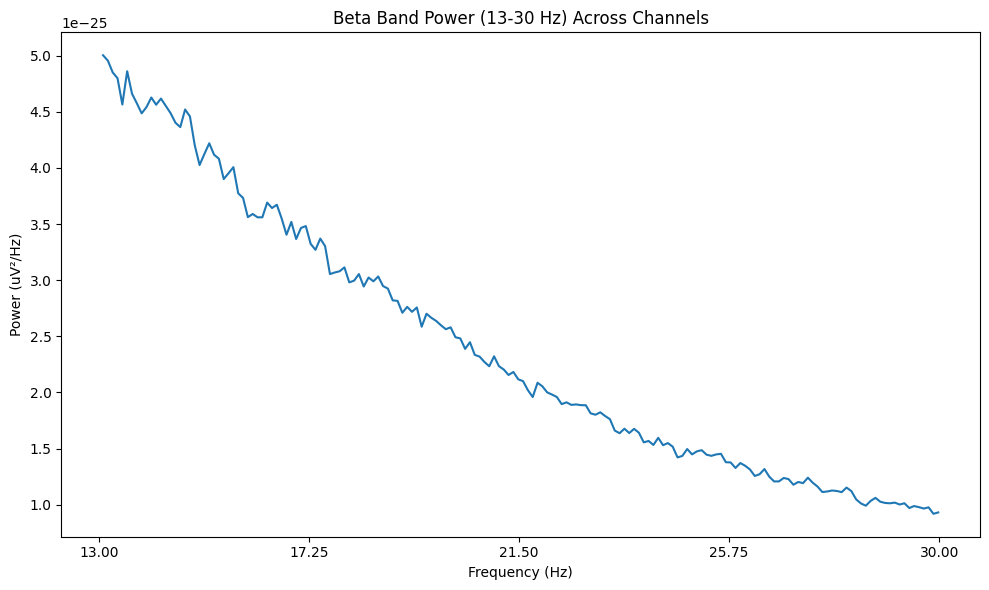

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d75 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d75.head())
print(d75.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d75_clean = d75.replace([np.inf, -np.inf], np.nan)
d75_clean = d75_clean.fillna(d75_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d75_scaled = pd.DataFrame(
    scaler.fit_transform(d75_clean),
    columns=d75_clean.columns,
    index=d75_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d75_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d75_scaled.index,
    columns=d75_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d75_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df75 = d75_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df75["Pd_indicator_meg"] = 1

print("\nShape of df5:", df75.shape)
print(df75.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374, df75], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
4113    3.956320             0.063190          2.840136e-12  0.825285   
4114    3.866171             0.064663          2.983981e-12  0.923941   
4115    4.037175             0.061924          1.613291e-13  0.807380   
4116    3.854089             0.064866          3.254491e-12  0.908554   
4117    4.131041             0.0605

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475.to_csv('/content/drive/MyDrive/combined_features_upto_sub075_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475 preserved.")


RAM Used After Cleanup: 0.98 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475 preserved.


sub-76

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-76'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-076_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-076_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-076_coordsystem.json', 'sub-076_task-go_run-1_proc-tsss+mc_events.json', 'sub-076_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-076_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-076_task-go_run-1_proc-tsss+mc_meg.json', 'sub-076_task-noise_proc-tsss_meg.fif', 'sub-076_task-noise_proc-tsss_channels.tsv', 'sub-076_task-noise_proc-tsss_meg.json', 'sub-076_task-passive_run-1_proc-tsss+mc_events.json', 'sub-076_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-076_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-076_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-076_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-076_task-rest_run-1_proc-tsss+mc_events.json', 'sub-076_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-076_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-076_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-076_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-076_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-076_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-076_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-076_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-76/meg/sub-076_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-76/meg/sub-076_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 101000 ... 1176999 =    101.000 ...  1176.999 secs
Ready.
Reading 0 ... 1075999  =      0.000 ...  1075.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


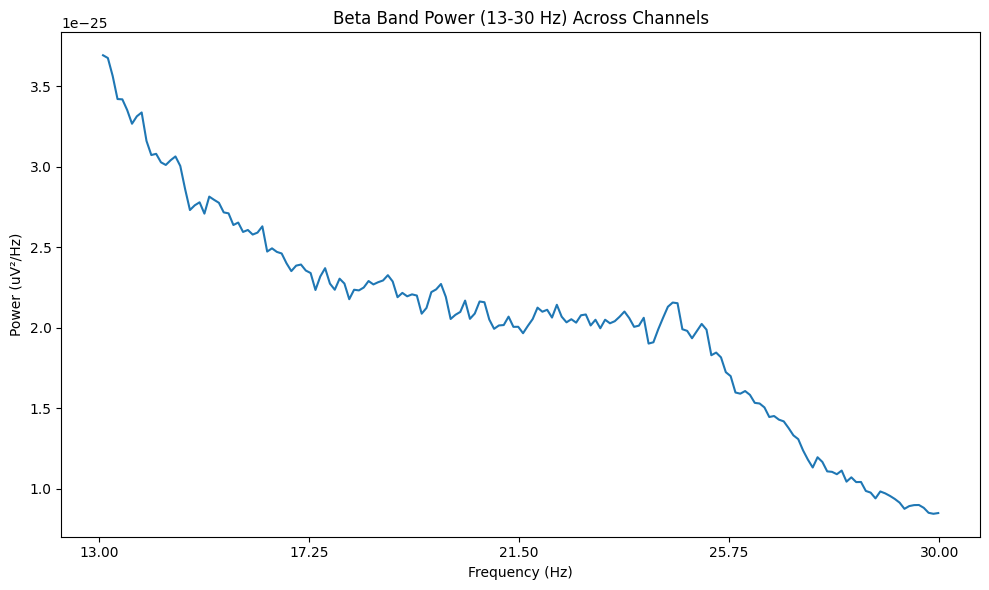

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d76 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d76.head())
print(d76.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d76_clean = d76.replace([np.inf, -np.inf], np.nan)
d76_clean = d76_clean.fillna(d76_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d76_scaled = pd.DataFrame(
    scaler.fit_transform(d76_clean),
    columns=d76_clean.columns,
    index=d76_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d76_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d76_scaled.index,
    columns=d76_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d76_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df76 = d76_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df76["Pd_indicator_meg"] = 1

print("\nShape of df5:", df76.shape)
print(df76.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475, df76], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
4171    4.130112             0.060531          3.239793e-12  0.755884   
4172    4.373606             0.057161          2.976473e-12  0.741062   
4173    4.326208             0.057764          1.548627e-13  0.764057   
4174    4.235130             0.059030          3.073984e-12  0.764754   
4175    4.170074             0.05

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576.to_csv('/content/drive/MyDrive/combined_features_upto_sub076_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576 preserved.")


RAM Used After Cleanup: 0.99 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576 preserved.


sub-77

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

previous_df = pd.read_csv('/content/drive/MyDrive/combined_features_upto_sub076_21.csv')

print("Loaded previous shape:", previous_df.shape)


Loaded previous shape: (4176, 22)


In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-77'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-077_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-077_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-077_coordsystem.json', 'sub-077_task-go_run-1_proc-tsss+mc_events.json', 'sub-077_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-077_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-077_task-go_run-1_proc-tsss+mc_meg.json', 'sub-077_task-noise_proc-tsss_channels.tsv', 'sub-077_task-noise_proc-tsss_meg.fif', 'sub-077_task-noise_proc-tsss_meg.json', 'sub-077_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-077_task-passive_run-1_proc-tsss+mc_events.json', 'sub-077_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-077_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-077_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-077_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-077_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-077_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-077_task-rest_run-1_proc-tsss+mc_events.json', 'sub-077_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-077_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-077_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-077_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-077_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-77/meg/sub-077_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-77/meg/sub-077_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 54000 ... 1130999 =     54.000 ...  1130.999 secs
Ready.
Reading 0 ... 1076999  =      0.000 ...  1076.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


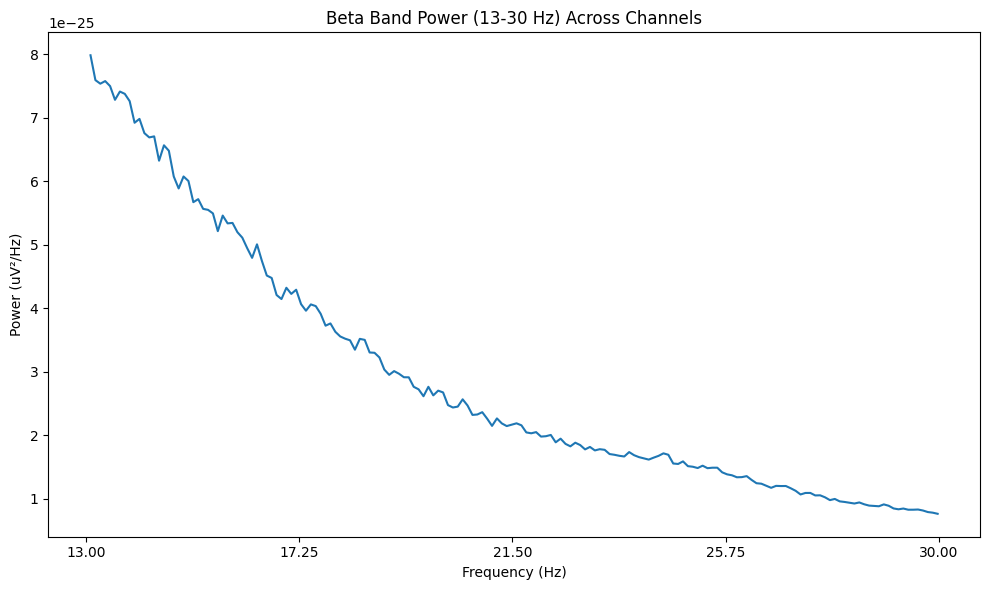

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d77 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d77.head())
print(d77.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d77_clean = d77.replace([np.inf, -np.inf], np.nan)
d77_clean = d77_clean.fillna(d77_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d77_scaled = pd.DataFrame(
    scaler.fit_transform(d77_clean),
    columns=d77_clean.columns,
    index=d77_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d77_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d77_scaled.index,
    columns=d77_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d77_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df77 = d77_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df77["Pd_indicator_meg"] = 1

print("\nShape of df5:", df77.shape)
print(df77.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576, df77], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
4229    4.052925             0.061684          2.872458e-12  0.928543   
4230    4.070566             0.061417          2.917097e-12  0.922384   
4231    4.098422             0.060999          1.663070e-13  0.919706   
4232    3.973073             0.062924          3.496691e-12  0.893666   
4233    4.128134             0.

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677.to_csv('/content/drive/MyDrive/combined_features_upto_sub077_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677 preserved.")


RAM Used After Cleanup: 0.98 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677 preserved.


sub-78

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-78'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-078_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-078_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-078_coordsystem.json', 'sub-078_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-078_task-go_run-1_proc-tsss+mc_events.json', 'sub-078_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-078_task-go_run-1_proc-tsss+mc_meg.json', 'sub-078_task-noise_proc-tsss_meg.fif', 'sub-078_task-noise_proc-tsss_channels.tsv', 'sub-078_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-078_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-078_task-passive_run-1_proc-tsss+mc_events.json', 'sub-078_task-noise_proc-tsss_meg.json', 'sub-078_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-078_task-rest_run-1_proc-tsss+mc_events.json', 'sub-078_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-078_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-078_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-078_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-078_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-078_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-078_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-078_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-078_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-78/meg/sub-078_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-78/meg/sub-078_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 68000 ... 1148999 =     68.000 ...  1148.999 secs
Ready.
Reading 0 ... 1080999  =      0.000 ...  1080.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


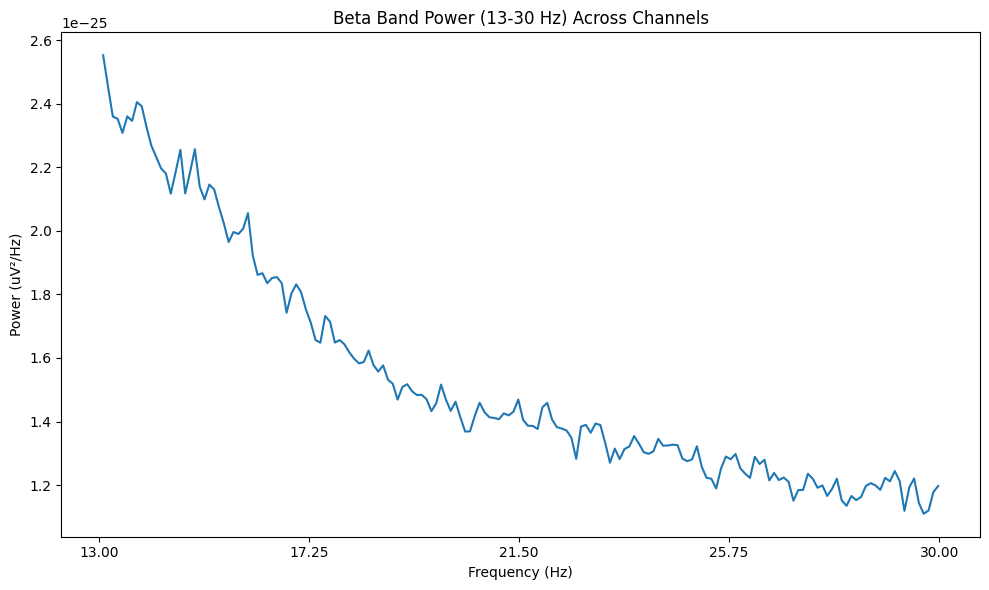

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d78 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d78.head())
print(d78.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d78_clean = d78.replace([np.inf, -np.inf], np.nan)
d78_clean = d78_clean.fillna(d78_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d78_scaled = pd.DataFrame(
    scaler.fit_transform(d78_clean),
    columns=d78_clean.columns,
    index=d78_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d78_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d78_scaled.index,
    columns=d78_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d78_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df78 = d78_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df78["Pd_indicator_meg"] = 0

print("\nShape of df5:", df78.shape)
print(df78.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677, df78], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
4287    4.691027             0.053285          2.714643e-12  0.712634   
4288    4.511563             0.055413          3.000686e-12  0.768431   
4289    4.719704             0.052969          1.423921e-13  0.743931   
4290    4.293247             0.058231          4.123181e-12  0.827785   
4291    4.689177             

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778.to_csv('/content/drive/MyDrive/combined_features_upto_sub078_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778 preserved.")


RAM Used After Cleanup: 0.98 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778 preserved.


sub-79

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-79'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-079_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-079_coordsystem.json', 'sub-079_task-go_run-1_proc-tsss+mc_events.json', 'sub-079_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-079_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-079_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-079_task-noise_proc-tsss_meg.fif', 'sub-079_task-go_run-1_proc-tsss+mc_meg.json', 'sub-079_task-noise_proc-tsss_channels.tsv', 'sub-079_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-079_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-079_task-passive_run-1_proc-tsss+mc_events.json', 'sub-079_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-079_task-noise_proc-tsss_meg.json', 'sub-079_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-079_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-079_task-rest_run-1_proc-tsss+mc_events.json', 'sub-079_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-079_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-079_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-079_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-079_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-079_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-079_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-79/meg/sub-079_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-79/meg/sub-079_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 97000 ... 1174999 =     97.000 ...  1174.999 secs
Ready.
Reading 0 ... 1077999  =      0.000 ...  1077.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


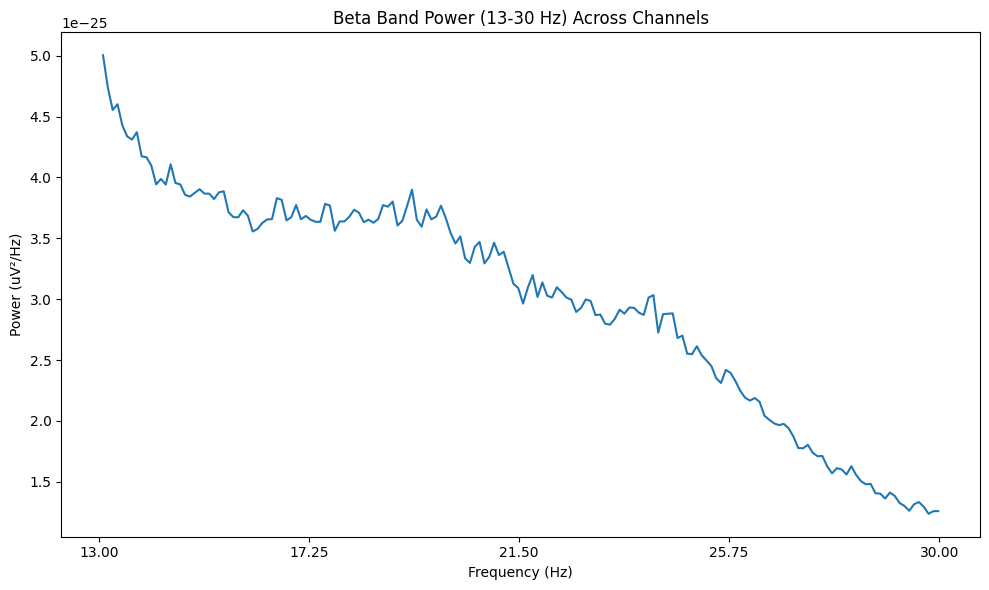

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d79 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d79.head())
print(d79.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d79_clean = d79.replace([np.inf, -np.inf], np.nan)
d79_clean = d79_clean.fillna(d79_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d79_scaled = pd.DataFrame(
    scaler.fit_transform(d79_clean),
    columns=d79_clean.columns,
    index=d79_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d79_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d79_scaled.index,
    columns=d79_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d79_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df79 = d79_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df79["Pd_indicator_meg"] = 0

print("\nShape of df5:", df79.shape)
print(df79.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778, df79], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
4345    4.070501             0.061418          3.274446e-12  0.767512   
4346    4.061224             0.061558          3.087265e-12  0.802217   
4347    4.168831             0.059969          1.760135e-13  0.764673   
4348    4.025974             0.062097          3.251556e-12  0.810401   
4349    4.022263           

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879.to_csv('/content/drive/MyDrive/combined_features_upto_sub079_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879 preserved.")


RAM Used After Cleanup: 0.97 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879 preserved.


sub-80

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-80'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-080_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-080_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-080_coordsystem.json', 'sub-080_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-080_task-go_run-1_proc-tsss+mc_events.json', 'sub-080_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-080_task-go_run-1_proc-tsss+mc_meg.json', 'sub-080_task-noise_proc-tsss_channels.tsv', 'sub-080_task-noise_proc-tsss_meg.fif', 'sub-080_task-noise_proc-tsss_meg.json', 'sub-080_task-passive_run-1_proc-tsss+mc_events.json', 'sub-080_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-080_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-080_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-080_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-080_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-080_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-080_task-rest_run-1_proc-tsss+mc_events.json', 'sub-080_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-080_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-080_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-080_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-080_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-080_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-80/meg/sub-080_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-80/meg/sub-080_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 87000 ... 1162999 =     87.000 ...  1162.999 secs
Ready.
Reading 0 ... 1075999  =      0.000 ...  1075.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


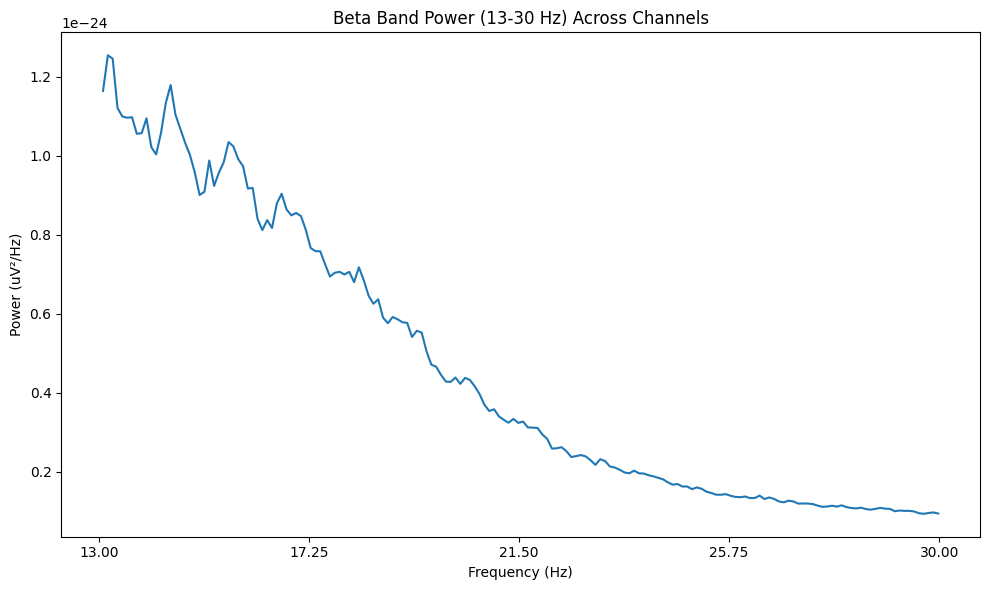

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d80 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d80.head())
print(d80.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d80_clean = d80.replace([np.inf, -np.inf], np.nan)
d80_clean = d80_clean.fillna(d80_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d80_scaled = pd.DataFrame(
    scaler.fit_transform(d80_clean),
    columns=d80_clean.columns,
    index=d80_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d80_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d80_scaled.index,
    columns=d80_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d80_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df80 = d80_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df80["Pd_indicator_meg"] = 1

print("\nShape of df5:", df80.shape)
print(df80.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879, df80], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
4403    3.286245             0.076075          5.202129e-12  0.808073   
4404    3.131970             0.079822          5.206744e-12  1.120285   
4405    3.308550             0.075562          3.022590e-13  0.997103   
4406    3.029740             0.082515          5.651250e-12  1.157787   
4407    3.233271         

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980.to_csv('/content/drive/MyDrive/combined_features_upto_sub080_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980 preserved.")


RAM Used After Cleanup: 0.96 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980 preserved.


sub-81

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-81'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-081_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-081_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-081_coordsystem.json', 'sub-081_task-go_run-1_proc-tsss+mc_events.json', 'sub-081_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-081_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-081_task-go_run-1_proc-tsss+mc_meg.json', 'sub-081_task-noise_proc-tsss_channels.tsv', 'sub-081_task-noise_proc-tsss_meg.fif', 'sub-081_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-081_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-081_task-passive_run-1_proc-tsss+mc_events.json', 'sub-081_task-noise_proc-tsss_meg.json', 'sub-081_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-081_task-rest_run-1_proc-tsss+mc_events.json', 'sub-081_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-081_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-081_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-081_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-081_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-081_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-081_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-081_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-081_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-81/meg/sub-081_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-81/meg/sub-081_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 65000 ... 1164999 =     65.000 ...  1164.999 secs
Ready.
Reading 0 ... 1099999  =      0.000 ...  1099.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


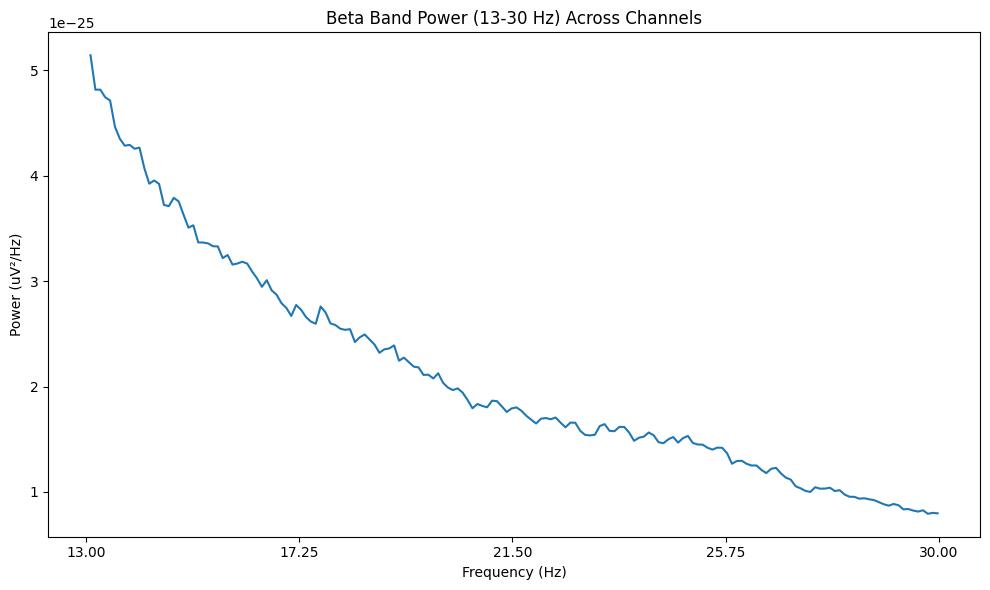

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d81 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d81.head())
print(d81.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d81_clean = d81.replace([np.inf, -np.inf], np.nan)
d81_clean = d81_clean.fillna(d81_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d81_scaled = pd.DataFrame(
    scaler.fit_transform(d81_clean),
    columns=d81_clean.columns,
    index=d81_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d81_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d81_scaled.index,
    columns=d81_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d81_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df81 = d81_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df81["Pd_indicator_meg"] = 0

print("\nShape of df5:", df81.shape)
print(df81.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980, df81], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
4461    4.463636             0.056008          2.129939e-12  0.747941   
4462    4.583636             0.054532          2.219264e-12  0.761261   
4463    4.414545             0.056631          1.257336e-13  0.779395   
4464    4.558182             0.054846          2.425106e-12  0.780151   
4465    4.452727       

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081.to_csv('/content/drive/MyDrive/combined_features_upto_sub081_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081 preserved.")


RAM Used After Cleanup: 0.97 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081 preserved.


sub-82

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

previous_df = pd.read_csv('/content/drive/MyDrive/combined_features_upto_sub081_21.csv')

print("Loaded previous shape:", previous_df.shape)


Loaded previous shape: (4466, 22)


In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-82'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-082_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-082_coordsystem.json', 'sub-082_task-go_run-1_proc-tsss+mc_events.json', 'sub-082_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-082_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-082_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-082_task-noise_proc-tsss_meg.fif', 'sub-082_task-go_run-1_proc-tsss+mc_meg.json', 'sub-082_task-noise_proc-tsss_channels.tsv', 'sub-082_task-noise_proc-tsss_meg.json', 'sub-082_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-082_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-082_task-passive_run-1_proc-tsss+mc_events.json', 'sub-082_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-082_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-082_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-082_task-rest_run-1_proc-tsss+mc_events.json', 'sub-082_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-082_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-082_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-082_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-082_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-082_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-082_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-82/meg/sub-082_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-82/meg/sub-082_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 80000 ... 1151999 =     80.000 ...  1151.999 secs
Ready.
Reading 0 ... 1071999  =      0.000 ...  1071.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


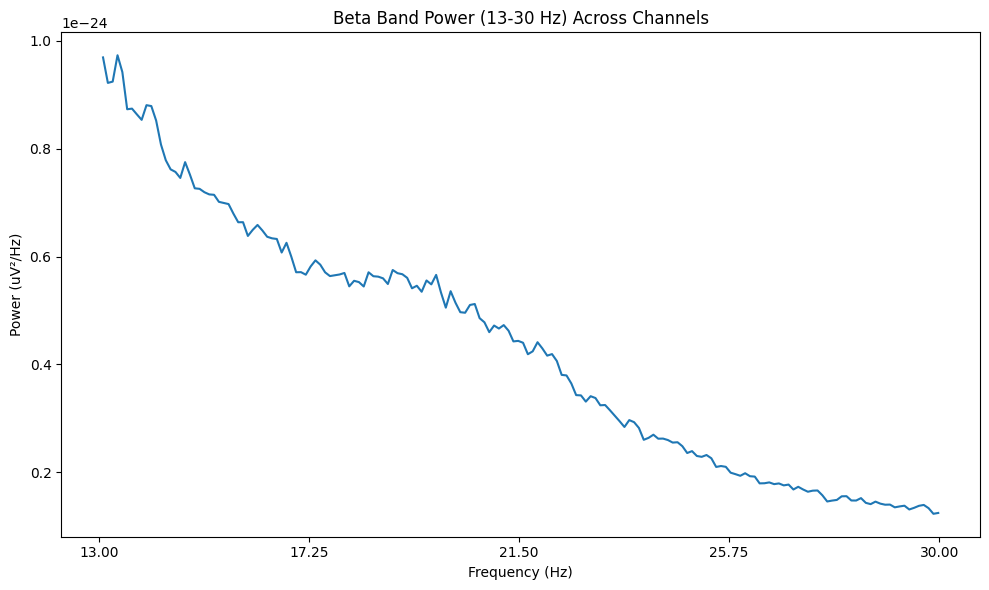

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d82 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d82.head())
print(d82.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d82_clean = d82.replace([np.inf, -np.inf], np.nan)
d82_clean = d82_clean.fillna(d82_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d82_scaled = pd.DataFrame(
    scaler.fit_transform(d82_clean),
    columns=d82_clean.columns,
    index=d82_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d82_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d82_scaled.index,
    columns=d82_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d82_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df82 = d82_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df82["Pd_indicator_meg"] = 1

print("\nShape of df5:", df82.shape)
print(df82.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182 = pd.concat([previous_df, df82], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
4519    3.659515             0.068315          4.513733e-12  0.819687   
4520    3.760261             0.066485          4.369819e-12  0.823675   
4521    3.735075             0.066933          2.528020e-13  0.818827   
4522    3.761194             0.066468          4.782205e-12  0.836213   
4523    3.617537     

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182.to_csv('/content/drive/MyDrive/combined_features_upto_sub082_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182 preserved.")


RAM Used After Cleanup: 0.51 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182 preserved.


sub-83

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-83'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-083_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-083_coordsystem.json', 'sub-083_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-083_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-083_task-go_run-1_proc-tsss+mc_events.json', 'sub-083_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-083_task-noise_proc-tsss_channels.tsv', 'sub-083_task-go_run-1_proc-tsss+mc_meg.json', 'sub-083_task-noise_proc-tsss_meg.fif', 'sub-083_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-083_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-083_task-noise_proc-tsss_meg.json', 'sub-083_task-passive_run-1_proc-tsss+mc_events.json', 'sub-083_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-083_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-083_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-083_task-rest_run-1_proc-tsss+mc_events.json', 'sub-083_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-083_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-083_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-083_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-083_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-083_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-083_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-83/meg/sub-083_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import os
import mne
import numpy as np
from mne.preprocessing import ICA
import gc

task_name = "passive"

if task_name in fif_files_by_task:

    print(f"\n========== Processing Task: {task_name.upper()} ==========")

    for fif_file in fif_files_by_task[task_name]:

        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"Loading file: {fif_file_path}")

        # Load raw
        raw = mne.io.read_raw_fif(
            fif_file_path,
            preload=True,
            verbose=False
        )

        # Pick only MEG
        raw.pick("meg")   # modern version (no warning)

        # Downsample
        raw.resample(200, npad="auto")

        # Filter
        raw.filter(
            l_freq=1.0,
            h_freq=40.0,
            fir_design="firwin",
            n_jobs=1
        )

        # Fix NaN/Inf
        raw._data[~np.isfinite(raw._data)] = 0.0

        print("NaN count:", np.isnan(raw._data).sum())
        print("Inf count:", np.isinf(raw._data).sum())

        # ICA
        ica = ICA(
            n_components=20,
            method="fastica",
            random_state=42,
            max_iter=300
        )

        ica.fit(raw, reject_by_annotation=True, verbose=False)

        print("ICA completed for PASSIVE task")


        del ica
        gc.collect()

else:
    print("Passive task not found in dictionary.")



========== Processing Task: PASSIVE ==========
Loading file: /content/drive/MyDrive/sub-83/meg/sub-083_task-passive_run-1_proc-tsss+mc_meg.fif
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

NaN count: 0
Inf count: 0


/tmp/ipython-input-2696681471.py:53: RuntimeWarning: Using n_components=20 (resulting in n_components_=20) may lead to an unstable mixing matrix estimation because the ratio between the largest (3.1e+02) and smallest (2.9e-30) variances is too large (> 1e6); consider setting n_components=0.999999 or an integer <= 1
  ica.fit(raw, reject_by_annotation=True, verbose=False)


ICA completed for PASSIVE task


Computing Power Spectral Density

Effective window size : 10.240 (s)


/tmp/ipython-input-2166243642.py:5: UserWarning: Zero value in spectrum for channels MEG0223, MEG0232, MEG0431, MEG0531, MEG0722, MEG0741, MEG0813, MEG0942
  psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)


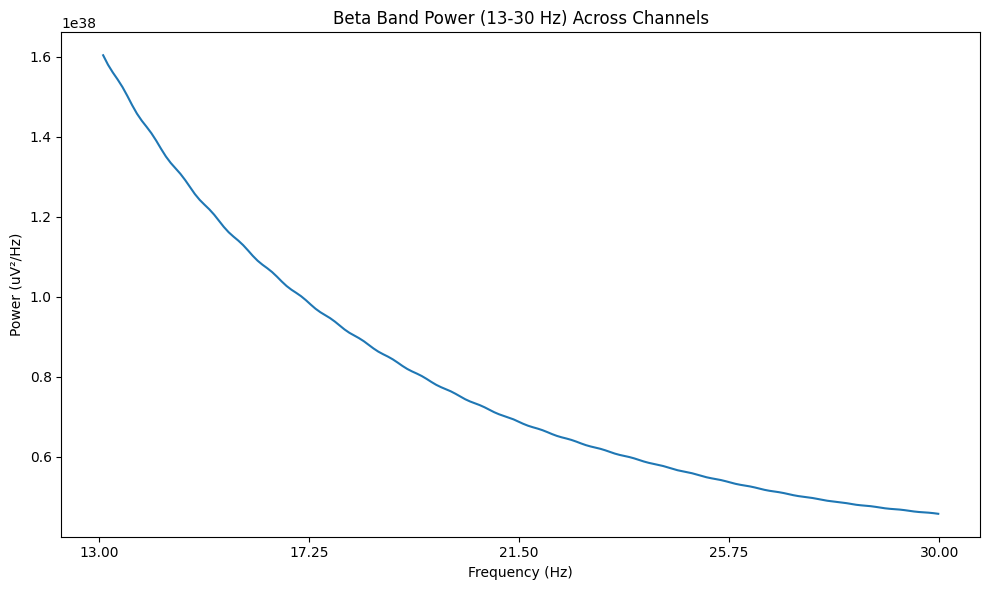

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d83 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d83.head())
print(d83.shape)


Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective window size : 1.280 (s)
Effective wind

Extraction of Top 58 channels

In [ ]:
from scipy.spatial.distance import euclidean

# -------------------------------------------------
# Compute global mean feature vector
# -------------------------------------------------
global_mean = d83.mean(axis=0).values

# -------------------------------------------------
# Compute Euclidean distance of each channel from global mean
# -------------------------------------------------
distances = d83.apply(
    lambda row: euclidean(row.values, global_mean),
    axis=1
)

# -------------------------------------------------
# Sort distances and select TOP 58 channels
# -------------------------------------------------
top_58_channel_names = distances.sort_values(ascending=False).head(58).index

# Get sensor (row) numbers
top_58_channel_numbers = [
    d83.index.get_loc(ch) for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel sensor numbers (row indices):")
print(top_58_channel_numbers)

# -------------------------------------------------
# Extract feature vectors of TOP 58 channels → df4
# -------------------------------------------------
df83 = d83.loc[top_58_channel_names].copy()   # shape → (58, 21)

# -------------------------------------------------
# Add PD indicator column (all 1s)
# -------------------------------------------------
df83['Pd_indicator_meg'] = 1

print("\nTop 58 channel feature matrix with Pd_indicator_meg:")
print(df83.head())
print("Shape of df83:", df83.shape)


Top 58 channel names:
['MEG0233', 'MEG0231', 'MEG1842', 'MEG2013', 'MEG2012', 'MEG1831', 'MEG1823', 'MEG1822', 'MEG1821', 'MEG1413', 'MEG1412', 'MEG1411', 'MEG1343', 'MEG1742', 'MEG1741', 'MEG1733', 'MEG1732', 'MEG1843', 'MEG2023', 'MEG2022', 'MEG2021', 'MEG2131', 'MEG2123', 'MEG2122', 'MEG2011', 'MEG1943', 'MEG1911', 'MEG1933', 'MEG1932', 'MEG2042', 'MEG2041', 'MEG2033', 'MEG1922', 'MEG1921', 'MEG1913', 'MEG1912', 'MEG1941', 'MEG1722', 'MEG1533', 'MEG1532', 'MEG1131', 'MEG1123', 'MEG1122', 'MEG1121', 'MEG1113', 'MEG1841', 'MEG1513', 'MEG1511', 'MEG1443', 'MEG1613', 'MEG1612', 'MEG1611', 'MEG1542', 'MEG1541', 'MEG1112', 'MEG2031', 'MEG1833', 'MEG1832']

Top 58 channel sensor numbers (row indices):
[20, 18, 208, 224, 223, 204, 203, 202, 201, 152, 151, 150, 149, 196, 195, 194, 193, 209, 227, 226, 225, 240, 239, 238, 222, 221, 210, 218, 217, 232, 231, 230, 214, 213, 212, 211, 219, 190, 170, 169, 120, 119, 118, 117, 116, 207, 164, 162, 161, 176, 175, 174, 172, 171, 115, 228, 206, 205]

Top

In [ ]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182, df83], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283):
      Burst Rate (Hz)  Mean Burst Duration (s)  Mean Burst Amplitude  \
0            4.665121                 0.053575          2.652937e-12   
1            4.549165                 0.054948          3.324243e-12   
2            4.752319                 0.052606          1.825711e-12   
3            4.689239                 0.053314          1.826349e-12   
4            4.679963                 0.053419          1.929654e-12   
...               ...                      ...                   ...   
4577         1.184211                 0.005000          2.934890e+03   
4578         4.136591                 0.060248          4.246149e-12   
4579         4.281955                 0.058222          2.304896e-13   
4580         1.184211                 0.005000          2.303770e+05   
4581         1.184211         

In [ ]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283.to_csv(
    '/content/drive/MyDrive/combined_features_upto_sub083_21.csv',
    index=False
)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects (safe version, same style)

try:
    del raw
except NameError:
    pass

try:
    del ica
except NameError:
    pass

try:
    del psd_obj
except NameError:
    pass

try:
    del psds
except NameError:
    pass

try:
    del beta_band_psd
except NameError:
    pass

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283 preserved.")


RAM Used After Cleanup: 0.54 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283 preserved.


sub-84

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import pandas as pd

previous_df = pd.read_csv('/content/drive/MyDrive/combined_features_upto_sub083_21.csv')

print("Loaded previous shape:", previous_df.shape)


Loaded previous shape: (4582, 22)


In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-84'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-084_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-084_coordsystem.json', 'sub-084_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-084_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-084_task-go_run-1_proc-tsss+mc_events.json', 'sub-084_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-084_task-noise_proc-tsss_meg.fif', 'sub-084_task-noise_proc-tsss_channels.tsv', 'sub-084_task-go_run-1_proc-tsss+mc_meg.json', 'sub-084_task-noise_proc-tsss_meg.json', 'sub-084_task-passive_run-1_proc-tsss+mc_events.json', 'sub-084_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-084_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-084_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-084_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-084_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-084_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-084_task-rest_run-1_proc-tsss+mc_events.json', 'sub-084_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-084_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-084_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-084_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-084_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-084_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 95.4 MB/s eta 0:00:00

Found .fif file: /content/drive/MyDrive/sub-84/meg/sub-084_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-84/meg/sub-084_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 71000 ... 1148999 =     71.000 ...  1148.999 secs
Ready.
Reading 0 ... 1077999  =      0.000 ...  1077.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


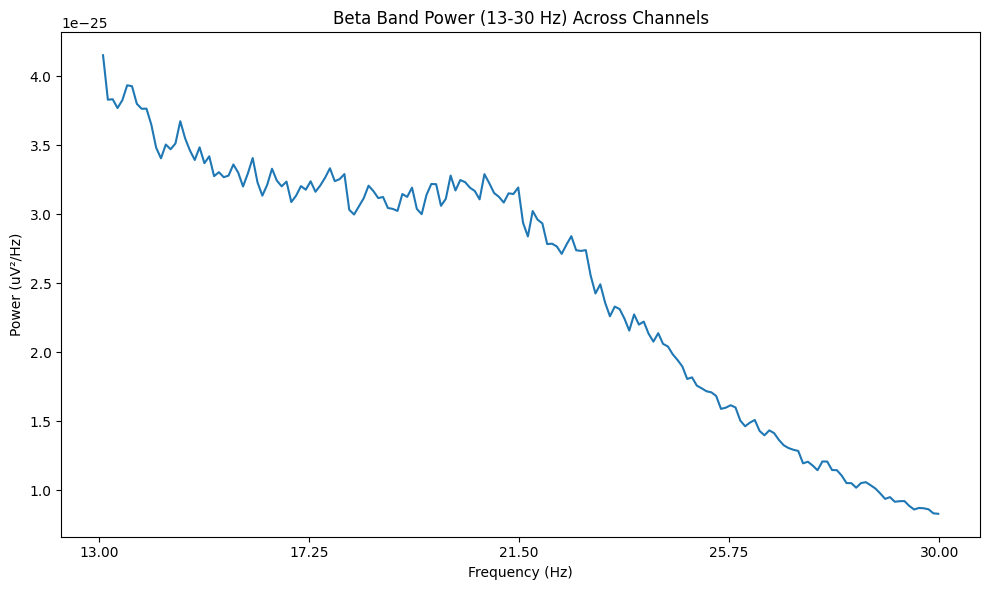

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d84 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d84.head())
print(d84.shape)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.2/115.2 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 74.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 36.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.5/130.5 kB 8.6 MB/s eta 0:00:00
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.12

Extraction of top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d84_clean = d84.replace([np.inf, -np.inf], np.nan)
d84_clean = d84_clean.fillna(d84_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d84_scaled = pd.DataFrame(
    scaler.fit_transform(d84_clean),
    columns=d84_clean.columns,
    index=d84_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d84_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d84_scaled.index,
    columns=d84_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d84_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df84 = d84_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df84["Pd_indicator_meg"] = 1

print("\nShape of df5:", df84.shape)
print(df84.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384 = pd.concat([previous_df, df84], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
4635    4.177180             0.059849          3.150189e-12  0.743241   
4636    4.076067             0.061334          3.115499e-12  0.820029   
4637    3.921150             0.063757          1.945560e-13  0.821202   
4638    4.133581             0.060480          3.294540e-12  0.777020   
4639    4.293135 

In [ ]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384.to_csv('/content/drive/MyDrive/combined_features_upto_sub084_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384 preserved.")


RAM Used After Cleanup: 0.96 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384 preserved.


sub-85

In [ ]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-85'  # Replace with your folder path


In [ ]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-085_scans.tsv', 'meg']


In [ ]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-085_coordsystem.json', 'sub-085_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-085_task-go_run-1_proc-tsss+mc_events.json', 'sub-085_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-085_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-085_task-go_run-1_proc-tsss+mc_meg.json', 'sub-085_task-noise_proc-tsss_channels.tsv', 'sub-085_task-noise_proc-tsss_meg.fif', 'sub-085_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-085_task-noise_proc-tsss_meg.json', 'sub-085_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-085_task-passive_run-1_proc-tsss+mc_events.json', 'sub-085_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-085_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-085_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-085_task-rest_run-1_proc-tsss+mc_events.json', 'sub-085_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-085_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-085_task-rest_run-1_proc-tsss+mc_meg.json']


In [ ]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-085_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-085_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-085_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-085_task-rest_run-1_proc-tsss+mc_meg.fif']


In [ ]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-85/meg/sub-085_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [ ]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-85/meg/sub-085_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 119000 ... 1216999 =    119.000 ...  1216.999 secs
Ready.
Reading 0 ... 1097999  =      0.000 ...  1097.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


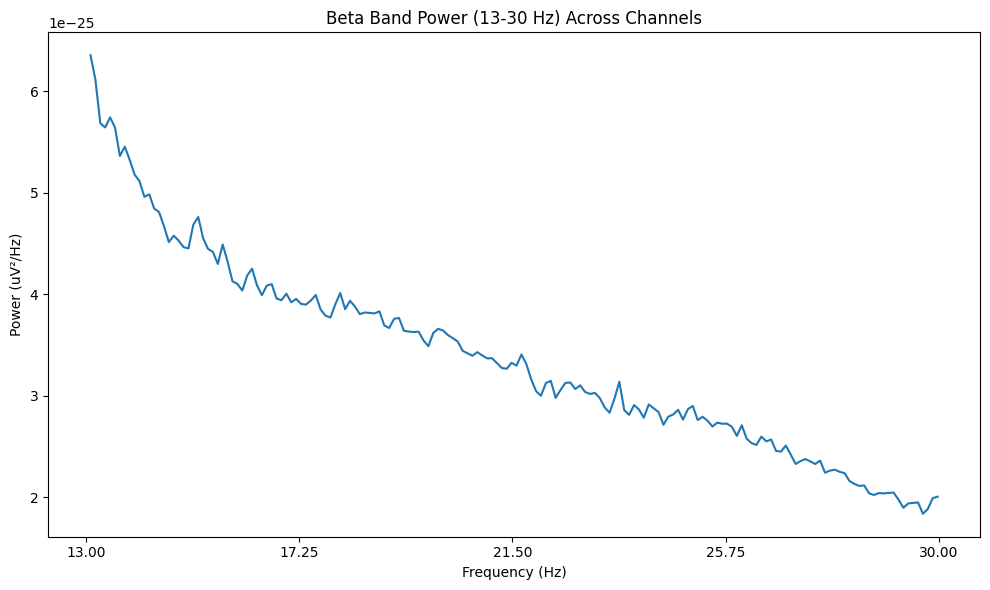

Extracted Beta Band Power (13-30 Hz) successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [ ]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d85 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d85.head())
print(d85.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d85_clean = d85.replace([np.inf, -np.inf], np.nan)
d85_clean = d85_clean.fillna(d85_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d85_scaled = pd.DataFrame(
    scaler.fit_transform(d85_clean),
    columns=d85_clean.columns,
    index=d85_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d85_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d85_scaled.index,
    columns=d85_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d85_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df85 = d85_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df85["Pd_indicator_meg"] = 1

print("\nShape of df5:", df85.shape)
print(df85.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [ ]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384, df85], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
4693    4.106557             0.060878          3.212095e-12  0.820194   
4694    4.105647             0.060892          3.048131e-12  0.871152   
4695    4.245902             0.058880          1.841116e-13  0.799740   
4696    4.093807             0.061068          3.139220e-12  0.855174   
4697    4.09380

In [ ]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485.to_csv('/content/drive/MyDrive/combined_features_upto_sub085_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485 preserved.")


RAM Used After Cleanup: 0.97 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485 preserved.


sub-86

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import pandas as pd

previous_df = pd.read_csv('/content/drive/MyDrive/combined_features_upto_sub085_21.csv')

print("Loaded previous shape:", previous_df.shape)


Loaded previous shape: (4698, 22)


In [4]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-86'  # Replace with your folder path


In [5]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-086_scans.tsv', 'meg']


In [6]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-086_task-go_run-1_proc-tsss+mc_events.json', 'sub-086_coordsystem.json', 'sub-086_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-086_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-086_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-086_task-go_run-1_proc-tsss+mc_meg.json', 'sub-086_task-noise_proc-tsss_meg.fif', 'sub-086_task-noise_proc-tsss_channels.tsv', 'sub-086_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-086_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-086_task-passive_run-1_proc-tsss+mc_events.json', 'sub-086_task-noise_proc-tsss_meg.json', 'sub-086_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-086_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-086_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-086_task-rest_run-1_proc-tsss+mc_events.json', 'sub-086_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-086_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-086_task-rest_run-1_proc-tsss+mc_meg.json']


In [7]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-086_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-086_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-086_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-086_task-rest_run-1_proc-tsss+mc_meg.fif']


In [8]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 55.7 MB/s eta 0:00:00

Found .fif file: /content/drive/MyDrive/sub-86/meg/sub-086_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [9]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-86/meg/sub-086_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 66000 ... 1158999 =     66.000 ...  1158.999 secs
Ready.
Reading 0 ... 1092999  =      0.000 ...  1092.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


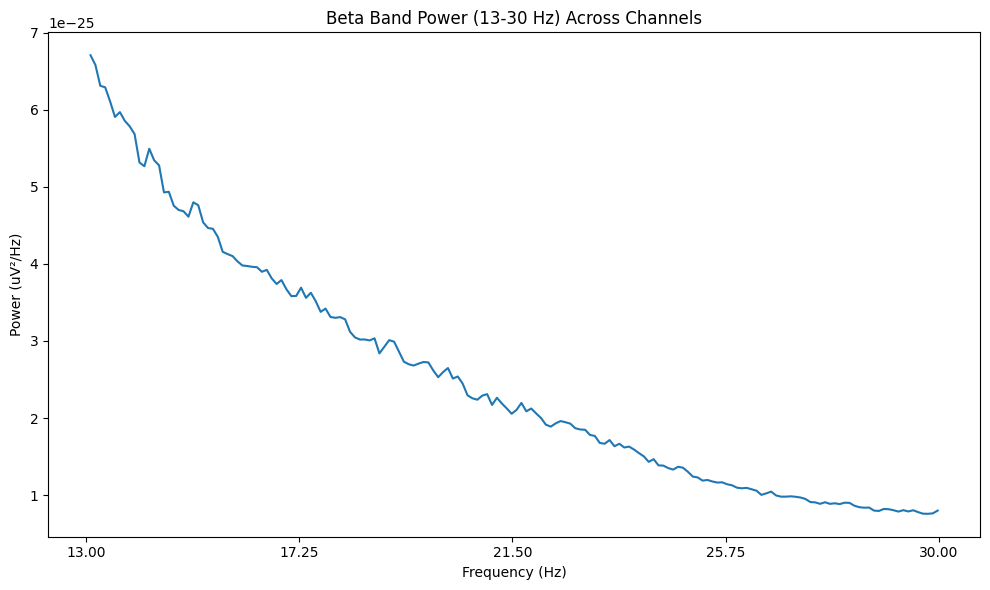

Extracted Beta Band Power (13-30 Hz) successfully.


In [10]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [11]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d86 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d86.head())
print(d86.shape)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.2/115.2 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 81.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 64.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.5/130.5 kB 9.2 MB/s eta 0:00:00
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.12

Extraction of Top 58 channels

In [12]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d86_clean = d86.replace([np.inf, -np.inf], np.nan)
d86_clean = d86_clean.fillna(d86_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d86_scaled = pd.DataFrame(
    scaler.fit_transform(d86_clean),
    columns=d86_clean.columns,
    index=d86_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d86_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d86_scaled.index,
    columns=d86_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d86_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df86 = d86_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df86["Pd_indicator_meg"] = 1

print("\nShape of df5:", df86.shape)
print(df86.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [13]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586 = pd.concat([previous_df, df86], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
4751    4.026532             0.062088          3.620511e-12  0.809397   
4752    4.011894             0.062315          3.454442e-12  0.850730   
4753    3.904849             0.064023          1.916420e-13  0.857504   
4754    4.110704             0.060817          4.035584e-12  0.860614   
4755    3.978

In [14]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586.to_csv('/content/drive/MyDrive/combined_features_upto_sub086_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586 preserved.")


RAM Used After Cleanup: 0.97 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586 preserved.


sub-87

In [15]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-87'  # Replace with your folder path


In [16]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-087_scans.tsv', 'meg']


In [17]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-087_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-087_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-087_task-go_run-1_proc-tsss+mc_events.json', 'sub-087_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-087_coordsystem.json', 'sub-087_task-go_run-1_proc-tsss+mc_meg.json', 'sub-087_task-noise_proc-tsss_meg.fif', 'sub-087_task-noise_proc-tsss_channels.tsv', 'sub-087_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-087_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-087_task-passive_run-1_proc-tsss+mc_events.json', 'sub-087_task-noise_proc-tsss_meg.json', 'sub-087_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-087_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-087_task-rest_run-1_proc-tsss+mc_events.json', 'sub-087_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-087_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-087_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-087_task-rest_run-1_proc-tsss+mc_meg.json']


In [18]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-087_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-087_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-087_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-087_task-rest_run-1_proc-tsss+mc_meg.fif']


In [19]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-87/meg/sub-087_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [20]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-87/meg/sub-087_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 60000 ... 1154999 =     60.000 ...  1154.999 secs
Ready.
Reading 0 ... 1094999  =      0.000 ...  1094.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


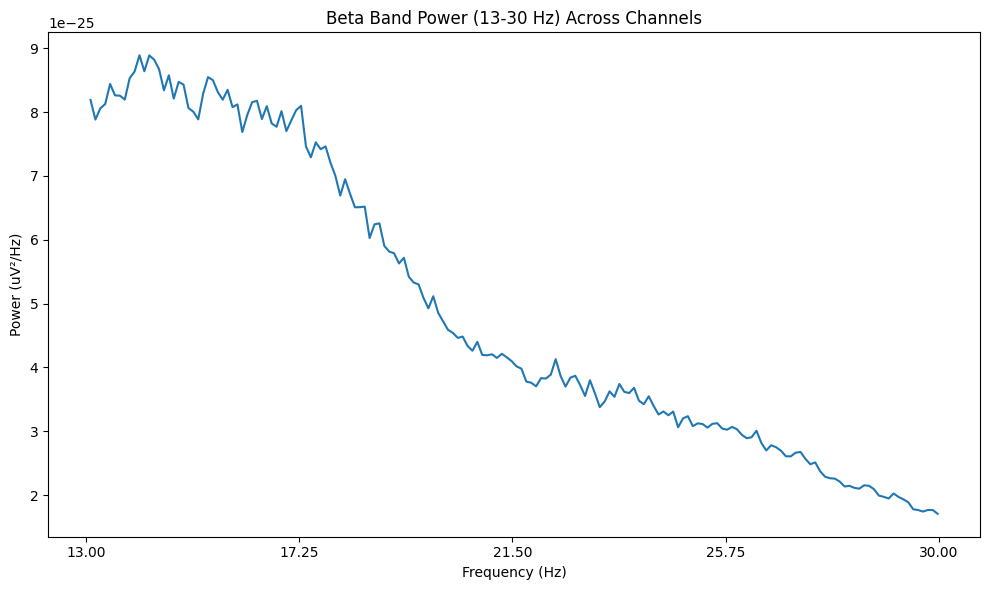

Extracted Beta Band Power (13-30 Hz) successfully.


In [21]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [22]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d87 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d87.head())
print(d87.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [23]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d87_clean = d87.replace([np.inf, -np.inf], np.nan)
d87_clean = d87_clean.fillna(d87_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d87_scaled = pd.DataFrame(
    scaler.fit_transform(d87_clean),
    columns=d87_clean.columns,
    index=d87_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d87_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d87_scaled.index,
    columns=d87_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d87_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df87 = d87_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df87["Pd_indicator_meg"] = 0

print("\nShape of df5:", df87.shape)
print(df87.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [24]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586, df87], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
4809    4.084018             0.061214          4.138684e-12  0.815416   
4810    4.118721             0.060698          3.931664e-12  0.869467   
4811    4.114155             0.060766          2.262340e-13  0.853626   
4812    4.010959             0.062329          4.123113e-12  0.868280   
4813    3.8

In [25]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687.to_csv('/content/drive/MyDrive/combined_features_upto_sub087_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687 preserved.")


RAM Used After Cleanup: 0.99 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687 preserved.


sub-88

In [26]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-88'  # Replace with your folder path


In [27]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-088_scans.tsv', 'meg']


In [28]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-088_task-go_run-1_proc-tsss+mc_events.json', 'sub-088_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-088_coordsystem.json', 'sub-088_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-088_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-088_task-go_run-1_proc-tsss+mc_meg.json', 'sub-088_task-noise_proc-tsss_meg.fif', 'sub-088_task-noise_proc-tsss_channels.tsv', 'sub-088_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-088_task-passive_run-1_proc-tsss+mc_events.json', 'sub-088_task-noise_proc-tsss_meg.json', 'sub-088_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-088_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-088_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-088_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-088_task-rest_run-1_proc-tsss+mc_events.json', 'sub-088_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-088_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-088_task-rest_run-1_proc-tsss+mc_meg.json']


In [29]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-088_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-088_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-088_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-088_task-rest_run-1_proc-tsss+mc_meg.fif']


In [30]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-88/meg/sub-088_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [31]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-88/meg/sub-088_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 75000 ... 1151999 =     75.000 ...  1151.999 secs
Ready.
Reading 0 ... 1076999  =      0.000 ...  1076.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


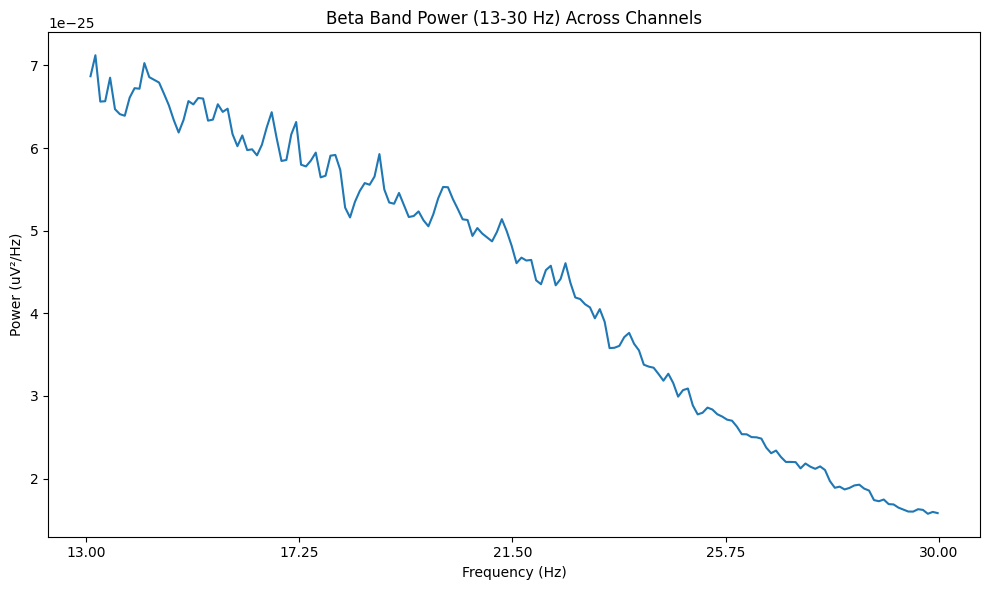

Extracted Beta Band Power (13-30 Hz) successfully.


In [32]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [33]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d88 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d88.head())
print(d88.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [34]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d88_clean = d88.replace([np.inf, -np.inf], np.nan)
d88_clean = d88_clean.fillna(d88_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d88_scaled = pd.DataFrame(
    scaler.fit_transform(d88_clean),
    columns=d88_clean.columns,
    index=d88_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d88_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d88_scaled.index,
    columns=d88_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d88_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df88 = d88_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df88["Pd_indicator_meg"] = 0

print("\nShape of df5:", df88.shape)
print(df88.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [35]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687, df88], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
4867    3.995357             0.062573          4.686536e-12  0.789685   
4868    4.017642             0.062226          4.878711e-12  0.844787   
4869    3.938719             0.063472          2.814150e-13  0.849415   
4870    3.996286             0.062558          5.302416e-12  0.791369   
4871    3

In [36]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788.to_csv('/content/drive/MyDrive/combined_features_upto_sub088_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788 preserved.")


RAM Used After Cleanup: 1.00 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788 preserved.


sub-89

In [37]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-89'  # Replace with your folder path


In [38]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-089_scans.tsv', 'meg']


In [39]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-089_coordsystem.json', 'sub-089_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-089_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-089_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-089_task-go_run-1_proc-tsss+mc_events.json', 'sub-089_task-go_run-1_proc-tsss+mc_meg.json', 'sub-089_task-noise_proc-tsss_meg.fif', 'sub-089_task-noise_proc-tsss_channels.tsv', 'sub-089_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-089_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-089_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-089_task-passive_run-1_proc-tsss+mc_events.json', 'sub-089_task-noise_proc-tsss_meg.json', 'sub-089_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-089_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-089_task-rest_run-1_proc-tsss+mc_events.json', 'sub-089_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-089_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-089_task-rest_run-1_proc-tsss+mc_meg.json']


In [40]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-089_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-089_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-089_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-089_task-rest_run-1_proc-tsss+mc_meg.fif']


In [41]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-89/meg/sub-089_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [42]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-89/meg/sub-089_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 284000 ... 1362999 =    284.000 ...  1362.999 secs
Ready.
Reading 0 ... 1078999  =      0.000 ...  1078.999 secs...
Finding events on: STI101
302 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
302 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


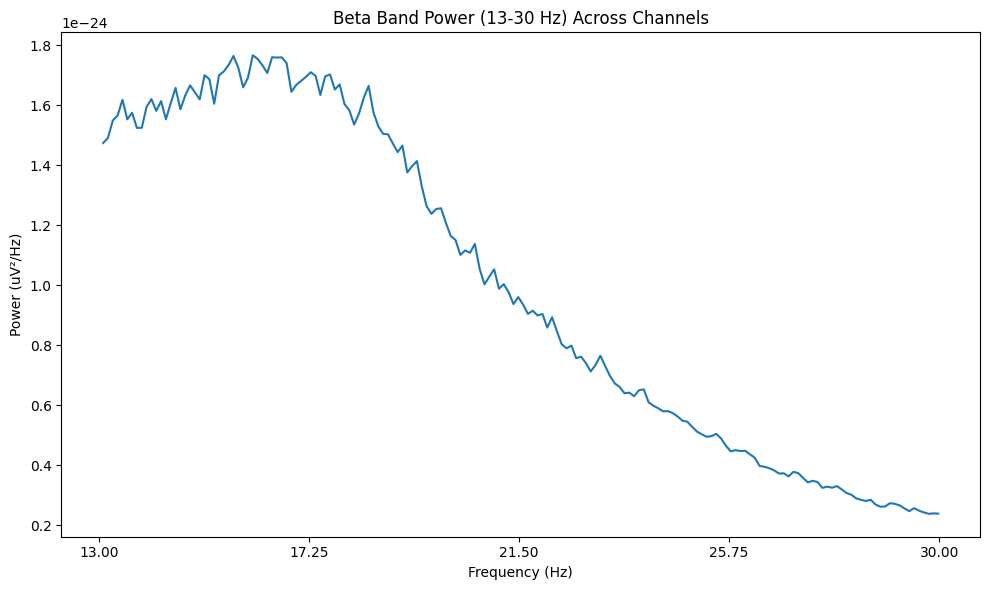

Extracted Beta Band Power (13-30 Hz) successfully.


In [43]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [44]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d89 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d89.head())
print(d89.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [45]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d89_clean = d89.replace([np.inf, -np.inf], np.nan)
d89_clean = d89_clean.fillna(d89_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d89_scaled = pd.DataFrame(
    scaler.fit_transform(d89_clean),
    columns=d89_clean.columns,
    index=d89_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d89_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d89_scaled.index,
    columns=d89_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d89_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df89 = d89_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df89["Pd_indicator_meg"] = 1

print("\nShape of df5:", df89.shape)
print(df89.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [46]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788, df89], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
4925    3.695088             0.067657          5.203286e-12  0.836250   
4926    3.727525             0.067069          5.710303e-12  0.814886   
4927    3.770158             0.066310          3.605360e-13  0.824516   
4928    3.721965             0.067169          6.194620e-12  0.836049   
4929   

In [47]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889.to_csv('/content/drive/MyDrive/combined_features_upto_sub089_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889 preserved.")


RAM Used After Cleanup: 1.01 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889 preserved.


sub-90

In [48]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-90'  # Replace with your folder path


In [49]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-090_scans.tsv', 'meg']


In [50]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-090_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-090_coordsystem.json', 'sub-090_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-090_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-090_task-go_run-1_proc-tsss+mc_events.json', 'sub-090_task-noise_proc-tsss_channels.tsv', 'sub-090_task-noise_proc-tsss_meg.fif', 'sub-090_task-go_run-1_proc-tsss+mc_meg.json', 'sub-090_task-noise_proc-tsss_meg.json', 'sub-090_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-090_task-passive_run-1_proc-tsss+mc_events.json', 'sub-090_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-090_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-090_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-090_task-rest_run-1_proc-tsss+mc_events.json', 'sub-090_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-090_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-090_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-090_task-rest_run-1_proc-tsss+mc_meg.json']


In [51]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-090_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-090_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-090_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-090_task-rest_run-1_proc-tsss+mc_meg.fif']


In [52]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-90/meg/sub-090_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [53]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-90/meg/sub-090_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 63000 ... 1141999 =     63.000 ...  1141.999 secs
Ready.
Reading 0 ... 1078999  =      0.000 ...  1078.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Comouting Power Spectral Density

Effective window size : 10.240 (s)


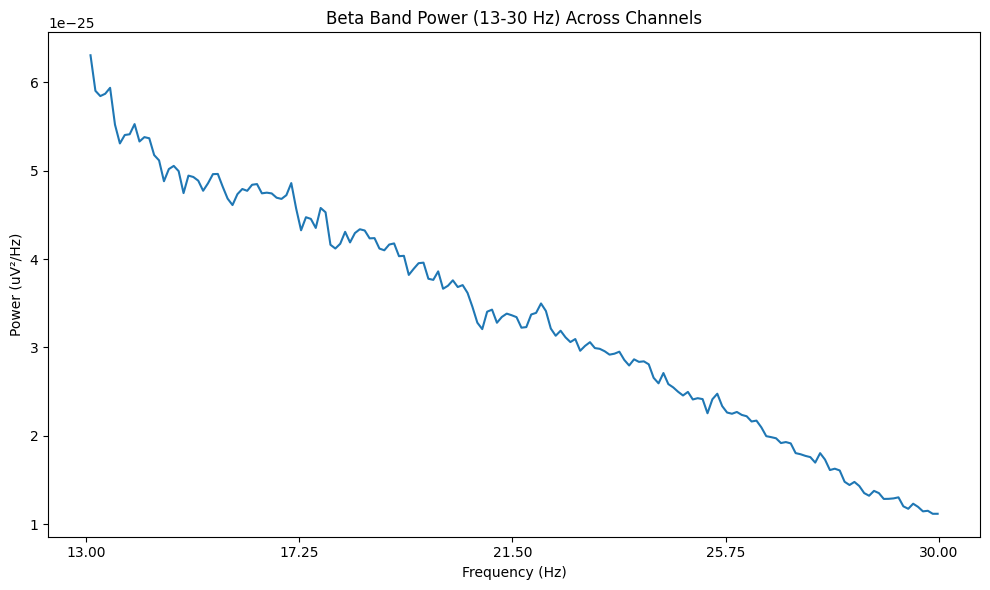

Extracted Beta Band Power (13-30 Hz) successfully.


In [54]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [55]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d90 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d90.head())
print(d90.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [56]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d90_clean = d90.replace([np.inf, -np.inf], np.nan)
d90_clean = d90_clean.fillna(d90_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d90_scaled = pd.DataFrame(
    scaler.fit_transform(d90_clean),
    columns=d90_clean.columns,
    index=d90_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d90_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d90_scaled.index,
    columns=d90_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d90_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df90 = d90_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df90["Pd_indicator_meg"] = 1

print("\nShape of df5:", df90.shape)
print(df90.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [57]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889, df90], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
4983    3.912882             0.063892          4.787389e-12  0.949630   
4984    3.916589             0.063831          5.157935e-12  0.915216   
4985    3.940686             0.063441          2.761214e-13  0.886463   
4986    3.842447             0.065063          5.468800e-12  0.919778   
4987 

In [58]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990.to_csv('/content/drive/MyDrive/combined_features_upto_sub090_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990 preserved.")


RAM Used After Cleanup: 1.02 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990 preserved.


sub-91

In [59]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-91'  # Replace with your folder path


In [60]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-091_scans.tsv', 'meg']


In [61]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-091_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-091_task-go_run-1_proc-tsss+mc_events.json', 'sub-091_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-091_coordsystem.json', 'sub-091_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-091_task-go_run-1_proc-tsss+mc_meg.json', 'sub-091_task-noise_proc-tsss_channels.tsv', 'sub-091_task-noise_proc-tsss_meg.fif', 'sub-091_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-091_task-noise_proc-tsss_meg.json', 'sub-091_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-091_task-passive_run-1_proc-tsss+mc_events.json', 'sub-091_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-091_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-091_task-rest_run-1_proc-tsss+mc_events.json', 'sub-091_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-091_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-091_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-091_task-rest_run-1_proc-tsss+mc_meg.json']


In [62]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-091_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-091_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-091_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-091_task-rest_run-1_proc-tsss+mc_meg.fif']


In [63]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-91/meg/sub-091_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [64]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-91/meg/sub-091_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 65000 ... 1141999 =     65.000 ...  1141.999 secs
Ready.
Reading 0 ... 1076999  =      0.000 ...  1076.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing power Spectral Density

Effective window size : 10.240 (s)


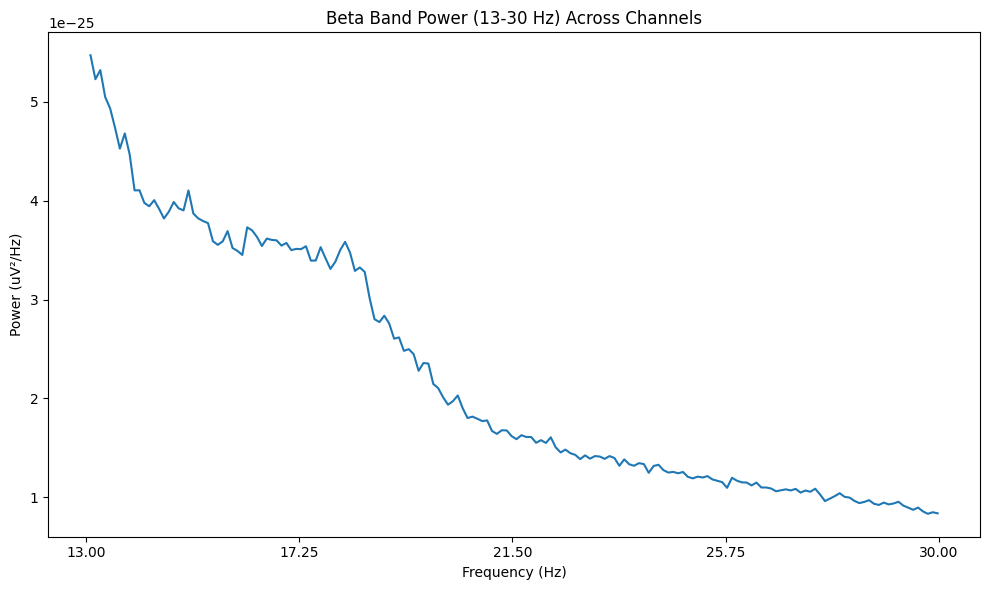

Extracted Beta Band Power (13-30 Hz) successfully.


In [65]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [66]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d91 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d91.head())
print(d91.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of top 58 channels

In [67]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d91_clean = d91.replace([np.inf, -np.inf], np.nan)
d91_clean = d91_clean.fillna(d91_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d91_scaled = pd.DataFrame(
    scaler.fit_transform(d91_clean),
    columns=d91_clean.columns,
    index=d91_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d91_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d91_scaled.index,
    columns=d91_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d91_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df91 = d91_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df91["Pd_indicator_meg"] = 0

print("\nShape of df5:", df91.shape)
print(df91.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [68]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990, df91], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
5041    4.621170             0.054099          1.792246e-12  0.766700   
5042    4.651811             0.053743          1.882880e-12  0.743949   
5043    4.625812             0.054045          1.167589e-13  0.772020   
5044    4.537604             0.055095          2.309704e-12  0.790511   
504

In [69]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091.to_csv('/content/drive/MyDrive/combined_features_upto_sub091_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091 preserved.")


RAM Used After Cleanup: 1.01 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091 preserved.


sub-93

In [70]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-93'  # Replace with your folder path


In [71]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-093_scans.tsv', 'meg']


In [72]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-093_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-093_coordsystem.json', 'sub-093_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-093_task-go_run-1_proc-tsss+mc_events.json', 'sub-093_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-093_task-noise_proc-tsss_meg.fif', 'sub-093_task-go_run-1_proc-tsss+mc_meg.json', 'sub-093_task-noise_proc-tsss_channels.tsv', 'sub-093_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-093_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-093_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-093_task-passive_run-1_proc-tsss+mc_events.json', 'sub-093_task-noise_proc-tsss_meg.json', 'sub-093_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-093_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-093_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-093_task-rest_run-1_proc-tsss+mc_events.json', 'sub-093_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-093_task-rest_run-1_proc-tsss+mc_meg.json']


In [73]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-093_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-093_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-093_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-093_task-rest_run-1_proc-tsss+mc_meg.fif']


In [74]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-93/meg/sub-093_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [75]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-93/meg/sub-093_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 234000 ... 1314999 =    234.000 ...  1314.999 secs
Ready.
Reading 0 ... 1080999  =      0.000 ...  1080.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


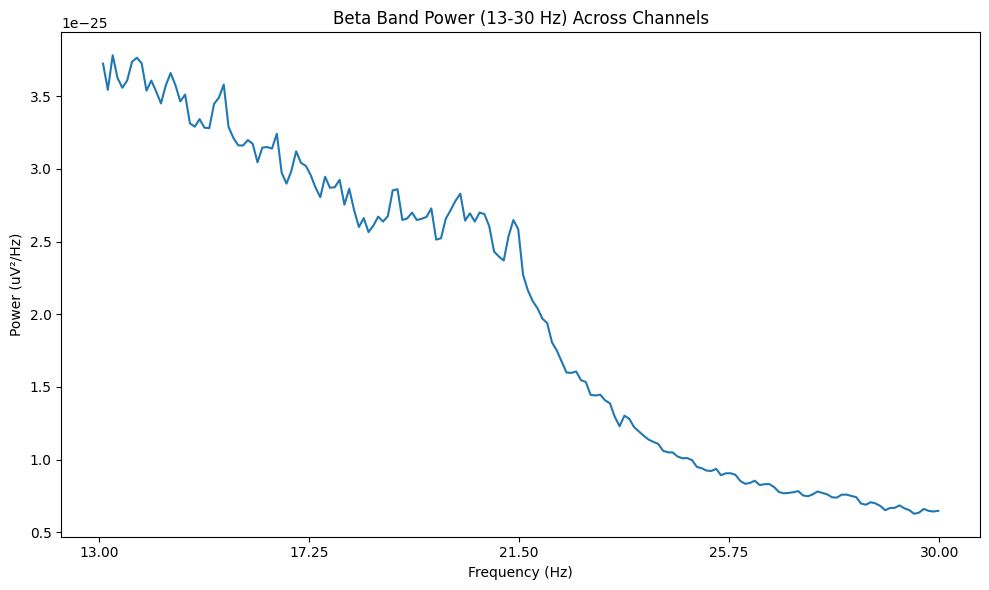

Extracted Beta Band Power (13-30 Hz) successfully.


In [76]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [77]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d93 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d93.head())
print(d93.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [78]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d93_clean = d93.replace([np.inf, -np.inf], np.nan)
d93_clean = d93_clean.fillna(d93_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d93_scaled = pd.DataFrame(
    scaler.fit_transform(d93_clean),
    columns=d93_clean.columns,
    index=d93_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d93_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d93_scaled.index,
    columns=d93_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d93_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df93 = d93_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df93["Pd_indicator_meg"] = 1

print("\nShape of df5:", df93.shape)
print(df93.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [79]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091, df93], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
5099    4.311748             0.057925          3.352127e-12  0.740068   
5100    4.267345             0.058578          2.999102e-12  0.748287   
5101    4.075856             0.061325          1.564360e-13  0.729968   
5102    4.169288             0.059953          3.407551e-12  0.744051   
5

In [80]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193.to_csv('/content/drive/MyDrive/combined_features_upto_sub093_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193 preserved.")


RAM Used After Cleanup: 1.02 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193 preserved.


sub-94

In [81]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-94'  # Replace with your folder path


In [82]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-094_scans.tsv', 'meg']


In [83]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-094_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-094_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-094_coordsystem.json', 'sub-094_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-094_task-go_run-1_proc-tsss+mc_events.json', 'sub-094_task-noise_proc-tsss_channels.tsv', 'sub-094_task-go_run-1_proc-tsss+mc_meg.json', 'sub-094_task-noise_proc-tsss_meg.fif', 'sub-094_task-passive_run-1_proc-tsss+mc_events.json', 'sub-094_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-094_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-094_task-noise_proc-tsss_meg.json', 'sub-094_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-094_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-094_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-094_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-094_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-094_task-rest_run-1_proc-tsss+mc_events.json', 'sub-094_task-rest_run-1_proc-tsss+mc_meg.json']


In [84]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-094_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-094_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-094_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-094_task-rest_run-1_proc-tsss+mc_meg.fif']


In [85]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-94/meg/sub-094_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [86]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-94/meg/sub-094_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 98000 ... 1174999 =     98.000 ...  1174.999 secs
Ready.
Reading 0 ... 1076999  =      0.000 ...  1076.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting 

Computing Power Spectral Density

Effective window size : 10.240 (s)


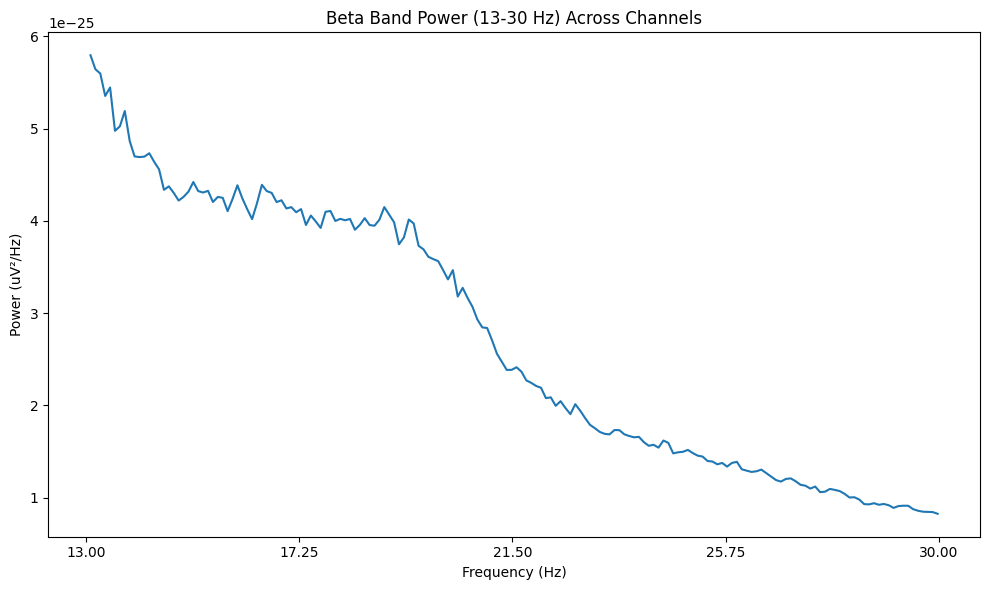

Extracted Beta Band Power (13-30 Hz) successfully.


In [87]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [88]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d94 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d94.head())
print(d94.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [89]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d94_clean = d94.replace([np.inf, -np.inf], np.nan)
d94_clean = d94_clean.fillna(d94_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d94_scaled = pd.DataFrame(
    scaler.fit_transform(d94_clean),
    columns=d94_clean.columns,
    index=d94_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d94_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d94_scaled.index,
    columns=d94_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d94_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df94 = d94_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df94["Pd_indicator_meg"] = 1

print("\nShape of df5:", df94.shape)
print(df94.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [90]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193, df94], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
5157    4.122563             0.060642          3.086945e-12  0.747903   
5158    4.217270             0.059280          2.754780e-12  0.774878   
5159    4.006500             0.062399          1.620764e-13  0.781756   
5160    4.069638             0.061431          2.858042e-12  0.757315   

In [91]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394.to_csv('/content/drive/MyDrive/combined_features_upto_sub094_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394 preserved.")


RAM Used After Cleanup: 1.02 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394 preserved.


sub-95

In [92]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-95'  # Replace with your folder path


In [93]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-095_scans.tsv', 'meg']


In [94]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-095_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-095_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-095_coordsystem.json', 'sub-095_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-095_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-095_task-go_run-1_proc-tsss+mc_meg.json', 'sub-095_task-passive_run-1_proc-tsss+mc_events.json', 'sub-095_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-095_task-go_run-1_proc-tsss+mc_events.json', 'sub-095_task-noise_proc-tsss_meg.json', 'sub-095_task-noise_proc-tsss_channels.tsv', 'sub-095_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-095_task-rest_run-1_proc-tsss+mc_events.json', 'sub-095_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-095_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-095_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-095_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-095_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-095_task-noise_proc-tsss_meg.fif']


In [95]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'passive': ['sub-095_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-095_task-rest_run-1_proc-tsss+mc_meg.fif']
Task 'go': ['sub-095_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-095_task-noise_proc-tsss_meg.fif']


In [96]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-95/meg/sub-095_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [97]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-95/meg/sub-095_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 69000 ... 1147999 =     69.000 ...  1147.999 secs
Ready.
Reading 0 ... 1078999  =      0.000 ...  1078.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


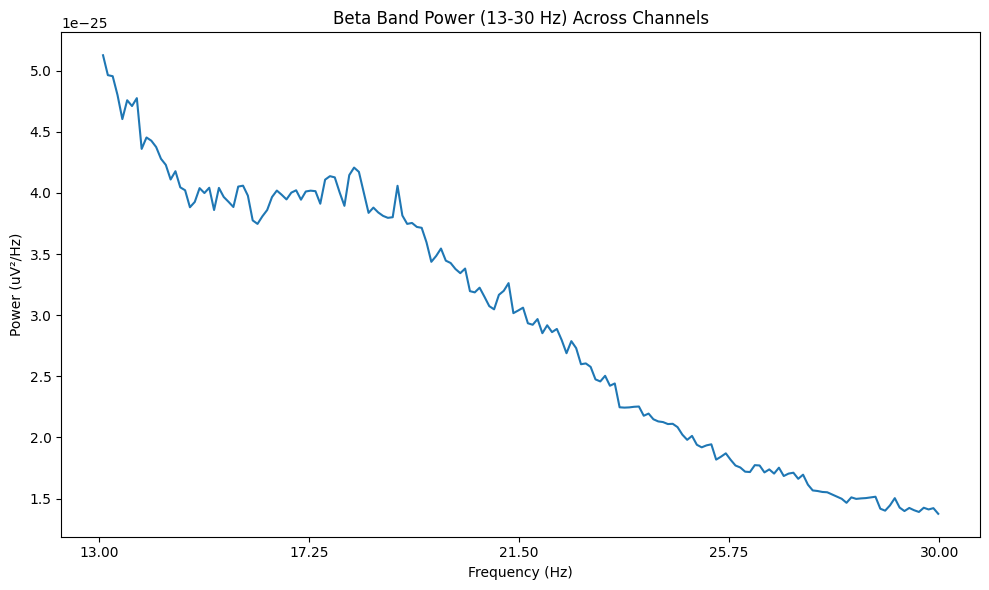

Extracted Beta Band Power (13-30 Hz) successfully.


In [98]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [99]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d95 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d95.head())
print(d95.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [100]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d95_clean = d95.replace([np.inf, -np.inf], np.nan)
d95_clean = d95_clean.fillna(d95_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d95_scaled = pd.DataFrame(
    scaler.fit_transform(d95_clean),
    columns=d95_clean.columns,
    index=d95_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d95_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d95_scaled.index,
    columns=d95_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d95_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df95 = d95_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df95["Pd_indicator_meg"] = 1

print("\nShape of df5:", df95.shape)
print(df95.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [101]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394, df95], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
5215    3.950880             0.063277          3.415986e-12  0.778878   
5216    4.194625             0.059600          3.188064e-12  0.782303   
5217    4.091752             0.061099          1.662020e-13  0.804514   
5218    4.083411             0.061223          3.730772e-12  0.810106 

In [102]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495.to_csv('/content/drive/MyDrive/combined_features_upto_sub095_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495 preserved.")


RAM Used After Cleanup: 1.03 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495 preserved.


sub-96

In [103]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-96'  # Replace with your folder path


In [104]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-096_scans.tsv', 'meg']


In [105]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-096_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-096_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-096_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-096_coordsystem.json', 'sub-096_task-go_run-1_proc-tsss+mc_events.json', 'sub-096_task-go_run-1_proc-tsss+mc_meg.json', 'sub-096_task-noise_proc-tsss_meg.fif', 'sub-096_task-noise_proc-tsss_channels.tsv', 'sub-096_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-096_task-passive_run-1_proc-tsss+mc_events.json', 'sub-096_task-noise_proc-tsss_meg.json', 'sub-096_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-096_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-096_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-096_task-rest_run-1_proc-tsss+mc_events.json', 'sub-096_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-096_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-096_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-096_task-rest_run-1_proc-tsss+mc_meg.json']


In [106]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-096_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-096_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-096_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-096_task-rest_run-1_proc-tsss+mc_meg.fif']


In [107]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-96/meg/sub-096_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [108]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-96/meg/sub-096_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 254000 ... 1323999 =    254.000 ...  1323.999 secs
Ready.
Reading 0 ... 1069999  =      0.000 ...  1069.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


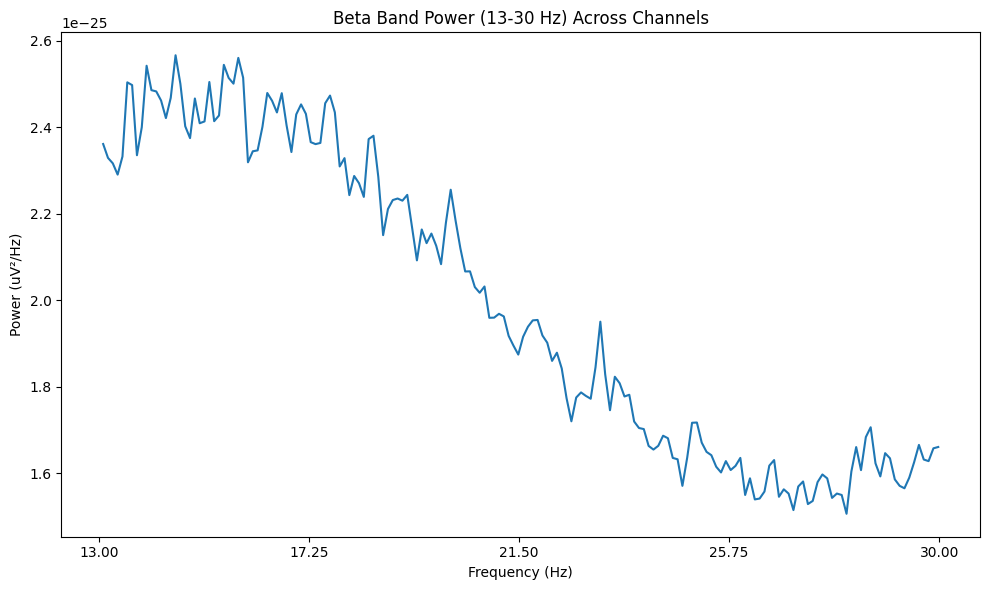

Extracted Beta Band Power (13-30 Hz) successfully.


In [109]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [110]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d96 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d96.head())
print(d96.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [111]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d96_clean = d96.replace([np.inf, -np.inf], np.nan)
d96_clean = d96_clean.fillna(d96_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d96_scaled = pd.DataFrame(
    scaler.fit_transform(d96_clean),
    columns=d96_clean.columns,
    index=d96_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d96_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d96_scaled.index,
    columns=d96_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d96_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df96 = d96_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df96["Pd_indicator_meg"] = 0

print("\nShape of df5:", df96.shape)
print(df96.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [112]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495, df96], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
5273    4.027103             0.062079          2.926181e-12  0.777128   
5274    4.176636             0.059857          3.231003e-12  0.805710   
5275    4.129907             0.060515          1.572187e-13  0.750003   
5276    4.232710             0.059064          4.172449e-12  0.84964

In [113]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596.to_csv('/content/drive/MyDrive/combined_features_upto_sub096_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596 preserved.")


RAM Used After Cleanup: 1.02 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596 preserved.


sub-97

In [114]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-97'  # Replace with your folder path


In [115]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-097_scans.tsv', 'meg']


In [116]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-097_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-097_task-go_run-1_proc-tsss+mc_events.json', 'sub-097_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-097_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-097_coordsystem.json', 'sub-097_task-noise_proc-tsss_channels.tsv', 'sub-097_task-go_run-1_proc-tsss+mc_meg.json', 'sub-097_task-noise_proc-tsss_meg.fif', 'sub-097_task-noise_proc-tsss_meg.json', 'sub-097_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-097_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-097_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-097_task-passive_run-1_proc-tsss+mc_events.json', 'sub-097_task-rest_run-1_proc-tsss+mc_events.json', 'sub-097_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-097_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-097_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-097_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-097_task-rest_run-1_proc-tsss+mc_meg.json']


In [117]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-097_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-097_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-097_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-097_task-rest_run-1_proc-tsss+mc_meg.fif']


In [118]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-97/meg/sub-097_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [119]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-97/meg/sub-097_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 83000 ... 1151999 =     83.000 ...  1151.999 secs
Ready.
Reading 0 ... 1068999  =      0.000 ...  1068.999 secs...
Finding events on: STI101
302 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
302 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


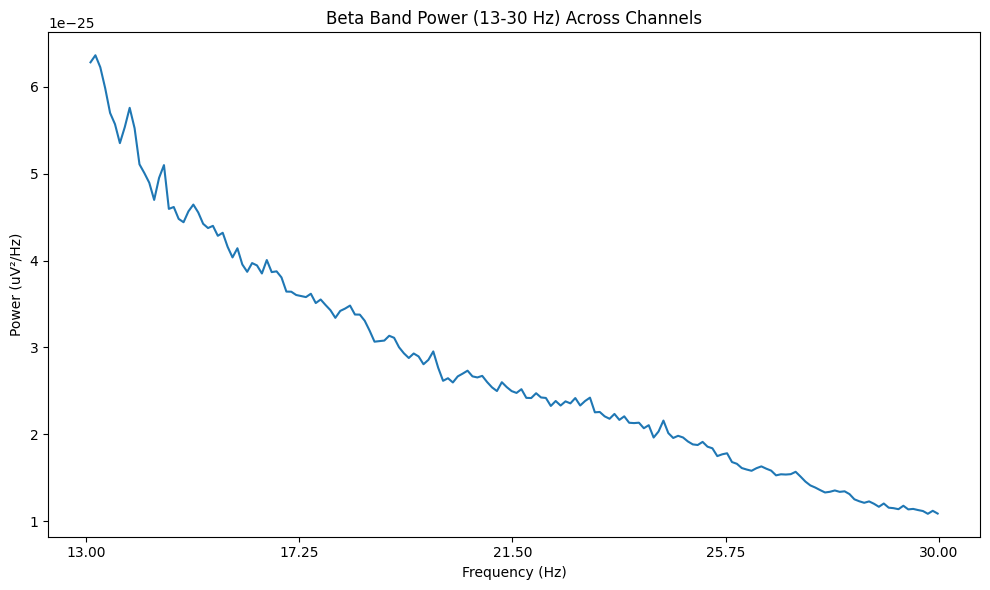

Extracted Beta Band Power (13-30 Hz) successfully.


In [120]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [121]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d97 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d97.head())
print(d97.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [122]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d97_clean = d97.replace([np.inf, -np.inf], np.nan)
d97_clean = d97_clean.fillna(d97_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d97_scaled = pd.DataFrame(
    scaler.fit_transform(d97_clean),
    columns=d97_clean.columns,
    index=d97_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d97_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d97_scaled.index,
    columns=d97_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d97_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df97 = d97_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df97["Pd_indicator_meg"] = 1

print("\nShape of df5:", df97.shape)
print(df97.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [123]:
# Combine df_4 and df_8 vertically
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596, df97], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697 = df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697):")
print(df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697)

# Print the shape
print("Shape of df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697:", df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697.shape) #(116,7)


Combined top channels (df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
5331    4.277830             0.058441          3.977303e-12  0.795470   
5332    4.233863             0.059048          3.528842e-12  0.824146   
5333    4.295603             0.058199          2.066115e-13  0.837120   
5334    4.228251             0.059126          4.026863e-12  0.772

In [124]:
df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697.to_csv('/content/drive/MyDrive/combined_features_upto_sub097_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697 preserved.")


RAM Used After Cleanup: 1.03 GB
Memory cleaned. df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697 preserved.


sub-98

In [125]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-98'  # Replace with your folder path


In [126]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-098_scans.tsv', 'meg']


In [127]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-098_coordsystem.json', 'sub-098_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-098_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-098_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-098_task-go_run-1_proc-tsss+mc_events.json', 'sub-098_task-go_run-1_proc-tsss+mc_meg.json', 'sub-098_task-noise_proc-tsss_channels.tsv', 'sub-098_task-noise_proc-tsss_meg.fif', 'sub-098_task-noise_proc-tsss_meg.json', 'sub-098_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-098_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-098_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-098_task-passive_run-1_proc-tsss+mc_events.json', 'sub-098_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-098_task-rest_run-1_proc-tsss+mc_events.json', 'sub-098_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-098_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-098_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-098_task-rest_run-1_proc-tsss+mc_meg.json']


In [128]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-098_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-098_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-098_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-098_task-rest_run-1_proc-tsss+mc_meg.fif']


In [129]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-98/meg/sub-098_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [130]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-98/meg/sub-098_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 59000 ... 1127999 =     59.000 ...  1127.999 secs
Ready.
Reading 0 ... 1068999  =      0.000 ...  1068.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitt

Computing Power Spectral Density

Effective window size : 10.240 (s)


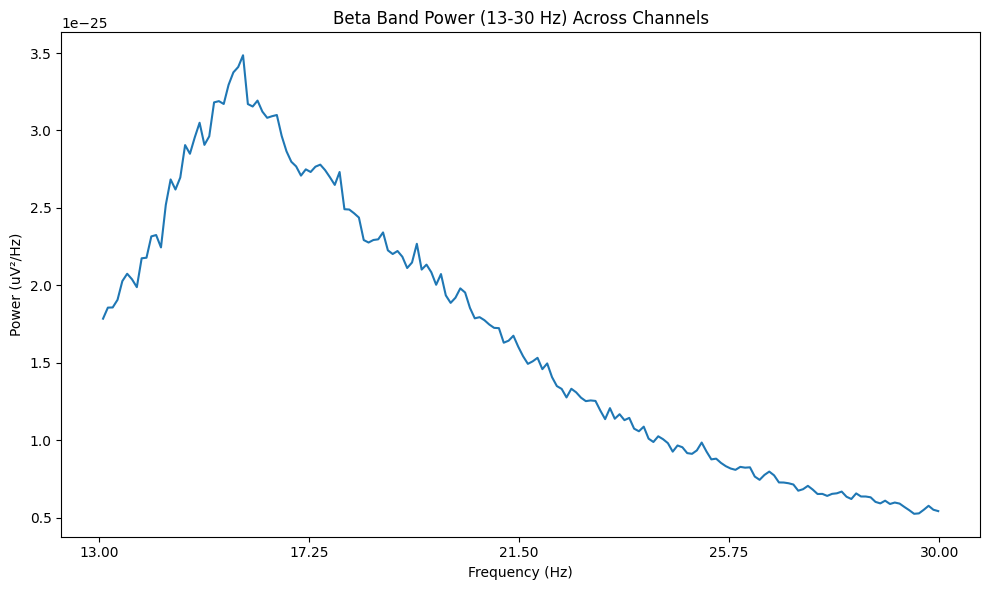

Extracted Beta Band Power (13-30 Hz) successfully.


In [131]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [132]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d98 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d98.head())
print(d98.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [133]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d98_clean = d98.replace([np.inf, -np.inf], np.nan)
d98_clean = d98_clean.fillna(d98_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d98_scaled = pd.DataFrame(
    scaler.fit_transform(d98_clean),
    columns=d98_clean.columns,
    index=d98_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d98_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d98_scaled.index,
    columns=d98_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d98_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df98 = d98_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df98["Pd_indicator_meg"] = 0

print("\nShape of df5:", df98.shape)
print(df98.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [134]:
# Combine df_4 and df_8 vertically
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798 = pd.concat([df12345678101112131415161718192122232425262728293031323335363738394041424344454647484950515253545556575859606163646566676869707172737475767778798081828384858687888990919394959697, df98], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798 = df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798):")
print(df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798)

# Print the shape
print("Shape of df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798:", df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798.shape) #(116,7)


Combined top channels (df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
5389    3.533209             0.070757          5.490425e-12  0.856409   
5390    3.739008             0.066863          4.428574e-12  0.809008   
5391    3.344247             0.074755          2.780667e-13  0.853215   
5392    3.725912             0.067098          4.867677e-12  0.8

In [135]:
df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798.to_csv('/content/drive/MyDrive/combined_features_upto_sub098_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798 preserved.")


RAM Used After Cleanup: 1.04 GB
Memory cleaned. df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798 preserved.


sub-99

In [136]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-99'  # Replace with your folder path


In [137]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-099_scans.tsv', 'meg']


In [138]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-099_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-099_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-099_coordsystem.json', 'sub-099_task-go_run-1_proc-tsss+mc_events.json', 'sub-099_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-099_task-noise_proc-tsss_channels.tsv', 'sub-099_task-noise_proc-tsss_meg.fif', 'sub-099_task-go_run-1_proc-tsss+mc_meg.json', 'sub-099_task-passive_run-1_proc-tsss+mc_events.json', 'sub-099_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-099_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-099_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-099_task-noise_proc-tsss_meg.json', 'sub-099_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-099_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-099_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-099_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-099_task-rest_run-1_proc-tsss+mc_events.json', 'sub-099_task-rest_run-1_proc-tsss+mc_meg.json']


In [139]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-099_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-099_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-099_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-099_task-rest_run-1_proc-tsss+mc_meg.fif']


In [140]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-99/meg/sub-099_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [141]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-99/meg/sub-099_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 55000 ... 1124999 =     55.000 ...  1124.999 secs
Ready.
Reading 0 ... 1069999  =      0.000 ...  1069.999 secs...
Finding events on: STI101
299 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
299 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 2 contiguous segments
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Setting 800 of 214000 (0.37%) samples to NaN, retaining 213200 (99.63%) samples.
Effective window size : 10.240 (s)


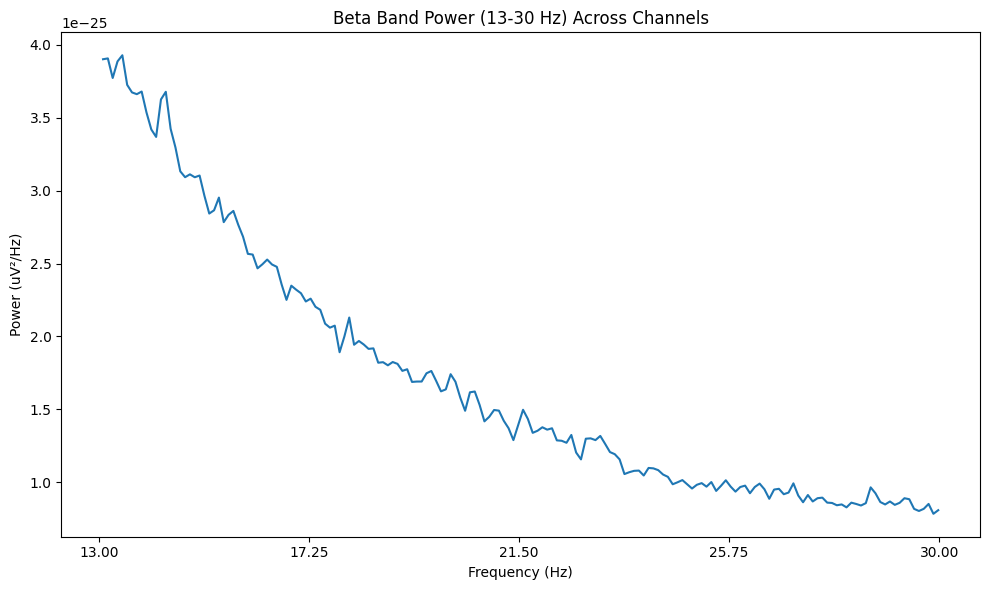

Extracted Beta Band Power (13-30 Hz) successfully.


In [142]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [143]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d99 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d99.head())
print(d99.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of top 58 channels

In [144]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d99_clean = d99.replace([np.inf, -np.inf], np.nan)
d99_clean = d99_clean.fillna(d99_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d99_scaled = pd.DataFrame(
    scaler.fit_transform(d99_clean),
    columns=d99_clean.columns,
    index=d99_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d99_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d99_scaled.index,
    columns=d99_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d99_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df99 = d99_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df99["Pd_indicator_meg"] = 1

print("\nShape of df5:", df99.shape)
print(df99.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [145]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899 = pd.concat([df1234567810111213141516171819212223242526272829303132333536373839404142434445464748495051525354555657585960616364656667686970717273747576777879808182838485868788899091939495969798, df99], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
5447    4.492523             0.055648          2.639595e-12  0.794440   
5448    4.310280             0.058001          2.554495e-12  0.823342   
5449    4.098131             0.061003          1.764632e-13  0.832073   
5450    4.247664             0.058856          3.291040e-12  0

In [146]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899.to_csv('/content/drive/MyDrive/combined_features_upto_sub099_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899 preserved.")


RAM Used After Cleanup: 1.04 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899 preserved.


sub-100

In [147]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-100'  # Replace with your folder path


In [148]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-100_scans.tsv', 'meg']


In [149]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-100_coordsystem.json', 'sub-100_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-100_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-100_task-go_run-1_proc-tsss+mc_events.json', 'sub-100_task-go_run-1_proc-tsss+mc_meg.json', 'sub-100_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-100_task-noise_proc-tsss_channels.tsv', 'sub-100_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-100_task-noise_proc-tsss_meg.json', 'sub-100_task-noise_proc-tsss_meg.fif', 'sub-100_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-100_task-passive_run-1_proc-tsss+mc_events.json', 'sub-100_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-100_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-100_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-100_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-100_task-rest_run-1_proc-tsss+mc_events.json', 'sub-100_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-100_task-rest_run-1_proc-tsss+mc_meg.fif']


In [150]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-100_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-100_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-100_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-100_task-rest_run-1_proc-tsss+mc_meg.fif']


In [151]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-100/meg/sub-100_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [152]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-100/meg/sub-100_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 94000 ... 1174999 =     94.000 ...  1174.999 secs
Ready.
Reading 0 ... 1080999  =      0.000 ...  1080.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


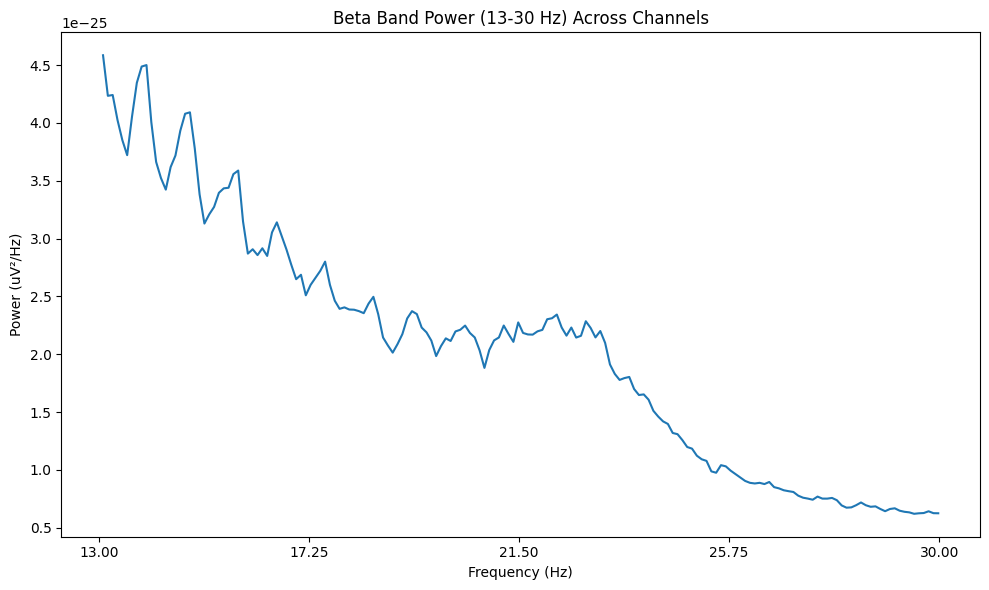

Extracted Beta Band Power (13-30 Hz) successfully.


In [153]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [154]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d100 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d100.head())
print(d100.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of top 58 channels

In [155]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d100_clean = d100.replace([np.inf, -np.inf], np.nan)
d100_clean = d100_clean.fillna(d100_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d100_scaled = pd.DataFrame(
    scaler.fit_transform(d100_clean),
    columns=d100_clean.columns,
    index=d100_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d100_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d100_scaled.index,
    columns=d100_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d100_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df100 = d100_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df100["Pd_indicator_meg"] = 1

print("\nShape of df5:", df100.shape)
print(df100.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [156]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899, df100], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
5505    4.259944             0.058686          4.114968e-12  0.724534   
5506    4.017576             0.062227          4.212510e-12  0.746691   
5507    4.006475             0.062399          2.205458e-13  0.742676   
5508    4.245143             0.058891          4.555618e-12

In [157]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100.to_csv('/content/drive/MyDrive/combined_features_upto_sub0100_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100 preserved.")


RAM Used After Cleanup: 1.03 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100 preserved.


sub-101

In [158]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-101'  # Replace with your folder path


In [159]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-101_scans.tsv', 'meg']


In [160]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-101_task-go_run-1_proc-tsss+mc_events.json', 'sub-101_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-101_coordsystem.json', 'sub-101_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-101_task-go_run-1_proc-tsss+mc_meg.json', 'sub-101_task-noise_proc-tsss_channels.tsv', 'sub-101_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-101_task-noise_proc-tsss_meg.json', 'sub-101_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-101_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-101_task-passive_run-1_proc-tsss+mc_events.json', 'sub-101_task-noise_proc-tsss_meg.fif', 'sub-101_task-rest_run-1_proc-tsss+mc_events.json', 'sub-101_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-101_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-101_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-101_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-101_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-101_task-rest_run-1_proc-tsss+mc_meg.fif']


In [161]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-101_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-101_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-101_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-101_task-rest_run-1_proc-tsss+mc_meg.fif']


In [162]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-101/meg/sub-101_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [163]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-101/meg/sub-101_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 66000 ... 1150999 =     66.000 ...  1150.999 secs
Ready.
Reading 0 ... 1084999  =      0.000 ...  1084.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


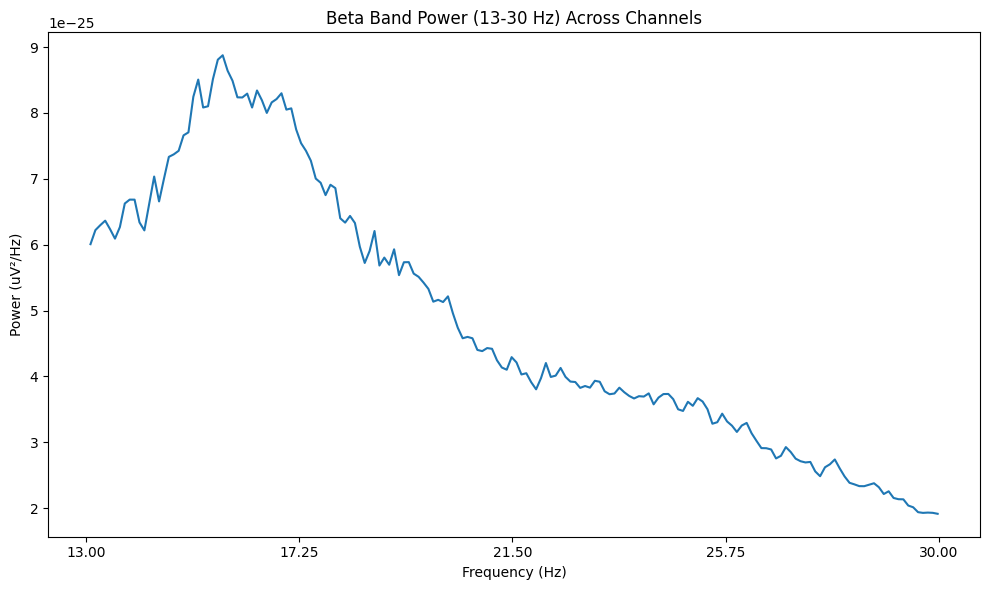

Extracted Beta Band Power (13-30 Hz) successfully.


In [164]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [165]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d101 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d101.head())
print(d101.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [166]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d101_clean = d101.replace([np.inf, -np.inf], np.nan)
d101_clean = d101_clean.fillna(d101_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d101_scaled = pd.DataFrame(
    scaler.fit_transform(d101_clean),
    columns=d101_clean.columns,
    index=d101_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d101_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d101_scaled.index,
    columns=d101_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d101_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df101 = d101_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df101["Pd_indicator_meg"] = 0

print("\nShape of df5:", df101.shape)
print(df101.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [167]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100, df101], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
5563    4.275576             0.058462          3.316552e-12  0.813760   
5564    4.465438             0.055986          3.034085e-12  0.782178   
5565    4.330876             0.057725          1.634006e-13  0.801179   
5566    4.388940             0.056961          3.175509e

In [168]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101.to_csv('/content/drive/MyDrive/combined_features_upto_sub0101_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101 preserved.")


RAM Used After Cleanup: 1.05 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101 preserved.


sub-102

In [169]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-102'  # Replace with your folder path


In [170]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-102_scans.tsv', 'meg']


In [171]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-102_task-go_run-1_proc-tsss+mc_events.json', 'sub-102_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-102_coordsystem.json', 'sub-102_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-102_task-go_run-1_proc-tsss+mc_meg.json', 'sub-102_task-noise_proc-tsss_channels.tsv', 'sub-102_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-102_task-passive_run-1_proc-tsss+mc_events.json', 'sub-102_task-noise_proc-tsss_meg.fif', 'sub-102_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-102_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-102_task-noise_proc-tsss_meg.json', 'sub-102_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-102_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-102_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-102_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-102_task-rest_run-1_proc-tsss+mc_events.json', 'sub-102_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-102_task-rest_run-1_proc-tsss+mc_meg.json']


In [172]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-102_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-102_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-102_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-102_task-rest_run-1_proc-tsss+mc_meg.fif']


In [173]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-102/meg/sub-102_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [174]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-102/meg/sub-102_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 122000 ... 1208999 =    122.000 ...  1208.999 secs
Ready.
Reading 0 ... 1086999  =      0.000 ...  1086.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


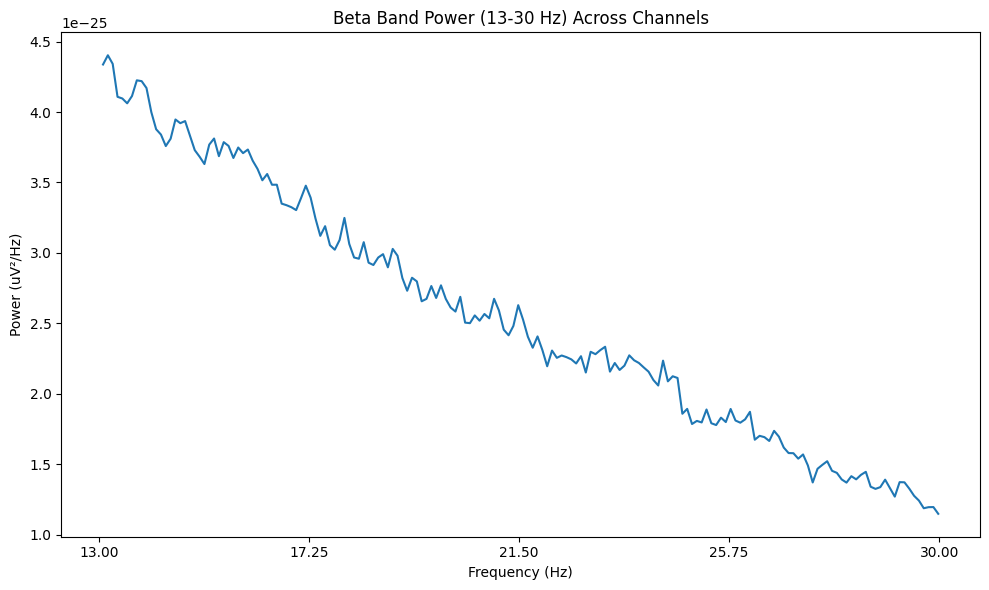

Extracted Beta Band Power (13-30 Hz) successfully.


In [175]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [176]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d102 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d102.head())
print(d102.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [177]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d102_clean = d102.replace([np.inf, -np.inf], np.nan)
d102_clean = d102_clean.fillna(d102_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d102_scaled = pd.DataFrame(
    scaler.fit_transform(d102_clean),
    columns=d102_clean.columns,
    index=d102_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d102_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d102_scaled.index,
    columns=d102_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d102_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df102 = d102_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df102["Pd_indicator_meg"] = 0

print("\nShape of df5:", df102.shape)
print(df102.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [178]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101, df102], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
5621    4.440662             0.056298          2.606790e-12  0.728755   
5622    4.399264             0.056817          1.904061e-12  0.800246   
5623    4.449862             0.056162          1.450969e-13  0.775637   
5624    4.493100             0.055632          2.3228

In [179]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102.to_csv('/content/drive/MyDrive/combined_features_upto_sub0102_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102 preserved.")


RAM Used After Cleanup: 1.07 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102 preserved.


sub-103

In [180]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-103'  # Replace with your folder path


In [181]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-103_scans.tsv', 'meg']


In [182]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-103_task-go_run-1_proc-tsss+mc_events.json', 'sub-103_coordsystem.json', 'sub-103_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-103_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-103_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-103_task-go_run-1_proc-tsss+mc_meg.json', 'sub-103_task-noise_proc-tsss_channels.tsv', 'sub-103_task-noise_proc-tsss_meg.fif', 'sub-103_task-noise_proc-tsss_meg.json', 'sub-103_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-103_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-103_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-103_task-passive_run-1_proc-tsss+mc_events.json', 'sub-103_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-103_task-rest_run-1_proc-tsss+mc_events.json', 'sub-103_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-103_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-103_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-103_task-rest_run-1_proc-tsss+mc_meg.json']


In [183]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-103_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-103_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-103_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-103_task-rest_run-1_proc-tsss+mc_meg.fif']


In [184]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-103/meg/sub-103_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [185]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-103/meg/sub-103_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 32000 ... 1111999 =     32.000 ...  1111.999 secs
Ready.
Reading 0 ... 1079999  =      0.000 ...  1079.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


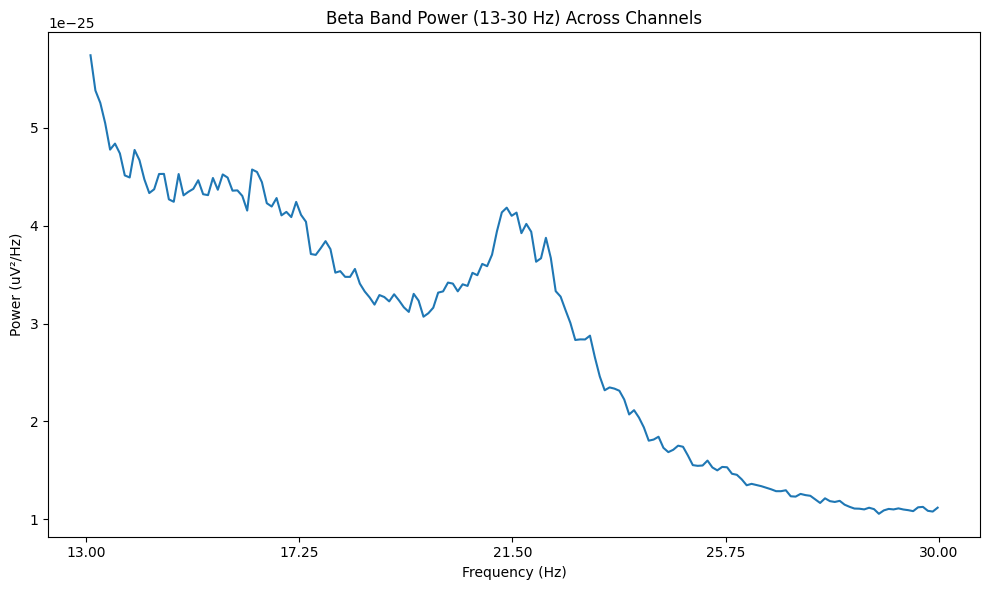

Extracted Beta Band Power (13-30 Hz) successfully.


In [186]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [187]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d103 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d103.head())
print(d103.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of top 58 channels

In [188]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d103_clean = d103.replace([np.inf, -np.inf], np.nan)
d103_clean = d103_clean.fillna(d103_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d103_scaled = pd.DataFrame(
    scaler.fit_transform(d103_clean),
    columns=d103_clean.columns,
    index=d103_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d103_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d103_scaled.index,
    columns=d103_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d103_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df103 = d103_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df103["Pd_indicator_meg"] = 0

print("\nShape of df5:", df103.shape)
print(df103.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [189]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102, df103], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
5679    4.294444             0.058215          2.647389e-12  0.785481   
5680    4.177778             0.059815          2.862596e-12  0.826322   
5681    4.123148             0.060622          1.438923e-13  0.794631   
5682    4.062037             0.061535          3.1

In [190]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103.to_csv('/content/drive/MyDrive/combined_features_upto_sub0103_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103 preserved.")


RAM Used After Cleanup: 1.08 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103 preserved.


sub-104

In [191]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-104'  # Replace with your folder path


In [192]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-104_scans.tsv', 'meg']


In [193]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-104_coordsystem.json', 'sub-104_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-104_task-go_run-1_proc-tsss+mc_events.json', 'sub-104_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-104_task-go_run-1_proc-tsss+mc_meg.json', 'sub-104_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-104_task-noise_proc-tsss_channels.tsv', 'sub-104_task-passive_run-1_proc-tsss+mc_events.json', 'sub-104_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-104_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-104_task-noise_proc-tsss_meg.json', 'sub-104_task-noise_proc-tsss_meg.fif', 'sub-104_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-104_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-104_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-104_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-104_task-rest_run-1_proc-tsss+mc_events.json', 'sub-104_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-104_task-rest_run-1_proc-tsss+mc_meg.json']


In [194]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-104_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-104_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-104_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-104_task-rest_run-1_proc-tsss+mc_meg.fif']


In [195]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-104/meg/sub-104_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [196]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-104/meg/sub-104_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 69000 ... 1150999 =     69.000 ...  1150.999 secs
Ready.
Reading 0 ... 1081999  =      0.000 ...  1081.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


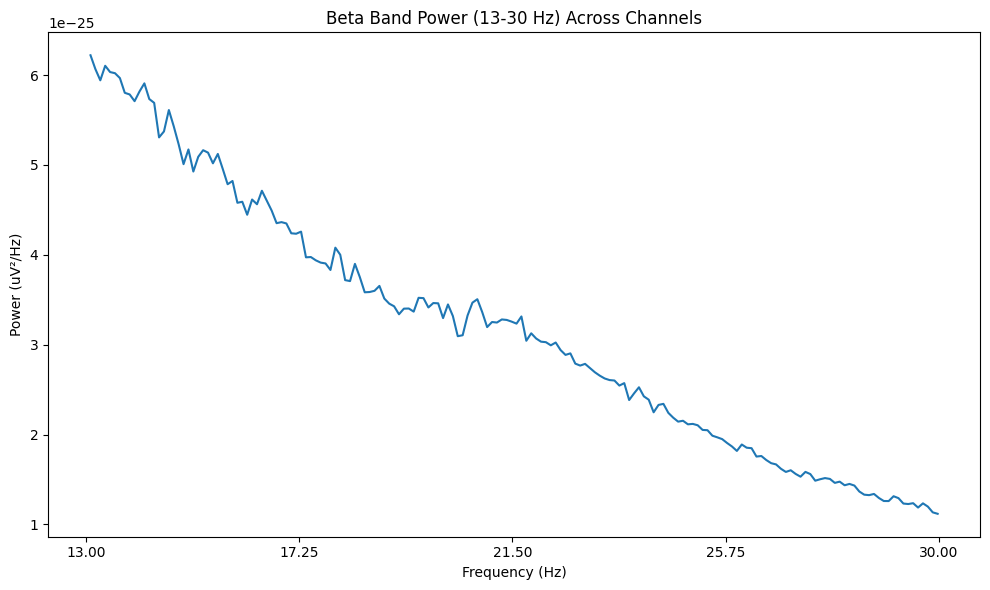

Extracted Beta Band Power (13-30 Hz) successfully.


In [197]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [198]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d104 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d104.head())
print(d104.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [199]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d104_clean = d104.replace([np.inf, -np.inf], np.nan)
d104_clean = d104_clean.fillna(d104_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d104_scaled = pd.DataFrame(
    scaler.fit_transform(d104_clean),
    columns=d104_clean.columns,
    index=d104_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d104_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d104_scaled.index,
    columns=d104_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d104_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df104 = d104_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df104["Pd_indicator_meg"] = 1

print("\nShape of df5:", df104.shape)
print(df104.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [200]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103, df104], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
5737    3.967652             0.063010          3.533957e-12  0.806392   
5738    4.216266             0.059294          3.481710e-12  0.823626   
5739    4.194085             0.059608          1.844937e-13  0.813205   
5740    4.199630             0.059529          

In [201]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104.to_csv('/content/drive/MyDrive/combined_features_upto_sub0104_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104 preserved.")


RAM Used After Cleanup: 1.09 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104 preserved.


sub-105

In [202]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-105'  # Replace with your folder path


In [203]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-105_scans.tsv', 'meg']


In [204]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-105_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-105_task-go_run-1_proc-tsss+mc_events.json', 'sub-105_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-105_coordsystem.json', 'sub-105_task-go_run-1_proc-tsss+mc_meg.json', 'sub-105_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-105_task-noise_proc-tsss_channels.tsv', 'sub-105_task-noise_proc-tsss_meg.json', 'sub-105_task-noise_proc-tsss_meg.fif', 'sub-105_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-105_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-105_task-passive_run-1_proc-tsss+mc_events.json', 'sub-105_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-105_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-105_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-105_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-105_task-rest_run-1_proc-tsss+mc_events.json', 'sub-105_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-105_task-rest_run-1_proc-tsss+mc_meg.json']


In [205]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-105_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-105_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-105_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-105_task-rest_run-1_proc-tsss+mc_meg.fif']


In [206]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-105/meg/sub-105_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [207]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-105/meg/sub-105_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 268000 ... 1337999 =    268.000 ...  1337.999 secs
Ready.
Reading 0 ... 1069999  =      0.000 ...  1069.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


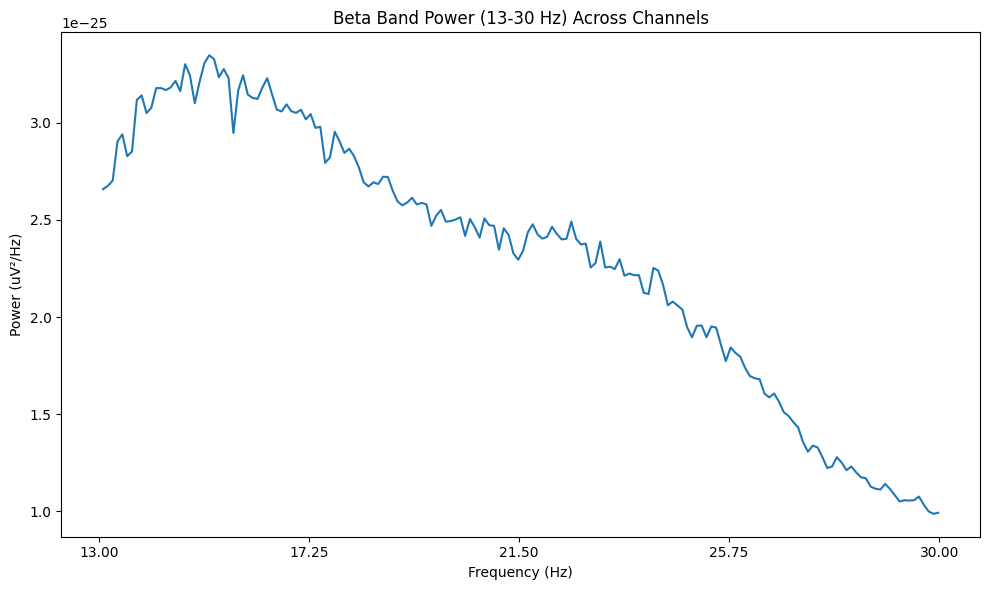

Extracted Beta Band Power (13-30 Hz) successfully.


In [208]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [209]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d105 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d105.head())
print(d105.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [210]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d105_clean = d105.replace([np.inf, -np.inf], np.nan)
d105_clean = d105_clean.fillna(d105_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d105_scaled = pd.DataFrame(
    scaler.fit_transform(d105_clean),
    columns=d105_clean.columns,
    index=d105_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d105_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d105_scaled.index,
    columns=d105_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d105_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df105 = d105_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df105["Pd_indicator_meg"] = 0

print("\nShape of df5:", df105.shape)
print(df105.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [211]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104, df105], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
5795    3.731776             0.066992          2.911134e-12  0.799930   
5796    4.050467             0.061721          2.626867e-12  0.787984   
5797    4.304673             0.058076          1.340606e-13  0.741705   
5798    4.015888             0.062253       

In [212]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105.to_csv('/content/drive/MyDrive/combined_features_upto_sub0105_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105 preserved.")


RAM Used After Cleanup: 1.06 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105 preserved.


sub-106

In [213]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-106'  # Replace with your folder path


In [214]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-106_scans.tsv', 'meg']


In [215]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-106_coordsystem.json', 'sub-106_task-go_run-1_proc-tsss+mc_events.json', 'sub-106_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-106_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-106_task-go_run-1_proc-tsss+mc_meg.json', 'sub-106_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-106_task-noise_proc-tsss_channels.tsv', 'sub-106_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-106_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-106_task-passive_run-1_proc-tsss+mc_events.json', 'sub-106_task-noise_proc-tsss_meg.json', 'sub-106_task-noise_proc-tsss_meg.fif', 'sub-106_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-106_task-rest_run-1_proc-tsss+mc_events.json', 'sub-106_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-106_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-106_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-106_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-106_task-rest_run-1_proc-tsss+mc_meg.fif']


In [216]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-106_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-106_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-106_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-106_task-rest_run-1_proc-tsss+mc_meg.fif']


In [217]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-106/meg/sub-106_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [218]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-106/meg/sub-106_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 147000 ... 1215999 =    147.000 ...  1215.999 secs
Ready.
Reading 0 ... 1068999  =      0.000 ...  1068.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


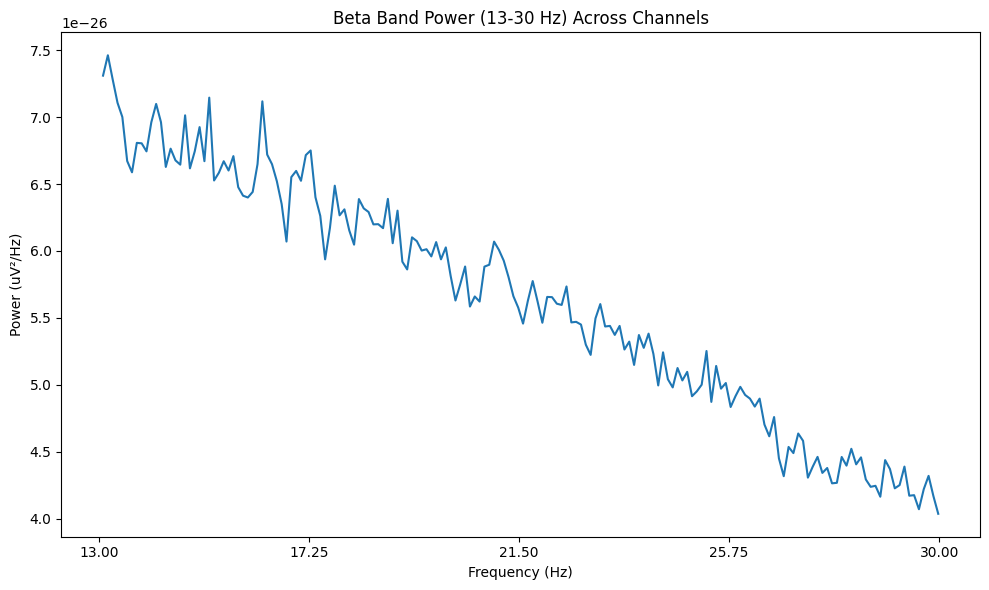

Extracted Beta Band Power (13-30 Hz) successfully.


In [219]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [220]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d106 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d106.head())
print(d106.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of top 58 channels

In [221]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d106_clean = d106.replace([np.inf, -np.inf], np.nan)
d106_clean = d106_clean.fillna(d106_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d106_scaled = pd.DataFrame(
    scaler.fit_transform(d106_clean),
    columns=d106_clean.columns,
    index=d106_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d106_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d106_scaled.index,
    columns=d106_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d106_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df106 = d106_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df106["Pd_indicator_meg"] = 1

print("\nShape of df5:", df106.shape)
print(df106.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [222]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105, df106], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
5853    4.671656             0.053514          2.083245e-12  0.733471   
5854    4.505145             0.055492          1.878063e-12  0.760596   
5855    4.627689             0.054023          1.036688e-13  0.720287   
5856    4.527596             0.055217    

In [223]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106.to_csv('/content/drive/MyDrive/combined_features_upto_sub0106_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106 preserved.")


RAM Used After Cleanup: 1.08 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106 preserved.


sub-107

In [224]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-107'  # Replace with your folder path


In [225]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-107_scans.tsv', 'meg']


In [226]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-107_coordsystem.json', 'sub-107_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-107_task-go_run-1_proc-tsss+mc_events.json', 'sub-107_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-107_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-107_task-go_run-1_proc-tsss+mc_meg.json', 'sub-107_task-noise_proc-tsss_channels.tsv', 'sub-107_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-107_task-passive_run-1_proc-tsss+mc_events.json', 'sub-107_task-noise_proc-tsss_meg.json', 'sub-107_task-noise_proc-tsss_meg.fif', 'sub-107_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-107_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-107_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-107_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-107_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-107_task-rest_run-1_proc-tsss+mc_events.json', 'sub-107_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-107_task-rest_run-1_proc-tsss+mc_meg.json']


In [227]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-107_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-107_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-107_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-107_task-rest_run-1_proc-tsss+mc_meg.fif']


In [228]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-107/meg/sub-107_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [229]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-107/meg/sub-107_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 167000 ... 1239999 =    167.000 ...  1239.999 secs
Ready.
Reading 0 ... 1072999  =      0.000 ...  1072.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fittin

Computing Power Spectral Density

Effective window size : 10.240 (s)


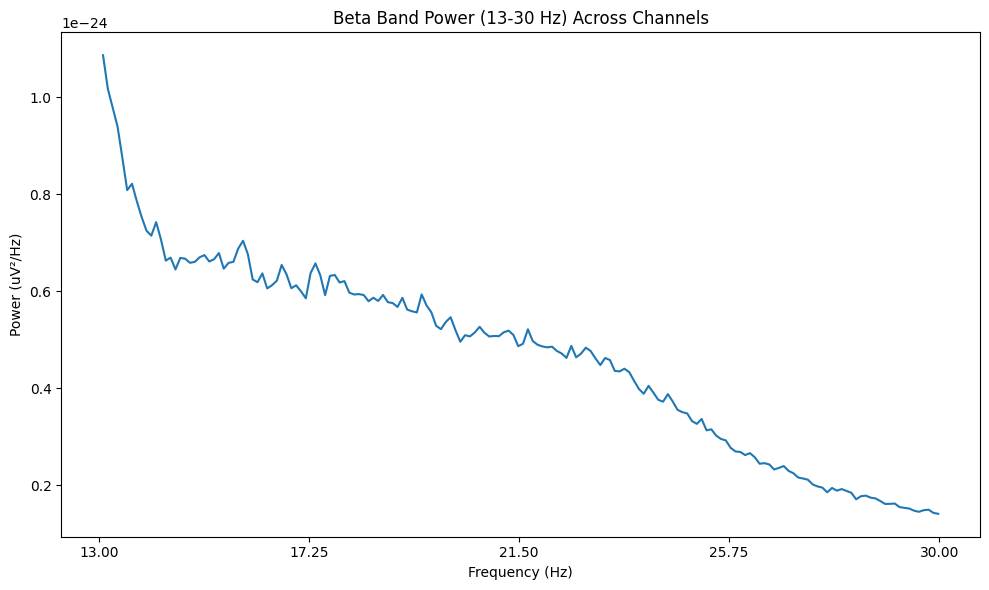

Extracted Beta Band Power (13-30 Hz) successfully.


In [230]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [231]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d107 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d107.head())
print(d107.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [232]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d107_clean = d107.replace([np.inf, -np.inf], np.nan)
d107_clean = d107_clean.fillna(d107_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d107_scaled = pd.DataFrame(
    scaler.fit_transform(d107_clean),
    columns=d107_clean.columns,
    index=d107_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d107_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d107_scaled.index,
    columns=d107_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d107_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df107 = d107_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df107["Pd_indicator_meg"] = 1

print("\nShape of df5:", df107.shape)
print(df107.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [233]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106, df107], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
5911    3.783784             0.066071          4.787196e-12  0.878235   
5912    3.685927             0.067826          4.488166e-12  0.886387   
5913    3.763281             0.066431          2.437402e-13  0.843017   
5914    3.796831             0.065844 

In [234]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107.to_csv('/content/drive/MyDrive/combined_features_upto_sub0107_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107 preserved.")


RAM Used After Cleanup: 1.07 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107 preserved.


sub-108

In [235]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-108'  # Replace with your folder path


In [236]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-108_scans.tsv', 'meg']


In [237]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-108_coordsystem.json', 'sub-108_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-108_task-go_run-1_proc-tsss+mc_events.json', 'sub-108_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-108_task-go_run-1_proc-tsss+mc_meg.json', 'sub-108_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-108_task-noise_proc-tsss_channels.tsv', 'sub-108_task-passive_run-1_proc-tsss+mc_events.json', 'sub-108_task-noise_proc-tsss_meg.json', 'sub-108_task-noise_proc-tsss_meg.fif', 'sub-108_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-108_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-108_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-108_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-108_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-108_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-108_task-rest_run-1_proc-tsss+mc_events.json', 'sub-108_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-108_task-rest_run-1_proc-tsss+mc_meg.json']


In [238]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-108_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-108_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-108_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-108_task-rest_run-1_proc-tsss+mc_meg.fif']


In [239]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-108/meg/sub-108_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [240]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-108/meg/sub-108_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 62000 ... 1144999 =     62.000 ...  1144.999 secs
Ready.
Reading 0 ... 1082999  =      0.000 ...  1082.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


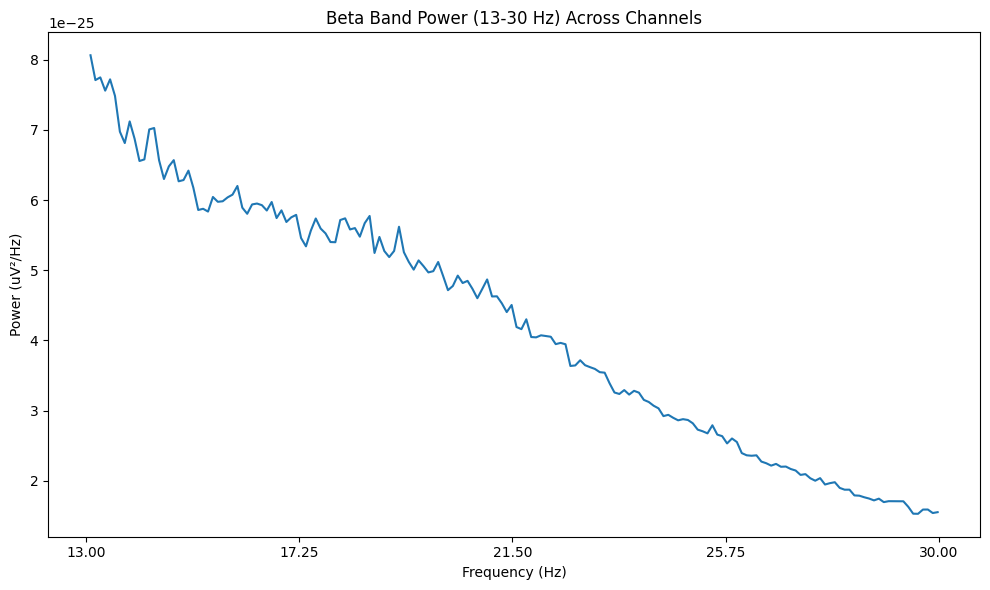

Extracted Beta Band Power (13-30 Hz) successfully.


In [241]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [242]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d108 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d108.head())
print(d108.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [243]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d108_clean = d108.replace([np.inf, -np.inf], np.nan)
d108_clean = d108_clean.fillna(d108_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d108_scaled = pd.DataFrame(
    scaler.fit_transform(d108_clean),
    columns=d108_clean.columns,
    index=d108_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d108_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d108_scaled.index,
    columns=d108_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d108_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df108 = d108_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df108["Pd_indicator_meg"] = 1

print("\nShape of df5:", df108.shape)
print(df108.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [244]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107, df108], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
5969    4.104340             0.060911          3.590254e-12  0.873831   
5970    4.242844             0.058923          3.441130e-12  0.818201   
5971    4.157895             0.060127          1.879838e-13  0.803797   
5972    4.166205             0.0600

In [245]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108.to_csv('/content/drive/MyDrive/combined_features_upto_sub0108_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108 preserved.")


RAM Used After Cleanup: 1.06 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108 preserved.


sub-109

In [246]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-109'  # Replace with your folder path


In [247]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-109_scans.tsv', 'meg']


In [248]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-109_coordsystem.json', 'sub-109_task-go_run-1_proc-tsss+mc_events.json', 'sub-109_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-109_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-109_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-109_task-noise_proc-tsss_channels.tsv', 'sub-109_task-noise_proc-tsss_meg.fif', 'sub-109_task-go_run-1_proc-tsss+mc_meg.json', 'sub-109_task-noise_proc-tsss_meg.json', 'sub-109_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-109_task-passive_run-1_proc-tsss+mc_events.json', 'sub-109_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-109_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-109_task-rest_run-1_proc-tsss+mc_events.json', 'sub-109_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-109_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-109_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-109_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-109_task-rest_run-1_proc-tsss+mc_meg.json']


In [249]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-109_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-109_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-109_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-109_task-rest_run-1_proc-tsss+mc_meg.fif']


In [250]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-109/meg/sub-109_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [251]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-109/meg/sub-109_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 67000 ... 1142999 =     67.000 ...  1142.999 secs
Ready.
Reading 0 ... 1075999  =      0.000 ...  1075.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


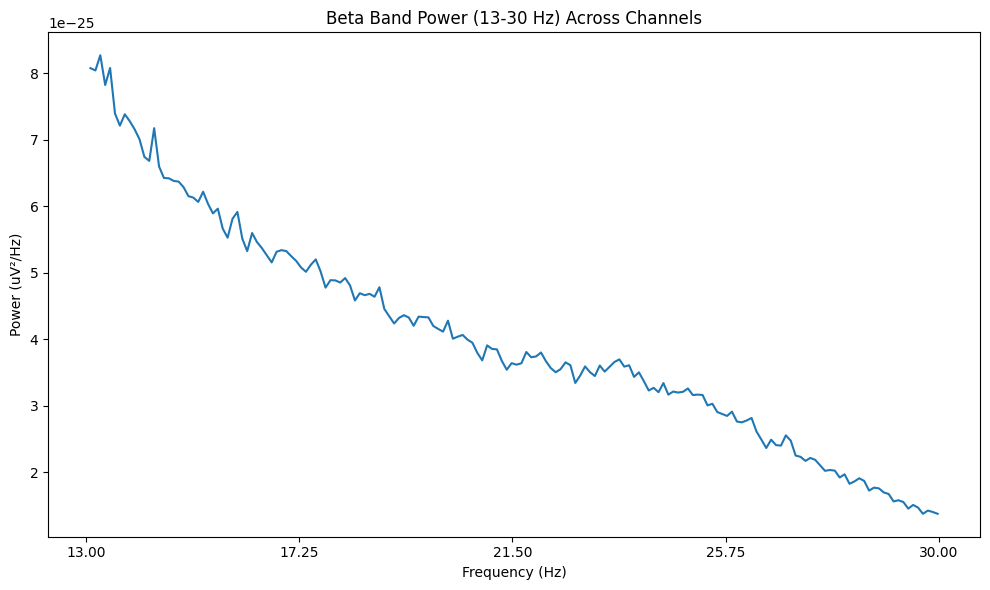

Extracted Beta Band Power (13-30 Hz) successfully.


In [252]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [253]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d109 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d109.head())
print(d109.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [254]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d109_clean = d109.replace([np.inf, -np.inf], np.nan)
d109_clean = d109_clean.fillna(d109_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d109_scaled = pd.DataFrame(
    scaler.fit_transform(d109_clean),
    columns=d109_clean.columns,
    index=d109_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d109_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d109_scaled.index,
    columns=d109_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d109_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df109 = d109_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df109["Pd_indicator_meg"] = 0

print("\nShape of df5:", df109.shape)
print(df109.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [255]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108, df109], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
6027    4.196097             0.059569          3.531428e-12  0.904294   
6028    4.157063             0.060139          3.965952e-12  0.969551   
6029    4.104089             0.060915          2.378887e-13  0.915419   
6030    4.139405             0.0

In [256]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109.to_csv('/content/drive/MyDrive/combined_features_upto_sub0109_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109 preserved.")


RAM Used After Cleanup: 1.06 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109 preserved.


sub-110

In [257]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-110'  # Replace with your folder path


In [258]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-110_scans.tsv', 'meg']


In [259]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-110_coordsystem.json', 'sub-110_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-110_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-110_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-110_task-go_run-1_proc-tsss+mc_events.json', 'sub-110_task-noise_proc-tsss_channels.tsv', 'sub-110_task-noise_proc-tsss_meg.fif', 'sub-110_task-go_run-1_proc-tsss+mc_meg.json', 'sub-110_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-110_task-noise_proc-tsss_meg.json', 'sub-110_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-110_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-110_task-passive_run-1_proc-tsss+mc_events.json', 'sub-110_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-110_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-110_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-110_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-110_task-rest_run-1_proc-tsss+mc_events.json', 'sub-110_task-rest_run-1_proc-tsss+mc_meg.json']


In [260]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-110_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-110_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-110_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-110_task-rest_run-1_proc-tsss+mc_meg.fif']


In [261]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-110/meg/sub-110_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [262]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-110/meg/sub-110_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 91000 ... 1183999 =     91.000 ...  1183.999 secs
Ready.
Reading 0 ... 1092999  =      0.000 ...  1092.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting

Computing Power Spectral Density

Effective window size : 10.240 (s)


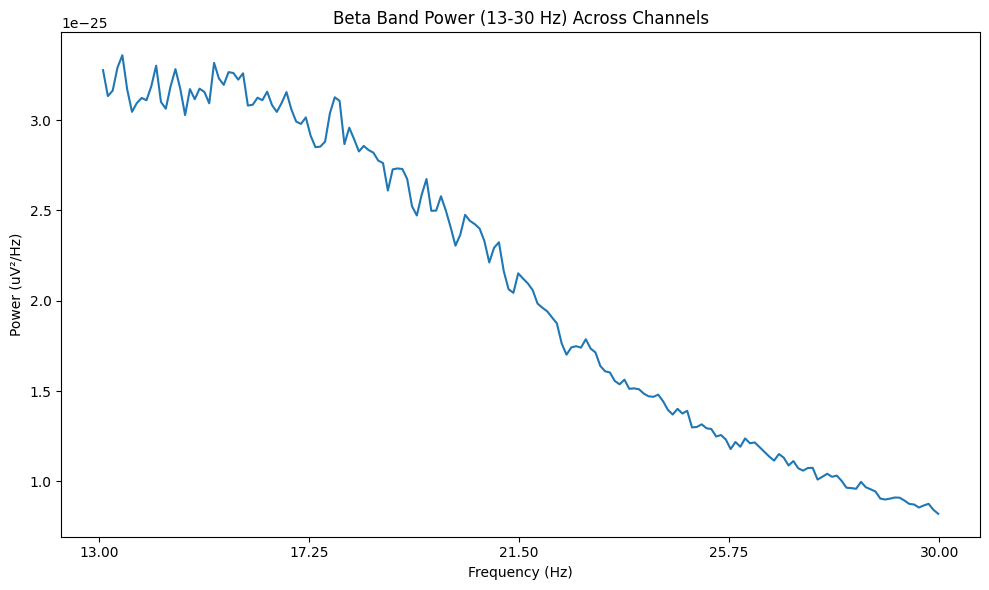

Extracted Beta Band Power (13-30 Hz) successfully.


In [263]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [264]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d110 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d110.head())
print(d110.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [265]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d110_clean = d110.replace([np.inf, -np.inf], np.nan)
d110_clean = d110_clean.fillna(d110_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d110_scaled = pd.DataFrame(
    scaler.fit_transform(d110_clean),
    columns=d110_clean.columns,
    index=d110_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d110_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d110_scaled.index,
    columns=d110_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d110_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df110 = d110_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df110["Pd_indicator_meg"] = 1

print("\nShape of df5:", df110.shape)
print(df110.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [266]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109, df110], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
6085    3.621226             0.069037          3.245596e-12  0.865982   
6086    3.806038             0.065673          2.965475e-12  0.872375   
6087    3.900274             0.064098          1.538933e-13  0.857460   
6088    3.984446             

In [267]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110.to_csv('/content/drive/MyDrive/combined_features_upto_sub0110_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110 preserved.")


RAM Used After Cleanup: 1.09 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110 preserved.


sub-111

In [268]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-111'  # Replace with your folder path


In [269]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-111_scans.tsv', 'meg']


In [270]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-111_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-111_task-go_run-1_proc-tsss+mc_events.json', 'sub-111_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-111_coordsystem.json', 'sub-111_task-go_run-1_proc-tsss+mc_meg.json', 'sub-111_task-noise_proc-tsss_channels.tsv', 'sub-111_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-111_task-noise_proc-tsss_meg.fif', 'sub-111_task-passive_run-1_proc-tsss+mc_events.json', 'sub-111_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-111_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-111_task-noise_proc-tsss_meg.json', 'sub-111_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-111_task-rest_run-1_proc-tsss+mc_events.json', 'sub-111_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-111_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-111_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-111_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-111_task-rest_run-1_proc-tsss+mc_meg.json']


In [271]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-111_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-111_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-111_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-111_task-rest_run-1_proc-tsss+mc_meg.fif']


In [272]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-111/meg/sub-111_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [273]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-111/meg/sub-111_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 26000 ... 1097999 =     26.000 ...  1097.999 secs
Ready.
Reading 0 ... 1071999  =      0.000 ...  1071.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


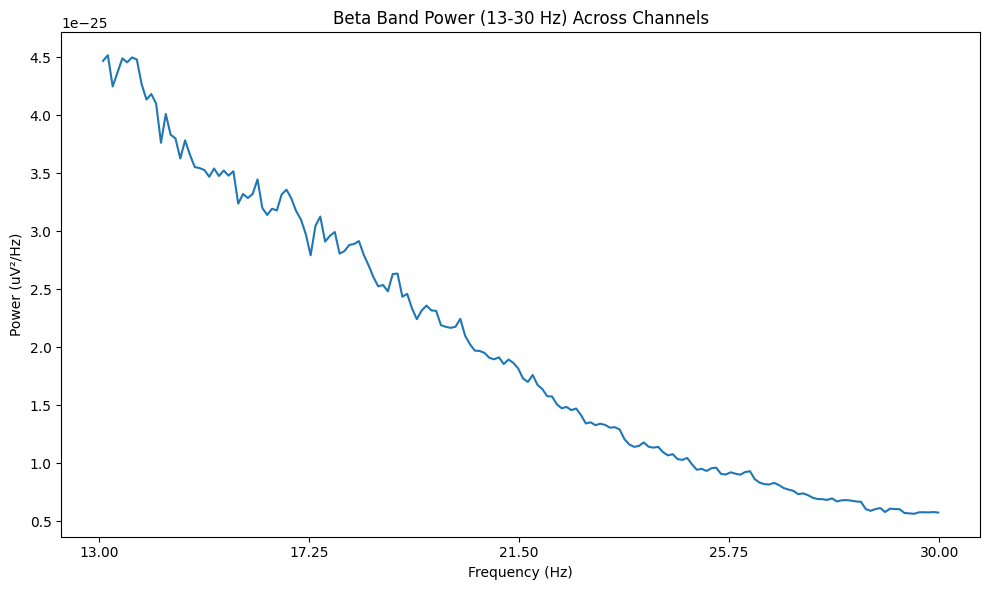

Extracted Beta Band Power (13-30 Hz) successfully.


In [274]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [275]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d111 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d111.head())
print(d111.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [276]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d111_clean = d111.replace([np.inf, -np.inf], np.nan)
d111_clean = d111_clean.fillna(d111_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d111_scaled = pd.DataFrame(
    scaler.fit_transform(d111_clean),
    columns=d111_clean.columns,
    index=d111_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d111_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d111_scaled.index,
    columns=d111_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d111_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df111 = d111_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df111["Pd_indicator_meg"] = 0

print("\nShape of df5:", df111.shape)
print(df111.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [277]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110, df111], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
6143    3.830224             0.065270          3.955515e-12  0.888131   
6144    3.355410             0.074507          4.153244e-12  0.984246   
6145    3.502799             0.071372          2.173818e-13  1.022820   
6146    3.551306          

In [278]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111.to_csv('/content/drive/MyDrive/combined_features_upto_sub0111_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111 preserved.")


RAM Used After Cleanup: 1.09 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111 preserved.


sub-112

In [279]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-112'  # Replace with your folder path


In [280]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-112_scans.tsv', 'meg']


In [281]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-112_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-112_task-go_run-1_proc-tsss+mc_events.json', 'sub-112_coordsystem.json', 'sub-112_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-112_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-112_task-go_run-1_proc-tsss+mc_meg.json', 'sub-112_task-noise_proc-tsss_channels.tsv', 'sub-112_task-noise_proc-tsss_meg.fif', 'sub-112_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-112_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-112_task-passive_run-1_proc-tsss+mc_events.json', 'sub-112_task-noise_proc-tsss_meg.json', 'sub-112_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-112_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-112_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-112_task-rest_run-1_proc-tsss+mc_events.json', 'sub-112_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-112_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-112_task-rest_run-1_proc-tsss+mc_meg.json']


In [282]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-112_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-112_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-112_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-112_task-rest_run-1_proc-tsss+mc_meg.fif']


In [283]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-112/meg/sub-112_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [284]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-112/meg/sub-112_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 84000 ... 1161999 =     84.000 ...  1161.999 secs
Ready.
Reading 0 ... 1077999  =      0.000 ...  1077.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spetral Density

Effective window size : 10.240 (s)


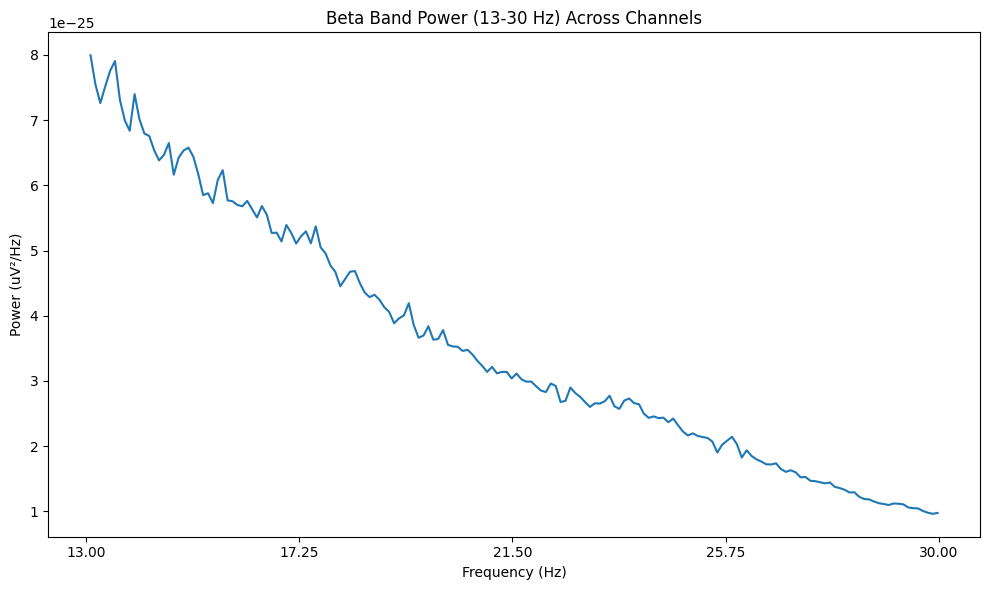

Extracted Beta Band Power (13-30 Hz) successfully.


In [285]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [286]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d112 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d112.head())
print(d112.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [287]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d112_clean = d112.replace([np.inf, -np.inf], np.nan)
d112_clean = d112_clean.fillna(d112_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d112_scaled = pd.DataFrame(
    scaler.fit_transform(d112_clean),
    columns=d112_clean.columns,
    index=d112_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d112_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d112_scaled.index,
    columns=d112_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d112_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df112 = d112_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df112["Pd_indicator_meg"] = 1

print("\nShape of df5:", df112.shape)
print(df112.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [288]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111, df112], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
6201    4.217996             0.059270          2.848726e-12  0.789672   
6202    4.114100             0.060758          2.802565e-12  0.834061   
6203    4.033395             0.061983          1.746019e-13  0.817783   
6204    4.117811       

In [289]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112.to_csv('/content/drive/MyDrive/combined_features_upto_sub0112_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112 preserved.")


RAM Used After Cleanup: 1.09 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112 preserved.


sub-113

In [290]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-113'  # Replace with your folder path


In [291]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-113_scans.tsv', 'meg']


In [292]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-113_task-go_run-1_proc-tsss+mc_events.json', 'sub-113_coordsystem.json', 'sub-113_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-113_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-113_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-113_task-go_run-1_proc-tsss+mc_meg.json', 'sub-113_task-noise_proc-tsss_channels.tsv', 'sub-113_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-113_task-passive_run-1_proc-tsss+mc_events.json', 'sub-113_task-noise_proc-tsss_meg.json', 'sub-113_task-noise_proc-tsss_meg.fif', 'sub-113_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-113_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-113_task-rest_run-1_proc-tsss+mc_events.json', 'sub-113_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-113_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-113_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-113_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-113_task-rest_run-1_proc-tsss+mc_meg.fif']


In [293]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-113_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-113_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-113_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-113_task-rest_run-1_proc-tsss+mc_meg.fif']


In [294]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-113/meg/sub-113_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [295]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-113/meg/sub-113_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 48000 ... 1119999 =     48.000 ...  1119.999 secs
Ready.
Reading 0 ... 1071999  =      0.000 ...  1071.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


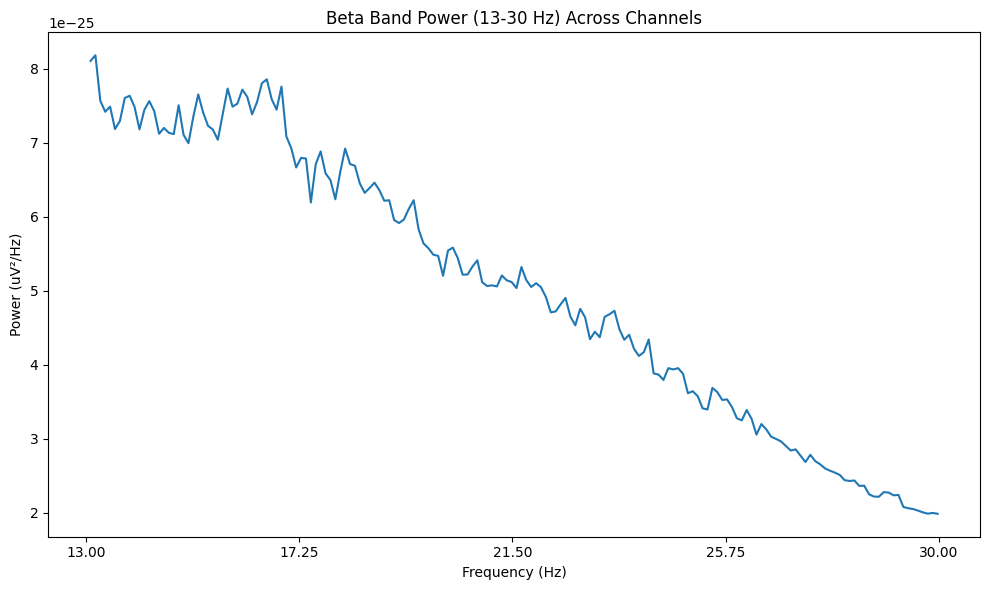

Extracted Beta Band Power (13-30 Hz) successfully.


In [296]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [297]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d113 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d113.head())
print(d113.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [298]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d113_clean = d113.replace([np.inf, -np.inf], np.nan)
d113_clean = d113_clean.fillna(d113_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d113_scaled = pd.DataFrame(
    scaler.fit_transform(d113_clean),
    columns=d113_clean.columns,
    index=d113_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d113_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d113_scaled.index,
    columns=d113_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d113_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df113 = d113_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df113["Pd_indicator_meg"] = 1

print("\nShape of df5:", df113.shape)
print(df113.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [299]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112, df113], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
6259    3.894590             0.064192          4.172663e-12  0.934458   
6260    4.010261             0.062327          4.160188e-12  0.868869   
6261    4.014925             0.062268          2.619965e-13  0.899027   
6262    3.953358    

In [300]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113.to_csv('/content/drive/MyDrive/combined_features_upto_sub0113_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113 preserved.")


RAM Used After Cleanup: 1.09 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113 preserved.


sub-114

In [301]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-114'  # Replace with your folder path


In [302]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-114_scans.tsv', 'meg']


In [303]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-114_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-114_coordsystem.json', 'sub-114_task-go_run-1_proc-tsss+mc_events.json', 'sub-114_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-114_task-go_run-1_proc-tsss+mc_meg.json', 'sub-114_task-noise_proc-tsss_channels.tsv', 'sub-114_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-114_task-passive_run-1_proc-tsss+mc_events.json', 'sub-114_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-114_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-114_task-noise_proc-tsss_meg.json', 'sub-114_task-noise_proc-tsss_meg.fif', 'sub-114_task-rest_run-1_proc-tsss+mc_events.json', 'sub-114_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-114_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-114_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-114_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-114_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-114_task-rest_run-1_proc-tsss+mc_meg.json']


In [304]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-114_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-114_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-114_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-114_task-rest_run-1_proc-tsss+mc_meg.fif']


In [305]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-114/meg/sub-114_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [306]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-114/meg/sub-114_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 206000 ... 1279999 =    206.000 ...  1279.999 secs
Ready.
Reading 0 ... 1073999  =      0.000 ...  1073.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


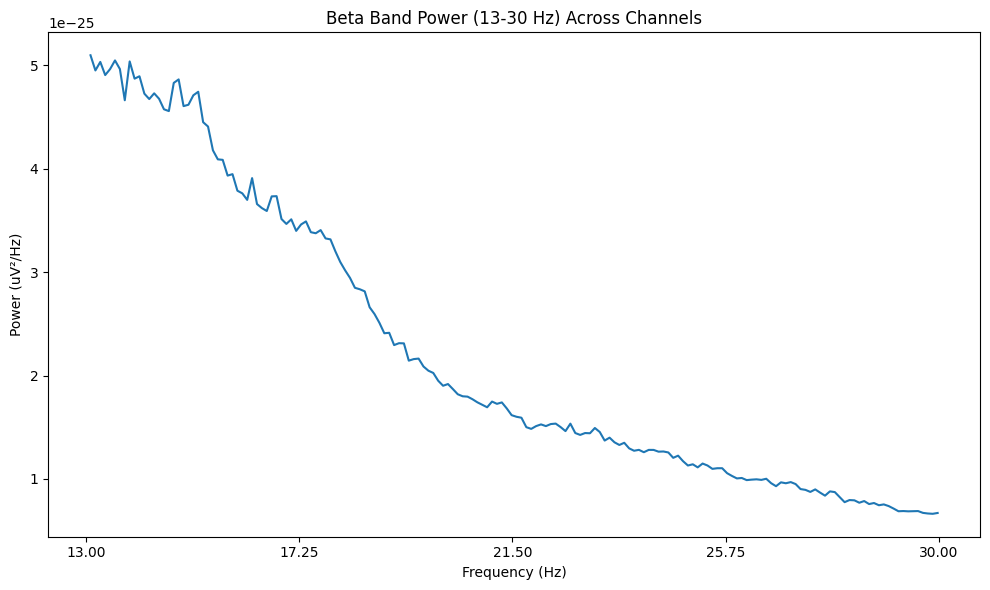

Extracted Beta Band Power (13-30 Hz) successfully.


In [307]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [308]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d114 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d114.head())
print(d114.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [309]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d114_clean = d114.replace([np.inf, -np.inf], np.nan)
d114_clean = d114_clean.fillna(d114_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d114_scaled = pd.DataFrame(
    scaler.fit_transform(d114_clean),
    columns=d114_clean.columns,
    index=d114_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d114_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d114_scaled.index,
    columns=d114_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d114_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df114 = d114_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df114["Pd_indicator_meg"] = 0

print("\nShape of df5:", df114.shape)
print(df114.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [310]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113, df114], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
6317    4.350093             0.057470          2.450265e-12  0.764872   
6318    4.282123             0.058382          2.719272e-12  0.850860   
6319    4.145251             0.060310          1.447249e-13  0.809662   
6320    4.208566 

In [311]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114.to_csv('/content/drive/MyDrive/combined_features_upto_sub0114_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114 preserved.")


RAM Used After Cleanup: 1.09 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114 preserved.


sub-115

In [312]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-115'  # Replace with your folder path


In [313]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-115_scans.tsv', 'meg']


In [314]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-115_coordsystem.json', 'sub-115_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-115_task-go_run-1_proc-tsss+mc_events.json', 'sub-115_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-115_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-115_task-go_run-1_proc-tsss+mc_meg.json', 'sub-115_task-noise_proc-tsss_channels.tsv', 'sub-115_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-115_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-115_task-noise_proc-tsss_meg.fif', 'sub-115_task-passive_run-1_proc-tsss+mc_events.json', 'sub-115_task-noise_proc-tsss_meg.json', 'sub-115_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-115_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-115_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-115_task-rest_run-1_proc-tsss+mc_events.json', 'sub-115_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-115_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-115_task-rest_run-1_proc-tsss+mc_meg.fif']


In [315]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-115_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-115_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-115_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-115_task-rest_run-1_proc-tsss+mc_meg.fif']


In [316]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-115/meg/sub-115_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [317]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-115/meg/sub-115_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 269000 ... 1340999 =    269.000 ...  1340.999 secs
Ready.
Reading 0 ... 1071999  =      0.000 ...  1071.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


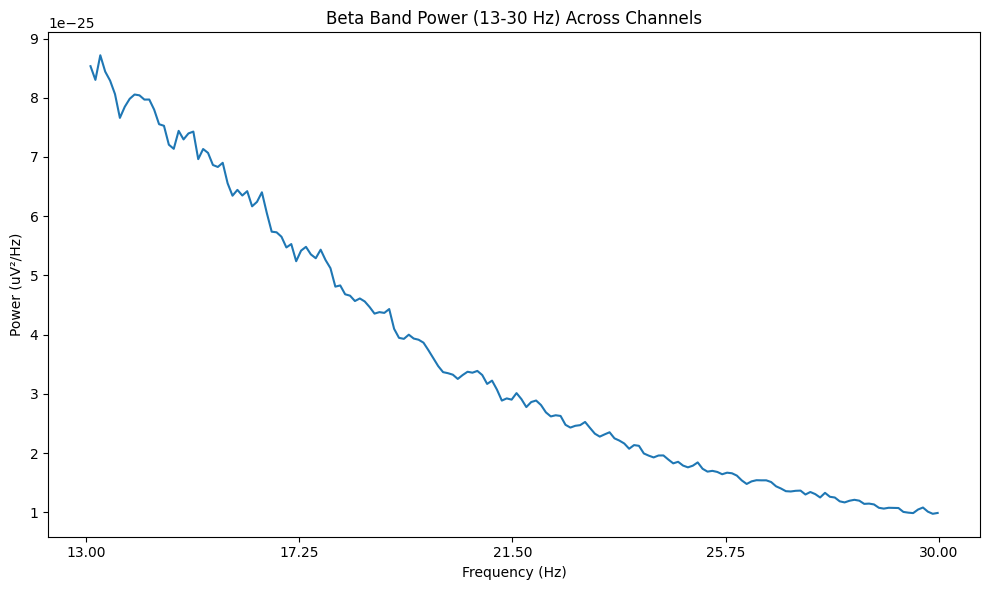

Extracted Beta Band Power (13-30 Hz) successfully.


In [318]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [319]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d115 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d115.head())
print(d115.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [320]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d115_clean = d115.replace([np.inf, -np.inf], np.nan)
d115_clean = d115_clean.fillna(d115_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d115_scaled = pd.DataFrame(
    scaler.fit_transform(d115_clean),
    columns=d115_clean.columns,
    index=d115_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d115_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d115_scaled.index,
    columns=d115_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d115_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df115 = d115_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df115["Pd_indicator_meg"] = 1

print("\nShape of df5:", df115.shape)
print(df115.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [321]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114, df115], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
6375    3.966418             0.063029          4.947028e-12  0.812382   
6376    3.986940             0.062705          4.402356e-12  0.874827   
6377    3.890858             0.064253          2.803486e-13  0.869826   
6378    3.9794

In [322]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115.to_csv('/content/drive/MyDrive/combined_features_upto_sub0115_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115 preserved.")


RAM Used After Cleanup: 1.07 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115 preserved.


sub-116

In [323]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-116'  # Replace with your folder path


In [324]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-116_scans.tsv', 'meg']


In [325]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-116_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-116_coordsystem.json', 'sub-116_task-go_run-1_proc-tsss+mc_events.json', 'sub-116_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-116_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-116_task-noise_proc-tsss_meg.fif', 'sub-116_task-noise_proc-tsss_channels.tsv', 'sub-116_task-go_run-1_proc-tsss+mc_meg.json', 'sub-116_task-noise_proc-tsss_meg.json', 'sub-116_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-116_task-passive_run-1_proc-tsss+mc_events.json', 'sub-116_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-116_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-116_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-116_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-116_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-116_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-116_task-rest_run-1_proc-tsss+mc_events.json', 'sub-116_task-rest_run-1_proc-tsss+mc_meg.json']


In [326]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-116_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-116_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-116_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-116_task-rest_run-1_proc-tsss+mc_meg.fif']


In [327]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-116/meg/sub-116_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [328]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-116/meg/sub-116_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 43000 ... 1116999 =     43.000 ...  1116.999 secs
Ready.
Reading 0 ... 1073999  =      0.000 ...  1073.999 secs...
Finding events on: STI101
302 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
302 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


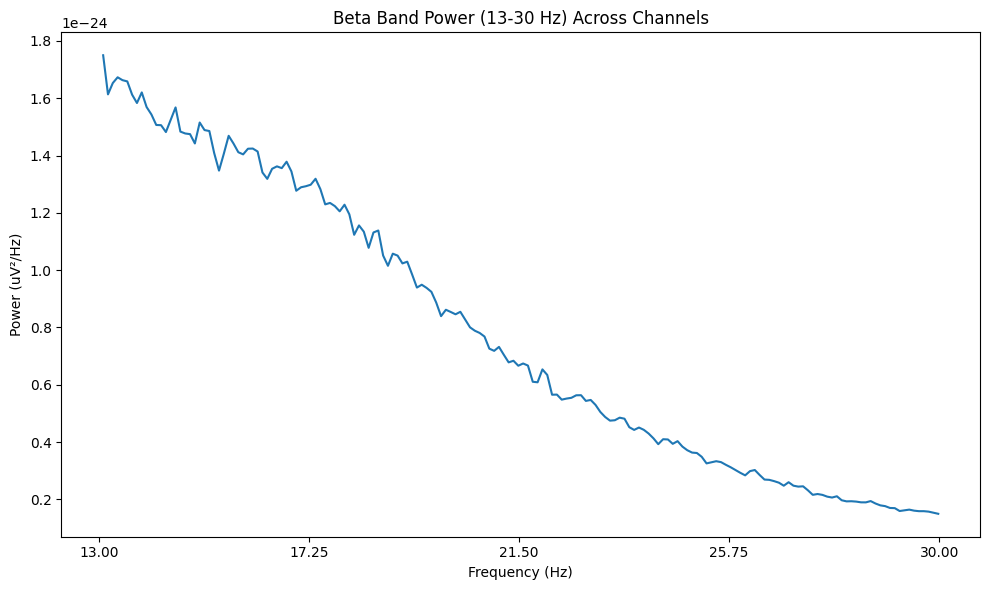

Extracted Beta Band Power (13-30 Hz) successfully.


In [329]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [330]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d116 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d116.head())
print(d116.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [331]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d116_clean = d116.replace([np.inf, -np.inf], np.nan)
d116_clean = d116_clean.fillna(d116_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d116_scaled = pd.DataFrame(
    scaler.fit_transform(d116_clean),
    columns=d116_clean.columns,
    index=d116_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d116_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d116_scaled.index,
    columns=d116_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d116_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df116 = d116_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df116["Pd_indicator_meg"] = 0

print("\nShape of df5:", df116.shape)
print(df116.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [332]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115, df116], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
6433    3.777467             0.066182          6.039124e-12  0.889440   
6434    3.861266             0.064746          5.404446e-12  0.857433   
6435    3.684358             0.067854          3.082363e-13  0.873323   
6436    3.8

In [333]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116.to_csv('/content/drive/MyDrive/combined_features_upto_sub0116_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116 preserved.")


RAM Used After Cleanup: 1.09 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116 preserved.


sub-118

In [334]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-118'  # Replace with your folder path


In [335]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-118_scans.tsv', 'meg']


In [336]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-118_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-118_coordsystem.json', 'sub-118_task-go_run-1_proc-tsss+mc_events.json', 'sub-118_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-118_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-118_task-noise_proc-tsss_channels.tsv', 'sub-118_task-go_run-1_proc-tsss+mc_meg.json', 'sub-118_task-noise_proc-tsss_meg.fif', 'sub-118_task-passive_run-1_proc-tsss+mc_events.json', 'sub-118_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-118_task-noise_proc-tsss_meg.json', 'sub-118_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-118_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-118_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-118_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-118_task-rest_run-1_proc-tsss+mc_events.json', 'sub-118_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-118_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-118_task-rest_run-1_proc-tsss+mc_meg.json']


In [337]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-118_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-118_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-118_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-118_task-rest_run-1_proc-tsss+mc_meg.fif']


In [338]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-118/meg/sub-118_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [339]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-118/meg/sub-118_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 182000 ... 1256999 =    182.000 ...  1256.999 secs
Ready.
Reading 0 ... 1074999  =      0.000 ...  1074.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


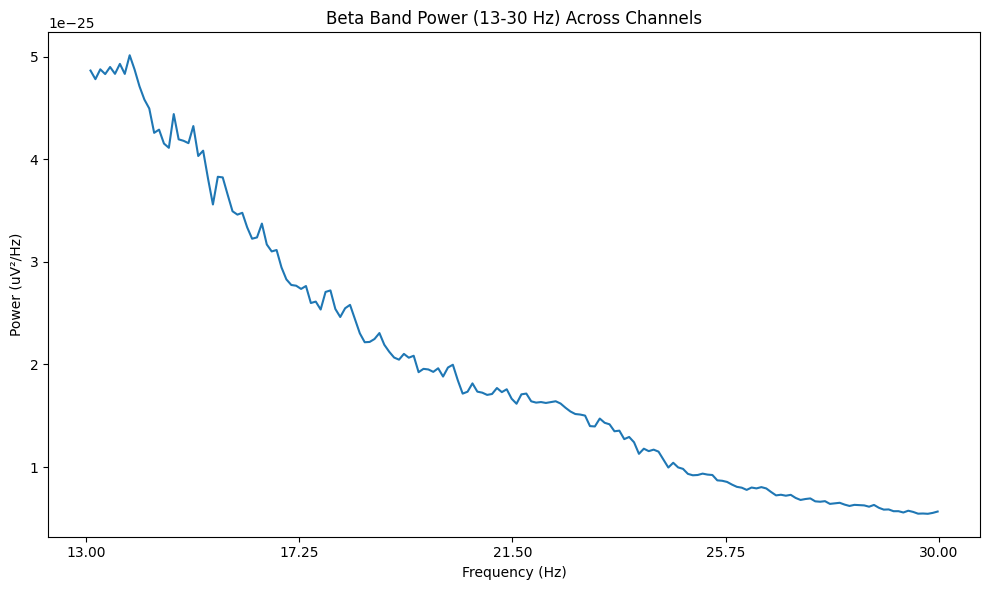

Extracted Beta Band Power (13-30 Hz) successfully.


In [340]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [341]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d118 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d118.head())
print(d118.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [342]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d118_clean = d118.replace([np.inf, -np.inf], np.nan)
d118_clean = d118_clean.fillna(d118_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d118_scaled = pd.DataFrame(
    scaler.fit_transform(d118_clean),
    columns=d118_clean.columns,
    index=d118_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d118_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d118_scaled.index,
    columns=d118_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d118_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df118 = d118_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df118["Pd_indicator_meg"] = 1

print("\nShape of df5:", df118.shape)
print(df118.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [343]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116, df118], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
6491    4.145116             0.060284          2.624851e-12  0.792186   
6492    4.224186             0.059171          2.344525e-12  0.806359   
6493    4.141395             0.060355          1.249238e-13  0.793284   
6494    

In [344]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118.to_csv('/content/drive/MyDrive/combined_features_upto_sub0118_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118 preserved.")


RAM Used After Cleanup: 1.09 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118 preserved.


sub-119

In [345]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-119'  # Replace with your folder path


In [346]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-119_scans.tsv', 'meg']


In [347]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-119_task-go_run-1_proc-tsss+mc_events.json', 'sub-119_coordsystem.json', 'sub-119_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-119_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-119_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-119_task-noise_proc-tsss_meg.fif', 'sub-119_task-noise_proc-tsss_channels.tsv', 'sub-119_task-go_run-1_proc-tsss+mc_meg.json', 'sub-119_task-noise_proc-tsss_meg.json', 'sub-119_task-passive_run-1_proc-tsss+mc_events.json', 'sub-119_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-119_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-119_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-119_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-119_task-rest_run-1_proc-tsss+mc_events.json', 'sub-119_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-119_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-119_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-119_task-rest_run-1_proc-tsss+mc_meg.json']


In [348]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-119_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-119_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-119_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-119_task-rest_run-1_proc-tsss+mc_meg.fif']


In [349]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-119/meg/sub-119_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [350]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-119/meg/sub-119_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 71000 ... 1142999 =     71.000 ...  1142.999 secs
Ready.
Reading 0 ... 1071999  =      0.000 ...  1071.999 secs...
Finding events on: STI101
300 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
300 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting

Computing Power Spectral Density

Effective window size : 10.240 (s)


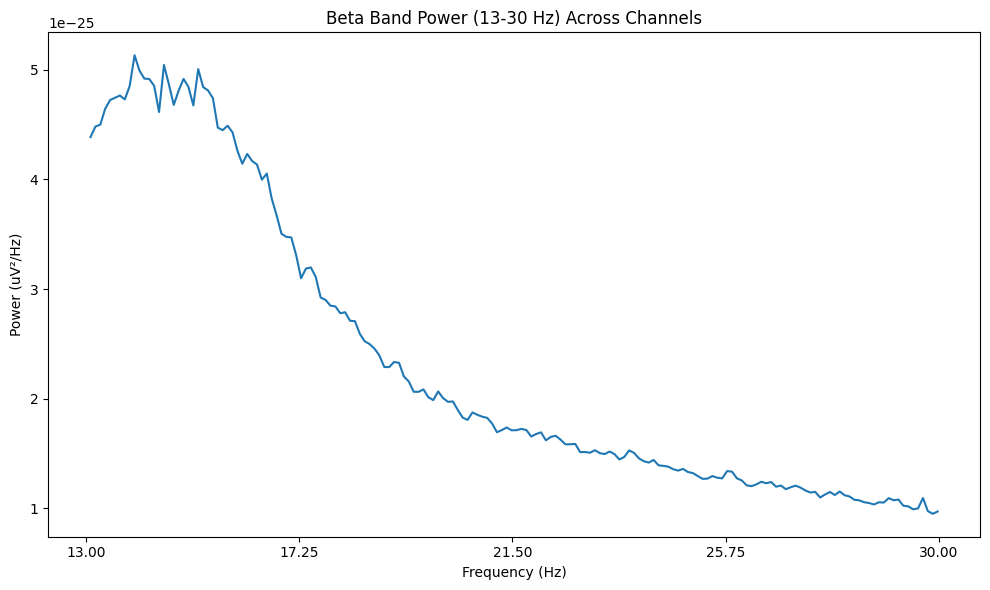

Extracted Beta Band Power (13-30 Hz) successfully.


In [351]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [352]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d119 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d119.head())
print(d119.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [353]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d119_clean = d119.replace([np.inf, -np.inf], np.nan)
d119_clean = d119_clean.fillna(d119_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d119_scaled = pd.DataFrame(
    scaler.fit_transform(d119_clean),
    columns=d119_clean.columns,
    index=d119_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d119_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d119_scaled.index,
    columns=d119_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d119_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df119 = d119_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df119["Pd_indicator_meg"] = 0

print("\nShape of df5:", df119.shape)
print(df119.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [354]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118, df119], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
6549    4.365672             0.057265          2.173217e-12  0.764092   
6550    4.419776             0.056564          2.161113e-12  0.778699   
6551    4.408582             0.056708          1.163811e-13  0.802598   
6552 

In [355]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119.to_csv('/content/drive/MyDrive/combined_features_upto_sub0119_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119 preserved.")


RAM Used After Cleanup: 1.09 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119 preserved.


sub-120

In [356]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-120'  # Replace with your folder path


In [357]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-120_scans.tsv', 'meg']


In [358]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-120_coordsystem.json', 'sub-120_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-120_task-go_run-1_proc-tsss+mc_events.json', 'sub-120_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-120_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-120_task-noise_proc-tsss_channels.tsv', 'sub-120_task-go_run-1_proc-tsss+mc_meg.json', 'sub-120_task-noise_proc-tsss_meg.fif', 'sub-120_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-120_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-120_task-passive_run-1_proc-tsss+mc_events.json', 'sub-120_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-120_task-noise_proc-tsss_meg.json', 'sub-120_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-120_task-rest_run-1_proc-tsss+mc_events.json', 'sub-120_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-120_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-120_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-120_task-rest_run-1_proc-tsss+mc_meg.json']


In [359]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-120_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-120_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-120_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-120_task-rest_run-1_proc-tsss+mc_meg.fif']


In [360]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-120/meg/sub-120_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [361]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-120/meg/sub-120_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 65000 ... 1185999 =     65.000 ...  1185.999 secs
Ready.
Reading 0 ... 1120999  =      0.000 ...  1120.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


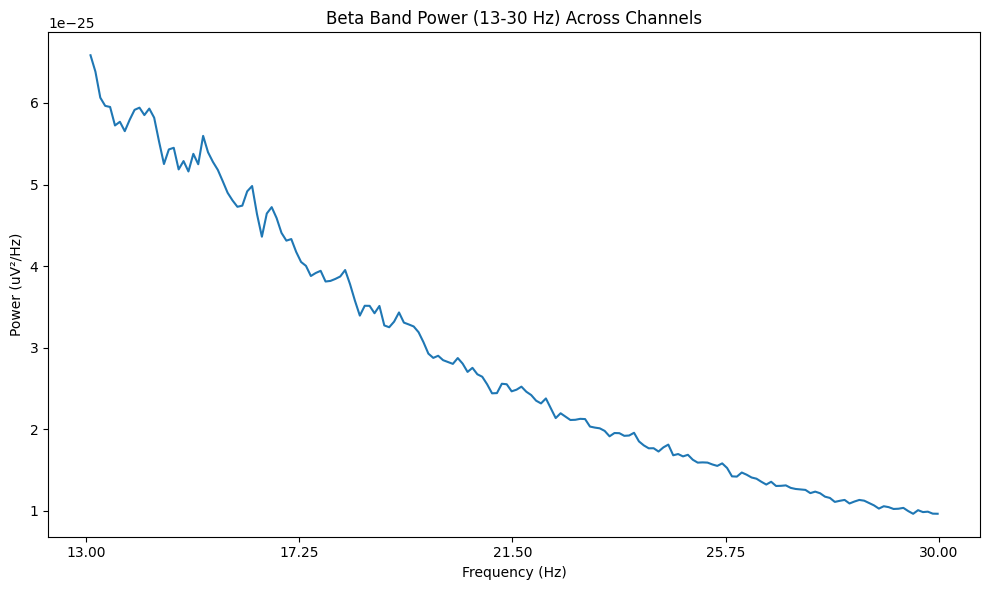

Extracted Beta Band Power (13-30 Hz) successfully.


In [362]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [363]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d120 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d120.head())
print(d120.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [364]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d120_clean = d120.replace([np.inf, -np.inf], np.nan)
d120_clean = d120_clean.fillna(d120_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d120_scaled = pd.DataFrame(
    scaler.fit_transform(d120_clean),
    columns=d120_clean.columns,
    index=d120_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d120_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d120_scaled.index,
    columns=d120_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d120_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df120 = d120_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df120["Pd_indicator_meg"] = 1

print("\nShape of df5:", df120.shape)
print(df120.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [365]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119, df120], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
6607    4.184657             0.059742          3.097316e-12  0.724716   
6608    4.189117             0.059678          2.800233e-12  0.791678   
6609    4.162355             0.060062          1.790726e-13  0.742263   
66

In [366]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120.to_csv('/content/drive/MyDrive/combined_features_upto_sub0120_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120 preserved.")


RAM Used After Cleanup: 1.10 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120 preserved.


sub-121

In [367]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-121'  # Replace with your folder path


In [368]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-121_scans.tsv', 'meg']


In [369]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-121_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-121_coordsystem.json', 'sub-121_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-121_task-go_run-1_proc-tsss+mc_events.json', 'sub-121_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-121_task-noise_proc-tsss_channels.tsv', 'sub-121_task-noise_proc-tsss_meg.fif', 'sub-121_task-go_run-1_proc-tsss+mc_meg.json', 'sub-121_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-121_task-noise_proc-tsss_meg.json', 'sub-121_task-passive_run-1_proc-tsss+mc_events.json', 'sub-121_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-121_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-121_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-121_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-121_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-121_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-121_task-rest_run-1_proc-tsss+mc_events.json', 'sub-121_task-rest_run-1_proc-tsss+mc_meg.json']


In [370]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-121_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-121_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-121_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-121_task-rest_run-1_proc-tsss+mc_meg.fif']


In [371]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-121/meg/sub-121_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [372]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-121/meg/sub-121_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 67000 ... 1149999 =     67.000 ...  1149.999 secs
Ready.
Reading 0 ... 1082999  =      0.000 ...  1082.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


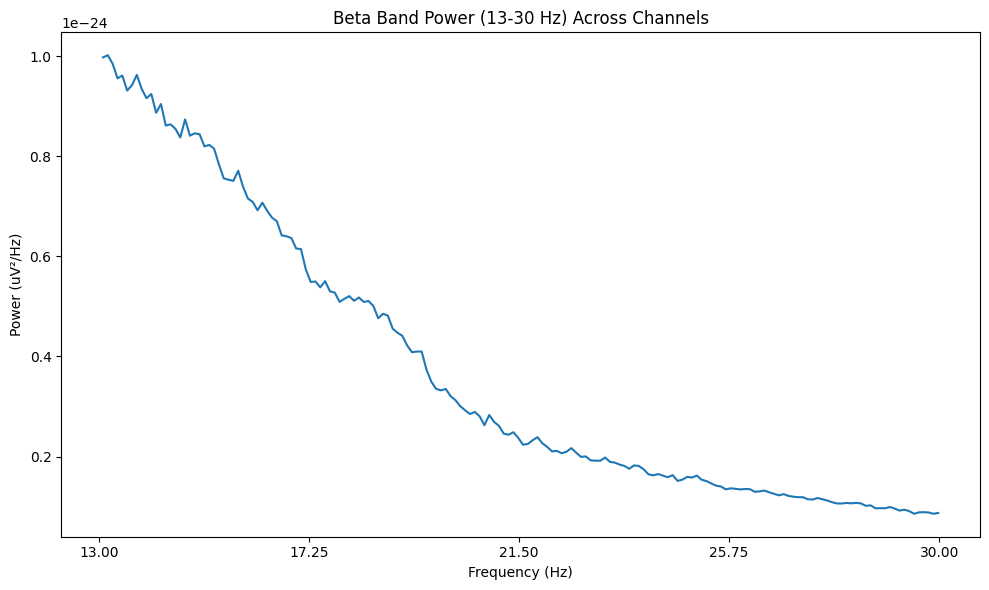

Extracted Beta Band Power (13-30 Hz) successfully.


In [373]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


feature Extraction

In [374]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d121 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d121.head())
print(d121.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [375]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d121_clean = d121.replace([np.inf, -np.inf], np.nan)
d121_clean = d121_clean.fillna(d121_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d121_scaled = pd.DataFrame(
    scaler.fit_transform(d121_clean),
    columns=d121_clean.columns,
    index=d121_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d121_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d121_scaled.index,
    columns=d121_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d121_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df121 = d121_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df121["Pd_indicator_meg"] = 1

print("\nShape of df5:", df121.shape)
print(df121.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [376]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120, df121], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
6665    3.945522             0.063323          2.644305e-12  0.846041   
6666    4.012927             0.062299          2.620905e-12  0.863341   
6667    3.791320             0.065940          1.511247e-13  0.863825   

In [377]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121.to_csv('/content/drive/MyDrive/combined_features_upto_sub0121_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121 preserved.")


RAM Used After Cleanup: 1.07 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121 preserved.


sub-122

In [378]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-122'  # Replace with your folder path


In [379]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-122_scans.tsv', 'meg']


In [380]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-122_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-122_coordsystem.json', 'sub-122_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-122_task-go_run-1_proc-tsss+mc_events.json', 'sub-122_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-122_task-go_run-1_proc-tsss+mc_meg.json', 'sub-122_task-noise_proc-tsss_channels.tsv', 'sub-122_task-noise_proc-tsss_meg.fif', 'sub-122_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-122_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-122_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-122_task-noise_proc-tsss_meg.json', 'sub-122_task-passive_run-1_proc-tsss+mc_events.json', 'sub-122_task-rest_run-1_proc-tsss+mc_events.json', 'sub-122_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-122_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-122_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-122_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-122_task-rest_run-1_proc-tsss+mc_meg.json']


In [381]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-122_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-122_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-122_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-122_task-rest_run-1_proc-tsss+mc_meg.fif']


In [382]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-122/meg/sub-122_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [383]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-122/meg/sub-122_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 20000 ... 1283999 =     20.000 ...  1283.999 secs
Ready.
Reading 0 ... 1263999  =      0.000 ...  1263.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


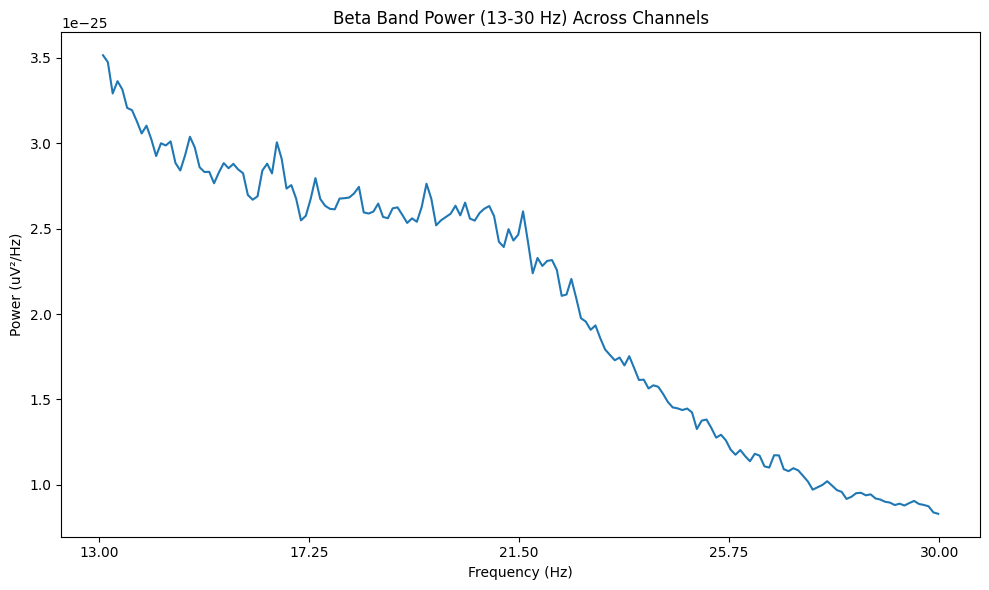

Extracted Beta Band Power (13-30 Hz) successfully.


In [384]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [385]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d122 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d122.head())
print(d122.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of top 58 channels

In [386]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d122_clean = d122.replace([np.inf, -np.inf], np.nan)
d122_clean = d122_clean.fillna(d122_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d122_scaled = pd.DataFrame(
    scaler.fit_transform(d122_clean),
    columns=d122_clean.columns,
    index=d122_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d122_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d122_scaled.index,
    columns=d122_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d122_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df122 = d122_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df122["Pd_indicator_meg"] = 1

print("\nShape of df5:", df122.shape)
print(df122.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [387]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121, df121], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
6723    3.945522             0.063323          2.644305e-12  0.846041   
6724    4.012927             0.062299          2.620905e-12  0.863341   
6725    3.791320             0.065940          1.511247e-13  0.863825

In [388]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122.to_csv('/content/drive/MyDrive/combined_features_upto_sub0122_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122 preserved.")


RAM Used After Cleanup: 1.17 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122 preserved.


sub-123

In [389]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-123'  # Replace with your folder path


In [390]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-123_scans.tsv', 'meg']


In [391]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-123_task-go_run-1_proc-tsss+mc_events.json', 'sub-123_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-123_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-123_coordsystem.json', 'sub-123_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-123_task-noise_proc-tsss_meg.fif', 'sub-123_task-noise_proc-tsss_channels.tsv', 'sub-123_task-go_run-1_proc-tsss+mc_meg.json', 'sub-123_task-passive_run-1_proc-tsss+mc_events.json', 'sub-123_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-123_task-noise_proc-tsss_meg.json', 'sub-123_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-123_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-123_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-123_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-123_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-123_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-123_task-rest_run-1_proc-tsss+mc_events.json', 'sub-123_task-rest_run-1_proc-tsss+mc_meg.json']


In [392]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-123_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-123_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-123_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-123_task-rest_run-1_proc-tsss+mc_meg.fif']


In [393]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-123/meg/sub-123_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [394]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-123/meg/sub-123_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 162000 ... 1244999 =    162.000 ...  1244.999 secs
Ready.
Reading 0 ... 1082999  =      0.000 ...  1082.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


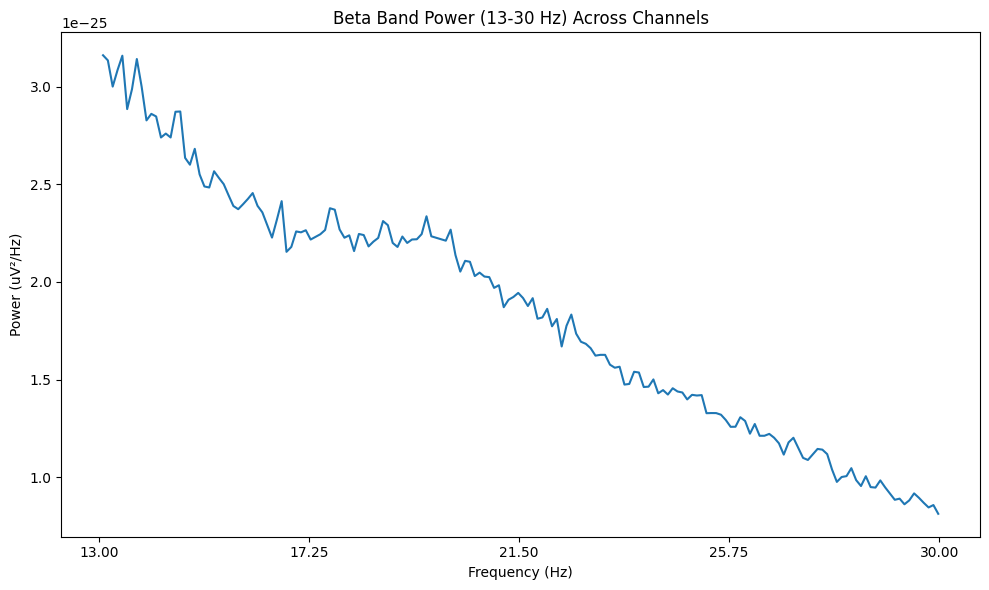

Extracted Beta Band Power (13-30 Hz) successfully.


In [395]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [396]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d123 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d123.head())
print(d123.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [397]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d123_clean = d123.replace([np.inf, -np.inf], np.nan)
d123_clean = d123_clean.fillna(d123_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d123_scaled = pd.DataFrame(
    scaler.fit_transform(d123_clean),
    columns=d123_clean.columns,
    index=d123_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d123_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d123_scaled.index,
    columns=d123_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d123_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df123 = d123_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df123["Pd_indicator_meg"] = 1

print("\nShape of df5:", df123.shape)
print(df123.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [398]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122, df123], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
6781    3.863343             0.064711          2.691479e-12  1.011506   
6782    4.033241             0.061985          2.453485e-12  0.909772   
6783    4.000000             0.062500          1.454658e-13  0.988

In [399]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123.to_csv('/content/drive/MyDrive/combined_features_upto_sub0123_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123 preserved.")


RAM Used After Cleanup: 1.09 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123 preserved.


sub-124

In [400]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-124'  # Replace with your folder path


In [401]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-124_scans.tsv', 'meg']


In [402]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-124_coordsystem.json', 'sub-124_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-124_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-124_task-go_run-1_proc-tsss+mc_events.json', 'sub-124_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-124_task-go_run-1_proc-tsss+mc_meg.json', 'sub-124_task-noise_proc-tsss_channels.tsv', 'sub-124_task-noise_proc-tsss_meg.json', 'sub-124_task-noise_proc-tsss_meg.fif', 'sub-124_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-124_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-124_task-passive_run-1_proc-tsss+mc_events.json', 'sub-124_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-124_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-124_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-124_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-124_task-rest_run-1_proc-tsss+mc_events.json', 'sub-124_task-rest_run-1_proc-tsss+mc_meg.json', 'sub-124_task-rest_run-1_proc-tsss+mc_meg.fif']


In [403]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-124_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-124_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-124_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-124_task-rest_run-1_proc-tsss+mc_meg.fif']


In [404]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-124/meg/sub-124_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [405]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-124/meg/sub-124_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 190000 ... 1265999 =    190.000 ...  1265.999 secs
Ready.
Reading 0 ... 1075999  =      0.000 ...  1075.999 secs...
Finding events on: STI101
300 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
300 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fittin

Computing Power Spectral Density

Effective window size : 10.240 (s)


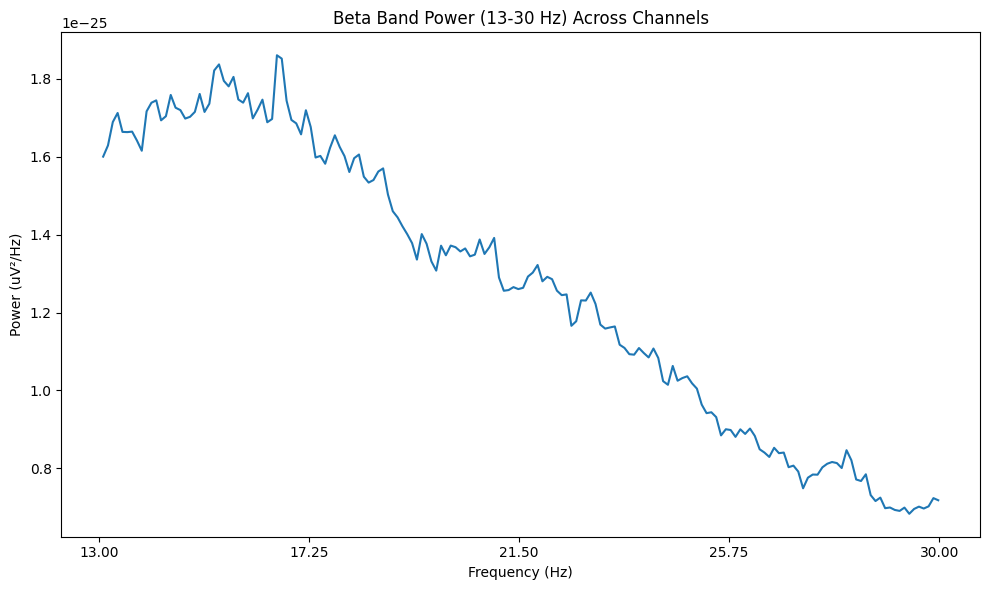

Extracted Beta Band Power (13-30 Hz) successfully.


In [406]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [407]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d124 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d124.head())
print(d124.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [408]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d124_clean = d124.replace([np.inf, -np.inf], np.nan)
d124_clean = d124_clean.fillna(d124_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d124_scaled = pd.DataFrame(
    scaler.fit_transform(d124_clean),
    columns=d124_clean.columns,
    index=d124_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d124_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d124_scaled.index,
    columns=d124_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d124_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df124 = d124_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df124["Pd_indicator_meg"] = 0

print("\nShape of df5:", df124.shape)
print(df124.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [409]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123, df124], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
6839    4.474907             0.055858          2.518158e-12  0.718619   
6840    4.406134             0.056724          2.389247e-12  0.716366   
6841    4.198885             0.059540          1.243731e-13  0.

In [410]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124.to_csv('/content/drive/MyDrive/combined_features_upto_sub0124_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124 preserved.")


RAM Used After Cleanup: 1.08 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124 preserved.


sub-125

In [411]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-125'  # Replace with your folder path


In [412]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-125_scans.tsv', 'meg']


In [413]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-125_task-go_run-1_proc-tsss+mc_events.json', 'sub-125_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-125_coordsystem.json', 'sub-125_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-125_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-125_task-noise_proc-tsss_meg.fif', 'sub-125_task-noise_proc-tsss_channels.tsv', 'sub-125_task-go_run-1_proc-tsss+mc_meg.json', 'sub-125_task-noise_proc-tsss_meg.json', 'sub-125_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-125_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-125_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-125_task-passive_run-1_proc-tsss+mc_events.json', 'sub-125_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-125_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-125_task-rest_run-1_proc-tsss+mc_events.json', 'sub-125_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-125_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-125_task-rest_run-1_proc-tsss+mc_meg.json']


In [414]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-125_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-125_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-125_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-125_task-rest_run-1_proc-tsss+mc_meg.fif']


In [415]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-125/meg/sub-125_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [416]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-125/meg/sub-125_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 206000 ... 1269999 =    206.000 ...  1269.999 secs
Ready.
Reading 0 ... 1063999  =      0.000 ...  1063.999 secs...
Finding events on: STI101
294 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
294 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fittin

Computing Power Spectral Density

Effective window size : 10.240 (s)


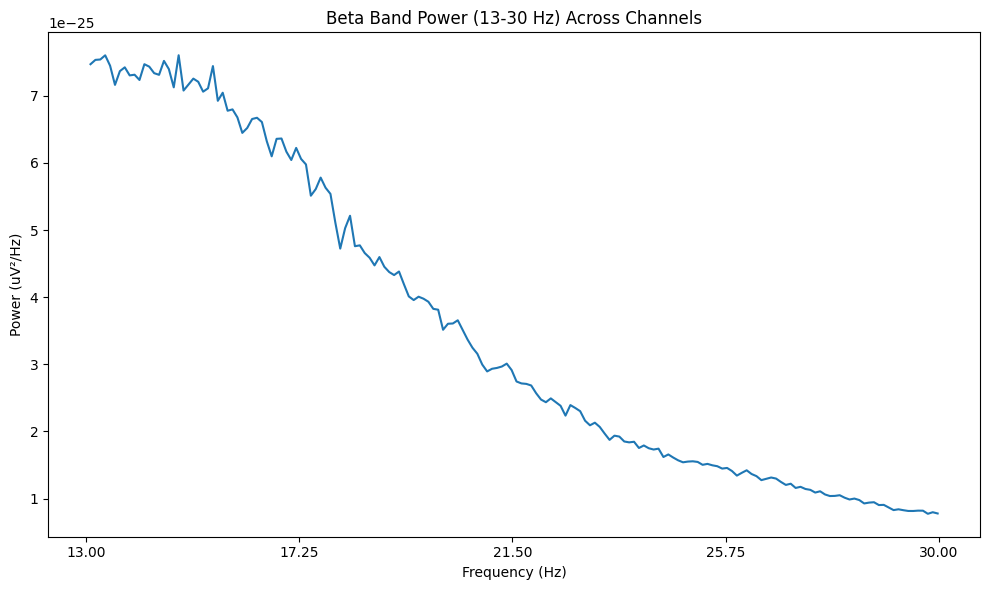

Extracted Beta Band Power (13-30 Hz) successfully.


In [417]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [418]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d125 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d125.head())
print(d125.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [419]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d125_clean = d125.replace([np.inf, -np.inf], np.nan)
d125_clean = d125_clean.fillna(d125_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d125_scaled = pd.DataFrame(
    scaler.fit_transform(d125_clean),
    columns=d125_clean.columns,
    index=d125_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d125_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d125_scaled.index,
    columns=d125_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d125_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df125 = d125_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df125["Pd_indicator_meg"] = 0

print("\nShape of df5:", df125.shape)
print(df125.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [420]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124, df125], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
6897    3.976504             0.062869          2.466496e-12  0.866738   
6898    3.902256             0.064066          2.530744e-12  0.838818   
6899    4.100564             0.060967          1.306123e-13 

In [421]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125.to_csv('/content/drive/MyDrive/combined_features_upto_sub0125_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125 preserved.")


RAM Used After Cleanup: 1.07 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125 preserved.


sub-127

In [422]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-127'  # Replace with your folder path


In [423]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-127_scans.tsv', 'meg']


In [424]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-127_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-127_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-127_coordsystem.json', 'sub-127_task-go_run-1_proc-tsss+mc_events.json', 'sub-127_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-127_task-noise_proc-tsss_channels.tsv', 'sub-127_task-go_run-1_proc-tsss+mc_meg.json', 'sub-127_task-noise_proc-tsss_meg.fif', 'sub-127_task-noise_proc-tsss_meg.json', 'sub-127_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-127_task-passive_run-1_proc-tsss+mc_events.json', 'sub-127_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-127_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-127_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-127_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-127_task-rest_run-1_proc-tsss+mc_events.json', 'sub-127_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-127_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-127_task-rest_run-1_proc-tsss+mc_meg.json']


In [425]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-127_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-127_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-127_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-127_task-rest_run-1_proc-tsss+mc_meg.fif']


In [426]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-127/meg/sub-127_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [427]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-127/meg/sub-127_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 32000 ... 1156999 =     32.000 ...  1156.999 secs
Ready.
Reading 0 ... 1124999  =      0.000 ...  1124.999 secs...
Finding events on: STI101
300 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
300 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 2 contiguous segments
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fittin

Computing Power Spectral Density

Setting 11000 of 225000 (4.89%) samples to NaN, retaining 214000 (95.11%) samples.
Effective window size : 10.240 (s)
At least one good data span is shorter than n_per_seg, and will be analyzed with a shorter window than the rest of the file.


/usr/local/lib/python3.12/dist-packages/mne/time_frequency/psd.py:291: UserWarning: nperseg = 2048 is greater than input length  = 1400, using nperseg = 1400
  return _func(*args, **kwargs)


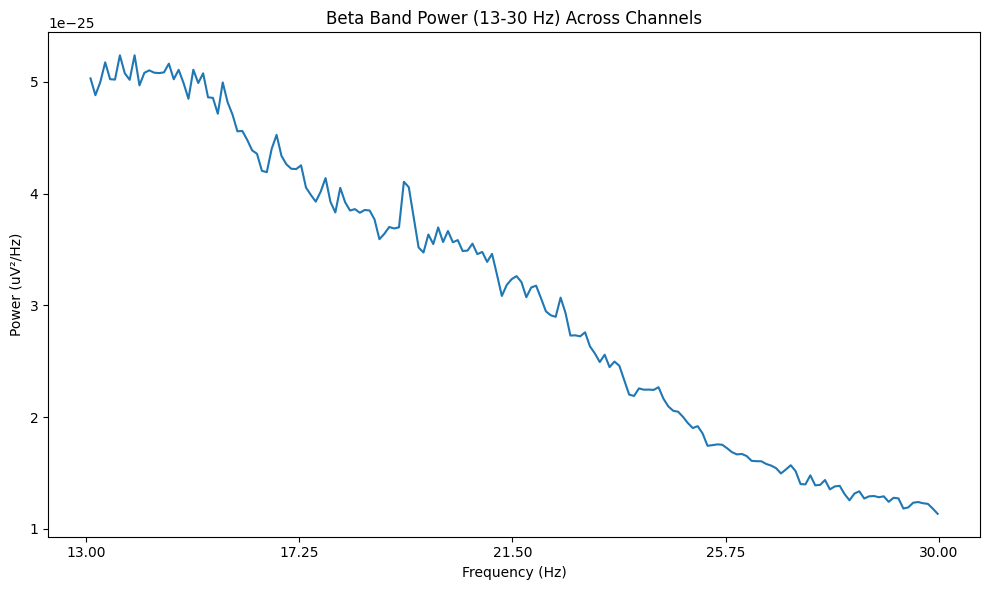

Extracted Beta Band Power (13-30 Hz) successfully.


In [428]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [429]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d127 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d127.head())
print(d127.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [430]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d127_clean = d127.replace([np.inf, -np.inf], np.nan)
d127_clean = d127_clean.fillna(d127_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d127_scaled = pd.DataFrame(
    scaler.fit_transform(d127_clean),
    columns=d127_clean.columns,
    index=d127_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d127_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d127_scaled.index,
    columns=d127_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d127_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df127 = d127_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df127["Pd_indicator_meg"] = 1

print("\nShape of df5:", df127.shape)
print(df127.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [431]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125, df127], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
6955    3.791111             0.065944          3.620015e-12  3.326796   
6956    3.896000             0.064168          3.188442e-12  3.324244   
6957    3.860444             0.064759          1.777423e-

In [432]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127.to_csv('/content/drive/MyDrive/combined_features_upto_sub0127_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127 preserved.")


RAM Used After Cleanup: 1.10 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127 preserved.


sub-128

In [433]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-128'  # Replace with your folder path


In [434]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-128_scans.tsv', 'meg']


In [435]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-128_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-128_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-128_task-go_run-1_proc-tsss+mc_events.json', 'sub-128_coordsystem.json', 'sub-128_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-128_task-noise_proc-tsss_meg.fif', 'sub-128_task-go_run-1_proc-tsss+mc_meg.json', 'sub-128_task-noise_proc-tsss_channels.tsv', 'sub-128_task-noise_proc-tsss_meg.json', 'sub-128_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-128_task-passive_run-1_proc-tsss+mc_events.json', 'sub-128_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-128_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-128_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-128_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-128_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-128_task-rest_run-1_proc-tsss+mc_events.json', 'sub-128_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-128_task-rest_run-1_proc-tsss+mc_meg.json']


In [436]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-128_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-128_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-128_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-128_task-rest_run-1_proc-tsss+mc_meg.fif']


In [437]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-128/meg/sub-128_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [438]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-128/meg/sub-128_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 95000 ... 1191999 =     95.000 ...  1191.999 secs
Ready.
Reading 0 ... 1096999  =      0.000 ...  1096.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


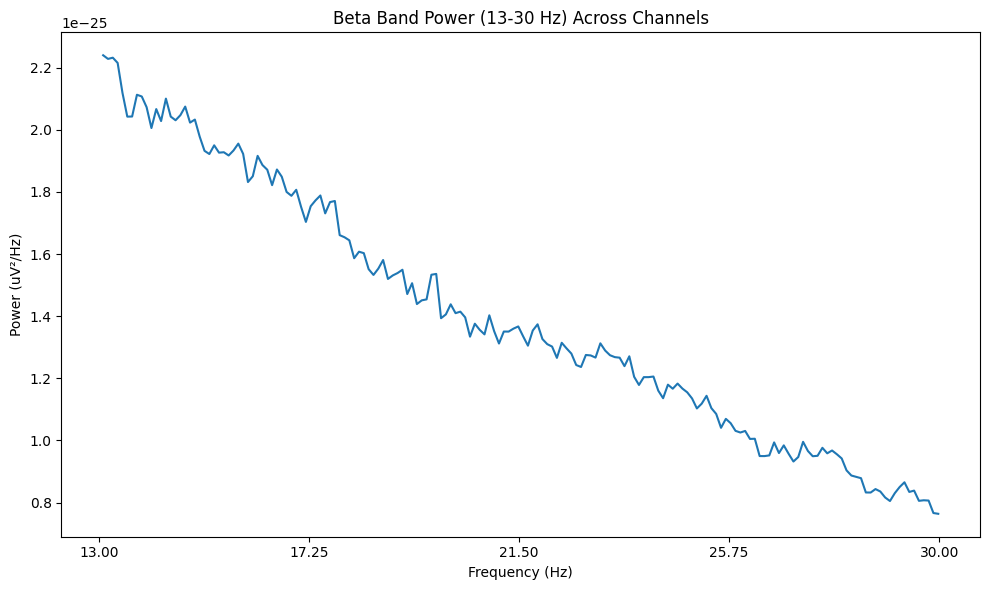

Extracted Beta Band Power (13-30 Hz) successfully.


In [439]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [440]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d128 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d128.head())
print(d128.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [441]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d128_clean = d128.replace([np.inf, -np.inf], np.nan)
d128_clean = d128_clean.fillna(d128_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d128_scaled = pd.DataFrame(
    scaler.fit_transform(d128_clean),
    columns=d128_clean.columns,
    index=d128_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d128_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d128_scaled.index,
    columns=d128_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d128_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df128 = d128_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df128["Pd_indicator_meg"] = 0

print("\nShape of df5:", df128.shape)
print(df128.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [442]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127, df128], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
7013    4.474932             0.055867          2.142235e-12  0.762690   
7014    4.310848             0.057993          2.109213e-12  0.769756   
7015    4.268915             0.058563          1.34876

In [443]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128.to_csv('/content/drive/MyDrive/combined_features_upto_sub0128_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128 preserved.")


RAM Used After Cleanup: 1.08 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128 preserved.


sub-129

In [444]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-129'  # Replace with your folder path


In [445]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-129_scans.tsv', 'meg']


In [446]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-129_coordsystem.json', 'sub-129_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-129_task-go_run-1_proc-tsss+mc_events.json', 'sub-129_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-129_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-129_task-go_run-1_proc-tsss+mc_meg.json', 'sub-129_task-noise_proc-tsss_meg.fif', 'sub-129_task-noise_proc-tsss_channels.tsv', 'sub-129_task-noise_proc-tsss_meg.json', 'sub-129_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-129_task-passive_run-1_proc-tsss+mc_events.json', 'sub-129_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-129_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-129_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-129_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-129_task-rest_run-1_proc-tsss+mc_events.json', 'sub-129_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-129_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-129_task-rest_run-1_proc-tsss+mc_meg.json']


In [447]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-129_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-129_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-129_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-129_task-rest_run-1_proc-tsss+mc_meg.fif']


In [448]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-129/meg/sub-129_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [449]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-129/meg/sub-129_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 68000 ... 1149999 =     68.000 ...  1149.999 secs
Ready.
Reading 0 ... 1081999  =      0.000 ...  1081.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computig Power Spectral Density

Effective window size : 10.240 (s)


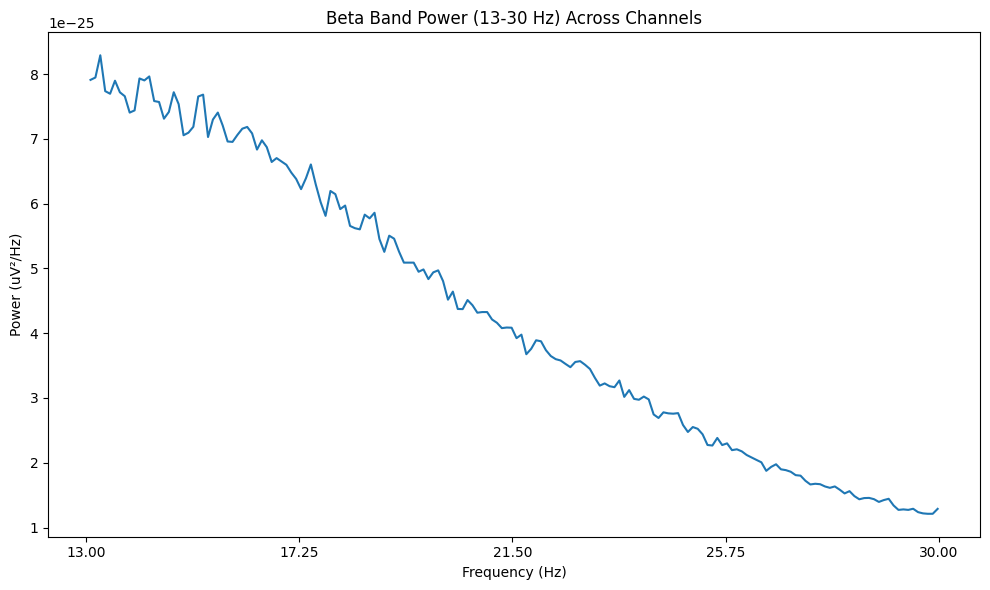

Extracted Beta Band Power (13-30 Hz) successfully.


In [450]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [451]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d129 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d129.head())
print(d129.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [452]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d129_clean = d129.replace([np.inf, -np.inf], np.nan)
d129_clean = d129_clean.fillna(d129_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d129_scaled = pd.DataFrame(
    scaler.fit_transform(d129_clean),
    columns=d129_clean.columns,
    index=d129_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d129_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d129_scaled.index,
    columns=d129_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d129_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df129 = d129_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df129["Pd_indicator_meg"] = 0

print("\nShape of df5:", df129.shape)
print(df129.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [453]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128, df129], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
7071    4.029575             0.062041          4.640914e-12  0.870285   
7072    4.000000             0.062500          4.514671e-12  0.849825   
7073    3.994455             0.062587          2.41

In [454]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129.to_csv('/content/drive/MyDrive/combined_features_upto_sub0129_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129 preserved.")


RAM Used After Cleanup: 1.08 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129 preserved.


sub-130

In [455]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-130'  # Replace with your folder path


In [456]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-130_scans.tsv', 'meg']


In [457]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-130_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-130_coordsystem.json', 'sub-130_task-go_run-1_proc-tsss+mc_events.json', 'sub-130_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-130_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-130_task-noise_proc-tsss_meg.fif', 'sub-130_task-go_run-1_proc-tsss+mc_meg.json', 'sub-130_task-noise_proc-tsss_channels.tsv', 'sub-130_task-noise_proc-tsss_meg.json', 'sub-130_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-130_task-passive_run-1_proc-tsss+mc_events.json', 'sub-130_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-130_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-130_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-130_task-rest_run-1_proc-tsss+mc_events.json', 'sub-130_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-130_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-130_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-130_task-rest_run-1_proc-tsss+mc_meg.json']


In [458]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-130_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-130_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-130_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-130_task-rest_run-1_proc-tsss+mc_meg.fif']


In [459]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-130/meg/sub-130_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [460]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-130/meg/sub-130_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 88000 ... 1163999 =     88.000 ...  1163.999 secs
Ready.
Reading 0 ... 1075999  =      0.000 ...  1075.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


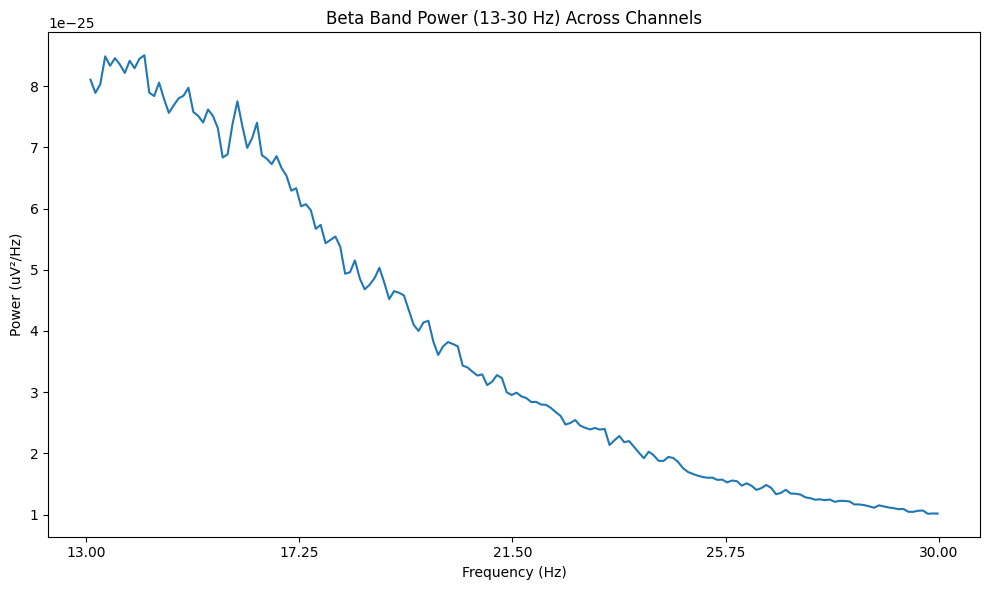

Extracted Beta Band Power (13-30 Hz) successfully.


In [461]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [462]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d130 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d130.head())
print(d130.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [463]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d130_clean = d130.replace([np.inf, -np.inf], np.nan)
d130_clean = d130_clean.fillna(d130_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d130_scaled = pd.DataFrame(
    scaler.fit_transform(d130_clean),
    columns=d130_clean.columns,
    index=d130_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d130_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d130_scaled.index,
    columns=d130_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d130_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df130 = d130_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df130["Pd_indicator_meg"] = 0

print("\nShape of df5:", df130.shape)
print(df130.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [464]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129, df130], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
7129    4.024164             0.062125          2.869865e-12  0.799470   
7130    3.871747             0.064570          3.203851e-12  0.836103   
7131    4.113383             0.060777          1

In [465]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130.to_csv('/content/drive/MyDrive/combined_features_upto_sub0130_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130 preserved.")


RAM Used After Cleanup: 1.10 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130 preserved.


sub-131

In [466]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-131'  # Replace with your folder path


In [467]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-131_scans.tsv', 'meg']


In [468]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-131_coordsystem.json', 'sub-131_task-go_run-1_proc-tsss+mc_events.json', 'sub-131_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-131_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-131_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-131_task-go_run-1_proc-tsss+mc_meg.json', 'sub-131_task-noise_proc-tsss_channels.tsv', 'sub-131_task-noise_proc-tsss_meg.fif', 'sub-131_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-131_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-131_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-131_task-noise_proc-tsss_meg.json', 'sub-131_task-passive_run-1_proc-tsss+mc_events.json', 'sub-131_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-131_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-131_task-rest_run-1_proc-tsss+mc_events.json', 'sub-131_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-131_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-131_task-rest_run-1_proc-tsss+mc_meg.json']


In [469]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-131_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-131_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-131_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-131_task-rest_run-1_proc-tsss+mc_meg.fif']


In [470]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-131/meg/sub-131_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [471]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-131/meg/sub-131_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 31000 ... 1106999 =     31.000 ...  1106.999 secs
Ready.
Reading 0 ... 1075999  =      0.000 ...  1075.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fitting

Computing Power Spectral Density

Effective window size : 10.240 (s)


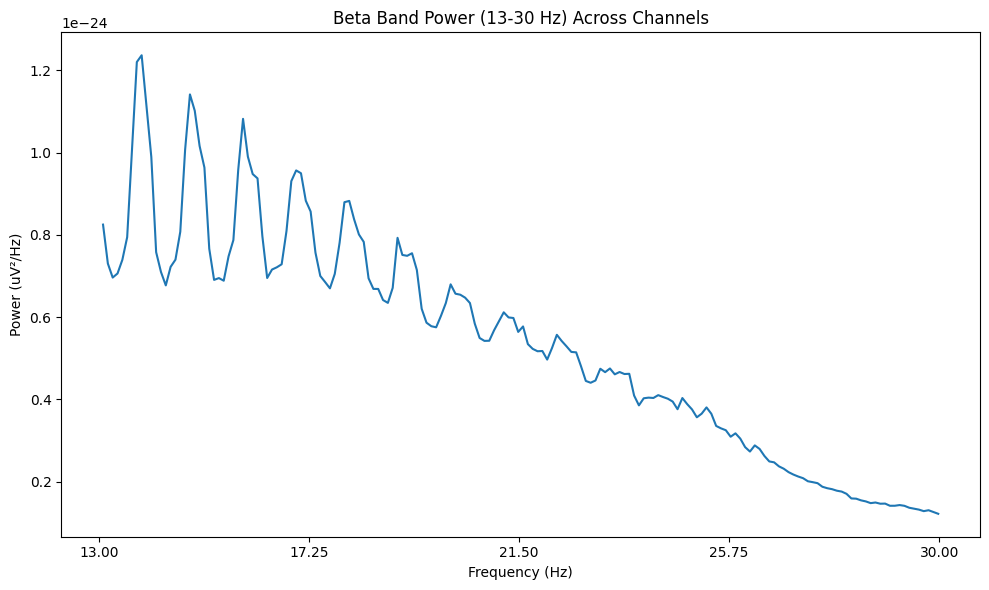

Extracted Beta Band Power (13-30 Hz) successfully.


In [472]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [473]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d131 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d131.head())
print(d131.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [474]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d131_clean = d131.replace([np.inf, -np.inf], np.nan)
d131_clean = d131_clean.fillna(d131_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d131_scaled = pd.DataFrame(
    scaler.fit_transform(d131_clean),
    columns=d131_clean.columns,
    index=d131_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d131_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d131_scaled.index,
    columns=d131_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d131_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df131 = d131_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df131["Pd_indicator_meg"] = 1

print("\nShape of df5:", df131.shape)
print(df131.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [475]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130, df131], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
7187    3.895911             0.064170          3.717985e-12  0.810103   
7188    3.715613             0.067284          3.584755e-12  0.855594   
7189    3.851301             0.064913        

In [476]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131.to_csv('/content/drive/MyDrive/combined_features_upto_sub0131_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131 preserved.")


RAM Used After Cleanup: 1.10 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131 preserved.


sub-132

In [477]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-132'  # Replace with your folder path


In [478]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-132_scans.tsv', 'meg']


In [479]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-132_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-132_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-132_task-go_run-1_proc-tsss+mc_events.json', 'sub-132_coordsystem.json', 'sub-132_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-132_task-noise_proc-tsss_meg.fif', 'sub-132_task-go_run-1_proc-tsss+mc_meg.json', 'sub-132_task-noise_proc-tsss_channels.tsv', 'sub-132_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-132_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-132_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-132_task-passive_run-1_proc-tsss+mc_events.json', 'sub-132_task-noise_proc-tsss_meg.json', 'sub-132_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-132_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-132_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-132_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-132_task-rest_run-1_proc-tsss+mc_events.json', 'sub-132_task-rest_run-1_proc-tsss+mc_meg.json']


In [480]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-132_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-132_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-132_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-132_task-rest_run-1_proc-tsss+mc_meg.fif']


In [481]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-132/meg/sub-132_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [482]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-132/meg/sub-132_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 69000 ... 1151999 =     69.000 ...  1151.999 secs
Ready.
Reading 0 ... 1082999  =      0.000 ...  1082.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


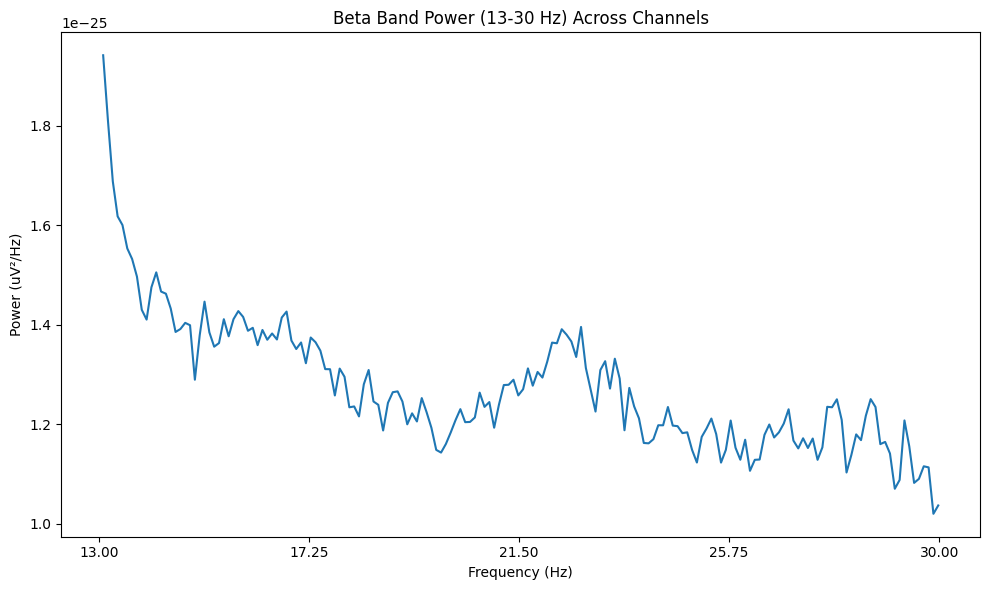

Extracted Beta Band Power (13-30 Hz) successfully.


In [483]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [484]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d132 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d132.head())
print(d132.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 58 channels

In [485]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d132_clean = d132.replace([np.inf, -np.inf], np.nan)
d132_clean = d132_clean.fillna(d132_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d132_scaled = pd.DataFrame(
    scaler.fit_transform(d132_clean),
    columns=d132_clean.columns,
    index=d132_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d132_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d132_scaled.index,
    columns=d132_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d132_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df132 = d132_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df132["Pd_indicator_meg"] = 0

print("\nShape of df5:", df132.shape)
print(df132.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [486]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131, df132], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
7245    4.736842             0.052778          1.749270e-12  0.753674   
7246    4.807018             0.052007          2.101598e-12  0.723045   
7247    4.698061             0.053213     

In [487]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132.to_csv('/content/drive/MyDrive/combined_features_upto_sub0132_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132 preserved.")


RAM Used After Cleanup: 1.10 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132 preserved.


sub-133

In [488]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-133'  # Replace with your folder path


In [489]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-133_scans.tsv', 'meg']


In [490]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-133_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-133_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-133_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-133_coordsystem.json', 'sub-133_task-go_run-1_proc-tsss+mc_events.json', 'sub-133_task-noise_proc-tsss_channels.tsv', 'sub-133_task-noise_proc-tsss_meg.fif', 'sub-133_task-go_run-1_proc-tsss+mc_meg.json', 'sub-133_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-133_task-noise_proc-tsss_meg.json', 'sub-133_task-passive_run-1_proc-tsss+mc_events.json', 'sub-133_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-133_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-133_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-133_task-rest_run-1_proc-tsss+mc_events.json', 'sub-133_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-133_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-133_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-133_task-rest_run-1_proc-tsss+mc_meg.json']


In [491]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-133_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-133_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-133_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-133_task-rest_run-1_proc-tsss+mc_meg.fif']


In [492]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-133/meg/sub-133_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [493]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-133/meg/sub-133_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 55000 ... 1143999 =     55.000 ...  1143.999 secs
Ready.
Reading 0 ... 1088999  =      0.000 ...  1088.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fit

Computing Power Spectral Density

Effective window size : 10.240 (s)


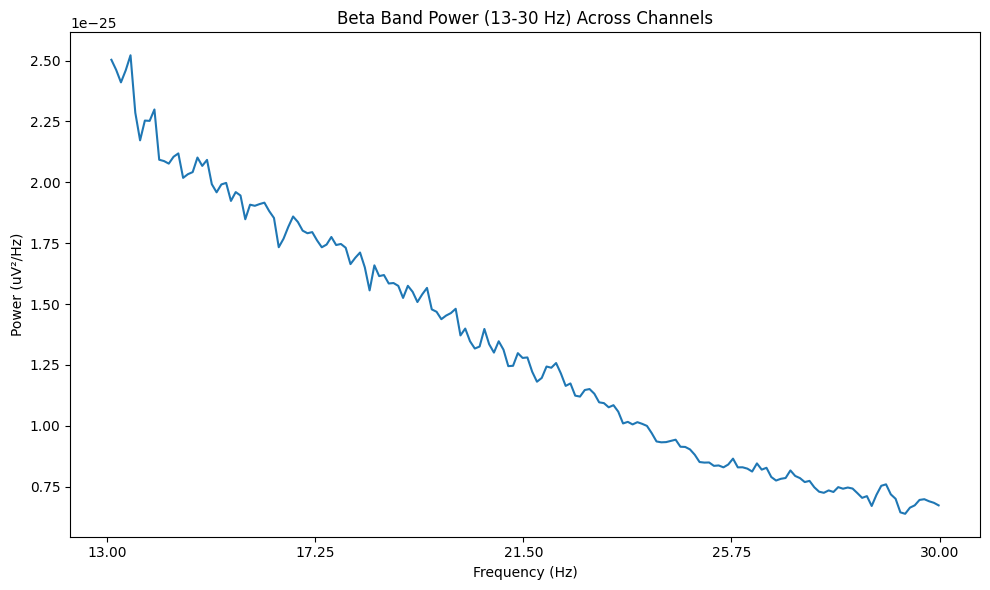

Extracted Beta Band Power (13-30 Hz) successfully.


In [494]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [495]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d133 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d133.head())
print(d133.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of Top 42 channels

In [496]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d133_clean = d133.replace([np.inf, -np.inf], np.nan)
d133_clean = d133_clean.fillna(d133_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d133_scaled = pd.DataFrame(
    scaler.fit_transform(d133_clean),
    columns=d133_clean.columns,
    index=d133_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d133_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d133_scaled.index,
    columns=d133_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 42 Channels
# -------------------------------------------------
top_42_channel_names = centrality_scores.sort_values(
    ascending=False
).head(42).index

top_42_channel_numbers = [
    d133_scaled.index.get_loc(ch)
    for ch in top_42_channel_names
]

print("Top 42 channel names:")
print(top_42_channel_names.tolist())

print("\nTop 42 channel numbers:")
print(top_42_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df133 = d133_clean.loc[top_42_channel_names].copy()

# subject label (example PD subject)
df133["Pd_indicator_meg"] = 0

print("\nShape of df5:", df133.shape)
print(df133.head())

Top 42 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431']

Top 42 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42]

Shape of df5: (42, 22)
         burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
MEG2643    4.267218             0.058569          3.272535e-12  0.806534   
MEG0111    4.531680             0.055167          1.290636e-13  0.800812   
MEG2532    4.525253             0.055239          1.9

In [497]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132, df133], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
7287    4.052342             0.061693          4.570680e-12  0.842732   
7288    3.760331             0.066453          2.176313e-13  0.855385   
7289    3.129477             0.079886  

In [498]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133.to_csv('/content/drive/MyDrive/combined_features_upto_sub0133_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133 preserved.")


RAM Used After Cleanup: 1.10 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133 preserved.


sub-134

In [499]:
# 2. Specify the path to the unzipped folder
# Update the folder path with the actual location in your Drive
unzip_folder_path = '/content/drive/MyDrive/sub-134'  # Replace with your folder path


In [500]:
# 3. List the contents of the folder to verify the files
import os
if os.path.exists(unzip_folder_path):
    folder_contents = os.listdir(unzip_folder_path)
    print("Folder contents:", folder_contents)
else:
    print(f"Folder does not exist: {unzip_folder_path}")

Folder contents: ['sub-134_scans.tsv', 'meg']


In [501]:
# 4. Check if the 'meg' folder exists inside the unzipped folder
meg_folder_path = os.path.join(unzip_folder_path, 'meg')
if os.path.exists(meg_folder_path):
    meg_folder_contents = os.listdir(meg_folder_path)
    print("Contents of 'meg' folder:", meg_folder_contents)
else:
    raise FileNotFoundError(f"'meg' folder does not exist in {unzip_folder_path}")

Contents of 'meg' folder: ['sub-134_task-go_run-1_proc-tsss+mc_channels.tsv', 'sub-134_coordsystem.json', 'sub-134_task-go_run-1_proc-tsss+mc_events.tsv', 'sub-134_task-go_run-1_proc-tsss+mc_meg.fif', 'sub-134_task-go_run-1_proc-tsss+mc_events.json', 'sub-134_task-noise_proc-tsss_channels.tsv', 'sub-134_task-go_run-1_proc-tsss+mc_meg.json', 'sub-134_task-noise_proc-tsss_meg.fif', 'sub-134_task-noise_proc-tsss_meg.json', 'sub-134_task-passive_run-1_proc-tsss+mc_channels.tsv', 'sub-134_task-passive_run-1_proc-tsss+mc_events.json', 'sub-134_task-passive_run-1_proc-tsss+mc_events.tsv', 'sub-134_task-passive_run-1_proc-tsss+mc_meg.fif', 'sub-134_task-passive_run-1_proc-tsss+mc_meg.json', 'sub-134_task-rest_run-1_proc-tsss+mc_meg.fif', 'sub-134_task-rest_run-1_proc-tsss+mc_events.tsv', 'sub-134_task-rest_run-1_proc-tsss+mc_events.json', 'sub-134_task-rest_run-1_proc-tsss+mc_channels.tsv', 'sub-134_task-rest_run-1_proc-tsss+mc_meg.json']


In [502]:
# 5. Extract and group .fif files by task
from collections import defaultdict

# Dictionary to store .fif files grouped by task
fif_files_by_task = defaultdict(list)

# Iterate over the files in the 'meg' folder
for file_name in meg_folder_contents:
    if file_name.endswith('.fif'):  # Check if the file is a .fif file
        # Extract the task name from the file name (assumes task names are after "task-")
        task_name = None
        if "task-" in file_name:
            task_name = file_name.split("task-")[1].split("_")[0]  # Extract task name
        else:
            task_name = "unknown"  # Use "unknown" for files without a task name

        # Add the file to the corresponding task group
        fif_files_by_task[task_name].append(file_name)

# 6. Print the grouped .fif files
print("Grouped .fif files by task:")
for task, files in fif_files_by_task.items():
    print(f"Task '{task}': {files}")

Grouped .fif files by task:
Task 'go': ['sub-134_task-go_run-1_proc-tsss+mc_meg.fif']
Task 'noise': ['sub-134_task-noise_proc-tsss_meg.fif']
Task 'passive': ['sub-134_task-passive_run-1_proc-tsss+mc_meg.fif']
Task 'rest': ['sub-134_task-rest_run-1_proc-tsss+mc_meg.fif']


In [503]:
# 7. Identify each .fif file for a specific task (example: "go")

!pip install mne
import mne

task_to_load = "passive"

if task_to_load in fif_files_by_task:
    for fif_file in fif_files_by_task[task_to_load]:
        fif_file_path = os.path.join(meg_folder_path, fif_file)
        print(f"\nFound .fif file: {fif_file_path}")
else:
    print(f"No .fif files found for task '{task_to_load}'.")



Found .fif file: /content/drive/MyDrive/sub-134/meg/sub-134_task-passive_run-1_proc-tsss+mc_meg.fif


Preprocessing

In [504]:
import numpy as np
import mne
from mne.preprocessing import ICA
from mne.time_frequency import tfr_multitaper
import matplotlib.pyplot as plt

# Load the raw MEG data (Replace 'fif_file_path' with the actual path to your .fif file)
raw = mne.io.read_raw_fif(fif_file_path, preload=True)

# 1. Preprocessing: Downsample, ICA, Filter
# Downsample to 200 Hz
raw.resample(200, npad="auto")
print("Resampling done")

# Apply bandpass filter (1-40 Hz)
raw.filter(1, 40, fir_design='firwin', n_jobs=1)
print("Filtering done")

# Apply ICA (Independent Component Analysis) to remove artifacts
ica = ICA(n_components=10, random_state=42)
print("Fitting ICA")
ica.fit(raw)
print("ICA fit done")
ica.apply(raw)  # Apply ICA solution to the data
print("ICA applied")

Opening raw data file /content/drive/MyDrive/sub-134/meg/sub-134_task-passive_run-1_proc-tsss+mc_meg.fif...
    Range : 121000 ... 1201999 =    121.000 ...  1201.999 secs
Ready.
Reading 0 ... 1080999  =      0.000 ...  1080.999 secs...
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Finding events on: STI101
301 events found on stim channel STI101
Event IDs: [1 2 8]
Resampling done
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Filtering done
Fi

Computing Power Spectral Density

Effective window size : 10.240 (s)


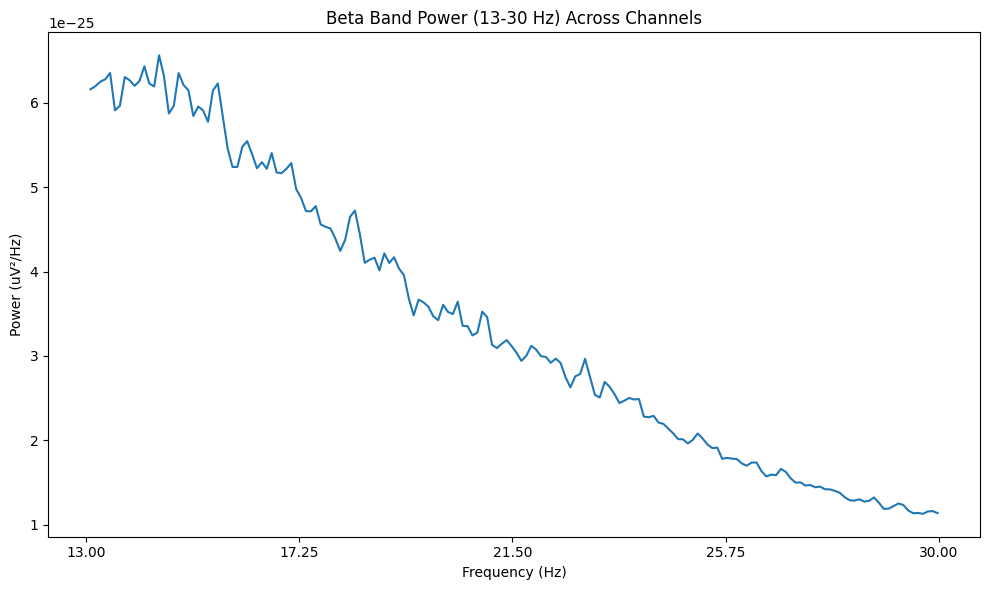

Extracted Beta Band Power (13-30 Hz) successfully.


In [505]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Compute Power Spectral Density (PSD) using Welch method
psd_obj = raw.compute_psd(fmin=6, fmax=40, method='welch', n_fft=2048)

# 2. Extract PSD values and frequency values
psds = psd_obj.get_data()
freqs_psd = psd_obj.freqs

# 3. Extract the Beta band (13-30 Hz)
beta_mask = (freqs_psd >= 13) & (freqs_psd <= 30)
beta_band_psd = psds[:, beta_mask]

# 4. Visualize the Beta band power (mean across all channels)
plt.figure(figsize=(10, 6))

plt.plot(
    freqs_psd[beta_mask],
    beta_band_psd.mean(axis=0)
)

plt.title("Beta Band Power (13-30 Hz) Across Channels")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (uV²/Hz)")

# Customize x-axis to have exactly 5 ticks
num_ticks = 5
tick_positions = np.linspace(13, 30, num_ticks)
plt.xticks(tick_positions)

plt.tight_layout()
plt.show()

# 🔥 VERY IMPORTANT: Prevent memory accumulation
plt.close('all')

print("Extracted Beta Band Power (13-30 Hz) successfully.")


Feature Extraction

In [506]:
!pip install --upgrade mne-connectivity
!pip install fooof


import numpy as np
import mne
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, filtfilt
from mne.time_frequency import psd_array_welch
from scipy import stats
import pandas as pd
from scipy.stats import skew, kurtosis

# ----------------------------
# Helper: bandpass filter for bursts
def bandpass_filter(data, sfreq, l_freq, h_freq):
    nyq = 0.5 * sfreq
    low = l_freq / nyq
    high = h_freq / nyq
    b, a = butter(4, [low, high], btype='band')
    return filtfilt(b, a, data)

# ----------------------------
# Assuming raw is already an MNE Raw object
sfreq = raw.info['sfreq']

# Pick only MEG channels (306 total)
picks = mne.pick_types(raw.info, meg=True, eeg=False, eog=False, ecg=False, stim=False, exclude='bads')
data_all = raw.get_data(picks=picks)   # shape: (306, n_times)
ch_names = [raw.info['ch_names'][i] for i in picks]

# ----------------------------
# Collect features for each channel
all_features = []

for ch_idx, ch_name in enumerate(ch_names):
    data = raw.get_data(picks=[picks[ch_idx]])[0]   # ✅ SAFE

    # Step 1: Bandpass in beta and get envelope
    beta_ts = bandpass_filter(data, sfreq, 13, 30)
    envelope = np.abs(hilbert(beta_ts))

    # Step 2: Burst detection (threshold at 75th percentile)
    thresh = np.percentile(envelope, 75)
    above = envelope > thresh
    starts = np.where(np.diff(above.astype(int)) == 1)[0]
    stops = np.where(np.diff(above.astype(int)) == -1)[0]

    # --- FIX: Ensure starts and stops are aligned ---
    if len(stops) > 0 and len(starts) > 0:
        if stops[0] < starts[0]:
            stops = stops[1:]
        if len(starts) > len(stops):
            starts = starts[:len(stops)]
        if len(stops) > len(starts):
            stops = stops[:len(starts)]
    else:
        starts, stops = [], []

    recording_time = len(envelope) / sfreq

    # ----------------------------
    # Burst features
    durations = (stops - starts) / sfreq if len(starts) > 0 else []
    amps = [envelope[s:e].max() for s, e in zip(starts, stops) if e > s]
    ibis = np.diff(starts) / sfreq if len(starts) > 1 else []

    # 1. Burst Rate
    burst_rate = len(starts) / recording_time if recording_time > 0 else 0

    # 2. Mean Burst Duration
    mean_burst_duration = np.mean(durations) if len(durations) > 0 else 0

    # 3. Mean Burst Amplitude
    mean_burst_amplitude = np.mean(amps) if len(amps) > 0 else 0

    # 4. IBI Coefficient of Variation
    ibi_cv = np.std(ibis) / np.mean(ibis) if len(ibis) > 1 and np.mean(ibis) > 0 else 0

    # 5. Duty Cycle
    duty_cycle = np.sum(durations) / recording_time if recording_time > 0 else 0

    # 6. Peak Beta Frequency (after 1/f correction)
    psds, freqs = psd_array_welch(data[np.newaxis, :], sfreq=sfreq, fmin=1, fmax=45, n_fft=2048)
    psd = psds[0]

    valid = (psd > 0) & (freqs > 0)
    if np.any(valid):
        logf = np.log10(freqs[valid])
        logp = np.log10(psd[valid])
        slope, intercept, _, _, _ = stats.linregress(logf, logp)
        fit = 10 ** (intercept + slope * logf)
        corrected = psd[valid] - fit

        mask = (freqs[valid] >= 13) & (freqs[valid] <= 30)
        if np.any(mask):
            beta_freqs = freqs[valid][mask]
            corrected_beta = corrected[mask]
            peak_beta_freq = beta_freqs[np.argmax(corrected_beta)]
        else:
            peak_beta_freq = 0
    else:
        peak_beta_freq = 0

    # ----------------------------
    # Extra burst features
    burst_dur_cv = np.std(durations) / np.mean(durations) if len(durations) > 1 and np.mean(durations) > 0 else 0
    burst_amp_cv = np.std(amps) / np.mean(amps) if len(amps) > 1 and np.mean(amps) > 0 else 0
    mean_ibi = np.mean(ibis) if len(ibis) > 0 else 0

    # ----------------------------
    # Envelope statistics
    env_mean = np.mean(envelope)
    env_var = np.var(envelope)
    env_skew = skew(envelope)
    env_kurt = kurtosis(envelope)
    # Envelope modulation rate (dominant freq of envelope)
    env_psd, env_freqs = psd_array_welch(envelope[np.newaxis, :], sfreq=sfreq, fmin=0.1, fmax=10, n_fft=1024)
    env_mod_rate = env_freqs[np.argmax(env_psd[0])] if np.any(env_psd) else 0

    # ----------------------------
    # Spectral features (13–30 Hz)
    beta_mask = (freqs >= 13) & (freqs <= 30)
    beta_psd = psd[beta_mask]
    beta_freqs = freqs[beta_mask]

    abs_beta_power = np.mean(beta_psd) if beta_psd.size > 0 else 0
    peak_beta_power = np.max(beta_psd) if beta_psd.size > 0 else 0
    beta_median_freq = beta_freqs[np.searchsorted(np.cumsum(beta_psd) / np.sum(beta_psd), 0.5)] if beta_psd.size > 0 else 0
    beta_bandwidth = (beta_freqs[-1] - beta_freqs[0]) if beta_psd.size > 0 else 0

    # Spectral entropy
    psd_norm = beta_psd / np.sum(beta_psd) if np.sum(beta_psd) > 0 else np.zeros_like(beta_psd)
    spectral_entropy = -np.sum(psd_norm * np.log2(psd_norm + 1e-12)) if beta_psd.size > 0 else 0

    # Spectral flatness
    spectral_flatness = stats.mstats.gmean(beta_psd) / np.mean(beta_psd) if beta_psd.size > 0 else 0

    # Spectral slope
    if beta_psd.size > 0:
        logf = np.log10(beta_freqs)
        logp = np.log10(beta_psd + 1e-12)
        slope, _, _, _, _ = stats.linregress(logf, logp)
        spectral_slope = slope
    else:
        spectral_slope = 0

    # ----------------------------
    # Store all 20 features
    all_features.append([
        # Original 6
        burst_rate,
        mean_burst_duration,
        mean_burst_amplitude,
        ibi_cv,
        duty_cycle,
        peak_beta_freq,

        # Extra burst (3)
        burst_dur_cv,
        burst_amp_cv,
        mean_ibi,

        # Envelope (5)
        env_mean,
        env_var,
        env_skew,
        env_kurt,
        env_mod_rate,

        # Spectral (6)
        abs_beta_power,
        peak_beta_power,
        beta_median_freq,
        beta_bandwidth,
        spectral_entropy,
        spectral_flatness,
        spectral_slope
    ])

# ----------------------------
# Convert to DataFrame
feature_names = [
    "burst_rate",
    "mean_burst_duration",
    "mean_burst_amplitude",
    "ibi_cv",
    "duty_cycle",
    "peak_beta_freq",
    "burst_dur_cv",
    "burst_amp_cv",
    "mean_ibi",
    "env_mean",
    "env_var",
    "env_skew",
    "env_kurt",
    "env_mod_rate",
    "abs_beta_power",
    "peak_beta_power",
    "beta_median_freq",
    "beta_bandwidth",
    "spectral_entropy",
    "spectral_flatness",
    "spectral_slope"
]

d134 = pd.DataFrame(all_features, columns=feature_names, index=ch_names)
print(d134.head())
print(d134.shape)


Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)
Effective window size : 5.120 (s)
Effective window size : 10.240 (s)

Extraction of top 58 channels

In [507]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import networkx as nx

# -------------------------------------------------
# STEP 1: Clean NaN / Inf
# -------------------------------------------------
d134_clean = d134.replace([np.inf, -np.inf], np.nan)
d134_clean = d134_clean.fillna(d134_clean.mean())

# -------------------------------------------------
# STEP 2: Standardize features
# -------------------------------------------------
scaler = StandardScaler()

d134_scaled = pd.DataFrame(
    scaler.fit_transform(d134_clean),
    columns=d134_clean.columns,
    index=d134_clean.index
)

# -------------------------------------------------
# STEP 3: Compute Channel Similarity Matrix
# -------------------------------------------------
# Correlation between channels
similarity_matrix = np.corrcoef(d134_scaled)

similarity_df = pd.DataFrame(
    similarity_matrix,
    index=d134_scaled.index,
    columns=d134_scaled.index
)

# -------------------------------------------------
# STEP 4: Create Graph Network
# -------------------------------------------------
G = nx.from_pandas_adjacency(similarity_df)

# -------------------------------------------------
# STEP 5: Compute Graph Centrality Score
# -------------------------------------------------
centrality_scores = nx.degree_centrality(G)

centrality_scores = pd.Series(centrality_scores)

# -------------------------------------------------
# STEP 6: Select Top 58 Channels
# -------------------------------------------------
top_58_channel_names = centrality_scores.sort_values(
    ascending=False
).head(58).index

top_58_channel_numbers = [
    d134_scaled.index.get_loc(ch)
    for ch in top_58_channel_names
]

print("Top 58 channel names:")
print(top_58_channel_names.tolist())

print("\nTop 58 channel numbers:")
print(top_58_channel_numbers)

# -------------------------------------------------
# STEP 7: Extract Top Channel Features
# -------------------------------------------------
df134 = d134_clean.loc[top_58_channel_names].copy()

# subject label (example PD subject)
df134["Pd_indicator_meg"] = 1

print("\nShape of df5:", df134.shape)
print(df134.head())

Top 58 channel names:
['MEG2643', 'MEG0111', 'MEG2532', 'MEG2531', 'MEG2523', 'MEG2522', 'MEG2521', 'MEG2513', 'MEG2512', 'MEG2511', 'MEG2443', 'MEG2442', 'MEG2441', 'MEG2433', 'MEG2432', 'MEG2431', 'MEG2423', 'MEG2422', 'MEG0341', 'MEG0333', 'MEG0332', 'MEG0331', 'MEG0323', 'MEG0322', 'MEG0321', 'MEG0313', 'MEG0312', 'MEG0311', 'MEG0243', 'MEG0242', 'MEG0241', 'MEG0233', 'MEG0232', 'MEG0231', 'MEG0512', 'MEG0511', 'MEG0443', 'MEG0442', 'MEG0441', 'MEG0433', 'MEG0432', 'MEG0431', 'MEG0423', 'MEG0422', 'MEG0421', 'MEG0413', 'MEG0412', 'MEG0411', 'MEG0343', 'MEG0342', 'MEG0623', 'MEG0622', 'MEG0621', 'MEG0613', 'MEG0612', 'MEG0611', 'MEG0543', 'MEG0542']

Top 58 channel numbers:
[305, 0, 289, 288, 287, 286, 285, 284, 283, 282, 281, 280, 279, 278, 277, 276, 275, 274, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 49, 48, 47, 46, 45, 44, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 65, 64, 63, 62, 61, 60, 59, 58]

Shape of df5: (58, 22)
         burst_rate  mean_burst_duration 

In [508]:
# Combine df_4 and df_8 vertically
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134 = pd.concat([df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133, df134], axis=0)  # axis=0 means stacking rows

# Reset index if you want sequential row numbers (optional)
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134.reset_index(drop=True)

# Print the combined DataFrame
print("Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134):")
print(df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134)

# Print the shape
print("Shape of df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134:", df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134.shape) #(116,7)


Combined top channels (df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134):
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
0       4.148423             0.060237          3.794677e-12  0.843069   
1       4.089981             0.061125          2.134013e-13  0.767457   
2       4.163265             0.060049          3.607224e-12  0.786598   
3       4.183673             0.059707          4.139047e-12  0.750612   
4       4.333024             0.057641          2.012607e-13  0.775638   
...          ...                  ...                   ...       ...   
7345    4.142461             0.060351          3.204137e-12  0.799105   
7346    4.061980             0.061546          2.988828e-12  0.808609   
7347    4.364477             0.05728

In [509]:
df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134.to_csv('/content/drive/MyDrive/final_meg_passive_21.csv', index=False)

import gc
import matplotlib.pyplot as plt
import psutil, os

plt.close('all')

# Delete heavy objects
del raw
del ica
del psd_obj
del psds
del beta_band_psd

gc.collect()

process = psutil.Process(os.getpid())
print(f"RAM Used After Cleanup: {process.memory_info().rss / 1024 ** 3:.2f} GB")
print("Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134 preserved.")


RAM Used After Cleanup: 1.10 GB
Memory cleaned. df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134 preserved.


In [510]:
combined_df85 = df123456781011121314151617181921222324252627282930313233353637383940414243444546474849505152535455565758596061636465666768697071727374757677787980818283848586878889909193949596979899100101102103104105106107108109110111112113114115116118119120121122123124125127128129130131132133134

In [511]:
print(combined_df85.shape)
print(combined_df85.dtypes)
print(combined_df85.iloc[7344:7350])  # Selects rows 2 to 612 (inclusive)
print(combined_df85.shape)

(7350, 22)
burst_rate              float64
mean_burst_duration     float64
mean_burst_amplitude    float64
ibi_cv                  float64
duty_cycle              float64
peak_beta_freq          float64
burst_dur_cv            float64
burst_amp_cv            float64
mean_ibi                float64
env_mean                float64
env_var                 float64
env_skew                float64
env_kurt                float64
env_mod_rate            float64
abs_beta_power          float64
peak_beta_power         float64
beta_median_freq        float64
beta_bandwidth          float64
spectral_entropy        float64
spectral_flatness       float64
spectral_slope          float64
Pd_indicator_meg          int64
dtype: object
      burst_rate  mean_burst_duration  mean_burst_amplitude    ibi_cv  \
7344    4.133210             0.060486          2.131948e-13  0.779413   
7345    4.142461             0.060351          3.204137e-12  0.799105   
7346    4.061980             0.061546          2.988

In [512]:
print(combined_df85['Pd_indicator_meg'].value_counts())

Pd_indicator_meg
0    3754
1    3596
Name: count, dtype: int64
